## Etapa 01 — Definição do problema preditivo

Treinar um modelo de regressão para estimar o preço anunciado (`price`) de cada anúncio a partir de seus atributos.

- **Base:** `data/raw/listings_details.csv`, snapshot de 06–07/12/2018 (`scrape_id=20181206172549`). A pasta de 16/09/2026 foi removida.
- **Métrica principal:** MAPE em preços válidos e positivos. MAE, RMSE, viés e desempenho por segmento serão métricas de apoio.
- **Preditores candidatos:** tipo e capacidade do imóvel, localização, anfitrião e reputação. A lista final e as regras contra vazamento serão definidas nas etapas seguintes.
- **Limite:** o modelo descreve preços anunciados no snapshot de 2018. Não prevê preços atuais ou de 2027, nem identifica preço ótimo.
- **Pendência:** confirmar a URL de origem e a licença do arquivo histórico.

In [1]:
# Importa conversão de datas para registrar a última modificação dos arquivos.
from datetime import datetime
# Importa Path para montar e validar caminhos do projeto.
from pathlib import Path
# Importa o leitor de CSV para consultar os cabeçalhos das bases.
import csv

# Usa o diretório atual como raiz inicial do projeto.
project_root = Path.cwd()
# Sobe um nível se o diretório atual não for a raiz do projeto.
if not (project_root / "data" / "raw").is_dir():
    # Define a pasta pai como raiz do projeto.
    project_root = project_root.parent

# Monta o caminho da pasta de dados brutos.
raw_dir = project_root / "data" / "raw"
# Inicializa a lista de arquivos e metadados encontrados.
file_inventory = []
# Percorre os itens da pasta em ordem alfabética.
for file_path in sorted(raw_dir.iterdir()):
    # Mantém apenas arquivos e ignora o marcador .gitkeep.
    if file_path.is_file() and file_path.name != ".gitkeep":
        # Converte a data de modificação do arquivo para texto legível.
        modified_at = datetime.fromtimestamp(file_path.stat().st_mtime).isoformat(timespec="seconds")
        # Guarda o nome, o tamanho em bytes e a data de modificação.
        file_inventory.append((file_path.name, file_path.stat().st_size, modified_at))

# Exibe a raiz de projeto identificada.
print("Diretório do projeto:", project_root)
# Informa que a próxima listagem contém os arquivos brutos.
print("Arquivos encontrados em data/raw:")
# Exibe cada arquivo com tamanho e data de modificação.
for file_name, file_size, modified_at in file_inventory:
    # Formata os metadados de um arquivo por linha.
    print(f"{file_name} | {file_size} bytes | modificado em {modified_at}")

# Registra variantes de nomes de arquivos CSV que serão verificadas.
schema_candidates = [
    "listings_details.csv",
    "calendar.csv",
    "reviews.csv",
    "reviews_details.csv",
    "neighbourhoods.csv",
    "neighbouhood.csv"
]
# Confere cada arquivo candidato antes de ler seu esquema.
for file_name in schema_candidates:
    # Monta o caminho completo do arquivo candidato.
    file_path = raw_dir / file_name
    # Continua apenas se o arquivo existir e tiver extensão CSV.
    if file_path.exists() and file_path.suffix.lower() == ".csv":
        # Abre o CSV preservando a leitura correta do cabeçalho.
        with file_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
            # Lê a primeira linha como nomes de colunas.
            column_names = next(csv.reader(csv_file), [])
        # Mostra o nome do arquivo e a quantidade de colunas.
        print(f"\n{file_name}: {len(column_names)} colunas")
        # Exibe os nomes das colunas encontrados.
        print(column_names)

Diretório do projeto: D:\repos\projetos\airbnb_price
Arquivos encontrados em data/raw:
calendar.csv | 173834328 bytes | modificado em 2019-10-15T03:09:38
listings.csv | 3219978 bytes | modificado em 2019-10-15T03:09:52
listings_details.csv | 78150593 bytes | modificado em 2019-10-15T03:09:52
neighbourhoods.csv | 420 bytes | modificado em 2019-10-15T03:10:02
neighbourhoods.geojson | 253697 bytes | modificado em 2019-10-15T03:10:02
reviews.csv | 8320428 bytes | modificado em 2019-10-15T03:10:02
reviews_details.csv | 151547718 bytes | modificado em 2019-10-15T03:10:02

listings_details.csv: 96 colunas
['id', 'listing_url', 'scrape_id', 'last_scraped', 'name', 'summary', 'space', 'description', 'experiences_offered', 'neighborhood_overview', 'notes', 'transit', 'access', 'interaction', 'house_rules', 'thumbnail_url', 'medium_url', 'picture_url', 'xl_picture_url', 'host_id', 'host_url', 'host_name', 'host_since', 'host_location', 'host_about', 'host_response_time', 'host_response_rate', 'ho

#### Interpretação da auditoria inicial

`listings_details.csv` é a base principal: 20.030 anúncios, 96 colunas e IDs únicos. `listings.csv` é resumido e não será usado. O snapshot tem `scrape_id=20181206172549` e datas entre 06 e 07/12/2018.

Os campos de preço e os candidatos a preditores foram confirmados no arquivo. Atributos de reputação, disponibilidade e datas ainda precisam passar por verificação de vazamento. `availability_365` indica noites disponíveis, não noites vendidas.

As análises refletem o padrão histórico de 2018. A URL e a licença do arquivo ainda precisam ser confirmadas.

In [2]:
# Importa contador para resumir as frequências dos campos.
from collections import Counter
# Importa date para validar e comparar datas de coleta.
from datetime import date
# Importa o leitor de CSV para percorrer os anúncios.
import csv

# Define o caminho do arquivo principal de anúncios.
listings_path = raw_dir / "listings_details.csv"
# Guarda IDs já vistos para contar identificadores únicos e repetidos.
listing_ids = set()
# Prepara a contagem das versões de coleta.
scrape_id_counts = Counter()
# Prepara a contagem por tipo de quarto.
room_type_counts = Counter()
# Prepara a contagem por tipo de propriedade.
property_type_counts = Counter()
# Armazena datas válidas de coleta para obter o intervalo observado.
last_scraped_dates = []
# Inicializa o total de linhas lidas.
listing_rows = 0
# Inicializa o total de IDs repetidos.
duplicate_listing_ids = 0

# Abre o arquivo principal para leitura linha a linha.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Usa os nomes do cabeçalho como chaves de cada registro.
    reader = csv.DictReader(csv_file)
    # Percorre cada anúncio do arquivo.
    for row in reader:
        # Atualiza o total de anúncios lidos.
        listing_rows += 1
        # Lê o ID e remove espaços em branco das extremidades.
        listing_id = (row.get("id") or "").strip()
        # Conta o ID quando ele já apareceu em uma linha anterior.
        if listing_id in listing_ids:
            # Soma uma ocorrência duplicada.
            duplicate_listing_ids += 1
        # Adiciona apenas IDs não vazios ao conjunto de identificadores.
        if listing_id:
            # Registra o ID para detectar repetições futuras.
            listing_ids.add(listing_id)
        # Conta o scrape_id, identificando campos vazios explicitamente.
        scrape_id_counts[(row.get("scrape_id") or "").strip() or "(vazio)"] += 1
        # Conta o tipo de quarto, incluindo valores vazios.
        room_type_counts[(row.get("room_type") or "").strip() or "(vazio)"] += 1
        # Conta o tipo de propriedade, incluindo valores vazios.
        property_type_counts[(row.get("property_type") or "").strip() or "(vazio)"] += 1
        # Lê a data de coleta e remove espaços extras.
        scraped_value = (row.get("last_scraped") or "").strip()
        # Tenta converter somente datas não vazias.
        if scraped_value:
            # Interpreta os primeiros dez caracteres como data ISO.
            try:
                # Guarda a data validada para calcular mínimo e máximo.
                last_scraped_dates.append(date.fromisoformat(scraped_value[:10]))
            # Ignora valores que não podem ser interpretados como data.
            except ValueError:
                # Continua a leitura sem interromper a auditoria.
                pass

# Informa o arquivo usado como base da verificação.
print("Arquivo principal:", listings_path)
# Compara o total de linhas com IDs únicos e repetidos.
print("Anúncios:", listing_rows, "| IDs únicos:", len(listing_ids), "| IDs repetidos:", duplicate_listing_ids)
# Exibe as frequências de cada identificador de coleta.
print("scrape_id:", scrape_id_counts.most_common())
# Mostra o intervalo das datas de coleta válidas, se houver datas.
print("last_scraped mínimo/máximo:", min(last_scraped_dates) if last_scraped_dates else None, "/", max(last_scraped_dates) if last_scraped_dates else None)
# Exibe as frequências por tipo de quarto.
print("room_type:", room_type_counts.most_common())
# Exibe os dez tipos de propriedade mais frequentes.
print("property_type (10 mais frequentes):", property_type_counts.most_common(10))

Arquivo principal: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv
Anúncios: 20030 | IDs únicos: 20030 | IDs repetidos: 0
scrape_id: [('20181206172549', 20030)]
last_scraped mínimo/máximo: 2018-12-06 / 2018-12-07
room_type: [('Entire home/apt', 15889), ('Private room', 4076), ('Shared room', 65)]
property_type (10 mais frequentes): [('Apartment', 15582), ('House', 1523), ('Townhouse', 649), ('Bed and breakfast', 455), ('Loft', 384), ('Boat', 372), ('Condominium', 323), ('Houseboat', 225), ('Guest suite', 152), ('Aparthotel', 73)]


### 01.1 — Formulação do problema

`X` reúne atributos disponíveis de cada anúncio; `y = price` é o preço anunciado da diária. Cada linha representa um anúncio do snapshot de dezembro de 2018.

O modelo fará uma regressão transversal. Ele estima preços do snapshot, não a evolução do mercado para 2027 nem preços atuais.

O MAPE será calculado apenas para preços válidos e maiores que zero. Ele mede o erro frente ao preço anunciado; não indica preço ótimo ou efeito causal.

A lista final de atributos e as regras contra vazamento serão definidas nas etapas seguintes. Preços futuros de `calendar.csv` não serão usados.

In [3]:
# Importa Counter para contar frequências de símbolos e categorias.
from collections import Counter
# Importa Decimal para validar preços sem arredondamento binário.
from decimal import Decimal, InvalidOperation
# Importa Path para montar caminhos do projeto.
from pathlib import Path
# Importa csv para percorrer os registros do arquivo.
import csv

# Usa o diretório atual como ponto inicial para localizar o projeto.
project_root = Path.cwd()
# Sobe para a pasta pai quando data/raw não existe no diretório atual.
if not (project_root / "data" / "raw").is_dir():
    # Atualiza a raiz para a pasta pai do diretório atual.
    project_root = project_root.parent
# Monta o caminho da pasta de dados brutos.
raw_dir = project_root / "data" / "raw"
# Monta o caminho do arquivo principal de anúncios.
listings_path = raw_dir / "listings_details.csv"

# Lista os atributos candidatos e permite verificar se existem no esquema.
candidate_features = [
    "room_type", "property_type", "accommodates", "bedrooms", "bathrooms",
    "neighbourhood_cleansed", "latitude", "longitude", "host_is_superhost",
    "host_since", "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "availability_365", "instant_bookable"
]
# Prepara a contagem dos símbolos encontrados nos preços.
price_symbols = Counter()
# Guarda até cinco exemplos textuais do campo price.
price_examples = []
# Armazena preços positivos que puderam ser convertidos.
valid_prices = []
# Guarda IDs para identificar anúncios únicos e duplicados.
listing_ids = set()
# Inicializa o contador de linhas lidas.
listing_rows = 0
# Inicializa o contador de IDs repetidos.
duplicate_ids = 0
# Inicializa o contador de preços ausentes.
missing_price_rows = 0
# Inicializa o contador de preços que não puderam ser convertidos.
invalid_price_rows = 0
# Inicializa o contador de preços iguais a zero.
zero_price_rows = 0
# Inicializa o contador de preços negativos.
negative_price_rows = 0

# Abre a base principal em modo texto, preservando a codificação e as quebras de linha.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada linha como um dicionário indexado pelo nome da coluna.
    reader = csv.DictReader(csv_file)
    # Obtém os nomes das colunas do cabeçalho, ou uma lista vazia se não houver cabeçalho.
    listing_columns = reader.fieldnames or []
    # Percorre todos os anúncios da base.
    for row in reader:
        # Atualiza a quantidade de linhas processadas.
        listing_rows += 1
        # Lê o ID do anúncio e remove espaços das extremidades.
        listing_id = (row.get("id") or "").strip()
        # Verifica se o ID já apareceu em uma linha anterior.
        if listing_id in listing_ids:
            # Conta o ID como repetido.
            duplicate_ids += 1
        # Confere se o ID está preenchido.
        if listing_id:
            # Registra o ID para as próximas verificações de duplicidade.
            listing_ids.add(listing_id)
        # Lê o preço original e remove espaços das extremidades.
        raw_price = (row.get("price") or "").strip()
        # Identifica preços vazios antes de tentar convertê-los.
        if not raw_price:
            # Conta a linha como preço ausente.
            missing_price_rows += 1
            # Pula para o próximo anúncio, pois não há preço para validar.
            continue
        # Guarda apenas os cinco primeiros exemplos para inspeção.
        if len(price_examples) < 5:
            # Adiciona o texto original do preço à lista de exemplos.
            price_examples.append(raw_price)
        # Identifica valores que contêm o símbolo de dólar.
        if "$" in raw_price:
            # Incrementa a frequência do símbolo de dólar.
            price_symbols["$"] += 1
        # Identifica valores que contêm o símbolo de euro.
        elif "€" in raw_price:
            # Incrementa a frequência do símbolo de euro.
            price_symbols["€"] += 1
        # Identifica valores que contêm o símbolo de libra.
        elif "£" in raw_price:
            # Incrementa a frequência do símbolo de libra.
            price_symbols["£"] += 1
        # Classifica valores que não contêm esses símbolos.
        else:
            # Conta o valor como sem símbolo monetário reconhecido.
            price_symbols["sem símbolo"] += 1
        # Remove símbolos e separadores de milhar antes da conversão numérica.
        normalized_price = raw_price.replace("$", "").replace("€", "").replace("£", "").replace(",", "").strip()
        # Tenta converter o texto normalizado para número decimal.
        try:
            # Converte o preço para Decimal para validar o valor.
            parsed_price = Decimal(normalized_price)
        # Trata valores que não representam um número decimal válido.
        except InvalidOperation:
            # Conta a falha de conversão.
            invalid_price_rows += 1
            # Pula o registro inválido e continua com o próximo.
            continue
        # Identifica preços exatamente iguais a zero.
        if parsed_price == 0:
            # Incrementa o contador de preços zero.
            zero_price_rows += 1
        # Identifica preços abaixo de zero.
        elif parsed_price < 0:
            # Incrementa o contador de preços negativos.
            negative_price_rows += 1
        # Armazena preços positivos que passaram na conversão.
        else:
            # Adiciona o preço válido à lista de valores.
            valid_prices.append(parsed_price)

# Informa o caminho do arquivo inspecionado.
print("Arquivo usado:", listings_path)
# Resume linhas, IDs únicos e IDs repetidos.
print("Linhas:", listing_rows, "| IDs únicos:", len(listing_ids), "| IDs repetidos:", duplicate_ids)
# Verifica a presença de cada atributo candidato no cabeçalho.
print("Campos candidatos presentes:", {name: name in listing_columns for name in candidate_features})
# Exibe os exemplos originais de preço.
print("Exemplos brutos de price:", price_examples)
# Exibe a contagem por símbolo monetário identificado.
print("Símbolos em price:", price_symbols)
# Resume preços ausentes, inválidos, zero e negativos.
print("Preço ausente:", missing_price_rows, "| parsing inválido:", invalid_price_rows, "| zero:", zero_price_rows, "| negativo:", negative_price_rows)
# Mostra quantidade, mínimo e máximo dos preços positivos convertidos.
print("Preços positivos parseados:", len(valid_prices), "| mínimo:", min(valid_prices) if valid_prices else None, "| máximo:", max(valid_prices) if valid_prices else None)

Arquivo usado: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv
Linhas: 20030 | IDs únicos: 20030 | IDs repetidos: 0
Campos candidatos presentes: {'room_type': True, 'property_type': True, 'accommodates': True, 'bedrooms': True, 'bathrooms': True, 'neighbourhood_cleansed': True, 'latitude': True, 'longitude': True, 'host_is_superhost': True, 'host_since': True, 'host_listings_count': True, 'number_of_reviews': True, 'reviews_per_month': True, 'review_scores_rating': True, 'minimum_nights': True, 'availability_365': True, 'instant_bookable': True}
Exemplos brutos de price: ['$59.00', '$160.00', '$80.00', '$125.00', '$150.00']
Símbolos em price: Counter({'$': 20030})
Preço ausente: 0 | parsing inválido: 0 | zero: 2 | negativo: 0
Preços positivos parseados: 20028 | mínimo: 8.00 | máximo: 8500.00


#### Resultado da validação do alvo

Os 17 campos candidatos existem no arquivo, e os 20.030 IDs são únicos. `price` foi parseado em todas as linhas: 20.028 valores são positivos e 2 são zero. Os valores positivos vão de €8 a €8.500. Os dois zeros ficam fora do MAPE; o tratamento será decidido na Etapa 02.

O campo aparece com `$` no arquivo. O [dicionário oficial do Inside Airbnb](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?usp=sharing), versão 4.3 (agosto de 2022), define `price` como preço diário na moeda local e descreve o símbolo como artefato de exportação. O contrato do projeto usa euros. A URL e a licença do arquivo de 2018 seguem pendentes.

A faixa de preços será auditada na Etapa 02 para definir o tratamento de outliers.

### 01.2 — Métrica de avaliação

A métrica principal é o MAPE: `média(|preço real − preço previsto| / preço real) × 100`, calculada somente para preços reais válidos e positivos. O cálculo será feito em dados separados do treino, com a partição definida antes da seleção supervisionada de atributos.

Também serão avaliados MAE, RMSE, viés e resultados por segmento. Preços baixos e valores extremos merecem atenção porque o MAPE dá mais peso relativo aos alvos menores.

O alvo é o preço anunciado, não o preço pago nem a receita. MAPE menor indica previsões mais próximas dos anúncios do snapshot; não comprova preço ótimo ou ganho econômico.

### 01.3 — Critério de aceite

A definição está pronta para aprovação quando registrar alvo, snapshot, preditores candidatos, MAPE e limites de interpretação. A Etapa 01 não treina nem compara modelos. A limpeza começa na Etapa 02.

### 01.4 — Limites da análise

O modelo usa anúncios capturados em dezembro de 2018; os resultados descrevem esse snapshot, não os preços atuais ou de 2027.

O alvo é o preço anunciado. As previsões não demonstram causalidade, preço ótimo, reservas ou receita efetiva. Esta etapa não calcula ocupação, GMV, EV ou ROI.

A auditoria de qualidade, a escolha final de atributos, a partição dos dados e o treinamento serão tratados após seus respectivos gates.

### 01.5 — Resumo e gate

#### Evidências
- Snapshot: 20.030 anúncios com IDs únicos, captura de 06–07/12/2018 (`scrape_id=20181206172549`).
- Os 17 campos candidatos existem. `price` foi parseado em todas as linhas: 20.028 positivos e 2 zeros, com valores positivos de €8 a €8.500.
- O arquivo usa `$` como símbolo. O dicionário consultado o descreve como artefato; URL e licença do snapshot histórico seguem pendentes.

#### Decisões
- Tarefa: regressão supervisionada do preço anunciado, usando atributos do anúncio como preditores.
- MAPE é a métrica principal para preços positivos; MAE, RMSE, viés e segmentos são métricas de apoio.
- Usar o snapshot de 2018. Não tratar o problema como previsão para 2027 nem calcular métricas financeiras nesta etapa.

#### Pendências
- Confirmar a URL de origem e a licença do snapshot.
- Auditar qualidade, outliers e os dois preços zero na Etapa 02. Definir atributos e partição antes da modelagem.

#### Status do projeto
- **Status:** Etapa 01 aprovada pelo usuário; Etapa 02 em andamento.
- **Última etapa aprovada:** Etapa 01.
- **Decisões:** regressão supervisionada do preço anunciado; MAPE principal; snapshot de 2018.
- **Pendências:** procedência do arquivo; auditoria de qualidade e aprovação do gate da Etapa 02.

## Etapa 02 — Data Quality

Auditar a estrutura e a qualidade das bases do snapshot, identificar inconsistências e propor o tratamento. Nesta etapa, os dados brutos permanecem intactos: não haverá exclusão nem imputação antes da aprovação do diagnóstico e do plano.

### 02.0 — Partição inicial e preservação do teste bruto

Dividir todos os anúncios do snapshot por `id` antes das auditorias e da limpeza: 70% para treino, 15% para validação e 15% para teste, com semente 42. Salvar a partição de teste com todas as colunas e valores originais em `data/processed/df_test_raw.csv`. O teste fica fora da limpeza e da tabela de desenvolvimento desta etapa; será preparado somente durante a avaliação, depois de congeladas as decisões do modelo.

In [4]:
# 1. Importa as ferramentas para ler os IDs e preservar os registros brutos.
# Importa csv para validar as chaves antes da partição.
import csv
# Importa random para obter uma divisão reprodutível.
import random
# Importa pandas para guardar o teste bruto em memória e em disco.
import pandas as pd

# 2. Define o arquivo principal e inicializa os controles de leitura dos IDs.
listings_path = raw_dir / "listings_details.csv"
all_listing_ids = []
seen_listing_ids = set()
missing_split_id_rows = 0
duplicate_split_id_rows = 0

# 3. Lê todos os IDs do snapshot antes de qualquer auditoria ou limpeza.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Usa o cabeçalho para localizar a coluna id pelo nome.
    split_reader = csv.DictReader(csv_file)
    # Percorre as linhas originais da base detalhada.
    for split_row in split_reader:
        # Lê o ID como texto e remove espaços das extremidades.
        split_listing_id = (split_row.get("id") or "").strip()
        # Conta e ignora IDs ausentes para não criar uma partição ambígua.
        if not split_listing_id:
            missing_split_id_rows += 1
            continue
        # Conta repetições e mantém apenas a primeira ocorrência para a checagem.
        if split_listing_id in seen_listing_ids:
            duplicate_split_id_rows += 1
            continue
        # Guarda cada ID único encontrado no snapshot.
        seen_listing_ids.add(split_listing_id)
        # Mantém os IDs para ordenar e embaralhar de forma reprodutível.
        all_listing_ids.append(split_listing_id)

# 4. Interrompe a partição se a chave primária não for íntegra.
if missing_split_id_rows or duplicate_split_id_rows:
    # Informa a inconsistência que precisa ser resolvida antes da divisão.
    raise ValueError(
        f"IDs ausentes: {missing_split_id_rows}; "
        f"IDs duplicados: {duplicate_split_id_rows}"
    )

# 5. Embaralha os IDs ordenados com a semente fixa e calcula os tamanhos.
split_seed = 42
all_listing_ids = sorted(all_listing_ids)
split_rng = random.Random(split_seed)
split_rng.shuffle(all_listing_ids)
n_total_original = len(all_listing_ids)
n_train = int(n_total_original * 0.70)
n_validation = int(n_total_original * 0.15)
n_test = n_total_original - n_train - n_validation

# 6. Separa os IDs nos três conjuntos antes de aplicar qualquer filtro.
train_listing_ids = set(all_listing_ids[:n_train])
validation_listing_ids = set(
    all_listing_ids[n_train:n_train + n_validation]
)
test_listing_ids = set(all_listing_ids[n_train + n_validation:])

# 7. Associa cada ID à sua partição para reutilizar os rótulos depois.
partition_by_id = {}
for split_listing_id in train_listing_ids:
    # Registra a partição de treino do anúncio.
    partition_by_id[split_listing_id] = "treino"
for split_listing_id in validation_listing_ids:
    # Registra a partição de validação do anúncio.
    partition_by_id[split_listing_id] = "validação"
for split_listing_id in test_listing_ids:
    # Registra a partição de teste do anúncio.
    partition_by_id[split_listing_id] = "teste"

# 8. Confere que as partições são disjuntas e cobrem todos os IDs originais.
split_overlap = (
    bool(train_listing_ids & validation_listing_ids)
    or bool(train_listing_ids & test_listing_ids)
    or bool(validation_listing_ids & test_listing_ids)
)
split_coverage_ok = (
    train_listing_ids | validation_listing_ids | test_listing_ids
) == set(all_listing_ids)
if split_overlap or not split_coverage_ok:
    # Interrompe se algum ID estiver em mais de um conjunto ou sem partição.
    raise ValueError("A divisão dos IDs não é disjunta ou não cobre o snapshot.")

# 9. Carrega os valores originais como texto para não converter ausências ou preço.
df_snapshot_raw = pd.read_csv(
    listings_path,
    dtype="string",
    keep_default_na=False
)
# Registra o esquema original para conferir que todas as colunas foram preservadas.
df_test_raw_columns = df_snapshot_raw.columns.tolist()
# Extrai apenas os anúncios alocados ao teste, sem aplicar filtros ou conversões.
df_test = df_snapshot_raw.loc[
    df_snapshot_raw["id"].isin(test_listing_ids)
].copy()

# 10. Salva o teste bruto em uma pasta própria de dados processados.
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
df_test_raw_path = processed_dir / "df_test_raw.csv"
df_test.to_csv(df_test_raw_path, index=False, encoding="utf-8")

# 11. Libera a cópia integral do snapshot; mantém df_test sem transformação.
del df_snapshot_raw

# 12. Exibe os tamanhos, a integridade e o caminho do teste bruto preservado.
print("Arquivo particionado:", listings_path)
print("Semente:", split_seed, "| proporções: 70% / 15% / 15%")
print(
    "IDs originais | treino:", n_train,
    "| validação:", n_validation,
    "| teste:", n_test,
    "| total:", n_total_original
)
print(
    "IDs ausentes:", missing_split_id_rows,
    "| IDs duplicados:", duplicate_split_id_rows,
    "| sobreposição:", split_overlap,
    "| cobertura completa:", split_coverage_ok
)
print(
    "df_test bruto:", df_test.shape,
    "| colunas preservadas:", len(df_test_raw_columns),
    "| IDs somente do teste:",
    set(df_test["id"].tolist()) == test_listing_ids
)
print(
    "Arquivo salvo:", df_test_raw_path,
    "| existe:", df_test_raw_path.exists(),
    "| tamanho em bytes:", df_test_raw_path.stat().st_size
)

Arquivo particionado: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv
Semente: 42 | proporções: 70% / 15% / 15%
IDs originais | treino: 14021 | validação: 3004 | teste: 3005 | total: 20030
IDs ausentes: 0 | IDs duplicados: 0 | sobreposição: False | cobertura completa: True
df_test bruto: (3005, 96) | colunas preservadas: 96 | IDs somente do teste: True
Arquivo salvo: D:\repos\projetos\airbnb_price\data\processed\df_test_raw.csv | existe: True | tamanho em bytes: 11634013


### 02.1 — Estrutura, tipos e ausências

Verificar dimensões, colunas, tipos inferidos, chaves, duplicatas e valores ausentes em `listings_details.csv`. Esta auditoria define a base para as verificações de faixas e consistência entre arquivos.

In [5]:
# Importa csv para ler os registros das bases.
import csv
# Importa sys para registrar a versão do Python usada.
import sys
# Importa Counter para resumir contagens e frequências.
from collections import Counter
# Importa date para validar campos de data.
from datetime import date
# Importa Decimal e InvalidOperation para testar conversões numéricas.
from decimal import Decimal, InvalidOperation
# Importa Path para localizar os arquivos do projeto.
from pathlib import Path

# Define o diretório atual como raiz inicial do projeto.
project_root = Path.cwd()
# Usa a pasta pai caso data/raw não esteja no diretório atual.
if not (project_root / "data" / "raw").is_dir():
    # Atualiza a raiz para o diretório pai.
    project_root = project_root.parent
# Monta o caminho da pasta de dados brutos.
raw_dir = project_root / "data" / "raw"
# Monta o caminho da base principal de anúncios.
listings_path = raw_dir / "listings_details.csv"

# Declara atributos cuja existência e qualidade serão auditadas.
candidate_features = [
    "room_type", "property_type", "accommodates", "bedrooms", "bathrooms",
    "neighbourhood_cleansed", "latitude", "longitude", "host_is_superhost",
    "host_since", "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "availability_365", "instant_bookable"
]
# Identifica colunas que devem ser interpretadas como datas.
date_fields = {"last_scraped", "host_since", "first_review", "last_review", "calendar_last_scraped"}
# Identifica colunas booleanas e os campos com valores booleanos esperados.
boolean_fields = {
    "host_is_superhost", "host_has_profile_pic", "host_identity_verified",
    "is_location_exact", "has_availability", "instant_bookable",
    "is_business_travel_ready", "require_guest_profile_picture",
    "require_guest_phone_verification"
}
# Identifica colunas de chave que não serão tratadas como medidas.
identifier_fields = {"id", "host_id"}
# Identifica variáveis categóricas para contar valores distintos.
categorical_fields = {
    "room_type", "property_type", "neighbourhood_cleansed",
    "host_is_superhost", "instant_bookable"
}
# Identifica variáveis numéricas para resumir os intervalos observados.
numeric_candidates = {
    "price", "accommodates", "bedrooms", "bathrooms", "latitude", "longitude",
    "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "availability_365"
}

# Inicializa o conjunto de IDs de anúncios encontrados.
listing_ids = set()
# Prepara a estrutura que armazenará contagens por tipo inferido.
type_counts = {}
# Inicializa contagens de valores ausentes por coluna.
missing_counts = Counter()
# Prepara uma contagem de categorias para cada variável categórica.
category_counts = {name: Counter() for name in categorical_fields}
# Prepara uma lista de valores numéricos válidos para cada variável numérica.
numeric_values = {name: [] for name in numeric_candidates}
# Inicializa o total de registros lidos.
row_count = 0
# Inicializa a contagem de IDs repetidos.
duplicate_ids = 0
# Inicializa a contagem de IDs vazios.
null_ids = 0

# Abre o arquivo principal para leitura registro a registro.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Interpreta cada registro com acesso às colunas pelo nome.
    reader = csv.DictReader(csv_file)
    # Guarda os nomes de colunas identificados no cabeçalho.
    column_names = reader.fieldnames or []
    # Cria uma contagem de tipos observados para cada coluna.
    type_counts = {name: Counter() for name in column_names}
    # Percorre todos os anúncios do arquivo.
    for row in reader:
        # Atualiza o número de registros processados.
        row_count += 1
        # Lê o ID do anúncio e remove espaços externos.
        listing_id = (row.get("id") or "").strip()
        # Verifica se o identificador está ausente.
        if not listing_id:
            # Conta o registro sem ID.
            null_ids += 1
        # Verifica se o identificador já foi visto.
        elif listing_id in listing_ids:
            # Conta uma ocorrência de ID duplicado.
            duplicate_ids += 1
        # Trata identificadores preenchidos e ainda não vistos.
        else:
            # Registra o ID único no conjunto.
            listing_ids.add(listing_id)

        # Percorre todas as colunas para classificar seus valores.
        for name in column_names:
            # Lê o valor como texto e remove espaços das extremidades.
            value = (row.get(name) or "").strip()
            # Verifica se a célula está vazia.
            if not value:
                # Incrementa a contagem de ausências da coluna.
                missing_counts[name] += 1
                # Registra a categoria de valor ausente na tipagem inferida.
                type_counts[name]["ausente"] += 1
                # Passa à próxima coluna do registro.
                continue

            # Identifica valores em campos que representam chaves.
            if name in identifier_fields:
                # Classifica o valor como identificador.
                type_counts[name]["identificador"] += 1
            # Valida os valores de colunas conhecidas como datas.
            elif name in date_fields:
                # Tenta interpretar o início do texto como data ISO.
                try:
                    # Registra o valor como data quando a conversão funciona.
                    date.fromisoformat(value[:10])
                    type_counts[name]["data"] += 1
                # Captura datas malformadas ou valores textuais inesperados.
                except ValueError:
                    # Classifica o conteúdo como texto ou data inválida.
                    type_counts[name]["texto/data inválida"] += 1
            # Verifica os valores de colunas booleanas.
            elif name in boolean_fields:
                # Aceita apenas representações booleanas conhecidas.
                if value.lower() in {"t", "f", "true", "false", "yes", "no"}:
                    # Classifica o valor como booleano.
                    type_counts[name]["booleano"] += 1
                # Registra valores que não correspondem ao domínio esperado.
                else:
                    # Classifica o conteúdo como texto ou valor inesperado.
                    type_counts[name]["texto/valor inesperado"] += 1
            # Tenta tratar as demais colunas como numéricas ou textuais.
            else:
                # Começa a conversão usando o valor original.
                numeric_text = value
                # Remove símbolo monetário da coluna de preço, se aplicável.
                if name == "price":
                    # Mantém apenas o conteúdo numérico do preço.
                    numeric_text = value.replace("$", "").replace("€", "").replace("£", "").strip()
                # Remove separadores de milhar antes da conversão.
                numeric_text = numeric_text.replace(",", "").strip()
                # Tenta interpretar o valor limpo como número.
                try:
                    # Converte o conteúdo para Decimal.
                    parsed_value = Decimal(numeric_text)
                    # Conta o valor como numérico.
                    type_counts[name]["numérico"] += 1
                    # Guarda o valor quando a coluna está entre os candidatos numéricos.
                    if name in numeric_values:
                        # Adiciona o valor validado à lista da coluna.
                        numeric_values[name].append(parsed_value)
                # Trata conteúdos que não podem ser convertidos para número.
                except InvalidOperation:
                    # Classifica o valor não numérico como texto.
                    type_counts[name]["texto"] += 1

            # Atualiza frequências para os campos categóricos selecionados.
            if name in category_counts:
                # Conta a ocorrência do valor da categoria.
                category_counts[name][value] += 1

# Ordena as colunas pela quantidade de ausências, da maior para a menor.
missing_columns = [(name, count) for name, count in missing_counts.most_common()]

# Registra a versão do interpretador Python.
print("Python:", sys.version.split()[0])
# Informa o arquivo submetido à auditoria.
print("Arquivo:", listings_path)
# Resume as dimensões da base.
print("Dimensões:", row_count, "linhas x", len(column_names), "colunas")
# Resume IDs únicos, ausentes e duplicados.
print("IDs únicos:", len(listing_ids), "| IDs nulos:", null_ids, "| IDs repetidos:", duplicate_ids)
# Lista os candidatos que não aparecem no esquema.
print("Campos candidatos ausentes no esquema:", [name for name in candidate_features if name not in column_names])
# Introduz a listagem de tipos inferidos dos candidatos.
print("\nTipos inferidos dos campos candidatos:")
# Percorre os atributos candidatos para mostrar suas classificações.
for name in candidate_features:
    # Exibe as contagens de tipos para o campo, ou um dicionário vazio se não houver.
    print(name, "|", dict(type_counts.get(name, {})))
# Introduz a listagem de cardinalidade das variáveis categóricas.
print("\nCardinalidade dos campos categóricos candidatos:")
# Percorre as categorias em ordem alfabética para facilitar a leitura.
for name in sorted(category_counts):
    # Mostra quantidade de valores distintos e as dez frequências mais altas.
    print(name, "| distintos:", len(category_counts[name]), "| frequências:", category_counts[name].most_common(10))
# Introduz a listagem de intervalos das variáveis numéricas.
print("\nFaixas observadas dos campos numéricos candidatos:")
# Percorre as variáveis numéricas em ordem alfabética.
for name in sorted(numeric_values):
    # Obtém os valores numéricos válidos da variável atual.
    values = numeric_values[name]
    # Mostra quantidade, mínimo e máximo, tratando listas vazias.
    print(name, "| valores válidos:", len(values), "| mínimo:", min(values) if values else None, "| máximo:", max(values) if values else None)
# Mostra quantas colunas apresentam valores ausentes.
print("\nColunas com ausências:", len(missing_columns))
# Percorre as colunas ordenadas pela quantidade de ausências.
for name, count in missing_columns:
    # Exibe contagem e percentual ausente em relação ao total de registros.
    print(name, "| ausências:", count, "| percentual:", round(count / row_count * 100, 2))

Python: 3.10.4
Arquivo: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv
Dimensões: 20030 linhas x 96 colunas
IDs únicos: 20030 | IDs nulos: 0 | IDs repetidos: 0
Campos candidatos ausentes no esquema: []

Tipos inferidos dos campos candidatos:
room_type | {'texto': 20030}
property_type | {'texto': 20030}
accommodates | {'numérico': 20030}
bedrooms | {'numérico': 20022, 'ausente': 8}
bathrooms | {'numérico': 20020, 'ausente': 10}
neighbourhood_cleansed | {'texto': 20030}
latitude | {'numérico': 20030}
longitude | {'numérico': 20030}
host_is_superhost | {'booleano': 20026, 'ausente': 4}
host_since | {'data': 20026, 'ausente': 4}
host_listings_count | {'numérico': 20026, 'ausente': 4}
number_of_reviews | {'numérico': 20030}
reviews_per_month | {'numérico': 17624, 'ausente': 2406}
review_scores_rating | {'numérico': 17391, 'ausente': 2639}
minimum_nights | {'numérico': 20030}
availability_365 | {'numérico': 20030}
instant_bookable | {'booleano': 20030}

Cardinalidade dos campos

#### Interpretação da verificação 02.1

A base tem 20.030 anúncios e 96 colunas, sem IDs nulos ou repetidos. Todos os 17 campos candidatos existem. Há ausências em 54 colunas; entre as candidatas, faltam 8 valores de `bedrooms`, 10 de `bathrooms`, 4 em campos do anfitrião, 2.406 de `reviews_per_month` e 2.639 de `review_scores_rating`.

`review_scores_rating` vai de 20 a 100. `bathrooms` chega a 100,5 e `minimum_nights` a 1.001; esses valores serão avaliados junto às distribuições antes de propor tratamento.

#### Impressão das ausências por coluna

A célula abaixo lista, em ordem decrescente, as colunas com campos vazios em `listings_details.csv`. O percentual usa todas as linhas da base como denominador; valores de texto como `N/A` não são contados como células vazias.

In [6]:
# Importa csv para ler os registros da base.
import csv
# Importa Counter para contar valores ausentes por coluna.
from collections import Counter
# Importa Path para montar caminhos do sistema de arquivos.
from pathlib import Path

# Usa o diretório atual como ponto inicial para encontrar o projeto.
project_root_print = Path.cwd()
# Sobe para a pasta pai quando a pasta de dados não está no diretório atual.
if not (project_root_print / "data" / "raw").is_dir():
    # Atualiza o caminho para a pasta pai.
    project_root_print = project_root_print.parent
# Monta o caminho do arquivo principal para a contagem de células vazias.
missing_data_path = project_root_print / "data" / "raw" / "listings_details.csv"

# Inicializa contadores de células vazias por coluna.
empty_value_counts = Counter()
# Inicializa a quantidade total de anúncios lidos.
missing_rows_total = 0

# Abre a base principal para percorrer os valores sem carregá-la inteira na memória.
with missing_data_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê os registros como dicionários associados ao cabeçalho.
    missing_reader = csv.DictReader(csv_file)
    # Guarda os nomes das colunas disponíveis no arquivo.
    missing_columns = missing_reader.fieldnames or []
    # Percorre cada anúncio da base.
    for missing_row in missing_reader:
        # Atualiza o total de linhas usado no denominador dos percentuais.
        missing_rows_total += 1
        # Verifica individualmente cada coluna do anúncio.
        for column_name in missing_columns:
            # Conta a célula quando está vazia ou contém apenas espaços.
            if not (missing_row.get(column_name) or "").strip():
                # Soma uma ausência para a coluna correspondente.
                empty_value_counts[column_name] += 1

# Identifica o arquivo usado na contagem.
print("Arquivo:", missing_data_path)
# Exibe a quantidade de anúncios considerada.
print("Anúncios:", missing_rows_total)
# Exibe quantas colunas têm ao menos uma célula vazia.
print("Colunas com células vazias:", len(empty_value_counts))
# Indica que a próxima listagem mostra percentuais e contagens.
print("Percentual de ausências por coluna (contagem / total):")
# Percorre as colunas da mais ausente para a menos ausente.
for column_name, missing_count in empty_value_counts.most_common():
    # Calcula o percentual e troca ponto decimal por vírgula na exibição.
    missing_percent_text = f"{missing_count / missing_rows_total * 100:.2f}".replace(".", ",")
    # Exibe nome, percentual e razão de valores ausentes.
    print(f"{column_name}: {missing_percent_text}% ({missing_count}/{missing_rows_total})")

Arquivo: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv
Anúncios: 20030
Colunas com células vazias: 54
Percentual de ausências por coluna (contagem / total):
thumbnail_url: 100,00% (20030/20030)
medium_url: 100,00% (20030/20030)
xl_picture_url: 100,00% (20030/20030)
neighbourhood_group_cleansed: 100,00% (20030/20030)
license: 99,96% (20021/20030)
square_feet: 97,97% (19624/20030)
monthly_price: 92,21% (18469/20030)
weekly_price: 85,81% (17187/20030)
notes: 54,91% (10999/20030)
host_about: 41,18% (8248/20030)
interaction: 40,22% (8056/20030)
access: 38,96% (7803/20030)
house_rules: 37,24% (7459/20030)
neighborhood_overview: 33,81% (6773/20030)
transit: 31,93% (6395/20030)
security_deposit: 30,78% (6166/20030)
host_neighbourhood: 29,00% (5808/20030)
space: 27,21% (5451/20030)
cleaning_fee: 18,12% (3629/20030)
review_scores_checkin: 13,29% (2661/20030)
review_scores_location: 13,28% (2660/20030)
review_scores_value: 13,28% (2659/20030)
review_scores_communication: 13,24% (26

A saída lista as 54 colunas com campos vazios, do maior para o menor percentual, usando 20.030 anúncios no denominador. Marcadores textuais `N/A` não entram nessa contagem.

### 02.2 — Faixas, notas, datas e booleanos

Calcular faixas e quantis dos campos numéricos, verificar notas, datas e domínios booleanos. A regra de IQR servirá para sinalizar valores extremos para revisão, sem removê-los.

In [7]:
# Importa csv para ler os anúncios.
import csv
# Importa Counter para contar valores e falhas de validação.
from collections import Counter
# Importa date para converter campos de data.
from datetime import date
# Importa Decimal e InvalidOperation para auditar valores numéricos.
from decimal import Decimal, InvalidOperation

# Seleciona no esquema todos os campos de notas de avaliação.
score_fields = [name for name in column_names if name.startswith("review_scores_")]
# Identifica campos de taxas percentuais do anfitrião.
rate_fields = {"host_response_rate", "host_acceptance_rate"}
# Combina os candidatos numéricos, notas e taxas para a auditoria numérica.
numeric_audit_fields = sorted(set(numeric_candidates) | set(score_fields) | rate_fields)
# Prepara listas para datas válidas que existam no arquivo.
date_values = {name: [] for name in date_fields if name in column_names}
# Prepara contadores para datas que não puderem ser interpretadas.
date_invalid = Counter()
# Prepara contadores dos valores booleanos existentes no arquivo.
boolean_values = {name: Counter() for name in boolean_fields if name in column_names}
# Prepara contadores de valores que não pertencem ao domínio booleano esperado.
boolean_unexpected = Counter()
# Prepara listas de valores numéricos válidos para cada campo auditado.
audit_values = {name: [] for name in numeric_audit_fields}
# Prepara contadores de conversões numéricas inválidas por campo.
numeric_invalid = Counter()
# Inicializa a lista de anúncios cujo preço é zero.
zero_price_cases = []

# Abre a base principal para percorrer os campos de auditoria.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio como um dicionário de valores.
    reader = csv.DictReader(csv_file)
    # Percorre os anúncios da base.
    for row in reader:
        # Audita cada campo numérico selecionado.
        for name in numeric_audit_fields:
            # Lê o valor bruto e remove espaços das extremidades.
            raw_value = (row.get(name) or "").strip()
            # Ignora a conversão quando a célula está vazia.
            if not raw_value:
                # Passa ao próximo campo numérico.
                continue
            # Remove símbolos monetários e de percentual antes da conversão.
            numeric_text = raw_value.replace("$", "").replace("€", "").replace("£", "").replace("%", "")
            # Remove separadores de milhar e espaços restantes.
            numeric_text = numeric_text.replace(",", "").strip()
            # Tenta converter o valor limpo para Decimal.
            try:
                # Converte e armazena o valor numérico válido.
                parsed_value = Decimal(numeric_text)
                audit_values[name].append(parsed_value)
                # Guarda dados de identificação apenas para casos com preço zero.
                if name == "price" and parsed_value == 0:
                    # Registra atributos do anúncio para inspecionar esses casos.
                    zero_price_cases.append({
                        "id": (row.get("id") or "").strip(),
                        "room_type": (row.get("room_type") or "").strip(),
                        "property_type": (row.get("property_type") or "").strip(),
                        "accommodates": (row.get("accommodates") or "").strip()
                    })
            # Captura valores que não podem ser interpretados como Decimal.
            except InvalidOperation:
                # Conta a conversão inválida para o campo.
                numeric_invalid[name] += 1

        # Percorre as colunas de data selecionadas.
        for name in date_values:
            # Lê o conteúdo bruto e remove espaços externos.
            raw_value = (row.get(name) or "").strip()
            # Tenta converter somente datas preenchidas.
            if raw_value:
                # Interpreta os primeiros dez caracteres como uma data ISO.
                try:
                    # Guarda a data validada na lista do respectivo campo.
                    date_values[name].append(date.fromisoformat(raw_value[:10]))
                # Registra datas não interpretáveis sem interromper a auditoria.
                except ValueError:
                    # Conta a data inválida para o campo.
                    date_invalid[name] += 1

        # Percorre as colunas booleanas disponíveis.
        for name in boolean_values:
            # Lê o valor em minúsculas para padronizar a comparação.
            raw_value = (row.get(name) or "").strip().lower()
            # Conta os valores booleanos que não estão vazios.
            if raw_value:
                # Atualiza a frequência do valor observado.
                boolean_values[name][raw_value] += 1
                # Verifica se o conteúdo corresponde a uma representação booleana aceita.
                if raw_value not in {"t", "f", "true", "false", "yes", "no"}:
                    # Conta o valor fora do domínio esperado.
                    boolean_unexpected[name] += 1

# Introduz a apresentação das faixas observadas nas notas.
print("Notas observadas:")
# Percorre cada campo de nota.
for name in score_fields:
    # Obtém os valores válidos do campo atual.
    values = audit_values[name]
    # Exibe quantidade, mínimo e máximo, tratando uma lista sem valores.
    print(name, "| válidos:", len(values), "| mínimo:", min(values) if values else None, "| máximo:", max(values) if values else None)

# Introduz os quantis e a contagem de pontos fora dos limites de 1,5 × IQR.
print("\nFaixas, quantis e valores fora de 1,5 × IQR:")
# Percorre os campos numéricos incluídos na auditoria.
for name in numeric_audit_fields:
    # Obtém os valores válidos do campo atual.
    values = audit_values[name]
    # Trata campos sem valores numéricos.
    if not values:
        # Informa que não há números válidos para resumir.
        print(name, "| sem valores numéricos")
        # Passa para o próximo campo auditado.
        continue
    # Ordena os valores para calcular posições de quantis e extremos.
    ordered = sorted(values)
    # Armazena a quantidade de observações numéricas válidas.
    n_values = len(ordered)
    # Seleciona o valor na posição de 25% como primeiro quartil.
    q1 = ordered[int((n_values - 1) * 0.25)]
    # Seleciona o valor na posição de 50% como mediana.
    median = ordered[int((n_values - 1) * 0.50)]
    # Seleciona o valor na posição de 75% como terceiro quartil.
    q3 = ordered[int((n_values - 1) * 0.75)]
    # Calcula o limite inferior pela regra de 1,5 vezes o intervalo interquartil.
    lower_limit = q1 - Decimal("1.5") * (q3 - q1)
    # Calcula o limite superior pela mesma regra de 1,5 × IQR.
    upper_limit = q3 + Decimal("1.5") * (q3 - q1)
    # Conta observações abaixo do limite inferior.
    lower_outliers = sum(value < lower_limit for value in ordered)
    # Conta observações acima do limite superior.
    upper_outliers = sum(value > upper_limit for value in ordered)
    # Exibe o resumo estatístico e a quantidade fora dos limites de IQR.
    print(name, "| n:", n_values, "| min:", ordered[0], "| Q1:", q1, "| mediana:", median, "| Q3:", q3, "| max:", ordered[-1], "| abaixo/acima IQR:", lower_outliers, "/", upper_outliers)

# Introduz o resumo de datas.
print("\nDatas:")
# Percorre datas em ordem alfabética pelo nome da coluna.
for name, values in sorted(date_values.items()):
    # Mostra válidas, inválidas e intervalo de datas, se houver valores.
    print(name, "| válidas:", len(values), "| inválidas:", date_invalid[name], "| mínimo/máximo:", min(values) if values else None, "/", max(values) if values else None)

# Introduz as frequências de valores booleanos.
print("\nValores booleanos:")
# Percorre colunas booleanas em ordem alfabética.
for name, values in sorted(boolean_values.items()):
    # Exibe frequências e contagem de valores inesperados.
    print(name, "|", dict(values), "| valores inesperados:", boolean_unexpected[name])

# Exibe os atributos dos anúncios com preço zero para inspeção.
print("\nAnúncios com price zero:", zero_price_cases)
# Resume os valores numéricos que não puderam ser convertidos.
print("Parsing numérico inválido:", dict(numeric_invalid))

Notas observadas:
review_scores_rating | válidos: 17391 | mínimo: 20 | máximo: 100
review_scores_accuracy | válidos: 17381 | mínimo: 2 | máximo: 10
review_scores_cleanliness | válidos: 17383 | mínimo: 2 | máximo: 10
review_scores_checkin | válidos: 17369 | mínimo: 2 | máximo: 10
review_scores_communication | válidos: 17378 | mínimo: 2 | máximo: 10
review_scores_location | válidos: 17370 | mínimo: 2 | máximo: 10
review_scores_value | válidos: 17371 | mínimo: 2 | máximo: 10

Faixas, quantis e valores fora de 1,5 × IQR:
accommodates | n: 20030 | min: 1 | Q1: 2 | mediana: 2 | Q3: 4 | max: 17 | abaixo/acima IQR: 0 / 169
availability_365 | n: 20030 | min: 0 | Q1: 0 | mediana: 3 | Q3: 67 | max: 365 | abaixo/acima IQR: 0 / 2963
bathrooms | n: 20020 | min: 0.0 | Q1: 1.0 | mediana: 1.0 | Q3: 1.0 | max: 100.5 | abaixo/acima IQR: 101 / 3604
bedrooms | n: 20022 | min: 0 | Q1: 1 | mediana: 1 | Q3: 2 | max: 12 | abaixo/acima IQR: 0 / 582
host_acceptance_rate | sem valores numéricos
host_listings_coun

#### Estatísticas descritivas numéricas e categóricas

Gerar duas tabelas para as colunas da base: estatísticas numéricas dos valores parseáveis e resumo das categorias (contagem, ausências, valores distintos, moda e frequência). IDs e datas ficam fora dessas tabelas; percentuais entram como números. Células vazias e marcadores `N/A` são contados como ausências. A estatística descreve a base e não aplica o corte de features.

In [8]:
# 1. Importa ferramentas para leitura dos dados, cálculos e exibição.
# Importa csv para percorrer registros da base principal.
import csv
# Importa statistics para calcular média, desvio padrão e quantis.
import statistics
# Importa Counter para contar categorias, ausências e falhas.
from collections import Counter
# Importa Decimal e InvalidOperation para converter valores sem imprecisão binária.
from decimal import Decimal, InvalidOperation
# Importa display e Markdown para exibir tabelas formatadas no notebook.
from IPython.display import display, Markdown

# 2. Define a base e identifica campos que não devem ser tratados como medidas numéricas.
# Constrói o caminho do arquivo detalhado de anúncios.
stats_path = raw_dir / "listings_details.csv"
# Lista identificadores que não são medidas numéricas.
stats_id_fields = {"id", "host_id", "scrape_id"}
# Lista colunas que representam datas e serão categorizadas separadamente.
stats_date_fields = {
    "last_scraped", "calendar_last_scraped", "host_since",
    "first_review", "last_review"
}
# Lista campos cujo domínio esperado é booleano.
stats_boolean_fields = {
    "host_is_superhost", "host_has_profile_pic", "host_identity_verified",
    "is_location_exact", "has_availability", "instant_bookable",
    "is_business_travel_ready", "require_guest_profile_picture",
    "require_guest_phone_verification"
}
# Lista taxas percentuais que serão tratadas como variáveis numéricas.
stats_rate_fields = {"host_response_rate", "host_acceptance_rate"}
# Força campos ambíguos a serem categóricos.
stats_forced_categorical = {"zipcode", "license"}
# Lista variáveis categóricas permitidas para exibir moda.
stats_safe_mode_fields = {
    "room_type", "property_type", "neighbourhood_cleansed", "host_is_superhost",
    "instant_bookable", "host_has_profile_pic", "host_identity_verified",
    "is_location_exact", "has_availability", "is_business_travel_ready",
    "require_guest_profile_picture", "require_guest_phone_verification",
    "bed_type", "cancellation_policy", "host_response_time",
    "market", "city", "state", "country"
}

# 3. Prepara contadores e listas para valores, categorias, ausências e falhas de conversão.
# Inicializa as listas de valores numéricos válidos por coluna.
stats_numeric_values = {}
# Inicializa os contadores de categorias por coluna.
stats_category_counts = {}
# Prepara contagens de células vazias por coluna.
stats_blank_counts = Counter()
# Prepara contagens de marcadores textuais de ausência.
stats_marker_counts = Counter()
# Prepara contagens de falhas na conversão numérica.
stats_parse_failures = Counter()
# Inicializa o total de anúncios lidos.
stats_row_count = 0

# 4. Lê o snapshot e separa valores vazios, marcadores, categorias e números válidos.
# Abre o arquivo principal em modo texto com codificação UTF-8.
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada linha como um dicionário indexado pelos nomes das colunas.
    stats_reader = csv.DictReader(csv_file)
    # Captura os nomes das colunas do cabeçalho.
    stats_columns = stats_reader.fieldnames or []
    # Cria uma lista para os valores numéricos de cada coluna.
    stats_numeric_values = {name: [] for name in stats_columns}
    # Cria um contador de categorias para cada coluna.
    stats_category_counts = {name: Counter() for name in stats_columns}

    # Percorre cada anúncio do snapshot.
    for stats_row in stats_reader:
        # Atualiza o total de registros processados.
        stats_row_count += 1
        # Analisa todas as colunas do registro atual.
        for stats_name in stats_columns:
            # Lê o conteúdo da célula e remove espaços externos.
            stats_value = (stats_row.get(stats_name) or "").strip()
            # Verifica se a célula está vazia.
            if not stats_value:
                # Conta a ausência para a coluna atual.
                stats_blank_counts[stats_name] += 1
                # Pula a classificação desse valor vazio.
                continue
            # Identifica marcadores textuais comuns de valor ausente.
            if stats_value.casefold() in {"n/a", "nan", "null"}:
                # Conta o marcador textual para a coluna.
                stats_marker_counts[stats_name] += 1
                # Pula a conversão do marcador de ausência.
                continue
            # Mantém identificadores, datas, booleanos e campos forçados como categorias.
            if stats_name in stats_id_fields or stats_name in stats_date_fields or stats_name in stats_boolean_fields or stats_name in stats_forced_categorical:
                # Conta o valor como categoria observada.
                stats_category_counts[stats_name][stats_value] += 1
                # Passa à próxima coluna do registro.
                continue

            # Remove símbolos e separadores antes de converter o valor para número.
            stats_numeric_text = (
                stats_value.replace("$", "")
                .replace("€", "")
                .replace("£", "")
                .replace("%", "")
                .replace(",", "")
                .strip()
            )
            # Tenta converter o texto limpo para número decimal.
            try:
                # Faz a conversão usando Decimal.
                stats_decimal = Decimal(stats_numeric_text)
                # Confere se o resultado é finito antes de armazená-lo.
                if stats_decimal.is_finite():
                    # Guarda o número como float para os cálculos estatísticos.
                    stats_numeric_values[stats_name].append(float(stats_decimal))
                # Trata valores não finitos como falha de conversão.
                else:
                    # Conta o valor não finito para a coluna.
                    stats_parse_failures[stats_name] += 1
            # Captura textos e valores que não podem ser convertidos com segurança.
            except (InvalidOperation, ValueError, OverflowError):
                # Mantém o valor como categoria observada.
                stats_category_counts[stats_name][stats_value] += 1
                # Conta a falha na tentativa de conversão numérica.
                stats_parse_failures[stats_name] += 1

# 5. Classifica taxas definidas e colunas com pelo menos 90% de valores numéricos.
# Prepara a lista de nomes de colunas numéricas.
stats_numeric_columns = []
# Prepara a lista de nomes de colunas categóricas.
stats_categorical_columns = []
# Avalia uma a uma as colunas identificadas no arquivo.
for stats_name in stats_columns:
    # Exclui identificadores e datas das tabelas descritivas.
    if stats_name in stats_id_fields or stats_name in stats_date_fields:
        # Passa para a próxima coluna.
        continue
    # Conta os valores numéricos válidos da coluna.
    stats_numeric_n = len(stats_numeric_values[stats_name])
    # Soma os valores categóricos válidos da coluna.
    stats_category_n = sum(stats_category_counts[stats_name].values())
    # Calcula o total de valores observados que foram classificados.
    stats_observed_n = stats_numeric_n + stats_category_n
    # Classifica taxas ou colunas predominantemente numéricas como numéricas.
    if stats_name in stats_rate_fields or (
        stats_observed_n > 0 and stats_numeric_n / stats_observed_n >= 0.90
    ):
        # Adiciona a coluna à tabela numérica.
        stats_numeric_columns.append(stats_name)
    # Classifica as demais colunas como categóricas.
    else:
        # Adiciona a coluna à tabela categórica.
        stats_categorical_columns.append(stats_name)

# 6. Monta a tabela numérica com dispersão, quartis, assimetria e curtose excedente.
# Define os nomes das colunas da tabela numérica em Markdown.
stats_numeric_lines = [
    "| Variável numérica | N válido | Ausente (%) | Média | Desvio padrão | CV (%) | Assimetria (skew) | Curtose excedente (Fisher) | Mínimo | Q1 | Mediana | Q3 | Máximo |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|"
]
# Monta as linhas de estatísticas em ordem alfabética.
for stats_name in sorted(stats_numeric_columns):
    # Ordena valores válidos para obter mínimo, máximo e quartis.
    stats_values = sorted(stats_numeric_values[stats_name])
    # Conta as observações numéricas válidas.
    stats_n = len(stats_values)
    # Soma células vazias, marcadores e falhas de conversão como ausentes.
    stats_missing_n = stats_blank_counts[stats_name] + stats_marker_counts[stats_name] + stats_parse_failures[stats_name]
    # Calcula a porcentagem ausente em relação ao total de anúncios.
    stats_missing_pct = stats_missing_n / stats_row_count * 100 if stats_row_count else 0

    # Calcula estatísticas quando há pelo menos um valor válido.
    if stats_n:
        # Calcula a média dos valores observados.
        stats_mean = statistics.mean(stats_values)
        # Obtém o menor valor após a ordenação.
        stats_minimum = stats_values[0]
        # Obtém o maior valor após a ordenação.
        stats_maximum = stats_values[-1]
        # Calcula medidas amostrais quando há mais de uma observação.
        if stats_n > 1:
            # Calcula o desvio padrão amostral.
            stats_std = statistics.stdev(stats_values)
            # Calcula primeiro quartil, mediana e terceiro quartil.
            stats_q1, stats_median, stats_q3 = statistics.quantiles(stats_values, n=4, method="inclusive")
            # Inicializa a assimetria como indisponível.
            stats_skew = None
            # Inicializa a curtose como indisponível.
            stats_kurtosis = None
            # Calcula a assimetria corrigida quando há observações suficientes e variação.
            if stats_n >= 3 and stats_std > 0:
                # Soma os desvios da média elevados à terceira potência.
                stats_centered_cubed_sum = sum((stats_value - stats_mean) ** 3 for stats_value in stats_values)
                # Aplica a fórmula de assimetria corrigida para amostra.
                stats_skew = (
                    stats_n * stats_centered_cubed_sum
                    / ((stats_n - 1) * (stats_n - 2) * (stats_std ** 3))
                )
            # Calcula a curtose excedente de Fisher, ajustada para a amostra.
            if stats_n >= 4 and stats_std > 0:
                # Soma os desvios da média elevados à quarta potência.
                stats_centered_fourth_sum = sum((stats_value - stats_mean) ** 4 for stats_value in stats_values)
                # Aplica a fórmula de curtose excedente corrigida para amostra.
                stats_kurtosis = (
                    stats_n * (stats_n + 1) * stats_centered_fourth_sum
                    / ((stats_n - 1) * (stats_n - 2) * (stats_n - 3) * (stats_std ** 4))
                    - 3 * (stats_n - 1) ** 2 / ((stats_n - 2) * (stats_n - 3))
                )
        # Trata uma única observação sem desvio ou quantis amostrais.
        else:
            # Marca o desvio padrão como indisponível.
            stats_std = None
            # Marca a assimetria como indisponível.
            stats_skew = None
            # Marca a curtose como indisponível.
            stats_kurtosis = None
            # Usa o único valor como todos os quartis.
            stats_q1 = stats_median = stats_q3 = stats_values[0]
    # Trata colunas sem valores numéricos válidos.
    else:
        # Marca estatísticas numéricas como indisponíveis para a coluna.
        stats_mean = stats_std = stats_skew = stats_kurtosis = stats_minimum = stats_q1 = stats_median = stats_q3 = stats_maximum = None

    # Calcula o CV amostral apenas para médias positivas e variáveis que não sejam coordenadas.
    if stats_std is not None and stats_mean is not None and stats_mean > 0 and stats_name not in {"latitude", "longitude"}:
        # Divide o desvio padrão amostral pela média e converte o resultado em percentual.
        stats_cv = stats_std / stats_mean * 100
    # Marca o CV como indisponível para média não positiva, coordenadas ou amostra insuficiente.
    else:
        # Usa valor ausente para evitar uma interpretação inadequada do coeficiente.
        stats_cv = None

    # Inicia a linha da tabela com nome, N válido e percentual ausente.
    stats_cells = [stats_name, str(stats_n), f"{stats_missing_pct:.2f}%".replace(".", ",")]
    # Percorre as estatísticas calculadas para formatar seus valores na tabela.
    for stats_value in [stats_mean, stats_std, stats_cv, stats_skew, stats_kurtosis, stats_minimum, stats_q1, stats_median, stats_q3, stats_maximum]:
        # Indica com travessão uma estatística não calculável.
        if stats_value is None:
            # Adiciona o marcador de valor indisponível.
            stats_cells.append("—")
        # Formata estatísticas numéricas com duas casas decimais.
        else:
            # Converte o ponto decimal para vírgula na apresentação.
            stats_cells.append(f"{stats_value:.2f}".replace(".", ","))
    # Constrói e adiciona a linha Markdown da variável.
    stats_numeric_lines.append("| " + " | ".join(stats_cells) + " |")

# 7. Monta a tabela categórica com quantidade de valores, moda e frequência.
# Define os nomes das colunas da tabela categórica em Markdown.
stats_categorical_lines = [
    "| Variável categórica | N válido | Ausente (%) | Valores únicos | Moda | Frequência da moda |",
    "|---|---:|---:|---:|---|---:|"
]
# Monta as linhas da tabela para as categorias em ordem alfabética.
for stats_name in sorted(stats_categorical_columns):
    # Combina categorias textuais e valores numéricos observados para resumir a coluna.
    stats_counts = stats_category_counts[stats_name].copy()
    # Inclui números válidos na contagem categórica para formar um resumo de todos os valores.
    for stats_number in stats_numeric_values[stats_name]:
        # Converte cada número em texto estável e soma uma ocorrência à categoria.
        stats_counts[f"{stats_number:.12g}"] += 1
    # Calcula o total de valores válidos da coluna.
    stats_n = sum(stats_counts.values())
    # Conta quantas categorias distintas foram observadas.
    stats_unique_n = len(stats_counts)
    # Soma células vazias e marcadores textuais de ausência.
    stats_missing_n = stats_blank_counts[stats_name] + stats_marker_counts[stats_name]
    # Calcula o percentual ausente em relação ao total de anúncios.
    stats_missing_pct = stats_missing_n / stats_row_count * 100 if stats_row_count else 0

    # Obtém a moda quando há pelo menos um valor válido.
    if stats_n:
        # Seleciona a categoria mais frequente e sua contagem.
        stats_mode_value, stats_mode_count = stats_counts.most_common(1)[0]
        # Oculta a moda quando há muitas categorias ou a variável não é segura para exibição.
        if stats_name in stats_safe_mode_fields and stats_unique_n <= 30:
            # Limpa separadores de tabela e limita o texto da categoria.
            stats_mode_label = stats_mode_value.replace("|", "/").replace("\n", " ")[:40]
        # Evita exibir moda em campos de alta cardinalidade.
        elif stats_unique_n > 30:
            # Registra que a moda foi ocultada devido à cardinalidade alta.
            stats_mode_label = "Oculta (alta cardinalidade)"
        # Oculta a moda dos demais campos.
        else:
            # Marca a moda como oculta.
            stats_mode_label = "Oculta"
    # Trata colunas sem valores válidos.
    else:
        # Indica que não há moda calculável.
        stats_mode_label = "—"
        # Define frequência zero para ausência de valores.
        stats_mode_count = 0

    # Prepara as células da linha categórica, incluindo a frequência da moda.
    stats_cells = [
        stats_name,
        str(stats_n),
        f"{stats_missing_pct:.2f}%".replace(".", ","),
        str(stats_unique_n),
        stats_mode_label,
        str(stats_mode_count)
    ]
    # Constrói e adiciona a linha Markdown da variável categórica.
    stats_categorical_lines.append("| " + " | ".join(stats_cells) + " |")

# 8. Exibe as tabelas e resume o tamanho da base analisada.
# Renderiza a tabela de estatísticas numéricas no notebook.
display(Markdown("#### Variáveis numéricas\n\n" + "\n".join(stats_numeric_lines)))
# Renderiza a tabela de estatísticas categóricas no notebook.
display(Markdown("#### Variáveis categóricas\n\n" + "\n".join(stats_categorical_lines)))
# Resume o arquivo e a quantidade de variáveis incluídas em cada tabela.
print(
    "Base:", stats_path,
    "| anúncios:", stats_row_count,
    "| variáveis numéricas:", len(stats_numeric_columns),
    "| variáveis categóricas:", len(stats_categorical_columns),
    "| IDs e datas fora das tabelas."
)

#### Variáveis numéricas

| Variável numérica | N válido | Ausente (%) | Média | Desvio padrão | CV (%) | Assimetria (skew) | Curtose excedente (Fisher) | Mínimo | Q1 | Mediana | Q3 | Máximo |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| accommodates | 20030 | 0,00% | 2,89 | 1,32 | 45,60 | 2,70 | 17,91 | 1,00 | 2,00 | 2,00 | 4,00 | 17,00 |
| availability_30 | 20030 | 0,00% | 4,91 | 7,94 | 161,91 | 1,67 | 1,71 | 0,00 | 0,00 | 0,00 | 7,00 | 30,00 |
| availability_365 | 20030 | 0,00% | 59,91 | 104,03 | 173,63 | 1,82 | 2,00 | 0,00 | 0,00 | 3,00 | 67,00 | 365,00 |
| availability_60 | 20030 | 0,00% | 11,41 | 17,50 | 153,35 | 1,44 | 0,77 | 0,00 | 0,00 | 0,00 | 18,00 | 60,00 |
| availability_90 | 20030 | 0,00% | 18,17 | 27,70 | 152,49 | 1,37 | 0,42 | 0,00 | 0,00 | 0,00 | 28,00 | 90,00 |
| bathrooms | 20020 | 0,05% | 1,14 | 0,79 | 69,78 | 98,64 | 12264,44 | 0,00 | 1,00 | 1,00 | 1,00 | 100,50 |
| bedrooms | 20022 | 0,04% | 1,45 | 0,89 | 61,29 | 1,86 | 9,03 | 0,00 | 1,00 | 1,00 | 2,00 | 12,00 |
| beds | 20023 | 0,03% | 1,85 | 1,39 | 75,15 | 4,79 | 57,92 | 0,00 | 1,00 | 1,00 | 2,00 | 32,00 |
| calculated_host_listings_count | 20030 | 0,00% | 4,73 | 22,92 | 484,13 | 7,85 | 63,73 | 1,00 | 1,00 | 1,00 | 1,00 | 208,00 |
| cleaning_fee | 16401 | 18,12% | 39,27 | 24,27 | 61,80 | 2,58 | 21,62 | 0,00 | 25,00 | 35,00 | 50,00 | 531,00 |
| extra_people | 20030 | 0,00% | 11,32 | 22,15 | 195,76 | 4,37 | 34,17 | 0,00 | 0,00 | 0,00 | 20,00 | 280,00 |
| guests_included | 20030 | 0,00% | 1,47 | 0,94 | 63,85 | 4,82 | 48,15 | 1,00 | 1,00 | 1,00 | 2,00 | 16,00 |
| host_acceptance_rate | 0 | 100,00% | — | — | — | — | — | — | — | — | — | — |
| host_listings_count | 20026 | 0,02% | 6,11 | 30,39 | 497,70 | 8,16 | 85,23 | 0,00 | 1,00 | 1,00 | 1,00 | 698,00 |
| host_response_rate | 10547 | 47,34% | 93,76 | 17,03 | 18,17 | -3,69 | 14,75 | 0,00 | 100,00 | 100,00 | 100,00 | 100,00 |
| host_total_listings_count | 20026 | 0,02% | 6,11 | 30,39 | 497,70 | 8,16 | 85,23 | 0,00 | 1,00 | 1,00 | 1,00 | 698,00 |
| latitude | 20030 | 0,00% | 52,37 | 0,02 | — | -0,20 | 2,12 | 52,29 | 52,36 | 52,36 | 52,38 | 52,42 |
| longitude | 20030 | 0,00% | 4,89 | 0,04 | — | 0,55 | 1,14 | 4,75 | 4,86 | 4,89 | 4,91 | 5,03 |
| maximum_nights | 20030 | 0,00% | 631,23 | 541,34 | 85,76 | 0,07 | 2,53 | 1,00 | 21,00 | 1125,00 | 1125,00 | 9999,00 |
| minimum_nights | 20030 | 0,00% | 3,33 | 12,54 | 376,65 | 56,36 | 4130,87 | 1,00 | 2,00 | 2,00 | 3,00 | 1001,00 |
| monthly_price | 1561 | 92,21% | 2594,99 | 1527,44 | 58,86 | 2,78 | 15,58 | 550,00 | 1650,00 | 2200,00 | 3000,00 | 20000,00 |
| number_of_reviews | 20030 | 0,00% | 21,56 | 43,24 | 200,55 | 5,42 | 41,50 | 0,00 | 3,00 | 8,00 | 22,00 | 695,00 |
| price | 20030 | 0,00% | 152,18 | 145,83 | 95,83 | 25,45 | 1168,15 | 0,00 | 96,00 | 125,00 | 175,00 | 8500,00 |
| review_scores_accuracy | 17381 | 13,23% | 9,68 | 0,69 | 7,08 | -3,93 | 26,90 | 2,00 | 9,00 | 10,00 | 10,00 | 10,00 |
| review_scores_checkin | 17369 | 13,29% | 9,74 | 0,65 | 6,64 | -3,98 | 25,81 | 2,00 | 10,00 | 10,00 | 10,00 | 10,00 |
| review_scores_cleanliness | 17383 | 13,22% | 9,47 | 0,87 | 9,17 | -2,84 | 13,87 | 2,00 | 9,00 | 10,00 | 10,00 | 10,00 |
| review_scores_communication | 17378 | 13,24% | 9,79 | 0,60 | 6,13 | -5,00 | 41,48 | 2,00 | 10,00 | 10,00 | 10,00 | 10,00 |
| review_scores_location | 17370 | 13,28% | 9,42 | 0,73 | 7,73 | -1,73 | 6,79 | 2,00 | 9,00 | 10,00 | 10,00 | 10,00 |
| review_scores_rating | 17391 | 13,18% | 94,85 | 6,65 | 7,01 | -3,40 | 22,03 | 20,00 | 93,00 | 97,00 | 100,00 | 100,00 |
| review_scores_value | 17371 | 13,28% | 9,18 | 0,81 | 8,78 | -2,00 | 10,73 | 2,00 | 9,00 | 9,00 | 10,00 | 10,00 |
| reviews_per_month | 17624 | 12,01% | 1,06 | 1,33 | 125,54 | 2,73 | 9,20 | 0,01 | 0,27 | 0,62 | 1,23 | 11,85 |
| security_deposit | 13864 | 30,78% | 221,88 | 340,21 | 153,33 | 6,56 | 63,69 | 0,00 | 0,00 | 150,00 | 295,00 | 4736,00 |
| square_feet | 406 | 97,97% | 520,49 | 544,56 | 104,62 | 1,69 | 6,30 | 0,00 | 0,00 | 484,00 | 807,00 | 4306,00 |
| weekly_price | 2843 | 85,81% | 821,05 | 458,84 | 55,88 | 3,04 | 17,09 | 100,00 | 550,00 | 700,00 | 950,00 | 6000,00 |

#### Variáveis categóricas

| Variável categórica | N válido | Ausente (%) | Valores únicos | Moda | Frequência da moda |
|---|---:|---:|---:|---|---:|
| access | 12227 | 38,96% | 9603 | Oculta (alta cardinalidade) | 397 |
| amenities | 20030 | 0,00% | 19034 | Oculta (alta cardinalidade) | 32 |
| bed_type | 20030 | 0,00% | 5 | Real Bed | 19829 |
| calendar_updated | 20030 | 0,00% | 68 | Oculta (alta cardinalidade) | 2996 |
| cancellation_policy | 20030 | 0,00% | 4 | strict_14_with_grace_period | 7874 |
| city | 20026 | 0,02% | 29 | Amsterdam | 19725 |
| country | 20030 | 0,00% | 1 | Netherlands | 20030 |
| country_code | 20030 | 0,00% | 1 | Oculta | 20030 |
| description | 19906 | 0,62% | 19648 | Oculta (alta cardinalidade) | 13 |
| experiences_offered | 20030 | 0,00% | 1 | Oculta | 20030 |
| has_availability | 20030 | 0,00% | 1 | t | 20030 |
| host_about | 11782 | 41,18% | 9429 | Oculta (alta cardinalidade) | 208 |
| host_has_profile_pic | 20026 | 0,02% | 2 | t | 20005 |
| host_identity_verified | 20026 | 0,02% | 2 | f | 11755 |
| host_is_superhost | 20026 | 0,02% | 2 | f | 16856 |
| host_location | 19991 | 0,19% | 546 | Oculta (alta cardinalidade) | 10161 |
| host_name | 20025 | 0,02% | 5914 | Oculta (alta cardinalidade) | 289 |
| host_neighbourhood | 14222 | 29,00% | 87 | Oculta (alta cardinalidade) | 3008 |
| host_picture_url | 20026 | 0,02% | 17240 | Oculta (alta cardinalidade) | 208 |
| host_response_time | 10547 | 47,34% | 4 | within an hour | 5113 |
| host_thumbnail_url | 20026 | 0,02% | 17240 | Oculta (alta cardinalidade) | 208 |
| host_url | 20030 | 0,00% | 17264 | Oculta (alta cardinalidade) | 208 |
| host_verifications | 20030 | 0,00% | 354 | Oculta (alta cardinalidade) | 3522 |
| house_rules | 12571 | 37,24% | 10679 | Oculta (alta cardinalidade) | 194 |
| instant_bookable | 20030 | 0,00% | 2 | f | 15230 |
| interaction | 11974 | 40,22% | 9632 | Oculta (alta cardinalidade) | 383 |
| is_business_travel_ready | 20030 | 0,00% | 1 | f | 20030 |
| is_location_exact | 20030 | 0,00% | 2 | t | 13982 |
| jurisdiction_names | 19358 | 3,35% | 1 | Oculta | 19358 |
| license | 9 | 99,96% | 2 | Oculta | 7 |
| listing_url | 20030 | 0,00% | 20030 | Oculta (alta cardinalidade) | 1 |
| market | 19988 | 0,21% | 4 | Amsterdam | 19981 |
| medium_url | 0 | 100,00% | 0 | — | 0 |
| name | 19992 | 0,19% | 19496 | Oculta (alta cardinalidade) | 39 |
| neighborhood_overview | 13257 | 33,81% | 12017 | Oculta (alta cardinalidade) | 47 |
| neighbourhood | 18377 | 8,25% | 44 | Oculta (alta cardinalidade) | 3924 |
| neighbourhood_cleansed | 20030 | 0,00% | 22 | De Baarsjes - Oud-West | 3515 |
| neighbourhood_group_cleansed | 0 | 100,00% | 0 | — | 0 |
| notes | 9031 | 54,91% | 7269 | Oculta (alta cardinalidade) | 233 |
| picture_url | 20030 | 0,00% | 19937 | Oculta (alta cardinalidade) | 3 |
| property_type | 20030 | 0,00% | 31 | Oculta (alta cardinalidade) | 15582 |
| require_guest_phone_verification | 20030 | 0,00% | 2 | f | 19707 |
| require_guest_profile_picture | 20030 | 0,00% | 2 | f | 19783 |
| requires_license | 20030 | 0,00% | 1 | Oculta | 20030 |
| room_type | 20030 | 0,00% | 3 | Entire home/apt | 15889 |
| smart_location | 20030 | 0,00% | 31 | Oculta (alta cardinalidade) | 19715 |
| space | 14579 | 27,21% | 14224 | Oculta (alta cardinalidade) | 26 |
| state | 19903 | 0,63% | 55 | Oculta (alta cardinalidade) | 15579 |
| street | 20030 | 0,00% | 103 | Oculta (alta cardinalidade) | 15361 |
| summary | 19510 | 2,60% | 19001 | Oculta (alta cardinalidade) | 32 |
| thumbnail_url | 0 | 100,00% | 0 | — | 0 |
| transit | 13635 | 31,93% | 12933 | Oculta (alta cardinalidade) | 20 |
| xl_picture_url | 0 | 100,00% | 0 | — | 0 |
| zipcode | 19164 | 4,32% | 6870 | Oculta (alta cardinalidade) | 403 |

Base: D:\repos\projetos\airbnb_price\data\raw\listings_details.csv | anúncios: 20030 | variáveis numéricas: 34 | variáveis categóricas: 54 | IDs e datas fora das tabelas.


A tabela numérica usa desvio padrão amostral, quartis por interpolação inclusiva, assimetria corrigida para amostra e curtose excedente de Fisher. O coeficiente de variação é calculado como desvio padrão amostral ÷ média × 100 e apresentado em percentual. Ele fica indisponível quando a média não é positiva, há poucas observações ou a variável é latitude/longitude, pois o zero das coordenadas é arbitrário. Em notas e taxas, a leitura do CV também deve respeitar a escala da variável. Os valores estão arredondados a duas casas. Para uma distribuição normal, a curtose excedente é 0. Nesta safra, `price` apresenta assimetria positiva elevada (25,45) e curtose excedente elevada (1.168,15), sinalizando cauda à direita e valores extremos a investigar na auditoria, sem determinar sua exclusão. A tabela categórica mostra a moda nas categorias de baixa cardinalidade; oculta o rótulo para texto livre e campos de alta cardinalidade, mantendo frequência e cardinalidade. As 88 variáveis exibidas incluem campos que serão excluídos pelo corte de ausências; a tabela é descritiva, não uma seleção de features.

#### Interpretação da verificação 02.2

`review_scores_rating` usa escala observada de 20–100; as seis notas detalhadas usam 2–10. As escalas devem permanecer distintas. As datas válidas e os campos booleanos seguem formatos consistentes; `availability_365` está no intervalo de 0 a 365.

A regra de 1,5 × IQR sinaliza muitos valores em variáveis assimétricas. Ela serve para triagem, não prova erro nem justifica exclusão. As tabelas descritivas mostram as distribuições completas; não filtram features. `host_response_rate` e `host_acceptance_rate` ficam fora da matriz por excederem o limite de 30% de ausências. Os valores de `bathrooms` e `maximum_nights` são examinados na subseção seguinte.

### 02.2.1 — Verificação de caudas em `bathrooms` e `maximum_nights`

A tabela abaixo investiga a assimetria de `bathrooms`, inspeciona os anúncios na cauda superior e resume a frequência de `maximum_nights`. Valores máximos altos podem ser configurações de estadia ou um limite operacional repetido; a frequência sozinha não comprova erro nem default.

In [9]:
# 1. Importa ferramentas para contar frequências e ler os registros completos.
# Importa Counter para contar frequências.
from collections import Counter
# Importa csv para ler os registros do snapshot.
import csv
# Importa Decimal e InvalidOperation para interpretar números com segurança.
from decimal import Decimal, InvalidOperation

# 2. Exibe as linhas de bathrooms e maximum_nights já calculadas na tabela descritiva.
for stats_line in stats_numeric_lines:
    # Seleciona as duas variáveis desta investigação.
    if stats_line.startswith("| bathrooms |") or stats_line.startswith("| maximum_nights |"):
        # Mostra média, desvio padrão, CV, assimetria, curtose e quantis da variável.
        print(stats_line)

# 3. Resume a frequência de cada valor observado em bathrooms e maximum_nights.
bathroom_frequency = Counter(stats_numeric_values["bathrooms"])
maximum_nights_frequency = Counter(stats_numeric_values["maximum_nights"])
# Calcula quantos registros de bathrooms estão na cauda alta.
bathroom_high_values = sorted(
    (value, count) for value, count in bathroom_frequency.items() if value >= 5
)
# Exibe as frequências de bathrooms iguais ou superiores a cinco.
print("\nFrequências de bathrooms >= 5:", bathroom_high_values)
# Exibe a frequência dos valores mais comuns de maximum_nights.
print("\nmaximum_nights — 15 valores mais frequentes:", maximum_nights_frequency.most_common(15))
# Ordena os valores de maximum_nights acima de 365 para mostrar as frequências da cauda.
maximum_nights_above_365 = sorted(
    (value, count) for value, count in maximum_nights_frequency.items() if value > 365
)
# Resume a quantidade de anúncios e valores distintos acima de 365 noites.
print(
    "maximum_nights > 365 — anúncios:",
    sum(count for value, count in maximum_nights_above_365),
    "| valores distintos:",
    len(maximum_nights_above_365),
    "| maiores valores e frequências:",
    maximum_nights_above_365[-15:]
)
# Calcula a participação do valor mais frequente no total observado.
maximum_nights_mode_value, maximum_nights_mode_count = maximum_nights_frequency.most_common(1)[0]
print(
    "Moda de maximum_nights:",
    maximum_nights_mode_value,
    "| frequência:",
    maximum_nights_mode_count,
    "| participação:",
    f"{maximum_nights_mode_count / len(stats_numeric_values['maximum_nights']) * 100:.2f}%"
)

# 4. Lista anúncios com dez ou mais banheiros para conferir compatibilidade dos atributos.
print("\nAnúncios com bathrooms >= 10:")
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio como um dicionário de campos do snapshot.
    stats_reader = csv.DictReader(csv_file)
    # Examina cada registro da base principal.
    for stats_row in stats_reader:
        # Lê o valor original de bathrooms.
        bathroom_text = (stats_row.get("bathrooms") or "").strip()
        # Tenta interpretar o valor para selecionar a cauda alta.
        try:
            # Converte o valor para Decimal sem aproximação binária.
            bathroom_value = Decimal(bathroom_text)
        # Ignora células vazias ou textos que não representam números.
        except (InvalidOperation, ValueError):
            # Passa ao próximo anúncio quando o campo não é numérico.
            continue
        # Exibe apenas os anúncios com dez ou mais banheiros.
        if bathroom_value >= 10:
            # Mostra campos associados para avaliar plausibilidade interna.
            print(
                "id:", stats_row.get("id"),
                "| bathrooms:", bathroom_text,
                "| bedrooms:", stats_row.get("bedrooms"),
                "| accommodates:", stats_row.get("accommodates"),
                "| room_type:", stats_row.get("room_type"),
                "| property_type:", stats_row.get("property_type"),
                "| price:", stats_row.get("price")
            )

# 5. Verifica inconsistências lógicas entre mínimo e máximo de noites.
maximum_nights_conflicts = []
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê novamente os registros para comparar os limites de estadia.
    stats_reader = csv.DictReader(csv_file)
    # Percorre anúncios que tenham ambos os limites preenchidos.
    for stats_row in stats_reader:
        # Lê os campos de estadia como texto.
        minimum_text = (stats_row.get("minimum_nights") or "").strip()
        maximum_text = (stats_row.get("maximum_nights") or "").strip()
        # Ignora registros sem um dos limites.
        if not minimum_text or not maximum_text:
            # Continua com o próximo anúncio.
            continue
        # Compara os valores depois de convertê-los para inteiro.
        try:
            # Converte os limites de estadia para números inteiros.
            minimum_value = int(Decimal(minimum_text))
            maximum_value = int(Decimal(maximum_text))
        # Ignora valores que não podem ser convertidos para inteiros.
        except (InvalidOperation, ValueError, OverflowError):
            # Continua com o próximo anúncio.
            continue
        # Registra casos em que a estadia mínima excede a máxima.
        if minimum_value > maximum_value:
            # Guarda o identificador e os dois limites para revisão.
            maximum_nights_conflicts.append(
                (stats_row.get("id"), minimum_value, maximum_value)
            )
# Informa quantos conflitos foram encontrados e lista até dez IDs.
print(
    "\nminimum_nights > maximum_nights:",
    len(maximum_nights_conflicts),
    "| exemplos:",
    maximum_nights_conflicts[:10]
)

# 6. Mede a sensibilidade do skew de bathrooms sem os três valores >= 10.
# Importa statistics para calcular média e desvio padrão amostral.
import statistics
# Mantém zeros e todos os demais valores para isolar o efeito da cauda muito alta.
bathroom_values_below_10 = [
    value for value in stats_numeric_values["bathrooms"] if value < 10
]
# Calcula o skew corrigido na amostra restante.
bathroom_mean_below_10 = statistics.mean(bathroom_values_below_10)
bathroom_std_below_10 = statistics.stdev(bathroom_values_below_10)
bathroom_centered_cubed_below_10 = sum(
    (value - bathroom_mean_below_10) ** 3 for value in bathroom_values_below_10
)
bathroom_skew_below_10 = (
    len(bathroom_values_below_10) * bathroom_centered_cubed_below_10
    / (
        (len(bathroom_values_below_10) - 1)
        * (len(bathroom_values_below_10) - 2)
        * (bathroom_std_below_10 ** 3)
    )
)
# Compara o skew observado com o skew após a exclusão apenas para diagnóstico.
print()
print(
    "bathrooms — skew original:",
    next(
        stats_line.split("|")[7].strip()
        for stats_line in stats_numeric_lines
        if stats_line.startswith("| bathrooms |")
    ),
    "| skew sem valores >= 10:",
    f"{bathroom_skew_below_10:.2f}",
    "| N após exclusão diagnóstica:",
    len(bathroom_values_below_10)
)

# 7. Inspeciona anúncios com maximum_nights acima do maior valor repetido de 1.125.
print()
print("Anúncios com maximum_nights > 1125:")
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio para associar o limite alto aos demais atributos.
    stats_reader = csv.DictReader(csv_file)
    # Percorre todos os anúncios do snapshot.
    for stats_row in stats_reader:
        # Lê o limite máximo de noites como texto.
        maximum_text = (stats_row.get("maximum_nights") or "").strip()
        # Ignora valores vazios ou inválidos.
        try:
            # Converte o limite máximo para inteiro.
            maximum_value = int(Decimal(maximum_text))
        # Pula o registro se o valor não puder ser convertido.
        except (InvalidOperation, ValueError, OverflowError):
            # Avança para o próximo anúncio.
            continue
        # Mostra apenas limites acima de 1.125 noites.
        if maximum_value > 1125:
            # Exibe os campos que ajudam a interpretar a configuração.
            print(
                "id:", stats_row.get("id"),
                "| maximum_nights:", maximum_value,
                "| minimum_nights:", stats_row.get("minimum_nights"),
                "| bedrooms:", stats_row.get("bedrooms"),
                "| accommodates:", stats_row.get("accommodates"),
                "| room_type:", stats_row.get("room_type"),
                "| property_type:", stats_row.get("property_type"),
                "| price:", stats_row.get("price")
            )


| bathrooms | 20020 | 0,05% | 1,14 | 0,79 | 69,78 | 98,64 | 12264,44 | 0,00 | 1,00 | 1,00 | 1,00 | 100,50 |
| maximum_nights | 20030 | 0,00% | 631,23 | 541,34 | 85,76 | 0,07 | 2,53 | 1,00 | 21,00 | 1125,00 | 1125,00 | 9999,00 |

Frequências de bathrooms >= 5: [(5.0, 2), (5.5, 1), (7.0, 1), (8.0, 3), (10.0, 1), (15.0, 1), (100.5, 1)]

maximum_nights — 15 valores mais frequentes: [(1125.0, 10229), (30.0, 1150), (14.0, 994), (7.0, 851), (365.0, 800), (60.0, 591), (10.0, 530), (21.0, 486), (1124.0, 425), (20.0, 333), (5.0, 324), (15.0, 287), (4.0, 279), (31.0, 220), (6.0, 207)]
maximum_nights > 365 — anúncios: 10783 | valores distintos: 29 | maiores valores e frequências: [(1082.0, 1), (1095.0, 1), (1096.0, 1), (1100.0, 10), (1103.0, 1), (1111.0, 2), (1112.0, 2), (1120.0, 18), (1122.0, 9), (1123.0, 23), (1124.0, 425), (1125.0, 10229), (1126.0, 1), (1825.0, 5), (9999.0, 1)]
Moda de maximum_nights: 1125.0 | frequência: 10229 | participação: 51.07%

Anúncios com bathrooms >= 10:
id: 15199899 

#### 02.2.2 — Interpretação da cauda de `bathrooms` e `maximum_nights`

**`bathrooms`.** A assimetria corrigida é 98,64 e o CV é 69,78%. Os três anúncios com 10, 15 e 100,5 banheiros têm um quarto e capacidade para quatro hóspedes. Excluindo provisoriamente esses três valores, o skew cai para 4,23 (20.017 observações), indicando que eles explicam a maior parte da cauda extrema. A regra para a base de modelagem será removê-los, mantendo os arquivos brutos intactos e registrando os IDs: 15199899, 16698560 e 17245735. Os demais valores altos não serão removidos automaticamente. Os 22 anúncios com zero banheiro serão mantidos, pois não há evidência de que zero seja um marcador de ausência.

**`maximum_nights`.** O valor 1.125 aparece em 10.229 anúncios (51,07%); 10.783 anúncios têm valor acima de 365. A mediana e o terceiro quartil são 1.125, e há um único valor 9.999 (anúncio 7447773; mínimo de 3 noites, dois quartos, capacidade para três hóspedes). Não há casos em que `minimum_nights` exceda `maximum_nights`. A documentação do Inside Airbnb descreve o campo como máximo de noites permitido no anúncio e observa que regras do calendário podem divergir; a Airbnb permite que anfitriões configurem a duração de estadias. Essas fontes não confirmam que 1.125 ou 9.999 sejam defaults da plataforma. A concentração em 1.125 é compatível com uma configuração padrão ou limite operacional, mas isso permanece uma hipótese. Manter os valores e anúncios na limpeza; na Etapa 03, avaliar `maximum_nights` como configuração discreta/categórica e evitar interpretar média ou desvio isoladamente.

Fontes de definição: [dicionário de dados do Inside Airbnb](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?usp=sharing) e [ajuda da Airbnb sobre noites mínimas e máximas](https://www.airbnb.com/help/article/880).

### 02.3 — Formatos e consistência de chaves

Verificar os valores brutos das taxas percentuais e comparar os IDs da base detalhada com `listings.csv`. Também comparar os nomes de bairros da base com `neighbourhoods.csv` e inspecionar o esquema do GeoJSON.

In [10]:
# Importa csv para ler as bases tabulares.
import csv
# Importa json para ler o arquivo de bairros em GeoJSON.
import json
# Importa Counter para contar frequências das taxas.
from collections import Counter

# Lista as taxas brutas que serão inspecionadas.
rate_fields = ["host_response_rate", "host_acceptance_rate"]
# Inicializa a contagem dos valores distintos de cada taxa.
rate_tokens = {name: Counter() for name in rate_fields}
# Inicializa contadores de valores ausentes por taxa.
rate_missing = Counter()

# Abre a base detalhada para conferir os valores brutos das taxas.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio como um dicionário de campos.
    reader = csv.DictReader(csv_file)
    # Percorre todos os anúncios.
    for row in reader:
        # Analisa cada uma das taxas selecionadas.
        for name in rate_fields:
            # Lê o valor e remove espaços das extremidades.
            value = (row.get(name) or "").strip()
            # Conta valores preenchidos.
            if value:
                # Atualiza a frequência do texto observado.
                rate_tokens[name][value] += 1
            # Conta valores vazios separadamente.
            else:
                # Soma a ausência para a taxa atual.
                rate_missing[name] += 1

# Inicializa o conjunto de IDs únicos da base resumida.
summary_ids = set()
# Inicializa a contagem de IDs repetidos na base resumida.
summary_duplicates = 0
# Inicializa a contagem de IDs ausentes na base resumida.
summary_missing_ids = 0
# Inicializa o total de linhas lidas da base resumida.
summary_rows = 0
# Abre listings.csv para comparar seus identificadores com a base detalhada.
with (raw_dir / "listings.csv").open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê a base resumida pelo nome das colunas.
    reader = csv.DictReader(csv_file)
    # Percorre as linhas da base resumida.
    for row in reader:
        # Atualiza o total de linhas lidas.
        summary_rows += 1
        # Lê o ID e remove espaços externos.
        listing_id = (row.get("id") or "").strip()
        # Verifica se o identificador está ausente.
        if not listing_id:
            # Conta o registro sem ID.
            summary_missing_ids += 1
        # Verifica se o ID já foi registrado.
        elif listing_id in summary_ids:
            # Conta o ID repetido.
            summary_duplicates += 1
        # Registra IDs preenchidos e ainda não vistos.
        else:
            # Adiciona o ID único ao conjunto.
            summary_ids.add(listing_id)

# Identifica anúncios que aparecem apenas na base detalhada.
detailed_only_ids = listing_ids - summary_ids
# Identifica anúncios que aparecem apenas na base resumida.
summary_only_ids = summary_ids - listing_ids

# Obtém bairros distintos da base principal.
master_neighbourhoods = set(category_counts["neighbourhood_cleansed"])
# Inicializa o conjunto de nomes encontrados no CSV auxiliar de bairros.
neighbourhood_csv_values = set()
# Inicializa a quantidade de linhas do CSV auxiliar.
neighbourhood_csv_rows = 0
# Abre o CSV auxiliar de bairros para comparar seus nomes.
with (raw_dir / "neighbourhoods.csv").open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê as linhas do arquivo pelo cabeçalho.
    reader = csv.DictReader(csv_file)
    # Percorre os bairros listados no arquivo auxiliar.
    for row in reader:
        # Atualiza o total de linhas auxiliares.
        neighbourhood_csv_rows += 1
        # Lê o nome do bairro e remove espaços externos.
        value = (row.get("neighbourhood") or "").strip()
        # Inclui apenas valores de bairro preenchidos.
        if value:
            # Registra o bairro no conjunto de nomes.
            neighbourhood_csv_values.add(value)

# Abre e interpreta o arquivo GeoJSON de bairros.
with (raw_dir / "neighbourhoods.geojson").open("r", encoding="utf-8") as geojson_file:
    # Carrega o conteúdo JSON em uma estrutura Python.
    neighbourhood_geojson = json.load(geojson_file)
# Obtém as feições geográficas ou uma lista vazia quando ausentes.
geojson_features = neighbourhood_geojson.get("features", [])
# Extrai os nomes dos campos de properties da primeira feição disponível.
geojson_property_keys = sorted(geojson_features[0].get("properties", {}).keys()) if geojson_features else []

# Introduz a contagem de valores brutos das taxas.
print("Taxas brutas:")
# Percorre cada taxa para mostrar ausências, cardinalidade e frequências.
for name in rate_fields:
    # Exibe o resumo da taxa atual.
    print(name, "| ausentes:", rate_missing[name], "| distintos:", len(rate_tokens[name]), "| frequências:", rate_tokens[name].most_common(12))

# Introduz a comparação entre base detalhada e base resumida.
print("\nlistings.csv:")
# Resume linhas, IDs únicos, ausentes e duplicados da base resumida.
print("Linhas:", summary_rows, "| IDs únicos:", len(summary_ids), "| IDs nulos:", summary_missing_ids, "| IDs duplicados:", summary_duplicates)
# Mostra quantos IDs são exclusivos de cada base.
print("IDs somente em listings_details.csv:", len(detailed_only_ids), "| IDs somente em listings.csv:", len(summary_only_ids))

# Introduz a comparação dos nomes de bairros.
print("\nBairros:")
# Resume a quantidade de nomes e linhas auxiliares encontradas.
print("Bairros em listings_details.csv:", len(master_neighbourhoods), "| em neighbourhoods.csv:", len(neighbourhood_csv_values), "| linhas auxiliares:", neighbourhood_csv_rows)
# Lista nomes presentes apenas na base detalhada.
print("Nomes somente na base detalhada:", sorted(master_neighbourhoods - neighbourhood_csv_values))
# Lista nomes presentes apenas no CSV auxiliar.
print("Nomes somente no arquivo auxiliar:", sorted(neighbourhood_csv_values - master_neighbourhoods))

# Introduz o resumo estrutural do GeoJSON.
print("\nGeoJSON:")
# Exibe quantidade de feições e propriedades encontradas.
print("Features:", len(geojson_features), "| campos em properties:", geojson_property_keys)

# Extrai os nomes de bairros das propriedades das feições GeoJSON.
geojson_neighbourhoods = {
    (feature.get("properties", {}).get("neighbourhood") or "").strip()
    for feature in geojson_features
}
# Remove entradas vazias do conjunto de nomes extraídos.
geojson_neighbourhoods.discard("")
# Lista bairros do GeoJSON ausentes na base principal.
print("Nomes somente no GeoJSON:", sorted(geojson_neighbourhoods - master_neighbourhoods))
# Lista bairros da base principal ausentes no GeoJSON.
print("Nomes somente nas bases detalhada/CSV:", sorted(master_neighbourhoods - geojson_neighbourhoods))

Taxas brutas:
host_response_rate | ausentes: 4 | distintos: 59 | frequências: [('N/A', 9479), ('100%', 7982), ('90%', 329), ('96%', 245), ('80%', 207), ('50%', 178), ('0%', 162), ('98%', 158), ('67%', 134), ('75%', 93), ('95%', 85), ('83%', 79)]
host_acceptance_rate | ausentes: 4 | distintos: 1 | frequências: [('N/A', 20026)]

listings.csv:
Linhas: 20030 | IDs únicos: 20030 | IDs nulos: 0 | IDs duplicados: 0
IDs somente em listings_details.csv: 0 | IDs somente em listings.csv: 0

Bairros:
Bairros em listings_details.csv: 22 | em neighbourhoods.csv: 22 | linhas auxiliares: 22
Nomes somente na base detalhada: []
Nomes somente no arquivo auxiliar: []

GeoJSON:
Features: 22 | campos em properties: ['neighbourhood', 'neighbourhood_group']
Nomes somente no GeoJSON: []
Nomes somente nas bases detalhada/CSV: []


#### Interpretação da verificação 02.3

`host_response_rate` registra 9.479 valores `N/A` e 10.547 percentuais; `host_acceptance_rate` registra `N/A` em todos os 20.026 valores não vazios. São marcadores de ausência na safra, não falhas de parsing numérico. O tratamento permanece pendente.

`listings.csv` contém os mesmos 20.030 IDs da base detalhada, sem duplicatas. Os 22 bairros coincidem entre a base, `neighbourhoods.csv` e as 22 features do GeoJSON.

### 02.4 — Calendário: chaves, datas e disponibilidade

A primeira varredura encontrou 365 linhas por anúncio e datas entre 06/12/2018 e 06/12/2019. Como o CSV não está agrupado por anúncio, a checagem abaixo valida a chave `listing_id + date` com um bitmap por anúncio. Também cruza `available` com preço ausente/presente. O preço não será usado como atributo do modelo.

In [11]:
# Importa csv para ler o calendário linha a linha.
import csv
# Importa Counter para resumir valores, linhas e frequências.
from collections import Counter
# Importa date e timedelta para construir e validar o período de datas.
from datetime import date, timedelta
# Importa Decimal e InvalidOperation para validar preços do calendário.
from decimal import Decimal, InvalidOperation

# Monta o caminho do calendário.
calendar_path = raw_dir / "calendar.csv"
# Declara as colunas necessárias para a auditoria.
calendar_required = {"listing_id", "date", "available", "price"}
# Define o primeiro dia do snapshot como origem do intervalo.
calendar_origin = date(2018, 12, 6)
# Define a quantidade de dias esperada no horizonte auditado.
calendar_horizon_days = 366
# Inicializa o mapeamento entre datas ISO e deslocamentos inteiros.
calendar_date_index = {}
# Cria um índice de cada dia esperado no intervalo.
for day_offset in range(calendar_horizon_days):
    # Associa a data ISO ao número de dias desde a origem.
    calendar_date_index[(calendar_origin + timedelta(days=day_offset)).isoformat()] = day_offset

# Inicializa variáveis para contar linhas, ausência e chaves.
calendar_dates = None
# Inicializa o total de linhas do calendário.
calendar_row_count = 0
# Prepara contagens de campos ausentes.
calendar_missing = Counter()
# Prepara o conjunto de anúncios encontrados no calendário.
calendar_listing_ids = set()
# Prepara o conjunto de IDs do calendário sem correspondência na base principal.
calendar_orphan_ids = set()
# Conta o número de linhas por anúncio.
calendar_rows_by_listing = Counter()
# Guarda o bitmap de datas encontradas para cada anúncio.
calendar_date_bitmap = {}
# Guarda pares de anúncio e data fora do intervalo para detectar duplicatas.
calendar_out_of_window_pairs = set()
# Conta quantas datas distintas existem por anúncio.
calendar_unique_date_counts = Counter()
# Conta os valores observados no campo available.
calendar_available_values = Counter()
# Conta a combinação entre disponibilidade e presença de preço.
calendar_availability_price = Counter()
# Inicializa a contagem de valores de disponibilidade inesperados.
calendar_unexpected_available = 0
# Inicializa o total de datas inválidas.
calendar_invalid_dates = 0
# Inicializa o total de datas fora do intervalo esperado.
calendar_outside_window = 0
# Inicializa a contagem de chaves anúncio-data repetidas.
calendar_duplicate_keys = 0
# Prepara a contagem de resultados do parsing de preço.
calendar_price_status = Counter()
# Guarda grupos de anúncios já encerrados na ordem original do arquivo.
calendar_groups_closed = set()
# Inicializa a contagem de grupos que reaparecem depois de encerrados.
calendar_group_reappears = 0
# Inicializa o ID do anúncio da linha anterior.
previous_listing_id = None
# Inicializa os limites mínimo e máximo de data observados.
calendar_min_date = None
calendar_max_date = None

# Abre o calendário em modo texto para processar muitas linhas com baixo uso de memória.
with calendar_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê o arquivo como linhas e preserva a ordem original.
    reader = csv.reader(csv_file)
    # Lê o cabeçalho ou uma lista vazia se não houver linhas.
    calendar_header = next(reader, [])
    # Identifica as colunas obrigatórias ausentes no cabeçalho.
    missing_calendar_columns = sorted(calendar_required - set(calendar_header))
    # Mapeia cada coluna disponível para sua posição na linha.
    calendar_index = {name: calendar_header.index(name) for name in calendar_required if name in calendar_header}

    # Percorre todas as linhas de dados do calendário.
    for row in reader:
        # Atualiza o total de linhas processadas.
        calendar_row_count += 1
        # Lê e limpa o identificador do anúncio.
        listing_id = row[calendar_index["listing_id"]].strip()
        # Lê e limpa a data associada à linha.
        date_text = row[calendar_index["date"]].strip()
        # Lê disponibilidade e padroniza o texto para minúsculas.
        available_text = row[calendar_index["available"]].strip().lower()
        # Lê e limpa o preço do calendário.
        price_text = row[calendar_index["price"]].strip()

        # Percorre as colunas necessárias para contar valores vazios.
        for name, value in [
            ("listing_id", listing_id),
            ("date", date_text),
            ("available", available_text),
            ("price", price_text)
        ]:
            # Verifica se o valor da coluna está vazio.
            if not value:
                # Soma a ausência para a coluna correspondente.
                calendar_missing[name] += 1

        # Processa o identificador quando estiver preenchido.
        if listing_id:
            # Registra o anúncio no conjunto de IDs encontrados.
            calendar_listing_ids.add(listing_id)
            # Atualiza a contagem de linhas desse anúncio.
            calendar_rows_by_listing[listing_id] += 1
            # Confere se o anúncio está presente na base principal.
            if listing_id not in listing_ids:
                # Registra o ID sem correspondência.
                calendar_orphan_ids.add(listing_id)

        # Conta o valor da disponibilidade, incluindo vazios.
        calendar_available_values[available_text or "(vazio)"] += 1
        # Detecta valores de disponibilidade fora das representações booleanas conhecidas.
        if available_text and available_text not in {"t", "f", "true", "false", "yes", "no"}:
            # Incrementa a contagem de valores inesperados.
            calendar_unexpected_available += 1
        # Conta se o preço está presente para cada valor de disponibilidade.
        calendar_availability_price[(available_text or "(vazio)", "presente" if price_text else "ausente")] += 1

        # Processa os limites e a posição de linhas com data preenchida.
        if date_text:
            # Atualiza a menor data observada.
            if calendar_min_date is None or date_text < calendar_min_date:
                # Guarda a nova data mínima.
                calendar_min_date = date_text
            # Atualiza a maior data observada.
            if calendar_max_date is None or date_text > calendar_max_date:
                # Guarda a nova data máxima.
                calendar_max_date = date_text

            # Obtém o deslocamento da data no intervalo esperado.
            day_offset = calendar_date_index.get(date_text)
            # Identifica datas que não pertencem ao intervalo indexado.
            if day_offset is None:
                # Conta a data como fora da janela.
                calendar_outside_window += 1
                # Conta a data como não reconhecida no intervalo.
                calendar_invalid_dates += 1
                # Detecta repetições fora do intervalo quando há ID disponível.
                if listing_id:
                    # Forma a chave de anúncio e data para checagem.
                    key = (listing_id, date_text)
                    # Verifica se a mesma chave já foi encontrada fora da janela.
                    if key in calendar_out_of_window_pairs:
                        # Conta uma chave duplicada.
                        calendar_duplicate_keys += 1
                    # Registra uma nova combinação de anúncio e data.
                    else:
                        # Adiciona o par ao conjunto de controle.
                        calendar_out_of_window_pairs.add(key)
            # Registra datas esperadas para anúncios com ID válido.
            elif listing_id:
                # Obtém o bitmap já criado para o anúncio, se houver.
                bitmap = calendar_date_bitmap.get(listing_id)
                # Cria um bitmap vazio ao encontrar o anúncio pela primeira vez.
                if bitmap is None:
                    # Aloca um marcador por dia do horizonte.
                    bitmap = bytearray(calendar_horizon_days)
                    # Guarda o bitmap para reuso nas próximas datas do anúncio.
                    calendar_date_bitmap[listing_id] = bitmap
                # Verifica se essa data já foi registrada para o anúncio.
                if bitmap[day_offset]:
                    # Conta a chave duplicada de anúncio e data.
                    calendar_duplicate_keys += 1
                # Marca a data como encontrada quando ainda não havia sido registrada.
                else:
                    # Atualiza o marcador do dia no bitmap.
                    bitmap[day_offset] = 1

        # Valida o preço quando o campo está preenchido.
        if price_text:
            # Remove símbolos monetários e separadores antes da conversão.
            normalized_price = price_text.replace("$", "").replace("€", "").replace("£", "").replace(",", "").strip()
            # Tenta interpretar o preço limpo como Decimal.
            try:
                # Converte o preço para valor numérico.
                parsed_price = Decimal(normalized_price)
                # Conta o valor como preço numérico.
                calendar_price_status["numérico"] += 1
                # Conta preços iguais a zero.
                if parsed_price == 0:
                    # Incrementa o contador de preços zero.
                    calendar_price_status["zero"] += 1
                # Conta preços negativos.
                elif parsed_price < 0:
                    # Incrementa o contador de preços negativos.
                    calendar_price_status["negativo"] += 1
            # Captura texto de preço que não pode ser convertido.
            except InvalidOperation:
                # Conta preço não numérico.
                calendar_price_status["não numérico"] += 1
        # Registra preço ausente.
        else:
            # Incrementa o contador de preços ausentes.
            calendar_price_status["ausente"] += 1

        # Detecta a mudança de grupo de anúncio na ordem do arquivo.
        if listing_id != previous_listing_id:
            # Fecha o grupo anterior quando existe um anúncio anterior.
            if previous_listing_id is not None:
                # Marca o anúncio anterior como grupo já encerrado.
                calendar_groups_closed.add(previous_listing_id)
            # Verifica se o novo ID já teve grupo encerrado anteriormente.
            if listing_id in calendar_groups_closed:
                # Conta o grupo que reaparece fora da sequência contínua.
                calendar_group_reappears += 1
            # Atualiza o ID anterior para a linha seguinte.
            previous_listing_id = listing_id

# Conta datas únicas de cada anúncio somando os marcadores do bitmap.
for listing_id, bitmap in calendar_date_bitmap.items():
    # Soma os dias registrados e atualiza a distribuição de datas por anúncio.
    calendar_unique_date_counts[sum(bitmap)] += 1
# Resume a distribuição da quantidade de linhas por anúncio.
calendar_count_distribution = Counter(calendar_rows_by_listing.values())

# Informa o arquivo de calendário auditado.
print("Arquivo:", calendar_path)
# Exibe colunas necessárias que não foram encontradas.
print("Colunas ausentes:", missing_calendar_columns)
# Resume linhas, IDs referenciados e IDs sem correspondência.
print("Linhas:", calendar_row_count, "| anúncios referenciados:", len(calendar_listing_ids), "| IDs sem correspondência:", len(calendar_orphan_ids))
# Exibe intervalo observado e datas fora da janela.
print("Intervalo de datas:", calendar_min_date, "/", calendar_max_date, "| fora da janela observada:", calendar_outside_window)
# Mostra a distribuição do número de linhas por anúncio.
print("Linhas por anúncio:", sorted(calendar_count_distribution.items()))
# Mostra a distribuição de datas únicas por anúncio.
print("Datas únicas por anúncio:", sorted(calendar_unique_date_counts.items()))
# Exibe a quantidade de chaves anúncio-data repetidas.
print("Chaves listing_id + date duplicadas:", calendar_duplicate_keys)
# Exibe grupos de anúncio que reapareceram após outro grupo.
print("Grupos de anúncio que reaparecem na ordem do arquivo:", calendar_group_reappears)
# Resume valores do campo available e valores inesperados.
print("available:", dict(calendar_available_values), "| valores fora do domínio booleano:", calendar_unexpected_available)
# Resume presença de preço por estado de disponibilidade.
print("available × preço:", dict(calendar_availability_price))
# Exibe ausências nas colunas obrigatórias.
print("Campos obrigatórios ausentes:", dict(calendar_missing))
# Exibe os resultados da validação numérica dos preços do calendário.
print("Parsing do preço do calendário:", dict(calendar_price_status))

Arquivo: D:\repos\projetos\airbnb_price\data\raw\calendar.csv
Colunas ausentes: []
Linhas: 7310950 | anúncios referenciados: 20030 | IDs sem correspondência: 0
Intervalo de datas: 2018-12-06 / 2019-12-06 | fora da janela observada: 0
Linhas por anúncio: [(365, 20030)]
Datas únicas por anúncio: [(365, 20030)]
Chaves listing_id + date duplicadas: 0
Grupos de anúncio que reaparecem na ordem do arquivo: 54509
available: {'f': 6110879, 't': 1200071} | valores fora do domínio booleano: 0
available × preço: {('f', 'ausente'): 6110879, ('t', 'presente'): 1200071}
Campos obrigatórios ausentes: {'price': 6110879}
Parsing do preço do calendário: {'ausente': 6110879, 'numérico': 1200071}


### 02.5 — Avaliações e granularidade

Comparar `reviews.csv` e `reviews_details.csv` por estrutura, chaves, datas e vínculo com anúncios. A saída mostra apenas contagens e nomes de colunas; comentários e nomes de usuários não serão exibidos. Também comparar a contagem por anúncio com `number_of_reviews`, sem assumir que as bases cobrem o mesmo período.

In [12]:
# Importa csv para percorrer arquivos de avaliações.
import csv
# Importa Counter para contar valores, chaves e divergências.
from collections import Counter
# Importa date para validar datas de avaliações.
from datetime import date
# Importa Decimal e InvalidOperation para ler a contagem de avaliações da base principal.
from decimal import Decimal, InvalidOperation

# Lista as bases de avaliações que serão comparadas.
review_files = ["reviews.csv", "reviews_details.csv"]
# Prepara resumos por arquivo.
review_stats = {}
# Prepara conjuntos de IDs de avaliação por arquivo.
review_id_sets = {}
# Prepara contagens de avaliações por anúncio e arquivo.
review_listing_counts = {}
# Prepara contagens de combinações anúncio-data por arquivo.
review_pair_counts = {}
# Prepara as contagens de avaliações declaradas na base principal.
expected_review_counts = {}

# Abre a base detalhada para guardar number_of_reviews por anúncio.
with listings_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio pelas colunas do cabeçalho.
    for listing in csv.DictReader(csv_file):
        # Lê e limpa o ID do anúncio.
        listing_id = (listing.get("id") or "").strip()
        # Lê e limpa a contagem de avaliações declarada.
        raw_count = (listing.get("number_of_reviews") or "").strip()
        # Só converte quando ID e contagem estão preenchidos.
        if listing_id and raw_count:
            # Tenta converter a contagem textual para inteiro.
            try:
                # Guarda o número esperado de avaliações pelo ID.
                expected_review_counts[listing_id] = int(Decimal(raw_count))
            # Ignora contagens que não são números válidos.
            except (InvalidOperation, ValueError):
                # Continua a leitura sem interromper a auditoria.
                pass

# Analisa uma base de avaliações por vez.
for review_file_name in review_files:
    # Monta o caminho do arquivo de avaliações atual.
    review_path = raw_dir / review_file_name
    # Inicializa a quantidade de linhas do arquivo.
    row_count = 0
    # Prepara contagens de ausências por coluna.
    missing_counts = Counter()
    # Inicializa a contagem de datas inválidas.
    invalid_dates = 0
    # Inicializa a contagem de registros sem vínculo a anúncio.
    orphan_rows = 0
    # Prepara o conjunto de IDs de avaliações já vistos.
    ids_seen = set()
    # Inicializa a contagem de IDs de avaliações repetidos.
    duplicate_review_ids = 0
    # Prepara contagens de avaliações por anúncio.
    listing_counts = Counter()
    # Prepara contagens da chave anúncio-data.
    pair_counts = Counter()
    # Abre o arquivo atual em modo texto.
    with review_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
        # Lê os registros como dicionários.
        reader = csv.DictReader(csv_file)
        # Guarda os nomes das colunas disponíveis.
        review_columns = reader.fieldnames or []
        # Percorre todas as avaliações do arquivo.
        for review in reader:
            # Atualiza o total de linhas lidas.
            row_count += 1
            # Lê e limpa o ID da avaliação, se houver.
            review_id = (review.get("id") or "").strip()
            # Lê e limpa o ID do anúncio associado.
            listing_id = (review.get("listing_id") or "").strip()
            # Lê e limpa a data da avaliação.
            review_date = (review.get("date") or "").strip()

            # Verifica IDs de avaliação quando essa coluna existe.
            if "id" in review_columns:
                # Conta IDs de avaliação ausentes.
                if not review_id:
                    # Soma ausência na coluna id.
                    missing_counts["id"] += 1
                # Detecta repetição de um ID já visto.
                elif review_id in ids_seen:
                    # Incrementa a contagem de IDs duplicados.
                    duplicate_review_ids += 1
                # Registra um ID de avaliação novo.
                else:
                    # Adiciona o ID ao conjunto de IDs vistos.
                    ids_seen.add(review_id)

            # Conta ausência de listing_id quando o campo existe.
            if not listing_id and "listing_id" in review_columns:
                # Soma a ausência da chave do anúncio.
                missing_counts["listing_id"] += 1
            # Processa vínculos com anúncio quando o ID está preenchido.
            elif listing_id:
                # Conta a avaliação para o anúncio atual.
                listing_counts[listing_id] += 1
                # Verifica se o anúncio está na base principal.
                if listing_id not in listing_ids:
                    # Conta a linha como sem vínculo com a base principal.
                    orphan_rows += 1

            # Conta ausência da data de avaliação.
            if not review_date:
                # Soma a ausência na coluna de data.
                missing_counts["date"] += 1
            # Valida datas preenchidas.
            else:
                # Tenta interpretar a data em formato ISO.
                try:
                    # Valida os primeiros dez caracteres da data.
                    date.fromisoformat(review_date[:10])
                # Captura valores com formato de data inválido.
                except ValueError:
                    # Incrementa o total de datas inválidas.
                    invalid_dates += 1

            # Conta a chave anúncio-data quando ambas as partes existem.
            if listing_id and review_date:
                # Atualiza a frequência dessa combinação.
                pair_counts[(listing_id, review_date)] += 1
            # Conta comentários vazios sem exibir seu conteúdo.
            if "comments" in review_columns and not (review.get("comments") or "").strip():
                # Soma ausência de comentário.
                missing_counts["comments"] += 1

    # Salva resumo estrutural e de qualidade do arquivo atual.
    review_stats[review_file_name] = {
        "rows": row_count,
        "columns": review_columns,
        "missing": missing_counts,
        "invalid_dates": invalid_dates,
        "orphan_rows": orphan_rows,
        "unique_ids": len(ids_seen) if "id" in review_columns else None,
        "duplicate_ids": duplicate_review_ids if "id" in review_columns else None,
        "ids_available": "id" in review_columns
    }
    # Guarda os IDs de avaliação do arquivo atual para comparação entre arquivos.
    review_id_sets[review_file_name] = ids_seen
    # Guarda contagens por anúncio do arquivo atual.
    review_listing_counts[review_file_name] = listing_counts
    # Guarda contagens por chave anúncio-data do arquivo atual.
    review_pair_counts[review_file_name] = pair_counts

    # Identifica anúncios presentes na base principal e no arquivo atual.
    comparable_listings = set(expected_review_counts) & set(listing_counts)
    # Conta quantos anúncios comparáveis têm a mesma contagem de avaliações.
    exact_count_matches = sum(
        listing_counts[listing_id] == expected_review_counts[listing_id]
        for listing_id in comparable_listings
    )
    # Conta anúncios com contagem positiva na base principal e sem linhas no arquivo.
    listings_without_rows = sum(
        expected_review_counts[listing_id] > 0 and listing_id not in listing_counts
        for listing_id in expected_review_counts
    )
    # Exibe estrutura resumida e qualidade sem mostrar identificadores pessoais ou comentários.
    print(
        review_file_name,
        "| linhas:", row_count,
        "| colunas (sem campos de identificação pessoal/conteúdo):",
        [name for name in review_columns if name not in {"reviewer_name", "reviewer_id", "comments"}],
        "| IDs de avaliação:",
        (f"{len(ids_seen)} únicos, {duplicate_review_ids} repetidos" if "id" in review_columns else "coluna inexistente"),
        "| ausências:", dict(missing_counts),
        "| datas inválidas:", invalid_dates,
        "| linhas sem vínculo com anúncio:", orphan_rows
    )
    # Exibe a comparação com number_of_reviews da base principal.
    print(
        "  comparação com number_of_reviews:",
        "anúncios comparáveis:", len(comparable_listings),
        "| contagens iguais:", exact_count_matches,
        "| diferentes:", len(comparable_listings) - exact_count_matches,
        "| anúncios sem registro apesar de contagem positiva:", listings_without_rows
    )

# Obtém a contagem anúncio-data do primeiro arquivo.
first_pairs = review_pair_counts[review_files[0]]
# Obtém a contagem anúncio-data do segundo arquivo.
second_pairs = review_pair_counts[review_files[1]]
# Compara os arquivos quando ambos têm pares anúncio-data.
if first_pairs and second_pairs:
    # Conta linhas pareadas considerando a menor frequência em cada arquivo.
    common_pair_rows = sum(min(count, second_pairs.get(key, 0)) for key, count in first_pairs.items())
    # Conta linhas excedentes apenas no primeiro arquivo.
    first_only_rows = sum(max(0, count - second_pairs.get(key, 0)) for key, count in first_pairs.items())
    # Conta linhas excedentes apenas no segundo arquivo.
    second_only_rows = sum(max(0, count - first_pairs.get(key, 0)) for key, count in second_pairs.items())
    # Conta pares com frequências diferentes entre os arquivos.
    pair_count_differences = sum(first_pairs.get(key, 0) != second_pairs.get(key, 0) for key in set(first_pairs) | set(second_pairs))
    # Exibe linhas em comum e diferenças encontradas.
    print(
        "Comparação por listing_id + date:",
        "linhas pareadas:", common_pair_rows,
        "| somente em reviews.csv:", first_only_rows,
        "| somente em reviews_details.csv:", second_only_rows,
        "| combinações com contagem diferente:", pair_count_differences
    )

# Compara IDs de avaliação quando os dois arquivos oferecem essa coluna.
if all(review_stats[name]["ids_available"] for name in review_files):
    # Calcula a interseção dos IDs de avaliação entre os arquivos.
    review_id_intersection = review_id_sets[review_files[0]] & review_id_sets[review_files[1]]
    # Exibe IDs compartilhados e exclusivos em cada arquivo.
    print(
        "IDs compartilhados entre os arquivos:",
        len(review_id_intersection),
        "| exclusivos em reviews.csv:", len(review_id_sets[review_files[0]] - review_id_sets[review_files[1]]),
        "| exclusivos em reviews_details.csv:", len(review_id_sets[review_files[1]] - review_id_sets[review_files[0]])
    )

reviews.csv | linhas: 431830 | colunas (sem campos de identificação pessoal/conteúdo): ['listing_id', 'date'] | IDs de avaliação: coluna inexistente | ausências: {} | datas inválidas: 0 | linhas sem vínculo com anúncio: 0
  comparação com number_of_reviews: anúncios comparáveis: 17624 | contagens iguais: 17513 | diferentes: 111 | anúncios sem registro apesar de contagem positiva: 18
reviews_details.csv | linhas: 431830 | colunas (sem campos de identificação pessoal/conteúdo): ['listing_id', 'id', 'date'] | IDs de avaliação: 431830 únicos, 0 repetidos | ausências: {'comments': 630} | datas inválidas: 0 | linhas sem vínculo com anúncio: 0
  comparação com number_of_reviews: anúncios comparáveis: 17624 | contagens iguais: 17513 | diferentes: 111 | anúncios sem registro apesar de contagem positiva: 18
Comparação por listing_id + date: linhas pareadas: 431830 | somente em reviews.csv: 0 | somente em reviews_details.csv: 0 | combinações com contagem diferente: 0


#### Interpretação das verificações 02.4–02.5

O calendário contém 7.310.950 linhas: 365 datas únicas por anúncio, sem chaves duplicadas, IDs órfãos ou datas fora do período verificado. `available='f'` coincide com preço ausente e `available='t'` com preço preenchido; isso descreve disponibilidade no calendário e não confirma reserva ou venda. Os preços futuros do calendário ficam fora dos preditores.

As duas bases de avaliações têm 431.830 linhas e coincidem integralmente pela contagem da chave `listing_id + date`. `reviews_details.csv` tem IDs de avaliação únicos e 630 comentários ausentes; não foram encontrados IDs de anúncio órfãos nem datas inválidas. Em 111 dos 17.624 anúncios comparáveis, a contagem difere de `number_of_reviews`; outros 18 anúncios com contagem positiva não têm linhas nessas bases. A divergência deve ser preservada como ressalva, sem presumir a causa. `number_of_reviews` é histórico e não representa avaliações dos últimos 12 meses.

### 02.6 — Plano de tratamento e proteção da partição de teste

Usar `listings_details.csv` do snapshot de 06–07/12/2018, uma linha por `id` e `price` como alvo. A partição 70/15/15 foi criada no início da Etapa 02, antes das auditorias. O teste bruto está salvo em `data/processed/df_test_raw.csv` e não será limpo nem usado para decisões nesta etapa.

Para a base de desenvolvimento, manter features candidatas com menos de 30% de ausências e aplicar as regras já justificadas: Amsterdam pelos bairros oficiais, preço positivo, exclusão dos três erros de `bathrooms >= 10` e remoção de linhas incompletas. Limpar somente treino e validação; não juntar linhas diárias do calendário. Valores altos de preço, `minimum_nights` e `maximum_nights` não serão removidos apenas por IQR.

In [13]:
# 1. Confere a partição criada no início do Data Quality, sem sortear novamente.
split_id_counts = {
    "treino": len(train_listing_ids),
    "validação": len(validation_listing_ids),
    "teste": len(test_listing_ids)
}
# Recalcula sobreposição e cobertura usando os conjuntos já congelados.
split_overlap = (
    bool(train_listing_ids & validation_listing_ids)
    or bool(train_listing_ids & test_listing_ids)
    or bool(validation_listing_ids & test_listing_ids)
)
split_coverage_ok = (
    train_listing_ids | validation_listing_ids | test_listing_ids
) == set(all_listing_ids)

# 2. Interrompe a auditoria se a partição inicial não continuar íntegra.
if split_overlap or not split_coverage_ok:
    # Evita continuar com IDs repetidos ou sem partição.
    raise ValueError("A partição inicial perdeu disjunção ou cobertura.")

# 3. Confirma que o teste segue salvo e com o tamanho original esperado.
test_file_exists = df_test_raw_path.exists()
test_file_bytes = df_test_raw_path.stat().st_size if test_file_exists else 0
if len(df_test) != len(test_listing_ids) or not test_file_exists:
    # Impede que a etapa continue se o holdout bruto estiver incompleto.
    raise ValueError("O teste bruto não está íntegro ou não foi salvo.")

# 4. Exibe a partição congelada e o registro do teste bruto.
print("Partição definida em 02.0:", split_id_counts)
print("Sobreposição:", split_overlap, "| cobertura completa:", split_coverage_ok)
print(
    "Teste bruto preservado:",
    df_test.shape,
    "| arquivo:",
    df_test_raw_path,
    "| bytes:",
    test_file_bytes
)

Partição definida em 02.0: {'treino': 14021, 'validação': 3004, 'teste': 3005}
Sobreposição: False | cobertura completa: True
Teste bruto preservado: (3005, 96) | arquivo: D:\repos\projetos\airbnb_price\data\processed\df_test_raw.csv | bytes: 11634013


#### Interpretação da partição

A partição original cobre os 20.030 anúncios: 14.021 treino, 3.004 validação e 3.005 teste. Os conjuntos são disjuntos e usam a semente 42. O `df_test` bruto, com 96 colunas, está salvo em `data/processed/df_test_raw.csv`; a limpeza desta etapa será limitada a treino e validação. O teste será preparado somente depois de congelar o modelo e as regras da avaliação.

### 02.7 — Resumo da auditoria inicial

- A base detalhada do snapshot tem 20.030 anúncios, IDs únicos, 96 colunas e 54 campos com ausências.
- A análise confirmou a escala das notas, os limites de `availability_365`, os formatos de datas e booleanos, e a granularidade das bases auxiliares.
- O calendário e as avaliações foram auditados sem interpretar indisponibilidade como reserva ou usar preços futuros como preditores.
- A limpeza, as decisões sobre extremos e a tabela em memória são registradas nas verificações 02.8–02.10; o gate final fica ao término da Etapa 02.

### 02.8 — Escopo geográfico e seleção preliminar de features

O escopo usa os nomes de bairros geocodificados do anúncio, comparados com `neighbourhoods.csv` e `neighbourhoods.geojson`. Os campos livres `city` e `market` têm ruído: valores vazios ou diferentes de Amsterdam só serão excluídos se também não corresponderem a um bairro oficial. A lista de features inclui as 17 candidatas anteriores e `maximum_nights`, solicitado nesta revisão; sua concentração em 1.125 será preservada para a Etapa 03 decidir a codificação.

In [14]:
# 1. Importa ferramentas para contar valores de localização.
# Importa csv para percorrer as linhas do snapshot.
import csv
# Importa json para ler o GeoJSON oficial dos bairros.
import json
# Importa Counter para resumir os valores geográficos.
from collections import Counter
# Importa Decimal e InvalidOperation para validar coordenadas.
from decimal import Decimal, InvalidOperation

# 2. Define os campos geográficos disponíveis para inspeção.
location_fields = [
    field for field in ["city", "market", "state", "country", "neighbourhood_cleansed"]
    if field in stats_columns
]
# Prepara um contador para os valores de cada campo geográfico.
location_counts = {field: Counter() for field in location_fields}
# Inicializa os intervalos observados das coordenadas.
latitude_values = []
longitude_values = []
# Inicializa contadores de coordenadas vazias ou inválidas.
coordinate_missing = Counter()

# 3. Percorre a base para contar localizações e validar coordenadas.
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio como um dicionário.
    stats_reader = csv.DictReader(csv_file)
    # Analisa todos os registros do snapshot.
    for stats_row in stats_reader:
        # Conta os valores de cidade, mercado, país, estado e bairro.
        for location_field in location_fields:
            # Normaliza espaços e marca valores vazios de forma explícita.
            location_value = (stats_row.get(location_field) or "").strip()
            # Atualiza a frequência do valor observado.
            location_counts[location_field][location_value or "<VAZIO>"] += 1
        # Tenta converter latitude e longitude para validar seus intervalos.
        for coordinate_field, coordinate_values in [
            ("latitude", latitude_values),
            ("longitude", longitude_values)
        ]:
            # Lê a coordenada como texto.
            coordinate_text = (stats_row.get(coordinate_field) or "").strip()
            # Registra ausência quando a coordenada não está preenchida.
            if not coordinate_text:
                # Soma uma ausência para o campo geográfico correspondente.
                coordinate_missing[coordinate_field] += 1
                # Passa à próxima coordenada.
                continue
            # Converte o texto para número decimal.
            try:
                # Valida que a coordenada representa um número finito.
                coordinate_value = Decimal(coordinate_text)
                # Guarda coordenadas válidas para resumir a faixa.
                if coordinate_value.is_finite():
                    # Converte para float para manter o mesmo tipo das estatísticas.
                    coordinate_values.append(float(coordinate_value))
                # Registra valores numéricos não finitos como inválidos.
                else:
                    # Soma uma falha de coordenada.
                    coordinate_missing[coordinate_field] += 1
            # Conta falhas de conversão sem interromper a auditoria.
            except (InvalidOperation, ValueError, OverflowError):
                # Soma uma falha de coordenada.
                coordinate_missing[coordinate_field] += 1

# 4. Exibe as frequências de localização em ordem de maior ocorrência.
for location_field in location_fields:
    # Mostra todos os valores de cidade/mercado/país/estado ou bairro.
    print(location_field, "|", location_counts[location_field].most_common())

# 5. Inspeciona mercados diferentes de Amsterdam e confere o bairro geocodificado.
non_amsterdam_markets = []
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê anúncios para associar o campo market ao bairro e às coordenadas.
    stats_reader = csv.DictReader(csv_file)
    # Percorre cada anúncio que não está marcado explicitamente como Amsterdam.
    for stats_row in stats_reader:
        # Normaliza o campo market para comparação.
        market_value = (stats_row.get("market") or "").strip()
        # Guarda market vazio ou diferente do nome canônico da cidade.
        if market_value.casefold() != "amsterdam":
            # Registra campos que ajudam a verificar se o anúncio está dentro do mapa.
            non_amsterdam_markets.append((
                stats_row.get("id"),
                market_value or "<VAZIO>",
                stats_row.get("neighbourhood_cleansed"),
                stats_row.get("latitude"),
                stats_row.get("longitude")
            ))
# Mostra quantidade e exemplos de market fora do valor canônico.
print()
print("Market vazio ou diferente de Amsterdam:", len(non_amsterdam_markets))
print("Exemplos com bairro e coordenadas:", non_amsterdam_markets[:60])

# 6. Confirma os nomes de bairros com o CSV auxiliar e o GeoJSON de Amsterdam.
neighbourhood_csv_values = set()
with (raw_dir / "neighbourhoods.csv").open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê os nomes oficiais de bairros da lista auxiliar.
    neighbourhood_reader = csv.DictReader(csv_file)
    # Percorre cada bairro cadastrado.
    for neighbourhood_row in neighbourhood_reader:
        # Guarda o nome de bairro preenchido.
        neighbourhood_name = (neighbourhood_row.get("neighbourhood") or "").strip()
        if neighbourhood_name:
            # Adiciona o bairro à lista de referências.
            neighbourhood_csv_values.add(neighbourhood_name)
with (raw_dir / "neighbourhoods.geojson").open("r", encoding="utf-8") as geojson_file:
    # Carrega os polígonos oficiais de bairros.
    neighbourhood_geojson = json.load(geojson_file)
# Extrai os nomes dos bairros dos polígonos do GeoJSON.
geojson_neighbourhoods = {
    (feature.get("properties", {}).get("neighbourhood") or "").strip()
    for feature in neighbourhood_geojson.get("features", [])
}
# Remove propriedades sem nome.
geojson_neighbourhoods.discard("")
# Usa o conjunto do GeoJSON como referência geográfica dos bairros.
amsterdam_neighbourhoods = geojson_neighbourhoods
# Confere se as referências CSV e GeoJSON têm os mesmos nomes.
print()
print(
    "Bairros de referência | CSV:", len(neighbourhood_csv_values),
    "| GeoJSON:", len(geojson_neighbourhoods),
    "| divergências:",
    sorted(neighbourhood_csv_values ^ geojson_neighbourhoods)
)

# 7. Resume as faixas de coordenadas antes de aplicar o escopo geográfico.
print(
    "\nLatitude | válidas:", len(latitude_values),
    "| mínimo/máximo:", min(latitude_values), "/", max(latitude_values),
    "| vazias/inválidas:", coordinate_missing["latitude"]
)
print(
    "Longitude | válidas:", len(longitude_values),
    "| mínimo/máximo:", min(longitude_values), "/", max(longitude_values),
    "| vazias/inválidas:", coordinate_missing["longitude"]
)

# 8. Conta os anúncios que não correspondem a um bairro de Amsterdam.
outside_amsterdam_ids = []
with stats_path.open("r", encoding="utf-8-sig", newline="") as csv_file:
    # Lê cada anúncio para conferir seu bairro geocodificado.
    stats_reader = csv.DictReader(csv_file)
    # Mantém como fora do escopo bairros vazios ou não mapeados no GeoJSON.
    for stats_row in stats_reader:
        # Lê o bairro geocodificado do anúncio.
        neighbourhood_name = (stats_row.get("neighbourhood_cleansed") or "").strip()
        if neighbourhood_name not in amsterdam_neighbourhoods:
            # Registra o ID para auditoria antes da exclusão.
            outside_amsterdam_ids.append(stats_row.get("id"))
# Resume correspondências e anúncios fora dos bairros oficiais.
print(
    "Anúncios mapeados em bairros de Amsterdam:",
    stats_row_count - len(outside_amsterdam_ids),
    "| fora do escopo geográfico:",
    len(outside_amsterdam_ids),
    "| IDs:",
    outside_amsterdam_ids[:20]
)
# Conta quantos markets não canônicos apontam para bairros oficiais.
noncanonical_market_valid_neighbourhoods = sum(
    market_record[2] in amsterdam_neighbourhoods
    for market_record in non_amsterdam_markets
)
print(
    "Market vazio/diferente de Amsterdam com bairro oficial:",
    noncanonical_market_valid_neighbourhoods,
    "de",
    len(non_amsterdam_markets)
)

# 9. Mede as ausências nas features candidatas e aplica o limite estrito de 30%.
candidate_features = [
    "room_type", "property_type", "accommodates", "bedrooms", "bathrooms",
    "neighbourhood_cleansed", "latitude", "longitude", "host_is_superhost",
    "host_since", "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "maximum_nights",
    "availability_365", "instant_bookable"
]
selected_features = []
print("\nFeatures candidatas e percentual ausente:")
for candidate_name in candidate_features:
    # Soma células vazias e marcadores textuais de ausência.
    candidate_missing = stats_blank_counts[candidate_name] + stats_marker_counts[candidate_name]
    # Soma falhas de parsing somente em campos numéricos.
    if candidate_name in stats_numeric_columns:
        # Conta números inválidos como ausentes para features numéricas.
        candidate_missing += stats_parse_failures[candidate_name]
    # Calcula o percentual ausente em relação ao snapshot completo.
    candidate_missing_pct = candidate_missing / stats_row_count * 100
    # Mantém somente campos existentes com menos de 30% de ausências.
    if candidate_name in stats_columns and candidate_missing_pct < 30:
        # Inclui a feature aprovada no conjunto preliminar.
        selected_features.append(candidate_name)
    # Exibe a taxa de ausências e o resultado do corte.
    print(
        candidate_name,
        "| ausente:", f"{candidate_missing_pct:.2f}%",
        "| mantida:", candidate_name in selected_features
    )
# Resume as features aprovadas pelo corte preliminar.
print("\nFeatures selecionadas pelo corte <30%:", selected_features)
print("Quantidade de features selecionadas:", len(selected_features))

city | [('Amsterdam', 19725), ('Amsterdam-Zuidoost', 193), ('Amsterdam Zuid-Oost', 35), ('Badhoevedorp', 9), ('Diemen', 8), ('De Pijp', 7), ('Amstelveen', 7), ('Watergraafsmeer', 6), ('Duivendrecht', 6), ('Jordaan', 5), ('<VAZIO>', 4), ('Halfweg', 3), ('Amsterdam (Zunderdorp)', 3), ('Zeeburg', 2), ('Amsterdam Zuidoost', 2), ('Ámsterdam', 1), ('Jordaan, Amsterdam', 1), ('Amsterdão', 1), ('Nederland', 1), ('Амстердам', 1), ('Haarlem', 1), ('Amsterdam West', 1), ('Lijnden', 1), ('Amsterdam, Noord-Holland, NL', 1), ('1015 SN Amsterdam', 1), ('Zeeburgerkade', 1), ('Weesp', 1), ('Buitenveldert', 1), ('Ouderkerk aan de Amstel', 1), ('Zaandam', 1)]
market | [('Amsterdam', 19981), ('<VAZIO>', 42), ('Other (International)', 5), ('Barcelona', 1), ('Vilnius', 1)]
state | [('Noord-Holland', 15579), ('North Holland', 2951), ('NH', 1278), ('<VAZIO>', 127), ('Noord Holland', 15), ('Netherlands', 15), ('Amsterdam', 7), ('Badhoevedorp', 7), ('XH', 2), ('NL', 2), ('Bilderdijkstraat', 2), ('Noordholland',

### 02.9 — Limpeza apenas da base de desenvolvimento

Aplicar a limpeza somente aos anúncios de treino e validação, usando `id` e a partição congelada em 02.0. Manter apenas `id`, `price` e as 18 features abaixo de 30% de ausências; filtrar bairros oficiais de Amsterdam, excluir `price <= 0`, os três erros registrados de `bathrooms >= 10` e linhas incompletas. O teste não entra nesta transformação: `df_test` e `data/processed/df_test_raw.csv` permanecem brutos para a avaliação futura.

In [15]:
# 1. Importa pandas para preparar a base de desenvolvimento em memória.
import pandas as pd

# 2. Define as colunas necessárias para a modelagem.
model_columns = ["id", "price"] + selected_features

# 3. Lê as colunas selecionadas e vincula os IDs à partição inicial.
df_source_selected = pd.read_csv(
    listings_path,
    usecols=model_columns,
    dtype={"id": "string"}
)
df_source_selected["particao"] = df_source_selected["id"].map(partition_by_id)

# 4. Confere a atribuição dos IDs antes de excluir o teste do processamento.
unassigned_source_ids = int(df_source_selected["particao"].isna().sum())
if unassigned_source_ids:
    # Interrompe a limpeza caso algum anúncio não pertença às partições congeladas.
    raise ValueError(f"IDs sem partição: {unassigned_source_ids}")

# 5. Retém somente treino e validação; o teste permanece na cópia bruta separada.
development_mask = df_source_selected["particao"].isin(["treino", "validação"])
df_stage02_source = df_source_selected.loc[development_mask].copy()
del df_source_selected
source_row_count = len(df_stage02_source)
development_partition_counts = (
    df_stage02_source["particao"]
    .value_counts()
    .reindex(["treino", "validação"], fill_value=0)
    .to_dict()
)

# 6. Converte o preço textual para valor numérico, preservando a moeda do snapshot.
df_stage02_source["price"] = (
    df_stage02_source["price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace("€", "", regex=False)
    .str.replace("£", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df_stage02_source["price"] = pd.to_numeric(
    df_stage02_source["price"],
    errors="coerce"
)

# 7. Define as features quantitativas e converte seus valores.
numeric_features = [
    "accommodates", "bedrooms", "bathrooms", "latitude", "longitude",
    "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "maximum_nights",
    "availability_365"
]
for numeric_feature in numeric_features:
    # Converte apenas as features numéricas que passaram pelo corte de ausências.
    if numeric_feature in selected_features:
        # Trata textos não numéricos como valores ausentes para a limpeza.
        df_stage02_source[numeric_feature] = pd.to_numeric(
            df_stage02_source[numeric_feature],
            errors="coerce"
        )

# 8. Converte host_since para data, mantendo ausências como NaT.
df_stage02_source["host_since"] = pd.to_datetime(
    df_stage02_source["host_since"],
    errors="coerce"
)

# 9. Mantém somente bairros oficiais de Amsterdam na base de desenvolvimento.
amsterdam_mask = df_stage02_source["neighbourhood_cleansed"].isin(
    amsterdam_neighbourhoods
)
outside_amsterdam_count = int((~amsterdam_mask).sum())
df_amsterdam = df_stage02_source.loc[amsterdam_mask].copy()

# 10. Registra e exclui preços não positivos e alvos ausentes.
zero_price_ids = (
    df_amsterdam.loc[df_amsterdam["price"] == 0, "id"]
    .astype("string")
    .tolist()
)
nonpositive_price_ids = (
    df_amsterdam.loc[df_amsterdam["price"] <= 0, "id"]
    .astype("string")
    .tolist()
)
missing_price_count = int(df_amsterdam["price"].isna().sum())
df_positive_price = df_amsterdam.loc[df_amsterdam["price"] > 0].copy()

# 11. Remove os três erros registrados de bathrooms sem alterar os dados brutos.
bathroom_error_ids = (
    df_positive_price.loc[df_positive_price["bathrooms"] >= 10, "id"]
    .astype("string")
    .tolist()
)
df_plausible_bathrooms = df_positive_price.loc[
    ~(df_positive_price["bathrooms"] >= 10)
].copy()

# 12. Inspeciona o anúncio de preço extremo somente se estiver no desenvolvimento.
high_price_partition = partition_by_id.get("11040717")
if high_price_partition in {"treino", "validação"}:
    # Localiza o anúncio dentro da base que pode ser limpa nesta etapa.
    high_price_candidate = df_plausible_bathrooms.loc[
        df_plausible_bathrooms["id"] == "11040717"
    ]
    if not high_price_candidate.empty:
        # Lista features ausentes antes de aplicar casos completos.
        high_price_missing_mask = high_price_candidate[selected_features].isna().iloc[0]
        print(
            "Anúncio 11040717 no desenvolvimento | ausentes:",
            high_price_missing_mask[high_price_missing_mask].index.tolist()
        )
else:
    # Evita consultar atributos do anúncio se ele pertencer ao holdout de teste.
    print("Anúncio 11040717 está no teste; preservado sem inspeção nesta etapa.")

# 13. Remove linhas sem alvo ou feature selecionada.
complete_case_columns = ["price"] + selected_features
complete_case_mask = df_plausible_bathrooms[complete_case_columns].notna().all(axis=1)
missing_feature_ids = (
    df_plausible_bathrooms.loc[~complete_case_mask, "id"]
    .astype("string")
    .tolist()
)
df_modeling_pre_split = df_plausible_bathrooms.loc[complete_case_mask].copy()
df_modeling_pre_split = df_modeling_pre_split[model_columns + ["particao"]]

# 14. Resume as regras aplicadas somente à base de desenvolvimento.
print("Linhas de treino e validação antes da limpeza:", source_row_count)
print("Partições antes da limpeza:", development_partition_counts)
print("Fora dos bairros oficiais de Amsterdam:", outside_amsterdam_count)
print(
    "Preço zero:", len(zero_price_ids),
    "| IDs:", zero_price_ids,
    "| preços <= 0:", len(nonpositive_price_ids),
    "| alvo ausente/inválido:", missing_price_count
)
print(
    "Erros de bathrooms >= 10:",
    len(bathroom_error_ids),
    "| IDs:",
    bathroom_error_ids
)
print(
    "Linhas incompletas removidas:",
    len(missing_feature_ids),
    "| exemplos de IDs:",
    missing_feature_ids[:10]
)
print(
    "Base de desenvolvimento após a limpeza:",
    df_modeling_pre_split.shape
)
print(
    "Partições retidas:",
    df_modeling_pre_split["particao"].value_counts().to_dict()
)
print("Features da tabela:", selected_features)

Anúncio 11040717 no desenvolvimento | ausentes: ['reviews_per_month', 'review_scores_rating']
Linhas de treino e validação antes da limpeza: 17025
Partições antes da limpeza: {'treino': 14021, 'validação': 3004}
Fora dos bairros oficiais de Amsterdam: 0
Preço zero: 2 | IDs: ['20597844', '21423332'] | preços <= 0: 2 | alvo ausente/inválido: 0
Erros de bathrooms >= 10: 3 | IDs: ['15199899', '16698560', '17245735']
Linhas incompletas removidas: 2214 | exemplos de IDs: ['28871', '62801', '65230', '291752', '308028', '432610', '515088', '517092', '626872', '652660']
Base de desenvolvimento após a limpeza: (14806, 21)
Partições retidas: {'treino': 12187, 'validação': 2619}
Features da tabela: ['room_type', 'property_type', 'accommodates', 'bedrooms', 'bathrooms', 'neighbourhood_cleansed', 'latitude', 'longitude', 'host_is_superhost', 'host_since', 'host_listings_count', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'minimum_nights', 'maximum_nights', 'availability_365', '

#### 02.9.1 — Interpretação e registro da limpeza do desenvolvimento

- **Escopo geográfico:** na auditoria do snapshot completo, os 20.030 anúncios correspondem aos 22 bairros oficiais. Na base de desenvolvimento, nenhum anúncio foi removido por geografia; os campos livres `city` e `market` não definem o escopo.
- **Features:** 18 features passaram pelo corte estrito de menos de 30% de ausências, incluindo `maximum_nights`.
- **Limpeza aplicada somente a treino e validação:** dos 17.025 anúncios dessas partições, foram excluídos 2 com `price=0` (IDs `20597844`, `21423332`), 3 com `bathrooms >= 10` (IDs `15199899`, `16698560`, `17245735`) e 2.214 linhas incompletas. Restaram 14.806 anúncios: 12.187 de treino e 2.619 de validação.
- **Teste reservado:** os 3.005 anúncios de teste, com 96 colunas, estão em `df_test` e em `data/processed/df_test_raw.csv` como valores textuais originais. Não receberam filtros nem conversões nesta etapa. A limpeza será aplicada durante a avaliação, depois que as decisões do modelo forem congeladas.
- **Preço extremo:** o anúncio `11040717` está no desenvolvimento e foi excluído somente por valores ausentes em `reviews_per_month` e `review_scores_rating`; não foi classificado como erro de preço. O bruto original permanece preservado.
- **Fallback de bathrooms:** não alterar os dados brutos. Se evidência posterior confirmar que algum valor `>=10` é legítimo, reconstruir a linha a partir do snapshot e tratar a incerteza na preparação.
- **maximum_nights:** manter 1.125 e 9.999; a documentação consultada não confirma que sejam erro ou valor padrão. Avaliar o campo na Etapa 03. Manter também `minimum_nights=999` e 1.001; não há conflito com o máximo.

### 02.9.2 — Agregação e auditoria das avaliações por anúncio

Ler somente o identificador do anúncio e a data de reviews.csv. Restringir as métricas aos anúncios de treino e validação, agregar primeiro por anúncio e usar o corte do snapshot em 06/12/2018. Comparar a contagem da fonte com number_of_reviews e inspecionar cobertura antes da junção. Esta célula não altera df_modeling_pre_split, df_modeling_final nem df_test.

In [16]:
# 1. Importa pandas para agregar os eventos de avaliação por anúncio.
import pandas as pd

# 2. Define a data de corte e os IDs somente da base de desenvolvimento.
review_snapshot_date = pd.Timestamp("2018-12-06")
development_ids_for_reviews = set(
    df_modeling_pre_split["id"].astype("string")
)

# 3. Lê apenas o identificador do anúncio e a data, sem importar comentários ou dados pessoais.
reviews_path = raw_dir / "reviews.csv"
reviews_source = pd.read_csv(
    reviews_path,
    usecols=["listing_id", "date"],
    dtype={"listing_id": "string"}
)

# 4. Filtra primeiro os IDs de treino e validação, sem calcular métricas para o teste.
reviews_development = reviews_source.loc[
    reviews_source["listing_id"].isin(development_ids_for_reviews)
].copy()
del reviews_source

# 5. Valida datas somente nos eventos associados à base de desenvolvimento.
reviews_development["date"] = pd.to_datetime(
    reviews_development["date"],
    errors="coerce"
)
invalid_review_dates = int(reviews_development["date"].isna().sum())
events_after_snapshot = int(
    (
        reviews_development["date"].notna()
        & reviews_development["date"].gt(review_snapshot_date)
    ).sum()
)
reviews_development = reviews_development.loc[
    reviews_development["date"].notna()
    & reviews_development["date"].le(review_snapshot_date)
].copy()

# 6. Resume o total de eventos e a data da última avaliação por anúncio.
review_history_by_listing = (
    reviews_development
    .groupby("listing_id")
    .agg(
        review_rows_in_source=("date", "size"),
        last_review_date_aux=("date", "max")
    )
)

# 7. Conta eventos na janela móvel de 365 dias que termina no snapshot.
recent_review_start = review_snapshot_date - pd.Timedelta(days=365)
recent_reviews = reviews_development.loc[
    reviews_development["date"].gt(recent_review_start)
    & reviews_development["date"].le(review_snapshot_date)
]
reviews_last_365d_by_listing = (
    recent_reviews
    .groupby("listing_id")
    .size()
    .rename("reviews_last_365d")
)
review_history_by_listing = review_history_by_listing.join(
    reviews_last_365d_by_listing,
    how="left"
)

# 8. Calcula os dias desde a avaliação mais recente e prepara uma linha por anúncio.
review_history_by_listing["days_since_last_review"] = (
    review_snapshot_date
    - review_history_by_listing["last_review_date_aux"]
).dt.days
review_features_candidate = review_history_by_listing.reset_index()

# 9. Compara a contagem de eventos da fonte com number_of_reviews no desenvolvimento.
review_count_audit = df_modeling_pre_split[
    ["id", "number_of_reviews"]
].copy()
review_count_audit["review_rows_in_source"] = (
    review_count_audit["id"]
    .map(review_history_by_listing["review_rows_in_source"])
    .fillna(0)
    .astype("int64")
)
review_count_audit["review_count_mismatch"] = (
    review_count_audit["review_rows_in_source"]
    != review_count_audit["number_of_reviews"]
)
positive_count_without_source_rows = (
    (review_count_audit["number_of_reviews"] > 0)
    & (review_count_audit["review_rows_in_source"] == 0)
)

# 10. Exibe cobertura, divergências e dimensões sem consultar o teste.
print("Base de desenvolvimento antes da junção:", df_modeling_pre_split.shape)
print("IDs de desenvolvimento considerados:", len(development_ids_for_reviews))
print("Eventos de review associados ao desenvolvimento:", len(reviews_development))
print("Anúncios com histórico na fonte:", len(review_history_by_listing))
print("Datas inválidas no desenvolvimento:", invalid_review_dates)
print("Eventos posteriores ao snapshot no desenvolvimento:", events_after_snapshot)
print(
    "Contagens divergentes no desenvolvimento:",
    int(review_count_audit["review_count_mismatch"].sum())
)
print(
    "Contagem positiva sem eventos na fonte:",
    int(positive_count_without_source_rows.sum())
)
print("Tabela agregada candidata:", review_features_candidate.shape)
print(
    "IDs duplicados na agregação:",
    int(review_features_candidate["listing_id"].duplicated().sum())
)
print(
    "Sem avaliações nos 365 dias:",
    int(review_features_candidate["reviews_last_365d"].isna().sum())
)
print(
    "Sem data da última avaliação:",
    int(review_features_candidate["days_since_last_review"].isna().sum())
)
print(
    "Contagem de reviews nos 365 dias | mínimo:",
    int(review_features_candidate["reviews_last_365d"].fillna(0).min()),
    "| mediana:",
    float(review_features_candidate["reviews_last_365d"].fillna(0).median()),
    "| máximo:",
    int(review_features_candidate["reviews_last_365d"].fillna(0).max())
)
print("Colunas candidatas:", review_features_candidate.columns.tolist())
print("Data de corte:", review_snapshot_date.date())


Base de desenvolvimento antes da junção: (14806, 21)
IDs de desenvolvimento considerados: 14806
Eventos de review associados ao desenvolvimento: 371840
Anúncios com histórico na fonte: 14806
Datas inválidas no desenvolvimento: 0
Eventos posteriores ao snapshot no desenvolvimento: 0
Contagens divergentes no desenvolvimento: 91
Contagem positiva sem eventos na fonte: 0
Tabela agregada candidata: (14806, 5)
IDs duplicados na agregação: 0
Sem avaliações nos 365 dias: 3557
Sem data da última avaliação: 0
Contagem de reviews nos 365 dias | mínimo: 0 | mediana: 4.0 | máximo: 166
Colunas candidatas: ['listing_id', 'review_rows_in_source', 'last_review_date_aux', 'reviews_last_365d', 'days_since_last_review']
Data de corte: 2018-12-06


### 02.9.3 — Junção das métricas agregadas de avaliações

Criar uma tabela auxiliar com uma linha por anúncio e juntar as métricas por id com validação um-para-um. A falta de eventos dentro da janela de 365 dias vira contagem zero porque todos os anúncios de desenvolvimento têm histórico na fonte. Manter number_of_reviews original e registrar divergências da fonte; não remover linhas nem transformar o teste.

In [17]:
# 1. Guarda uma cópia da base de desenvolvimento para conferir que a junção não a altera.
df_modeling_pre_split_before_review_join = df_modeling_pre_split.copy(deep=True)

# 2. Seleciona somente as duas métricas que entrarão na base de modelagem.
review_features_for_join = review_features_candidate[
    ["listing_id", "reviews_last_365d", "days_since_last_review"]
].copy()

# 3. Converte ausência de evento na janela em zero e define tipos numéricos inteiros.
review_features_for_join["reviews_last_365d"] = (
    review_features_for_join["reviews_last_365d"]
    .fillna(0)
    .astype("int64")
)
review_features_for_join["days_since_last_review"] = (
    review_features_for_join["days_since_last_review"]
    .astype("int64")
)

# 4. Junta as métricas agregadas pelo identificador, validando cardinalidade um-para-um.
df_modeling_enriched = df_modeling_pre_split.merge(
    review_features_for_join,
    how="left",
    left_on="id",
    right_on="listing_id",
    validate="one_to_one",
    indicator=True
)

# 5. Verifica cobertura, quantidade de linhas, IDs, duplicatas e partições.
review_join_unmatched = int(
    (df_modeling_enriched["_merge"] != "both").sum()
)
df_modeling_enriched.drop(
    columns=["listing_id", "_merge"],
    inplace=True
)
review_join_rows_preserved = (
    len(df_modeling_enriched) == len(df_modeling_pre_split)
)
review_join_ids_preserved = (
    df_modeling_enriched["id"].tolist()
    == df_modeling_pre_split["id"].tolist()
)
review_join_duplicate_ids = int(
    df_modeling_enriched["id"].duplicated().sum()
)
review_join_partitions_preserved = (
    df_modeling_enriched["particao"].value_counts().to_dict()
    == df_modeling_pre_split["particao"].value_counts().to_dict()
)
development_source_unchanged = df_modeling_pre_split.equals(
    df_modeling_pre_split_before_review_join
)
review_join_missing = (
    df_modeling_enriched[
        ["reviews_last_365d", "days_since_last_review"]
    ]
    .isna()
    .sum()
    .to_dict()
)

# 6. Interrompe a validação se a junção não preservar os registros do desenvolvimento.
if (
    review_join_unmatched
    or not review_join_rows_preserved
    or not review_join_ids_preserved
    or review_join_duplicate_ids
    or not review_join_partitions_preserved
    or not development_source_unchanged
    or any(review_join_missing.values())
):
    raise ValueError("A junção das métricas de avaliações falhou nas verificações.")

# 7. Exibe o resultado e a distribuição das métricas agregadas.
print("Base enriquecida:", df_modeling_enriched.shape)
print("Linhas de treino/validação preservadas:", review_join_rows_preserved)
print("IDs e ordem preservados:", review_join_ids_preserved)
print("IDs duplicados após a junção:", review_join_duplicate_ids)
print("Anúncios sem correspondência:", review_join_unmatched)
print("Partições preservadas:", review_join_partitions_preserved)
print("Base anterior à junção inalterada:", development_source_unchanged)
print("Ausências nas novas colunas:", review_join_missing)
print(
    "reviews_last_365d | mínimo:",
    int(df_modeling_enriched["reviews_last_365d"].min()),
    "| mediana:",
    float(df_modeling_enriched["reviews_last_365d"].median()),
    "| máximo:",
    int(df_modeling_enriched["reviews_last_365d"].max())
)
print(
    "days_since_last_review | mínimo:",
    int(df_modeling_enriched["days_since_last_review"].min()),
    "| mediana:",
    float(df_modeling_enriched["days_since_last_review"].median()),
    "| máximo:",
    int(df_modeling_enriched["days_since_last_review"].max())
)

Base enriquecida: (14806, 23)
Linhas de treino/validação preservadas: True
IDs e ordem preservados: True
IDs duplicados após a junção: 0
Anúncios sem correspondência: 0
Partições preservadas: True
Base anterior à junção inalterada: True
Ausências nas novas colunas: {'reviews_last_365d': 0, 'days_since_last_review': 0}
reviews_last_365d | mínimo: 0 | mediana: 4.0 | máximo: 166
days_since_last_review | mínimo: 0 | mediana: 101.0 | máximo: 2584


### 02.10 — Base de desenvolvimento enriquecida e validação do teste reservado

Manter `df_modeling_final` em memória com treino e validação limpos, `id`, `price`, as 18 features da base principal, duas métricas agregadas de `reviews.csv` e a partição. As métricas de avaliações usam apenas eventos até 06/12/2018 e não substituem `number_of_reviews`. A partição de teste não entra nessa tabela: `df_test` permanece sem conversões ou filtros e está salvo em `data/processed/df_test_raw.csv`. Conferir integridade da base de desenvolvimento, cobertura das partições e integridade do arquivo reservado para a avaliação futura.

In [18]:
# 1. Importa pandas para validar a tabela de desenvolvimento.
import pandas as pd

# 2. Define as features finais e organiza a tabela com as métricas agregadas.
review_feature_columns = [
    "reviews_last_365d",
    "days_since_last_review"
]
final_feature_columns = selected_features + review_feature_columns
df_modeling_final = df_modeling_enriched[
    ["id", "price"] + final_feature_columns + ["particao"]
].copy()

# 3. Calcula verificações de qualidade somente sobre treino e validação.
final_data_columns = ["price"] + final_feature_columns
final_missing_cells = int(df_modeling_final[final_data_columns].isna().sum().sum())
final_nonpositive_prices = int((df_modeling_final["price"] <= 0).sum())
final_outside_neighbourhoods = int(
    (~df_modeling_final["neighbourhood_cleansed"].isin(amsterdam_neighbourhoods)).sum()
)
final_bathroom_errors = int((df_modeling_final["bathrooms"] >= 10).sum())
final_duplicate_ids = int(df_modeling_final["id"].duplicated().sum())
final_unassigned_partitions = int(df_modeling_final["particao"].isna().sum())
unexpected_development_partitions = sorted(
    set(df_modeling_final["particao"].dropna()) - {"treino", "validação"}
)
final_partition_counts = (
    df_modeling_final["particao"]
    .value_counts()
    .reindex(["treino", "validação"], fill_value=0)
    .to_dict()
)

# 4. Confere a partição congelada e a preservação do teste sem limpar seus valores.
split_overlap = (
    bool(train_listing_ids & validation_listing_ids)
    or bool(train_listing_ids & test_listing_ids)
    or bool(validation_listing_ids & test_listing_ids)
)
split_coverage_ok = (
    train_listing_ids | validation_listing_ids | test_listing_ids
) == set(all_listing_ids)
test_ids_match_partition = set(df_test["id"].tolist()) == test_listing_ids
test_schema_unchanged = df_test.columns.tolist() == df_test_raw_columns
test_values_remain_text = all(str(dtype) == "string" for dtype in df_test.dtypes)
test_has_no_partition_column = "particao" not in df_test.columns
test_file_exists = df_test_raw_path.exists()
test_file_bytes = df_test_raw_path.stat().st_size if test_file_exists else 0
final_test_partition_counts = {
    "treino": len(train_listing_ids),
    "validação": len(validation_listing_ids),
    "teste": len(test_listing_ids)
}

# 5. Interrompe se a base de desenvolvimento ou o teste reservado falhar nos critérios.
if (
    final_duplicate_ids
    or final_missing_cells
    or final_nonpositive_prices
    or final_outside_neighbourhoods
    or final_bathroom_errors
    or final_unassigned_partitions
    or unexpected_development_partitions
    or split_overlap
    or not split_coverage_ok
    or not test_ids_match_partition
    or not test_schema_unchanged
    or not test_values_remain_text
    or not test_has_no_partition_column
    or not test_file_exists
):
    # Evita declarar a etapa pronta se houver falha de integridade ou limpeza.
    raise ValueError("A validação da base de desenvolvimento ou do teste falhou.")

# 6. Exibe estrutura, partições e integridade sem calcular estatísticas do teste.
print("Base de desenvolvimento em memória:", df_modeling_final.shape)
print("Colunas:", df_modeling_final.columns.tolist())
print("Features preditoras:", final_feature_columns)
print("Quantidade de features preditoras:", len(final_feature_columns))
print("IDs duplicados:", final_duplicate_ids)
print("Células ausentes nas features e no alvo:", final_missing_cells)
print("Preços não positivos:", final_nonpositive_prices)
print("Anúncios fora dos bairros oficiais:", final_outside_neighbourhoods)
print("Bathrooms >= 10:", final_bathroom_errors)
print("IDs sem partição:", final_unassigned_partitions)
print("Partições da base de desenvolvimento:", final_partition_counts)
print(
    "Divergências entre number_of_reviews e os eventos da fonte:",
    int(review_count_audit["review_count_mismatch"].sum())
)
print(
    "Contagem positiva sem eventos na fonte:",
    int(positive_count_without_source_rows.sum())
)
print(
    "Partição original | treino:", final_test_partition_counts["treino"],
    "| validação:", final_test_partition_counts["validação"],
    "| teste:", final_test_partition_counts["teste"],
    "| sobreposição:", split_overlap,
    "| cobertura completa:", split_coverage_ok
)
print(
    "df_test preservado | formato:", df_test.shape,
    "| IDs corretos:", test_ids_match_partition,
    "| esquema original:", test_schema_unchanged,
    "| valores ainda textuais:", test_values_remain_text,
    "| coluna de partição adicionada:", not test_has_no_partition_column
)
print(
    "Arquivo bruto do teste:", df_test_raw_path,
    "| existe:", test_file_exists,
    "| bytes:", test_file_bytes
)
print(
    "Preço na base de desenvolvimento | mínimo:", df_modeling_final["price"].min(),
    "| mediana:", df_modeling_final["price"].median(),
    "| máximo:", df_modeling_final["price"].max()
)
print("Versão do pandas:", pd.__version__)
print("Tipos de dados da base de desenvolvimento:")
print(df_modeling_final.dtypes.to_string())

# 7. Mostra uma amostra da base limpa sem exportá-la para outro arquivo.
display(df_modeling_final.head())

Base de desenvolvimento em memória: (14806, 23)
Colunas: ['id', 'price', 'room_type', 'property_type', 'accommodates', 'bedrooms', 'bathrooms', 'neighbourhood_cleansed', 'latitude', 'longitude', 'host_is_superhost', 'host_since', 'host_listings_count', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'minimum_nights', 'maximum_nights', 'availability_365', 'instant_bookable', 'reviews_last_365d', 'days_since_last_review', 'particao']
Features preditoras: ['room_type', 'property_type', 'accommodates', 'bedrooms', 'bathrooms', 'neighbourhood_cleansed', 'latitude', 'longitude', 'host_is_superhost', 'host_since', 'host_listings_count', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'minimum_nights', 'maximum_nights', 'availability_365', 'instant_bookable', 'reviews_last_365d', 'days_since_last_review']
Quantidade de features preditoras: 20
IDs duplicados: 0
Células ausentes nas features e no alvo: 0
Preços não positivos: 0
Anúncios fora dos bairros oficia

,id,price,room_type,property_type,accommodates,bedrooms,bathrooms,neighbourhood_cleansed,latitude,longitude,...,number_of_reviews,reviews_per_month,review_scores_rating,minimum_nights,maximum_nights,availability_365,instant_bookable,reviews_last_365d,days_since_last_review,particao
0,2818,59.0,Private room,Apartment,2,1.0,1.5,Oostelijk Havengebied - Indische Buurt,52.365755,4.941419,...,248,2.10,97.0,3,15,44,t,30,8,treino
1,3209,160.0,Entire home/apt,Apartment,5,2.0,1.0,Westerpark,52.390225,4.873924,...,42,1.03,96.0,4,20,47,f,8,99,treino
2,20168,80.0,Entire home/apt,Townhouse,2,1.0,1.0,Centrum-Oost,52.365087,4.893541,...,233,2.18,87.0,1,1000,198,f,50,6,treino
3,28658,65.0,Private room,Apartment,2,1.0,1.0,Bos en Lommer,52.375342,4.857289,...,434,4.16,93.0,3,15,295,f,59,17,treino
4,29051,55.0,Private room,Apartment,1,1.0,1.0,Centrum-West,52.367725,4.891512,...,383,4.07,95.0,2,730,188,f,82,1,treino


### 02.10.1 — Resultado final e gate da Etapa 02

#### Resultado

- `df_modeling_final` está disponível em memória com **14.806 linhas e 23 colunas**: `id`, `price`, 20 features preditoras e a partição; contém somente treino e validação limpos.
- As 20 features são as 18 selecionadas de `listings_details.csv` mais `reviews_last_365d` e `days_since_last_review`, agregadas de `reviews.csv` por anúncio.
- A base não tem IDs duplicados, ausências nas features/alvo, preços não positivos, bairros fora do escopo, `bathrooms >= 10` ou IDs sem partição.
- A partição original cobre 20.030 IDs sem sobreposição: **14.021 treino, 3.004 validação e 3.005 teste**. Após a limpeza, a base de desenvolvimento contém **12.187 treino e 2.619 validação**.
- A agregação de avaliações usou a janela encerrada em **06/12/2018**. Foram associados 371.840 eventos aos anúncios de desenvolvimento; os 14.806 anúncios têm histórico na fonte. Não houve datas inválidas, eventos após o snapshot ou IDs sem correspondência na junção.
- `reviews_last_365d` varia de 0 a 166, com mediana 4; **3.557** anúncios não tiveram eventos na janela e receberam zero nessa contagem. `days_since_last_review` varia de 0 a 2.584 dias, com mediana 101. Nenhuma das duas colunas tem ausências.
- A contagem de eventos em `reviews.csv` diverge de `number_of_reviews` em **91** anúncios de desenvolvimento. Nenhum anúncio com `number_of_reviews` positivo ficou sem eventos na fonte. A coluna original `number_of_reviews` foi preservada; divergência não foi tratada como prova de erro.
- O preço na base de desenvolvimento varia de €8 a €8.500, com mediana de €125. Não foi exportado CSV da base de desenvolvimento; os arquivos brutos permanecem intactos.
- `df_test` permanece bruto com **3.005 linhas e 96 colunas**, salvo em `data/processed/df_test_raw.csv` (11.634.013 bytes), sem limpeza, conversão, coluna de partição ou integração de avaliações.

#### Decisões e pendências

- Integrar as métricas de avaliações por `id` após agregação, com validação um-para-um e sem multiplicar anúncios. O total, IDs, ordem e partições da base de desenvolvimento foram preservados.
- Manter `number_of_reviews` da base principal e documentar as 91 divergências com a fonte auxiliar.
- Não juntar `listings.csv` nem `neighbourhoods.csv`, pois não acrescentam colunas preenchidas úteis à base atual; `reviews_details.csv` duplica os eventos e inclui comentários/dados pessoais. `calendar.csv` permanece excluído conforme decisão do usuário.
- Manter preços extremos sem evidência de erro. O ID `11040717` ficou fora somente por duas features ausentes.
- `maximum_nights=1.125` ocorre em muitos anúncios, mas nenhuma fonte consultada confirma que seja valor padrão. Os valores e anúncios são mantidos.
- A separação do teste foi iniciada após auditorias anteriores do snapshot completo; não se afirma independência histórica total das decisões de Data Quality.

#### Estado do projeto

- **Status:** integração de `reviews.csv`, base de desenvolvimento e preservação do teste bruto executadas e inspecionadas; gate revisado da Etapa 02 aprovado pelo usuário ao solicitar a implementação da Etapa 03.
- **Última etapa aprovada:** Etapa 02.
- **Base de desenvolvimento:** `df_modeling_final`, somente em memória.
- **Teste bruto reservado:** `df_test` no kernel e `data/processed/df_test_raw.csv` em disco.
- **Pendência:** executar a Etapa 03 conforme o plano autorizado, mantendo o teste bruto reservado.

**Gate da Etapa 02:** aprovado pelo usuário ao autorizar a implementação da Etapa 03.```

## Etapa 03 — Feature Engineering

Objetivo: criar atributos interpretáveis para estimar o preço anunciado a partir da base limpa de Amsterdam. O gate revisado da Etapa 02 foi aprovado quando o usuário autorizou esta implementação. A entrada é `df_modeling_final` (treino e validação); `df_test` e seu arquivo bruto permanecem reservados. As transformações desta etapa não usam `price` para construir preditores nem consultam preços ou eventos futuros.

### 03.1 — Verificação do contrato da base e prevenção de vazamento

Conferir colunas, dimensões, partições e integridade da base de desenvolvimento antes de criar atributos. Fazer uma cópia independente para a Etapa 03. O teste reservado será verificado apenas pela existência do arquivo, sem leitura de valores.

In [19]:
# 1. Importa as bibliotecas usadas nesta etapa e registra suas versões.
import pandas as pd
import numpy as np

# 2. Confere se a base aprovada da Etapa 02 continua disponível no kernel.
if "df_modeling_final" not in globals():
    raise RuntimeError("df_modeling_final não está no kernel; recarregue a Etapa 02 pelo MCP Jupyter.")

# 3. Define o contrato observado na execução final da Etapa 02.
expected_stage03_columns = [
    "id", "price", "room_type", "property_type", "accommodates",
    "bedrooms", "bathrooms", "neighbourhood_cleansed", "latitude",
    "longitude", "host_is_superhost", "host_since", "host_listings_count",
    "number_of_reviews", "reviews_per_month", "review_scores_rating",
    "minimum_nights", "maximum_nights", "availability_365",
    "instant_bookable", "reviews_last_365d", "days_since_last_review",
    "particao"
]
stage03_source_features = [
    column for column in expected_stage03_columns
    if column not in ["id", "price", "particao"]
]
stage03_partition_counts = df_modeling_final["particao"].value_counts().to_dict()

# 4. Interrompe se a base, a partição ou o arquivo reservado divergirem do contrato.
if (
    df_modeling_final.shape != (14806, 23)
    or df_modeling_final.columns.tolist() != expected_stage03_columns
    or stage03_partition_counts != {"treino": 12187, "validação": 2619}
    or not df_modeling_final["id"].is_unique
    or df_modeling_final[["price"] + stage03_source_features].isna().any().any()
    or (df_modeling_final["price"] <= 0).any()
    or "df_test_raw_path" not in globals()
    or not df_test_raw_path.exists()
):
    raise ValueError("A base de entrada da Etapa 03 não atende ao contrato aprovado.")

# 5. Guarda a entrada intacta e cria a cópia de trabalho para novas features.
df_modeling_stage02_reference = df_modeling_final.copy(deep=True)
df_modeling_features = df_modeling_final.copy(deep=True)
stage03_seed = 42

# 6. Mostra apenas o contrato de desenvolvimento e metadados do teste reservado.
print("Entrada da Etapa 03:", df_modeling_final.shape)
print("Partições:", stage03_partition_counts)
print("Features de entrada:", len(stage03_source_features))
print("IDs duplicados:", int(df_modeling_final["id"].duplicated().sum()))
print("Preço ausente/não positivo:", int(df_modeling_final["price"].isna().sum()), int((df_modeling_final["price"] <= 0).sum()))
print("Cópia de trabalho independente:", df_modeling_features is not df_modeling_final)
print("Arquivo de teste bruto presente:", df_test_raw_path.exists())
print("Semente:", stage03_seed)
print("pandas:", pd.__version__, "| numpy:", np.__version__)

Entrada da Etapa 03: (14806, 23)
Partições: {'treino': 12187, 'validação': 2619}
Features de entrada: 20
IDs duplicados: 0
Preço ausente/não positivo: 0 0
Cópia de trabalho independente: True
Arquivo de teste bruto presente: True
Semente: 42
pandas: 2.3.3 | numpy: 2.2.6


### 03.2 — Verificação da capacidade e configuração do imóvel

Criar sinais de quarto não separado, quartos e banheiros por hóspede e uma transformação logarítmica da capacidade. Conferir denominadores e valores negativos antes do cálculo. `is_studio` significa apenas `bedrooms == 0`: o nome é uma convenção analítica, não comprova o tipo real do imóvel.

In [20]:
# 1. Audita os domínios usados nas features de capacidade.
invalid_accommodates = int(df_modeling_features["accommodates"].le(0).sum())
invalid_bedrooms = int(df_modeling_features["bedrooms"].lt(0).sum())
invalid_bathrooms = int(df_modeling_features["bathrooms"].lt(0).sum())
if invalid_accommodates or invalid_bedrooms or invalid_bathrooms:
    raise ValueError("Há valores não positivos ou negativos nas colunas de capacidade.")

# 2. Cria o indicador de anúncio sem quarto separado.
df_modeling_features["is_studio"] = (
    df_modeling_features["bedrooms"].eq(0).astype("int8")
)

# 3. Calcula razões somente porque a capacidade positiva foi confirmada.
df_modeling_features["bedrooms_per_guest"] = (
    df_modeling_features["bedrooms"] / df_modeling_features["accommodates"]
)
df_modeling_features["bathrooms_per_guest"] = (
    df_modeling_features["bathrooms"] / df_modeling_features["accommodates"]
)

# 4. Preserva a capacidade original e acrescenta uma escala logarítmica.
df_modeling_features["accommodates_log1p"] = np.log1p(
    df_modeling_features["accommodates"]
)

# 5. Confere ausências, infinitos e distribuição das novas colunas.
capacity_features = [
    "is_studio", "bedrooms_per_guest", "bathrooms_per_guest",
    "accommodates_log1p"
]
capacity_missing = df_modeling_features[capacity_features].isna().sum().to_dict()
capacity_infinite = int(
    np.isinf(df_modeling_features[capacity_features].to_numpy(dtype=float)).sum()
)
if any(capacity_missing.values()) or capacity_infinite:
    raise ValueError("As novas features de capacidade geraram ausências ou infinitos.")
print("Capacidade <= 0:", invalid_accommodates)
print("Quartos negativos:", invalid_bedrooms, "| banheiros negativos:", invalid_bathrooms)
print("Anúncios com bedrooms=0:", int(df_modeling_features["is_studio"].sum()))
print("Ausências nas novas features:", capacity_missing)
print("Infinitos nas novas features:", capacity_infinite)
print(
    df_modeling_features[capacity_features]
    .agg(["min", "median", "max"])
    .to_string()
)
display(
    df_modeling_features[
        ["accommodates", "bedrooms", "bathrooms"] + capacity_features
    ].head(5)
)

Capacidade <= 0: 0
Quartos negativos: 0 | banheiros negativos: 0
Anúncios com bedrooms=0: 806
Ausências nas novas features: {'is_studio': 0, 'bedrooms_per_guest': 0, 'bathrooms_per_guest': 0, 'accommodates_log1p': 0}
Infinitos nas novas features: 0
        is_studio  bedrooms_per_guest  bathrooms_per_guest  accommodates_log1p
min           0.0                 0.0                  0.0            0.693147
median        0.0                 0.5                  0.5            1.098612
max           1.0                 4.0                  2.0            2.890372


,accommodates,bedrooms,bathrooms,is_studio,bedrooms_per_guest,bathrooms_per_guest,accommodates_log1p
0,2,1.0,1.5,0,0.5,0.75,1.098612
1,5,2.0,1.0,0,0.4,0.20,1.791759
2,2,1.0,1.0,0,0.5,0.50,1.098612
3,2,1.0,1.0,0,0.5,0.50,1.098612
4,1,1.0,1.0,0,1.0,1.00,0.693147


**Leitura de 03.2.** Nenhum anúncio de desenvolvimento tem `accommodates <= 0`, quartos negativos ou banheiros negativos. As quatro features foram criadas sem ausências ou infinitos. Há 806 anúncios com `bedrooms=0`; o indicador não deve ser lido como confirmação de que todos sejam estúdios.

### 03.3 — Verificação de anfitrião e reputação

Usar a data fixa do snapshot para a experiência do anfitrião. Aplicar `log1p` apenas a contagens não negativas e converter os booleanos `t/f` após validar seu domínio. As métricas derivadas de avaliações representam histórico observado, não reservas.

In [21]:
# 1. Fixa a data de referência e audita valores inválidos antes da engenharia.
stage03_snapshot_date = pd.Timestamp("2018-12-06")
future_host_dates = int(df_modeling_features["host_since"].gt(stage03_snapshot_date).sum())
missing_host_dates = int(df_modeling_features["host_since"].isna().sum())
negative_host_portfolios = int(df_modeling_features["host_listings_count"].lt(0).sum())
negative_review_counts = int(df_modeling_features["number_of_reviews"].lt(0).sum())
negative_review_rates = int(df_modeling_features["reviews_per_month"].lt(0).sum())
superhost_values = set(df_modeling_features["host_is_superhost"].dropna().unique())
instant_values = set(df_modeling_features["instant_bookable"].dropna().unique())
if (
    future_host_dates or missing_host_dates or negative_host_portfolios
    or negative_review_counts or negative_review_rates
    or superhost_values != {"t", "f"}
    or instant_values != {"t", "f"}
):
    raise ValueError("Datas, contagens ou booleanos inválidos para 03.3.")

# 2. Calcula experiência do anfitrião usando somente o snapshot.
df_modeling_features["host_tenure_years"] = (
    (stage03_snapshot_date - df_modeling_features["host_since"]).dt.days / 365.25
)

# 3. Cria sinais de tamanho do portfólio e volume de avaliações.
df_modeling_features["host_listings_log1p"] = np.log1p(
    df_modeling_features["host_listings_count"]
)
df_modeling_features["host_has_multiple_listings"] = (
    df_modeling_features["host_listings_count"].gt(1).astype("int8")
)
df_modeling_features["number_of_reviews_log1p"] = np.log1p(
    df_modeling_features["number_of_reviews"]
)
df_modeling_features["reviews_per_month_log1p"] = np.log1p(
    df_modeling_features["reviews_per_month"]
)

# 4. Padroniza os dois campos booleanos sem substituir as colunas originais.
df_modeling_features["is_superhost"] = (
    df_modeling_features["host_is_superhost"]
    .map({"t": 1, "f": 0})
    .astype("int8")
)
df_modeling_features["is_instant_bookable"] = (
    df_modeling_features["instant_bookable"]
    .map({"t": 1, "f": 0})
    .astype("int8")
)

# 5. Confere faixas, ausências e infinitos nas novas colunas.
host_reputation_features = [
    "host_tenure_years", "host_listings_log1p",
    "host_has_multiple_listings", "number_of_reviews_log1p",
    "reviews_per_month_log1p", "is_superhost", "is_instant_bookable"
]
host_reputation_missing = (
    df_modeling_features[host_reputation_features].isna().sum().to_dict()
)
host_reputation_infinite = int(
    np.isinf(
        df_modeling_features[host_reputation_features].to_numpy(dtype=float)
    ).sum()
)
if any(host_reputation_missing.values()) or host_reputation_infinite:
    raise ValueError("As features de anfitrião/reputação geraram ausências ou infinitos.")
print("Datas de host futuras/ausentes:", future_host_dates, missing_host_dates)
print("Contagens negativas:", negative_host_portfolios, negative_review_counts, negative_review_rates)
print("Domínios booleanos:", sorted(superhost_values), sorted(instant_values))
print("Anfitriões com múltiplos anúncios:", int(df_modeling_features["host_has_multiple_listings"].sum()))
print("Superhosts:", int(df_modeling_features["is_superhost"].sum()))
print("Reserva instantânea:", int(df_modeling_features["is_instant_bookable"].sum()))
print("Ausências/infinitos:", host_reputation_missing, host_reputation_infinite)
print(
    df_modeling_features[host_reputation_features]
    .agg(["min", "median", "max"])
    .to_string()
)

Datas de host futuras/ausentes: 0 0
Contagens negativas: 0 0 0
Domínios booleanos: ['f', 't'] ['f', 't']
Anfitriões com múltiplos anúncios: 3499
Superhosts: 2626
Reserva instantânea: 3538
Ausências/infinitos: {'host_tenure_years': 0, 'host_listings_log1p': 0, 'host_has_multiple_listings': 0, 'number_of_reviews_log1p': 0, 'reviews_per_month_log1p': 0, 'is_superhost': 0, 'is_instant_bookable': 0} 0
        host_tenure_years  host_listings_log1p  host_has_multiple_listings  number_of_reviews_log1p  reviews_per_month_log1p  is_superhost  is_instant_bookable
min              0.030116             0.000000                         0.0                 0.693147                 0.009950           0.0                  0.0
median           4.145106             0.693147                         0.0                 2.484907                 0.488580           0.0                  0.0
max             10.198494             6.549651                         1.0                 6.545350                 2.55

**Leitura de 03.3.** As datas de `host_since` não ultrapassam 06/12/2018; contagens e taxas usadas nos logaritmos são não negativas. Os booleanos têm apenas `t/f`. As sete features foram criadas sem ausências ou infinitos. `host_has_multiple_listings` identifica 3.499 anúncios, sem classificá-los automaticamente como negócios profissionais.

### 03.4 — Verificação da localização e das interações

Medir no treino a cardinalidade de combinações de bairro, tipo de quarto e tipo de propriedade. Confirmar o formato e os limites do GeoJSON e escolher uma referência espacial reprodutível. Uma distância ao centro mediano dos anúncios de treino é apenas uma medida de centralidade da amostra, não uma distância ao centro oficial da cidade.

In [22]:
# 1. Importa o leitor padrão de GeoJSON e separa somente as linhas de treino.
import json
stage03_train_mask = df_modeling_features["particao"].eq("treino")
stage03_validation_mask = df_modeling_features["particao"].eq("validação")

# 2. Monta combinações candidatas sem incorporá-las ainda ao DataFrame.
room_neighbourhood_candidate = (
    df_modeling_features["room_type"].astype("string")
    + " | "
    + df_modeling_features["neighbourhood_cleansed"].astype("string")
)
property_room_candidate = (
    df_modeling_features["property_type"].astype("string")
    + " | "
    + df_modeling_features["room_type"].astype("string")
)
room_neighbourhood_counts = room_neighbourhood_candidate.loc[
    stage03_train_mask
].value_counts()
property_room_counts = property_room_candidate.loc[
    stage03_train_mask
].value_counts()
stage03_rare_threshold = 20

# 3. Lê a estrutura da fonte geográfica e identifica seus limites de coordenadas.
neighbourhoods_geojson_path = raw_dir / "neighbourhoods.geojson"
if not neighbourhoods_geojson_path.exists():
    raise FileNotFoundError(neighbourhoods_geojson_path)
with neighbourhoods_geojson_path.open(encoding="utf-8") as geojson_file:
    neighbourhoods_geojson = json.load(geojson_file)
geojson_features = neighbourhoods_geojson["features"]
geojson_geometry_types = pd.Series(
    [feature["geometry"]["type"] for feature in geojson_features]
).value_counts().to_dict()
coordinate_stack = [
    feature["geometry"]["coordinates"] for feature in geojson_features
]
geo_longitudes = []
geo_latitudes = []
while coordinate_stack:
    coordinate_item = coordinate_stack.pop()
    if (
        len(coordinate_item) >= 2
        and isinstance(coordinate_item[0], (int, float))
        and isinstance(coordinate_item[1], (int, float))
    ):
        geo_longitudes.append(coordinate_item[0])
        geo_latitudes.append(coordinate_item[1])
    else:
        coordinate_stack.extend(coordinate_item)

# 4. Estima o centro de referência apenas pela mediana das coordenadas do treino.
training_center_latitude = float(
    df_modeling_features.loc[stage03_train_mask, "latitude"].median()
)
training_center_longitude = float(
    df_modeling_features.loc[stage03_train_mask, "longitude"].median()
)
if (
    not min(geo_latitudes) <= training_center_latitude <= max(geo_latitudes)
    or not min(geo_longitudes) <= training_center_longitude <= max(geo_longitudes)
):
    raise ValueError("O centro mediano do treino está fora dos limites do GeoJSON.")

# 5. Registra somente as frequências do treino e a referência geográfica.
print("Combinações quarto × bairro no treino:", len(room_neighbourhood_counts))
print(
    "Combinações quarto × bairro com menos de 20 anúncios:",
    int(room_neighbourhood_counts.lt(stage03_rare_threshold).sum()),
    "| linhas nessas combinações:",
    int(room_neighbourhood_counts[room_neighbourhood_counts.lt(stage03_rare_threshold)].sum())
)
print("Combinações propriedade × quarto no treino:", len(property_room_counts))
print(
    "Combinações propriedade × quarto com menos de 20 anúncios:",
    int(property_room_counts.lt(stage03_rare_threshold).sum()),
    "| linhas nessas combinações:",
    int(property_room_counts[property_room_counts.lt(stage03_rare_threshold)].sum())
)
print("GeoJSON | tipo:", neighbourhoods_geojson["type"], "| geometrias:", len(geojson_features), "| tipos:", geojson_geometry_types)
print("GeoJSON | CRS declarado:", neighbourhoods_geojson.get("crs"))
print("Limites | longitude:", min(geo_longitudes), max(geo_longitudes))
print("Limites | latitude:", min(geo_latitudes), max(geo_latitudes))
print("Centro mediano do treino | latitude:", training_center_latitude, "| longitude:", training_center_longitude)

Combinações quarto × bairro no treino: 60
Combinações quarto × bairro com menos de 20 anúncios: 16 | linhas nessas combinações: 43
Combinações propriedade × quarto no treino: 53
Combinações propriedade × quarto com menos de 20 anúncios: 33 | linhas nessas combinações: 158
GeoJSON | tipo: FeatureCollection | geometrias: 22 | tipos: {'MultiPolygon': 22}
GeoJSON | CRS declarado: None
Limites | longitude: 4.754837 5.079162
Limites | latitude: 52.278174 52.430679
Centro mediano do treino | latitude: 52.36471983211245 | longitude: 4.88606668034429


**Leitura de 03.4 (auditoria).** No treino há 60 combinações de quarto e bairro; 16 têm menos de 20 anúncios e abrangem 43 linhas. Há 53 combinações de propriedade e quarto; 33 têm menos de 20 anúncios e abrangem 158 linhas. Ambas podem ser mantidas como candidatas, com categorias raras acompanhadas nas etapas de seleção e preparo. O GeoJSON tem 22 geometrias, mas não declara CRS; por isso a distância abaixo usa a mediana de latitude/longitude do treino como referência empírica, sem chamá-la de centro oficial.

In [23]:
# 1. Confere o domínio global das coordenadas antes da distância geográfica.
invalid_latitude = int(
    (~df_modeling_features["latitude"].between(-90, 90)).sum()
)
invalid_longitude = int(
    (~df_modeling_features["longitude"].between(-180, 180)).sum()
)
outside_geojson_bbox = int(
    (
        ~df_modeling_features["latitude"].between(
            min(geo_latitudes), max(geo_latitudes)
        )
        | ~df_modeling_features["longitude"].between(
            min(geo_longitudes), max(geo_longitudes)
        )
    ).sum()
)
if invalid_latitude or invalid_longitude:
    raise ValueError("Há coordenadas fora do domínio de latitude/longitude.")

# 2. Inclui as interações categóricas e de reputação como candidatas.
df_modeling_features["room_type_neighbourhood"] = (
    room_neighbourhood_candidate
)
df_modeling_features["property_type_room_type"] = (
    property_room_candidate
)
df_modeling_features["rating_x_superhost"] = (
    df_modeling_features["review_scores_rating"]
    * df_modeling_features["is_superhost"]
)

# 3. Calcula a distância geodésica aproximada ao centro mediano do treino.
earth_radius_km = 6371.0088
latitude_radians = np.radians(
    df_modeling_features["latitude"].to_numpy(dtype=float)
)
longitude_radians = np.radians(
    df_modeling_features["longitude"].to_numpy(dtype=float)
)
center_latitude_radians = np.radians(training_center_latitude)
center_longitude_radians = np.radians(training_center_longitude)
latitude_delta = latitude_radians - center_latitude_radians
longitude_delta = longitude_radians - center_longitude_radians
haversine_a = (
    np.sin(latitude_delta / 2) ** 2
    + np.cos(center_latitude_radians)
    * np.cos(latitude_radians)
    * np.sin(longitude_delta / 2) ** 2
)
df_modeling_features["distance_to_training_center_km"] = (
    2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(haversine_a, 0, 1)))
)

# 4. Verifica as novas features sem usar o alvo para decidir cortes.
location_interaction_features = [
    "room_type_neighbourhood", "property_type_room_type",
    "rating_x_superhost", "distance_to_training_center_km"
]
location_missing = (
    df_modeling_features[location_interaction_features].isna().sum().to_dict()
)
location_infinite = int(
    np.isinf(
        df_modeling_features[
            ["rating_x_superhost", "distance_to_training_center_km"]
        ].to_numpy(dtype=float)
    ).sum()
)
if any(location_missing.values()) or location_infinite:
    raise ValueError("As features de localização/interação geraram valores inválidos.")
print("Latitude/longitude inválidas:", invalid_latitude, invalid_longitude)
print("Coordenadas fora da envoltória do GeoJSON:", outside_geojson_bbox)
print("Ausências/infinitos:", location_missing, location_infinite)
print(
    "Distância ao centro mediano do treino | mínimo, mediana, máximo (km):",
    df_modeling_features.loc[
        stage03_train_mask, "distance_to_training_center_km"
    ].agg(["min", "median", "max"]).to_dict()
)
print(
    "Categorias no treino:",
    df_modeling_features.loc[
        stage03_train_mask, "room_type_neighbourhood"
    ].nunique(),
    df_modeling_features.loc[
        stage03_train_mask, "property_type_room_type"
    ].nunique()
)
display(
    df_modeling_features[
        ["neighbourhood_cleansed", "room_type", "property_type"]
        + location_interaction_features
    ].head(5)
)

Latitude/longitude inválidas: 0 0
Coordenadas fora da envoltória do GeoJSON: 0
Ausências/infinitos: {'room_type_neighbourhood': 0, 'property_type_room_type': 0, 'rating_x_superhost': 0, 'distance_to_training_center_km': 0} 0
Distância ao centro mediano do treino | mínimo, mediana, máximo (km): {'min': 0.02811529777663727, 'median': 2.1689507871733866, 'max': 11.162968461897055}
Categorias no treino: 60 53


,neighbourhood_cleansed,room_type,property_type,room_type_neighbourhood,property_type_room_type,rating_x_superhost,distance_to_training_center_km
0,Oostelijk Havengebied - Indische Buurt,Private room,Apartment,Private room | Oostelijk Havengebied - Indisch...,Apartment | Private room,97.0,3.760120
1,Westerpark,Entire home/apt,Apartment,Entire home/apt | Westerpark,Apartment | Entire home/apt,0.0,2.953400
2,Centrum-Oost,Entire home/apt,Townhouse,Entire home/apt | Centrum-Oost,Townhouse | Entire home/apt,0.0,0.509140
3,Bos en Lommer,Private room,Apartment,Private room | Bos en Lommer,Apartment | Private room,0.0,2.283019
4,Centrum-West,Private room,Apartment,Private room | Centrum-West,Apartment | Private room,95.0,0.498371


**Leitura de 03.4.** As quatro features de localização/interação não geraram ausências ou infinitos; nenhuma coordenada ficou fora da envoltória do GeoJSON. `distance_to_training_center_km` usa um centro calculado apenas com o treino (52,364720; 4,886067) e é uma aproximação de centralidade. As interações categóricas seguem como candidatas; sua utilidade preditiva e o tratamento de categorias raras serão avaliados mais tarde.

### 03.5 — Verificação das restrições de estadia e disponibilidade

Aplicar `log1p` a mínimos e máximos de noites depois de validar valores não negativos. Criar indicadores para limites superiores a 30/365 noites, para o valor frequente 1.125 em `maximum_nights` e para disponibilidade baixa ou integral. Esses indicadores descrevem regras e disponibilidade anunciada, sem medir noites vendidas.

In [24]:
# 1. Confere os domínios das regras de estadia e da disponibilidade.
negative_minimum_nights = int(df_modeling_features["minimum_nights"].lt(0).sum())
negative_maximum_nights = int(df_modeling_features["maximum_nights"].lt(0).sum())
minimum_above_maximum = int(
    df_modeling_features["minimum_nights"].gt(
        df_modeling_features["maximum_nights"]
    ).sum()
)
invalid_availability = int(
    (~df_modeling_features["availability_365"].between(0, 365)).sum()
)
if (
    negative_minimum_nights or negative_maximum_nights
    or minimum_above_maximum or invalid_availability
):
    raise ValueError("Valores inválidos em noites mínimas/máximas ou disponibilidade.")

# 2. Mantém os valores originais e adiciona transformações logarítmicas.
df_modeling_features["minimum_nights_log1p"] = np.log1p(
    df_modeling_features["minimum_nights"]
)
df_modeling_features["maximum_nights_log1p"] = np.log1p(
    df_modeling_features["maximum_nights"]
)

# 3. Cria flags de restrição de estadia, sem classificar 1.125 como default.
df_modeling_features["minimum_nights_over_30"] = (
    df_modeling_features["minimum_nights"].gt(30).astype("int8")
)
df_modeling_features["maximum_nights_over_365"] = (
    df_modeling_features["maximum_nights"].gt(365).astype("int8")
)
df_modeling_features["maximum_nights_equals_1125"] = (
    df_modeling_features["maximum_nights"].eq(1125).astype("int8")
)

# 4. Cria flags de disponibilidade, sem inferir ocupação ou reservas.
df_modeling_features["availability_full_year"] = (
    df_modeling_features["availability_365"].eq(365).astype("int8")
)
df_modeling_features["availability_low"] = (
    df_modeling_features["availability_365"].le(30).astype("int8")
)

# 5. Confere integridade e frequências dos indicadores no desenvolvimento.
stay_availability_features = [
    "minimum_nights_log1p", "maximum_nights_log1p",
    "minimum_nights_over_30", "maximum_nights_over_365",
    "maximum_nights_equals_1125", "availability_full_year",
    "availability_low"
]
stay_missing = (
    df_modeling_features[stay_availability_features].isna().sum().to_dict()
)
stay_infinite = int(
    np.isinf(
        df_modeling_features[stay_availability_features].to_numpy(dtype=float)
    ).sum()
)
if any(stay_missing.values()) or stay_infinite:
    raise ValueError("As features de estadia/disponibilidade geraram valores inválidos.")
print("Regras inválidas:", negative_minimum_nights, negative_maximum_nights, minimum_above_maximum)
print("Disponibilidade inválida:", invalid_availability)
print("Ausências/infinitos:", stay_missing, stay_infinite)
print(
    "Contagem das flags:",
    df_modeling_features[
        stay_availability_features[2:]
    ].sum().astype(int).to_dict()
)
print(
    df_modeling_features[
        ["minimum_nights_log1p", "maximum_nights_log1p"]
    ].agg(["min", "median", "max"]).to_string()
)

Regras inválidas: 0 0 0
Disponibilidade inválida: 0
Ausências/infinitos: {'minimum_nights_log1p': 0, 'maximum_nights_log1p': 0, 'minimum_nights_over_30': 0, 'maximum_nights_over_365': 0, 'maximum_nights_equals_1125': 0, 'availability_full_year': 0, 'availability_low': 0} 0
Contagem das flags: {'minimum_nights_over_30': 47, 'maximum_nights_over_365': 7845, 'maximum_nights_equals_1125': 7398, 'availability_full_year': 40, 'availability_low': 9884}
        minimum_nights_log1p  maximum_nights_log1p
min                 0.693147              0.693147
median              1.098612              7.025983
max                 6.909753              9.210340


**Leitura de 03.5.** As sete features de estadia/disponibilidade foram criadas sem regras inválidas, ausências ou infinitos. Na base de desenvolvimento, 7.398 anúncios têm `maximum_nights=1125`; a flag descreve essa configuração frequente sem tratá-la como erro ou default comprovado. Os 9.884 casos de `availability_low` indicam até 30 noites disponíveis, sem informar quantas foram reservadas.

### 03.6 — Verificação de redundância, dicionário e integridade

Medir associações entre preditores somente no treino e sem consultar `price`. A correlação serve para identificar redundância e orientar a comparação futura; não será usada aqui para declarar ganho de MAPE ou excluir automaticamente uma feature.

In [25]:
# 1. Seleciona apenas preditores numéricos do treino, excluindo o alvo.
numeric_train_features = (
    df_modeling_features.loc[stage03_train_mask]
    .select_dtypes(include="number")
    .drop(columns=["price"], errors="ignore")
)
spearman_matrix = numeric_train_features.corr(method="spearman")
upper_triangle = np.triu(
    np.ones(spearman_matrix.shape, dtype=bool), k=1
)
top_correlations = (
    spearman_matrix
    .where(upper_triangle)
    .stack()
    .reset_index()
)
top_correlations.columns = [
    "feature_a", "feature_b", "spearman"
]
top_correlations["abs_spearman"] = (
    top_correlations["spearman"].abs()
)
top_correlations = top_correlations.sort_values(
    "abs_spearman", ascending=False
)

# 2. Mede associações entre categorias originais com V de Cramér no treino.
categorical_pairs = [
    ("room_type", "property_type"),
    ("room_type", "neighbourhood_cleansed"),
    ("property_type", "neighbourhood_cleansed")
]
categorical_associations = []
for feature_a, feature_b in categorical_pairs:
    contingency = pd.crosstab(
        df_modeling_features.loc[stage03_train_mask, feature_a],
        df_modeling_features.loc[stage03_train_mask, feature_b]
    )
    observed = contingency.to_numpy(dtype=float)
    expected = np.outer(
        observed.sum(axis=1), observed.sum(axis=0)
    ) / observed.sum()
    chi_square = np.where(
        expected > 0,
        (observed - expected) ** 2 / expected,
        0
    ).sum()
    denominator = observed.sum() * min(
        observed.shape[0] - 1, observed.shape[1] - 1
    )
    cramers_v = np.sqrt(
        chi_square / denominator
    ) if denominator > 0 else np.nan
    categorical_associations.append({
        "feature_a": feature_a,
        "feature_b": feature_b,
        "cramers_v": cramers_v,
        "categories_a": observed.shape[0],
        "categories_b": observed.shape[1]
    })
categorical_associations = pd.DataFrame(
    categorical_associations
)

# 3. Exibe pares mais associados sem usar a validação ou o preço.
print("Preditores numéricos analisados no treino:", numeric_train_features.shape[1])
print(
    "Pares numéricos com |Spearman| >= 0,90:",
    int(top_correlations["abs_spearman"].ge(0.90).sum())
)
print("Maiores correlações numéricas no treino:")
display(top_correlations.head(15))
print("Associações entre categóricas originais no treino:")
display(categorical_associations)

Preditores numéricos analisados no treino: 34
Pares numéricos com |Spearman| >= 0,90: 14
Maiores correlações numéricas no treino:


,feature_a,feature_b,spearman,abs_spearman
16,accommodates,accommodates_log1p,1.000000,1.000000
224,reviews_per_month,reviews_per_month_log1p,1.000000,1.000000
278,minimum_nights,minimum_nights_log1p,1.000000,1.000000
168,host_listings_count,host_listings_log1p,1.000000,1.000000
302,maximum_nights,maximum_nights_log1p,1.000000,1.000000
197,number_of_reviews,number_of_reviews_log1p,1.000000,1.000000
507,is_superhost,rating_x_superhost,0.993921,0.993921
456,host_listings_log1p,host_has_multiple_listings,0.988371,0.988371
169,host_listings_count,host_has_multiple_listings,0.988371,0.988371
555,maximum_nights_over_365,maximum_nights_equals_1125,0.941937,0.941937


Associações entre categóricas originais no treino:


,feature_a,feature_b,cramers_v,categories_a,categories_b
0,room_type,property_type,0.252459,3,27
1,room_type,neighbourhood_cleansed,0.151033,3,22
2,property_type,neighbourhood_cleansed,0.132302,27,22


**Leitura inicial de 03.6.** Seis pares têm Spearman igual a 1 porque `log1p` preserva a ordenação dos valores originais. `rating_x_superhost` e as flags de `maximum_nights` também mostram alta associação. Para examinar dependência linear, calcular Pearson no treino; a decisão de manter combinações redundantes para cada algoritmo ficará para seleção e validação posteriores.

In [26]:
# 1. Calcula correlação linear somente entre preditores numéricos do treino.
pearson_matrix = numeric_train_features.corr(method="pearson")
pearson_pairs = (
    pearson_matrix
    .where(np.triu(np.ones(pearson_matrix.shape, dtype=bool), k=1))
    .stack()
    .reset_index()
)
pearson_pairs.columns = ["feature_a", "feature_b", "pearson"]
pearson_pairs["abs_pearson"] = pearson_pairs["pearson"].abs()
pearson_pairs = pearson_pairs.sort_values(
    "abs_pearson", ascending=False
)

# 2. Mostra dependências lineares fortes para orientar o dicionário.
print(
    "Pares numéricos com |Pearson| >= 0,90:",
    int(pearson_pairs["abs_pearson"].ge(0.90).sum())
)
print("Maiores correlações lineares no treino:")
display(pearson_pairs.head(15))

Pares numéricos com |Pearson| >= 0,90: 8
Maiores correlações lineares no treino:


,feature_a,feature_b,pearson,abs_pearson
507,is_superhost,rating_x_superhost,0.999638,0.999638
304,maximum_nights,maximum_nights_over_365,0.980041,0.980041
16,accommodates,accommodates_log1p,0.964585,0.964585
224,reviews_per_month,reviews_per_month_log1p,0.950472,0.950472
302,maximum_nights,maximum_nights_log1p,0.947084,0.947084
555,maximum_nights_over_365,maximum_nights_equals_1125,0.941937,0.941937
305,maximum_nights,maximum_nights_equals_1125,0.922716,0.922716
547,maximum_nights_log1p,maximum_nights_over_365,0.920506,0.920506
548,maximum_nights_log1p,maximum_nights_equals_1125,0.867550,0.867550
214,reviews_per_month,reviews_last_365d,0.829812,0.829812


#### 03.6.1 — Leitura da redundância e dicionário de features (parte 1)

No treino, 8 pares numéricos têm |Pearson| ≥ 0,90. O maior é `is_superhost` × `rating_x_superhost` (0,9996). Correlação alta entre preditores pode prejudicar a interpretação de modelos lineares; nenhuma coluna foi descartada por esse diagnóstico isolado. Todas as decisões abaixo significam **manter como candidata em `df_modeling_features`**, com comparação posterior usando validação. As duas métricas agregadas de `reviews.csv` já eram colunas da Etapa 02 e não foram recalculadas.

| Feature | Tipo | Origem | Regra | Hipótese de negócio | Limitação | Decisão |
|---|---|---|---|---|---|---|
| `is_studio` | int8 | `bedrooms` | 1 se quartos = 0 | Falta de quarto separado pode alterar preço. | Zero quarto não comprova imóvel do tipo estúdio. | Candidata |
| `bedrooms_per_guest` | float | `bedrooms`, `accommodates` | quartos / capacidade positiva | Mais quartos por hóspede podem sinalizar conforto. | Relação estrutural com capacidade e quartos. | Candidata |
| `bathrooms_per_guest` | float | `bathrooms`, `accommodates` | banheiros / capacidade positiva | Mais banheiros por hóspede podem agregar valor. | Zero banheiro foi mantido como valor observado. | Candidata |
| `accommodates_log1p` | float | `accommodates` | ln(1 + capacidade) | Permite efeito não linear da lotação. | Pearson 0,9646 com a coluna original. | Comparar depois |
| `host_tenure_years` | float | `host_since` | dias até 06/12/2018 / 365,25 | Experiência do anfitrião pode afetar o posicionamento. | Data fixa do snapshot; não mede qualidade causal. | Candidata |
| `host_listings_log1p` | float | `host_listings_count` | ln(1 + anúncios) | Atenua a cauda de portfólios grandes. | Mesma informação ordenada da contagem original. | Comparar depois |
| `host_has_multiple_listings` | int8 | `host_listings_count` | 1 se anúncios > 1 | Diferencia anfitriões com portfólio maior. | Não comprova operação profissional. | Comparar depois |
| `number_of_reviews_log1p` | float | `number_of_reviews` | ln(1 + total de avaliações) | Resume volume histórico de reputação. | Total não equivale a reservas; 91 divergências com a fonte de eventos. | Comparar depois |
| `reviews_per_month_log1p` | float | `reviews_per_month` | ln(1 + avaliações/mês) | Atenua cauda do ritmo observado de avaliações. | Não representa ocupação; Pearson 0,9505 com original. | Comparar depois |
| `is_superhost` | int8 | `host_is_superhost` | `t` → 1; `f` → 0 | Status pode capturar confiança percebida. | Forte sobreposição com a interação de nota. | Candidata |
| `is_instant_bookable` | int8 | `instant_bookable` | `t` → 1; `f` → 0 | Reserva imediata pode influenciar preço. | É uma configuração, não medida de conversão. | Candidata |

#### 03.6.2 — Dicionário de features (parte 2)

| Feature | Tipo | Origem | Regra | Hipótese de negócio | Limitação | Decisão |
|---|---|---|---|---|---|---|
| `room_type_neighbourhood` | string | `room_type`, `neighbourhood_cleansed` | concatenação quarto + bairro | Um quarto pode ter posição de preço diferente por bairro. | 16 de 60 combinações têm <20 anúncios no treino. | Candidata |
| `property_type_room_type` | string | `property_type`, `room_type` | concatenação propriedade + quarto | A configuração conjunta pode diferenciar imóveis. | 33 de 53 combinações têm <20 anúncios no treino. | Comparar depois |
| `rating_x_superhost` | float | `review_scores_rating`, `is_superhost` | nota × indicador | Permite efeito distinto da nota para superhosts. | Pearson 0,9996 com `is_superhost`; alto risco de redundância linear. | Comparar depois |
| `distance_to_training_center_km` | float | `latitude`, `longitude`; treino | Haversine até a mediana das coordenadas do treino | Centralidade aproximada pode afetar preço. | Referência empírica, não centro oficial; guardar as duas medianas. | Candidata |
| `minimum_nights_log1p` | float | `minimum_nights` | ln(1 + mínimo de noites) | Atenua restrições muito altas. | Mesma ordenação da coluna original. | Comparar depois |
| `maximum_nights_log1p` | float | `maximum_nights` | ln(1 + máximo de noites) | Atenua a massa de limites altos. | Pearson 0,9471 com original; valores altos mantidos. | Comparar depois |
| `minimum_nights_over_30` | int8 | `minimum_nights` | 1 se mínimo > 30 | Identifica estadias mínimas longas. | Corte analítico, não classificação legal. | Candidata |
| `maximum_nights_over_365` | int8 | `maximum_nights` | 1 se máximo > 365 | Distingue limites superiores a um ano. | Pearson 0,9800 com máximo original. | Comparar depois |
| `maximum_nights_equals_1125` | int8 | `maximum_nights` | 1 se máximo = 1.125 | Isola a configuração frequente. | Não foi comprovado que 1.125 seja default. | Comparar depois |
| `availability_full_year` | int8 | `availability_365` | 1 se disponibilidade = 365 | Distingue calendário completamente aberto. | Não mede ocupação ou noites vendidas. | Candidata |
| `availability_low` | int8 | `availability_365` | 1 se disponibilidade ≤ 30 | Distingue calendário pouco aberto. | Corte operacional; indisponível não significa reservado. | Candidata |

**Regra geral:** `id`, `price` e `particao` não são preditores. As transformações são determinísticas, exceto o centro espacial, estimado somente no treino. Codificação de categorias e eventual descarte por desempenho ficam para as etapas previstas no plano.

#### 03.6.3 — Verificação final da base de features

Confirmar que as 22 novas colunas correspondem ao dicionário, que as 23 colunas originais continuam intactas, que IDs e partições não mudaram e que o teste bruto não foi preparado. Criar a lista explícita de preditores sem `id`, `price` ou `particao`.

In [19]:

# 1. Lista explicitamente as 22 colunas criadas nesta etapa.
stage03_engineered_features = [
    "is_studio", "bedrooms_per_guest", "bathrooms_per_guest",
    "accommodates_log1p", "host_tenure_years", "host_listings_log1p",
    "host_has_multiple_listings", "number_of_reviews_log1p",
    "reviews_per_month_log1p", "is_superhost", "is_instant_bookable",
    "room_type_neighbourhood", "property_type_room_type",
    "rating_x_superhost", "distance_to_training_center_km",
    "minimum_nights_log1p", "maximum_nights_log1p",
    "minimum_nights_over_30", "maximum_nights_over_365",
    "maximum_nights_equals_1125", "availability_full_year",
    "availability_low"
]
stage03_actual_new_columns = [
    column for column in df_modeling_features.columns
    if column not in expected_stage03_columns
]
stage03_predictor_columns = (
    stage03_source_features + stage03_engineered_features
)

# 2. Confere se a fonte, os IDs e as partições foram preservados.
stage03_original_unchanged = df_modeling_final.equals(
    df_modeling_stage02_reference
)
stage03_source_columns_unchanged = (
    df_modeling_features[expected_stage03_columns].equals(
        df_modeling_final
    )
)
stage03_ids_preserved = (
    df_modeling_features["id"].tolist()
    == df_modeling_final["id"].tolist()
)
stage03_partitions_preserved = (
    df_modeling_features["particao"].value_counts().to_dict()
    == stage03_partition_counts
)

# 3. Audita ausências e infinitos sem usar o alvo para selecionar features.
stage03_new_missing = int(
    df_modeling_features[stage03_engineered_features].isna().sum().sum()
)
stage03_numeric_new = (
    df_modeling_features[stage03_engineered_features]
    .select_dtypes(include="number")
)
stage03_new_infinite = int(
    np.isinf(stage03_numeric_new.to_numpy(dtype=float)).sum()
)
stage03_forbidden_predictors = sorted(
    set(stage03_predictor_columns) & {"id", "price", "particao"}
)

# 4. Confere existência e tamanho do arquivo do teste sem carregar seus dados.
stage03_test_file_preserved = (
    df_test_raw_path.exists()
    and df_test_raw_path.stat().st_size == 11634013
)

# 5. Interrompe se o contrato da Etapa 03 não for cumprido.
if (
    df_modeling_features.shape != (14806, 45)
    or stage03_actual_new_columns != stage03_engineered_features
    or not stage03_original_unchanged
    or not stage03_source_columns_unchanged
    or not stage03_ids_preserved
    or not stage03_partitions_preserved
    or stage03_new_missing
    or stage03_new_infinite
    or stage03_forbidden_predictors
    or not stage03_test_file_preserved
):
    raise ValueError("A base de features falhou na verificação final.")

# 6. Resume o contrato da saída sem exportar a base ou avaliar modelo.
print("Base de features em memória:", df_modeling_features.shape)
print("Features originais:", len(stage03_source_features))
print("Features criadas:", len(stage03_engineered_features))
print("Preditores disponíveis:", len(stage03_predictor_columns))
print("Nomes das novas features:", stage03_actual_new_columns)
print("Entrada da Etapa 02 inalterada:", stage03_original_unchanged)
print("Colunas originais/IDs/partições preservados:", stage03_source_columns_unchanged, stage03_ids_preserved, stage03_partitions_preserved)
print("Ausências/infinitos novos:", stage03_new_missing, stage03_new_infinite)
print("Preditores proibidos:", stage03_forbidden_predictors)
print("Arquivo bruto de teste presente com tamanho esperado:", stage03_test_file_preserved)
print("Partições na saída:", df_modeling_features["particao"].value_counts().to_dict())

NameError: name 'df_test' is not defined

### 03.6.4 — Resultado e gate da Etapa 03

#### Resultado

- `df_modeling_features` foi criado **somente em memória**, com **14.806 linhas e 45 colunas**: 20 preditoras de entrada, 22 features criadas nesta etapa, `id`, `price` e `particao`. São **12.187 anúncios de treino** e **2.619 de validação**.
- As 22 novas colunas cobrem capacidade, anfitrião, reputação, localização, restrições de estadia e disponibilidade. O dicionário acima registra fórmula, tipo, origem, hipótese, limitação e decisão de cada uma.
- `df_modeling_final` e suas 23 colunas permanecem intactos. IDs, ordem, colunas originais e partições foram preservados na saída. As novas features têm **0 ausências e 0 infinitos**; `id`, `price` e `particao` não entram na lista de preditores.
- A distância espacial usa Haversine e o centro mediano calculado **somente no treino** (latitude 52,3647198321; longitude 4,8860666803). É uma referência empírica da amostra, não o centro oficial de Amsterdam. O GeoJSON contém 22 geometrias e não declara CRS; foi usado apenas para conferir a faixa das coordenadas, sem calcular o centro.
- No treino, há 60 combinações `room_type_neighbourhood` e 53 `property_type_room_type`; respectivamente 16 e 33 categorias têm menos de 20 anúncios. Categorias raras exigirão tratamento no preparo e comparação posterior.
- A auditoria sem alvo encontrou **14 pares com |Spearman| ≥ 0,90** e **8 pares com |Pearson| ≥ 0,90**. O maior Pearson foi 0,9996 entre `is_superhost` e `rating_x_superhost`. Logs, flags e originais foram mantidos como alternativas para comparação futura; nenhuma melhora de MAPE foi afirmada.
- O teste bruto continua reservado: metadados de `df_test` e de `data/processed/df_test_raw.csv` preservados. Nenhum preço do calendário, receita derivada do alvo, evento posterior ao snapshot ou valor de negócio do teste foi usado nesta etapa.

#### Decisões e limitações

- `is_studio` significa `bedrooms=0`, sem comprovar que o anúncio seja um estúdio. `availability_365` e suas flags descrevem disponibilidade, sem medir ocupação ou reservas.
- `maximum_nights=1125` foi mantido como configuração observada, sem classificá-lo como default. Flags com cortes 30/365 são hipóteses analíticas.
- As métricas de `reviews.csv` já integradas na Etapa 02 foram preservadas. As 91 divergências de contagem permanecem documentadas; a Etapa 03 não reconciliou nem substituiu `number_of_reviews`.
- Transformações, interações e codificações com correlação alta ou categorias raras serão comparadas depois na validação. A seleção de features, os encoders e o treinamento pertencem às etapas seguintes.

#### Estado do projeto

- **Status:** Etapa 03 implementada, verificada e aprovada; Etapa 04 iniciada.
- **Última etapa aprovada:** Etapa 03.
- **Decisões:** 22 novas features mantidas como candidatas em `df_modeling_features`; referência espacial ajustada apenas no treino; teste bruto reservado.
- **Pendências:** EDA em execução, usando somente treino; nenhuma avaliação de MAPE foi realizada.

## Etapa 04 — Análise Exploratória de Dados

A EDA usa somente os anúncios de treino. Nesta etapa não serão removidas linhas nem alteradas features.

### 04.1 — Verificação univariada

Primeiro, conferir a partição e criar a visão de treino. Validação e teste ficam fora das análises.

In [27]:
# 1. Confere a base reconstruída antes de iniciar a EDA.
if "df_modeling_features" not in globals():
    raise RuntimeError("df_modeling_features não está disponível no kernel.")
if df_modeling_features.shape != (14806, 45):
    raise ValueError("A base de features diverge do resultado aprovado da Etapa 03.")

# 2. Filtra somente os anúncios de treino para todas as análises desta etapa.
eda_partition_counts = df_modeling_features["particao"].value_counts().to_dict()
df_train_eda = df_modeling_features.loc[
    df_modeling_features["particao"].eq("treino")
].copy()
eda_train_partitions = df_train_eda["particao"].dropna().unique().tolist()

# 3. Separa preditoras numéricas, datas e categóricas, sem ID, alvo ou partição.
eda_predictor_columns = [
    column for column in df_train_eda.columns
    if column not in ["id", "price", "particao"]
]
eda_numeric_columns = (
    df_train_eda[eda_predictor_columns]
    .select_dtypes(include="number")
    .columns.tolist()
)
eda_date_columns = [
    column for column in eda_predictor_columns
    if pd.api.types.is_datetime64_any_dtype(df_train_eda[column])
    or column == "host_since"
]
eda_categorical_columns = [
    column for column in eda_predictor_columns
    if column not in eda_numeric_columns + eda_date_columns
]

# 4. Confirma que a visão de treino e o preço atendem ao escopo da EDA.
if (
    len(df_train_eda) != 12187
    or eda_train_partitions != ["treino"]
    or df_train_eda["price"].isna().any()
    or not df_train_eda["price"].gt(0).all()
):
    raise ValueError("A visão de treino ou o alvo não atendem ao contrato da EDA.")

# 5. Exibe dimensões e grupos de tipos que serão analisados.
print("Base completa de desenvolvimento:", df_modeling_features.shape)
print("Partições registradas:", eda_partition_counts)
print("Base usada na EDA:", df_train_eda.shape)
print("Preditoras numéricas:", len(eda_numeric_columns), eda_numeric_columns)
print("Preditoras categóricas:", len(eda_categorical_columns), eda_categorical_columns)
print("Preditoras de data:", len(eda_date_columns), eda_date_columns)
print("Faixa de price no treino:", df_train_eda["price"].min(), "a", df_train_eda["price"].max())

Base completa de desenvolvimento: (14806, 45)
Partições registradas: {'treino': 12187, 'validação': 2619}
Base usada na EDA: (12187, 45)
Preditoras numéricas: 34 ['accommodates', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'host_listings_count', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'minimum_nights', 'maximum_nights', 'availability_365', 'reviews_last_365d', 'days_since_last_review', 'is_studio', 'bedrooms_per_guest', 'bathrooms_per_guest', 'accommodates_log1p', 'host_tenure_years', 'host_listings_log1p', 'host_has_multiple_listings', 'number_of_reviews_log1p', 'reviews_per_month_log1p', 'is_superhost', 'is_instant_bookable', 'rating_x_superhost', 'distance_to_training_center_km', 'minimum_nights_log1p', 'maximum_nights_log1p', 'minimum_nights_over_30', 'maximum_nights_over_365', 'maximum_nights_equals_1125', 'availability_full_year', 'availability_low']
Preditoras categóricas: 7 ['room_type', 'property_type', 'neighbourhood_cleansed', 'host_is_superho

O kernel confirmou 12.187 anúncios de treino, com `price` entre €8 e €8.500. A EDA separa 34 preditoras numéricas, 7 categóricas e `host_since` como data. Validação e teste não entram na visão usada.

**Resumo numérico.** Para `price` e cada preditora numérica, calcular faixa, quartis, dispersão, coeficiente de variação, assimetria e curtose. O CV é descritivo e tem interpretação limitada em flags binárias. A regra de IQR apenas sinaliza valores para investigação, sem removê-los.

In [28]:
# 1. Resume o alvo e as preditoras numéricas, mantendo somente o treino.
eda_numeric_data = df_train_eda[["price"] + eda_numeric_columns].copy()
eda_numeric_summary = eda_numeric_data.describe().T
eda_numeric_summary["missing"] = eda_numeric_data.isna().sum()
eda_numeric_summary["cv"] = (
    eda_numeric_summary["std"]
    / eda_numeric_summary["mean"].abs().replace(0, np.nan)
)
eda_numeric_summary["skew"] = eda_numeric_data.skew()
eda_numeric_summary["kurtosis_excess"] = eda_numeric_data.kurtosis()

# 2. Conta valores fora de 1,5 intervalo interquartil nas variáveis com mais de dois valores.
eda_iqr_columns = [
    column for column in eda_numeric_data.columns
    if eda_numeric_data[column].nunique(dropna=True) > 2
]
eda_q1 = eda_numeric_data[eda_iqr_columns].quantile(0.25)
eda_q3 = eda_numeric_data[eda_iqr_columns].quantile(0.75)
eda_iqr = eda_q3 - eda_q1
eda_iqr_lower = eda_q1 - 1.5 * eda_iqr
eda_iqr_upper = eda_q3 + 1.5 * eda_iqr
eda_iqr_mask = (
    eda_numeric_data[eda_iqr_columns].lt(eda_iqr_lower)
    | eda_numeric_data[eda_iqr_columns].gt(eda_iqr_upper)
)
eda_iqr_summary = pd.DataFrame({
    "n_iqr_outliers": eda_iqr_mask.sum(),
    "pct_iqr_outliers": eda_iqr_mask.mean() * 100,
    "lower_bound": eda_iqr_lower,
    "upper_bound": eda_iqr_upper
}).sort_values("n_iqr_outliers", ascending=False)

# 3. Exibe as estatísticas e os sinais de cauda sem alterar a base.
print("Estatística numérica no treino:", eda_numeric_data.shape)
display(eda_numeric_summary.round(3))
print("Valores fora dos limites de IQR; sinalização, não exclusão:")
display(eda_iqr_summary.round(3))

Estatística numérica no treino: (12187, 35)


,count,mean,std,min,25%,50%,75%,max,missing,cv,skew,kurtosis_excess
price,12187.0,147.890785,124.494992,8.0,95.0,125.0,175.0,8500.0,0,0.841804,30.999,1862.394
accommodates,12187.0,2.87142,1.283073,1.0,2.0,2.0,4.0,17.0,0,0.446843,2.676,18.214
bedrooms,12187.0,1.433987,0.869248,0.0,1.0,1.0,2.0,12.0,0,0.606176,1.837,8.536
bathrooms,12187.0,1.123369,0.32394,0.0,1.0,1.0,1.0,5.0,0,0.288365,3.125,14.038
latitude,12187.0,52.365327,0.015731,52.289274,52.355436,52.36472,52.375046,52.424713,0,0.0003,-0.232,2.275
longitude,12187.0,4.888667,0.035368,4.763264,4.863431,4.886067,4.908161,5.01806,0,0.007235,0.542,1.136
host_listings_count,12187.0,4.705424,23.765949,0.0,1.0,1.0,1.0,698.0,0,5.050756,9.399,119.38
number_of_reviews,12187.0,25.073439,45.845606,1.0,4.0,11.0,25.0,695.0,0,1.828453,5.235,39.276
reviews_per_month,12187.0,1.069108,1.324957,0.01,0.28,0.63,1.25,11.44,0,1.239311,2.67,8.604
review_scores_rating,12187.0,94.798638,6.561616,20.0,93.0,97.0,100.0,100.0,0,0.069216,-3.123,18.582


Valores fora dos limites de IQR; sinalização, não exclusão:


,n_iqr_outliers,pct_iqr_outliers,lower_bound,upper_bound
bedrooms_per_guest,3960,32.494,0.5,0.5
host_listings_count,2908,23.861,1.0,1.0
host_listings_log1p,2908,23.861,0.693,0.693
bathrooms,2198,18.036,1.0,1.0
rating_x_superhost,2151,17.65,0.0,0.0
availability_365,1728,14.179,-105.0,175.0
number_of_reviews,1179,9.674,-27.5,56.5
reviews_per_month,1174,9.633,-1.175,2.705
minimum_nights,1174,9.633,0.5,4.5
reviews_last_365d,1000,8.205,-12.5,23.5


No treino há 12.187 preços válidos e nenhuma ausência nas 35 colunas numéricas analisadas. `price` tem mediana €125, máximo €8.500, skew 31 e curtose excedente 1.862, indicando cauda muito longa. `bathrooms` varia de 0 a 5, com skew 3,13; o IQR sinaliza 18% das linhas porque os quartis se concentram em 1. Esses alertas descrevem a distribuição, não erros. `maximum_nights` tem mediana e terceiro quartil em 1.125, máximo 9.999; valores seguem preservados.

**Distribuições.** Os histogramas mostram a cauda de `price` e das noites mínimas/máximas. Esses três campos usam escala logarítmica no eixo horizontal; `bathrooms` usa escala linear.

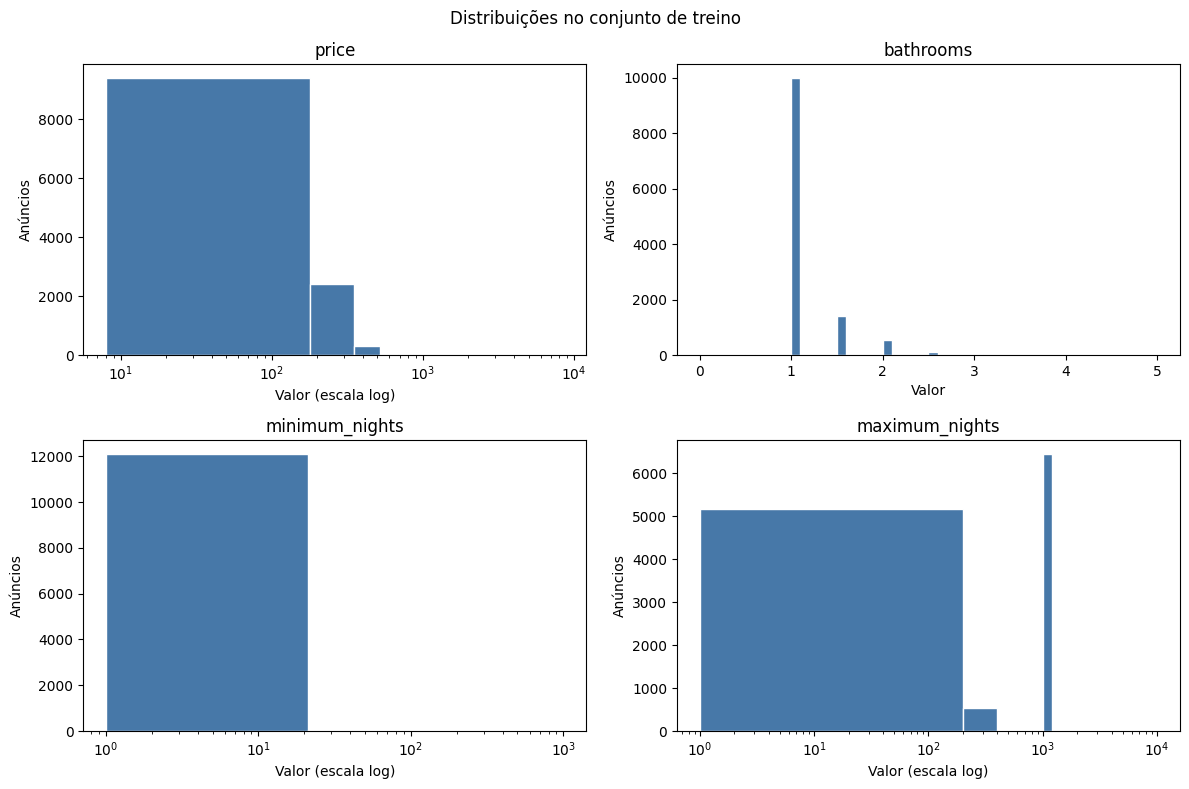

In [29]:
# 1. Importa a biblioteca de gráficos instalada no ambiente do kernel.
import matplotlib.pyplot as plt

# 2. Seleciona quatro distribuições do treino sem alterar seus valores.
eda_plot_columns = [
    "price", "bathrooms", "minimum_nights", "maximum_nights"
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 3. Desenha histogramas e usa escala logarítmica nas variáveis de cauda longa.
for plot_axis, plot_column in zip(axes.flat, eda_plot_columns):
    plot_values = df_train_eda[plot_column].dropna()
    plot_axis.hist(plot_values, bins=50, color="#4778a8", edgecolor="white")
    if plot_column in ["price", "minimum_nights", "maximum_nights"]:
        plot_axis.set_xscale("log")
    plot_axis.set_title(plot_column)
    plot_axis.set_xlabel(
        "Valor" + (" (escala log)" if plot_column != "bathrooms" else "")
    )
    plot_axis.set_ylabel("Anúncios")

# 4. Ajusta espaçamento e exibe os gráficos.
fig.suptitle("Distribuições no conjunto de treino")
fig.tight_layout()
plt.show()

Os histogramas mostram caudas longas em `price` e `minimum_nights`; `bathrooms` se concentra em 1. `maximum_nights` tem forte concentração em 1.125, compatível com a estatística descritiva. Esses padrões ficam registrados para interpretação posterior, sem exclusão de anúncios.

**Categorias e datas.** As tabelas resumem cardinalidade, ausências, frequência e proporção das preditoras categóricas. `host_since` será descrita separadamente como data, sem contar cada dia como categoria.

In [30]:
# 1. Importa a função de exibição das tabelas no notebook.
from IPython.display import display

# 2. Resume cardinalidade e ausências de cada preditora categórica.
eda_categorical_summary_rows = []
for eda_column in eda_categorical_columns:
    eda_categorical_summary_rows.append({
        "feature": eda_column,
        "cardinality_including_missing": int(
            df_train_eda[eda_column].nunique(dropna=False)
        ),
        "missing": int(df_train_eda[eda_column].isna().sum()),
        "missing_pct": float(
            df_train_eda[eda_column].isna().mean() * 100
        )
    })
eda_categorical_summary = pd.DataFrame(eda_categorical_summary_rows)
print("Resumo das preditoras categóricas no treino:")
display(eda_categorical_summary.round(3))

# 3. Resume datas em separado, sem tratar cada data como categoria.
eda_date_summary_rows = []
for eda_column in eda_date_columns:
    eda_date_values = pd.to_datetime(
        df_train_eda[eda_column], errors="coerce"
    )
    eda_date_summary_rows.append({
        "feature": eda_column,
        "date_min": eda_date_values.min(),
        "date_max": eda_date_values.max(),
        "unique_dates": int(eda_date_values.nunique(dropna=True)),
        "missing_or_invalid": int(eda_date_values.isna().sum())
    })
eda_date_summary = pd.DataFrame(eda_date_summary_rows)
print("Resumo das preditoras de data no treino:")
display(eda_date_summary)

# 4. Registra as dez categorias mais frequentes por preditora.
eda_categorical_frequency_rows = []
for eda_column in eda_categorical_columns:
    eda_category_counts = (
        df_train_eda[eda_column].value_counts(dropna=False).head(10)
    )
    for eda_category, eda_count in eda_category_counts.items():
        eda_categorical_frequency_rows.append({
            "feature": eda_column,
            "category": str(eda_category),
            "n": int(eda_count),
            "pct_train": float(eda_count / len(df_train_eda) * 100)
        })
eda_categorical_frequency = pd.DataFrame(
    eda_categorical_frequency_rows
)
print("Dez categorias mais frequentes por preditora:")
display(eda_categorical_frequency.round(2))

Resumo das preditoras categóricas no treino:


,feature,cardinality_including_missing,missing,missing_pct
0,room_type,3,0,0.0
1,property_type,27,0,0.0
2,neighbourhood_cleansed,22,0,0.0
3,host_is_superhost,2,0,0.0
4,instant_bookable,2,0,0.0
5,room_type_neighbourhood,60,0,0.0
6,property_type_room_type,53,0,0.0


Resumo das preditoras de data no treino:


,feature,date_min,date_max,unique_dates,missing_or_invalid
0,host_since,2008-09-24,2018-11-25,2639,0


Dez categorias mais frequentes por preditora:


,feature,category,n,pct_train
0,room_type,Entire home/apt,9674,79.38
1,room_type,Private room,2470,20.27
2,room_type,Shared room,43,0.35
3,property_type,Apartment,9495,77.91
4,property_type,House,880,7.22
5,property_type,Townhouse,380,3.12
6,property_type,Bed and breakfast,288,2.36
7,property_type,Loft,253,2.08
8,property_type,Boat,243,1.99
9,property_type,Condominium,212,1.74


As sete preditoras categóricas não têm ausências. `host_since` tem 2.639 datas distintas, de 2008-09-24 a 2018-11-25, sem valores inválidos na conversão. A data foi descrita separadamente; não será tratada como categoria nominal.

### 04.2 — Verificação bivariada

As duas primeiras perguntas avaliam se o preço anunciado varia entre tipos de acomodação e bairros. Para cada grupo, calculo contagem, mediana e quartis. O teste de Kruskal-Wallis e o epsilon-quadrado resumem diferença global e tamanho do efeito; não identificam causalidade nem quais pares diferem.

In [31]:
# 1. Importa os testes estatísticos e registra a versão usada.
import scipy
from scipy import stats
print("SciPy:", scipy.__version__)

# 2. Resume preço por grupo e calcula Kruskal-Wallis para tipo e bairro.
eda_group_summary_rows = []
eda_kruskal_rows = []
for eda_group_column in ["room_type", "neighbourhood_cleansed"]:
    eda_group_samples = []
    for eda_group_name, eda_group_data in df_train_eda.groupby(
        eda_group_column, observed=True
    ):
        eda_group_price = eda_group_data["price"].dropna()
        eda_group_samples.append(eda_group_price.to_numpy())
        eda_group_summary_rows.append({
            "feature": eda_group_column,
            "group": eda_group_name,
            "n": int(eda_group_price.size),
            "median": float(eda_group_price.median()),
            "q1": float(eda_group_price.quantile(0.25)),
            "q3": float(eda_group_price.quantile(0.75))
        })

    eda_kruskal_result = stats.kruskal(*eda_group_samples)
    eda_group_count = len(eda_group_samples)
    eda_sample_count = sum(len(sample) for sample in eda_group_samples)
    eda_epsilon_squared = max(
        0.0,
        (eda_kruskal_result.statistic - eda_group_count + 1)
        / (eda_sample_count - eda_group_count)
    )
    eda_p_value = float(eda_kruskal_result.pvalue)
    eda_p_value_report = (
        "< 1e-16 (underflow)"
        if eda_p_value == 0
        else f"{eda_p_value:.3e}"
    )
    eda_kruskal_rows.append({
        "feature": eda_group_column,
        "groups": eda_group_count,
        "n": eda_sample_count,
        "H": float(eda_kruskal_result.statistic),
        "p_value": eda_p_value_report,
        "epsilon_squared": float(eda_epsilon_squared)
    })

eda_group_price_summary = pd.DataFrame(eda_group_summary_rows)
eda_kruskal_summary = pd.DataFrame(eda_kruskal_rows)

# 3. Exibe o resumo por grupo e os resultados globais dos testes.
print("Preço no treino por tipo de acomodação e bairro:")
display(eda_group_price_summary.round(3))
print("Kruskal-Wallis e tamanho de efeito:")
display(eda_kruskal_summary.round(6))

SciPy: 1.15.3
Preço no treino por tipo de acomodação e bairro:


,feature,group,n,median,q1,q3
0,room_type,Entire home/apt,9674,139.0,104.00,180.00
1,room_type,Private room,2470,85.0,65.00,113.75
2,room_type,Shared room,43,75.0,50.00,112.50
3,neighbourhood_cleansed,Bijlmer-Centrum,60,79.5,54.25,102.50
4,neighbourhood_cleansed,Bijlmer-Oost,52,73.0,50.00,117.50
5,neighbourhood_cleansed,Bos en Lommer,693,100.0,85.00,138.00
6,neighbourhood_cleansed,Buitenveldert - Zuidas,147,102.0,80.00,159.50
7,neighbourhood_cleansed,Centrum-Oost,1028,150.0,115.00,203.50
8,neighbourhood_cleansed,Centrum-West,1459,150.0,119.00,215.50
9,neighbourhood_cleansed,De Aker - Nieuw Sloten,80,86.5,65.00,150.00


Kruskal-Wallis e tamanho de efeito:


,feature,groups,n,H,p_value,epsilon_squared
0,room_type,3,12187,2233.633718,< 1e-16 (underflow),0.183161
1,neighbourhood_cleansed,22,12187,1118.526733,1.481e-223,0.090220


Os preços medianos por tipo foram €139 para imóvel inteiro (`n=9.674`), €85 para quarto privado (`n=2.470`) e €75 para quarto compartilhado (`n=43`). Os testes globais indicam associação com tipo (`ε²=0,183`) e bairro (`ε²=0,090`). Há bairros com grupos menores, como Bijlmer-Oost (`n=52`); os resultados por bairro devem ser lidos com essa diferença de tamanho em mente.

As três perguntas restantes avaliam a associação monotônica entre preço e capacidade, entre preço e distância ao centro mediano do treino, e a diferença de preço entre superhosts e outros anfitriões. Uso Spearman nas relações numéricas e Mann-Whitney com correlação bisserial por postos na comparação binária.

In [32]:
# 1. Calcula correlação de Spearman para capacidade e distância ao centro mediano.
eda_spearman_rows = []
for eda_spearman_column in [
    "accommodates", "distance_to_training_center_km"
]:
    eda_spearman_result = stats.spearmanr(
        df_train_eda[eda_spearman_column],
        df_train_eda["price"]
    )
    eda_spearman_p_value = float(eda_spearman_result.pvalue)
    eda_spearman_p_report = (
        "< 1e-16 (underflow)"
        if eda_spearman_p_value == 0
        else f"{eda_spearman_p_value:.3e}"
    )
    eda_spearman_rows.append({
        "feature": eda_spearman_column,
        "n": len(df_train_eda),
        "spearman_rho": float(eda_spearman_result.statistic),
        "p_value": eda_spearman_p_report
    })
eda_spearman_summary = pd.DataFrame(eda_spearman_rows)

# 2. Resume os preços por status de superhost e compara as distribuições.
eda_superhost_groups = df_train_eda.groupby("is_superhost")["price"]
eda_superhost_samples = {}
eda_superhost_summary_rows = []
for eda_superhost_value, eda_superhost_price in eda_superhost_groups:
    eda_superhost_samples[int(eda_superhost_value)] = (
        eda_superhost_price.to_numpy()
    )
    eda_superhost_summary_rows.append({
        "is_superhost": int(eda_superhost_value),
        "n": int(eda_superhost_price.size),
        "median": float(eda_superhost_price.median()),
        "q1": float(eda_superhost_price.quantile(0.25)),
        "q3": float(eda_superhost_price.quantile(0.75))
    })
eda_superhost_prices = eda_superhost_samples[1]
eda_other_host_prices = eda_superhost_samples[0]
eda_mannwhitney_result = stats.mannwhitneyu(
    eda_superhost_prices,
    eda_other_host_prices,
    alternative="two-sided"
)
eda_rank_biserial = (
    2 * eda_mannwhitney_result.statistic
    / (len(eda_superhost_prices) * len(eda_other_host_prices))
) - 1
eda_mannwhitney_p_value = float(eda_mannwhitney_result.pvalue)
eda_mannwhitney_p_report = (
    "< 1e-16 (underflow)"
    if eda_mannwhitney_p_value == 0
    else f"{eda_mannwhitney_p_value:.3e}"
)
eda_superhost_summary = pd.DataFrame(eda_superhost_summary_rows)
eda_mannwhitney_summary = pd.DataFrame([{
    "n_superhost": len(eda_superhost_prices),
    "n_other": len(eda_other_host_prices),
    "U": float(eda_mannwhitney_result.statistic),
    "p_value": eda_mannwhitney_p_report,
    "rank_biserial": float(eda_rank_biserial)
}])

# 3. Exibe os resultados das três hipóteses restantes.
print("Spearman: associação entre preço, capacidade e distância:")
display(eda_spearman_summary.round(6))
print("Preço por status de superhost:")
display(eda_superhost_summary.round(3))
print("Mann-Whitney e tamanho de efeito:")
display(eda_mannwhitney_summary.round(6))

Spearman: associação entre preço, capacidade e distância:


,feature,n,spearman_rho,p_value
0,accommodates,12187,0.54697,< 1e-16 (underflow)
1,distance_to_training_center_km,12187,-0.28683,1.726e-229


Preço por status de superhost:


,is_superhost,n,median,q1,q3
0,0,10036,125.0,96.0,175.0
1,1,2151,125.0,95.0,179.5


Mann-Whitney e tamanho de efeito:


,n_superhost,n_other,U,p_value,rank_biserial
0,2151,10036,10983880.5,1.989e-01,0.017618


Na amostra de treino, `accommodates` tem associação positiva com `price` (`ρ=0,547`) e a distância ao centro mediano tem associação negativa (`ρ=-0,287`). Para superhosts e demais anfitriões, ambas as medianas são €125; Mann-Whitney não apontou diferença (`p=0,199`; `r_rb=0,018`). As relações observadas não são causais.

Os gráficos mostram preço contra capacidade e distância. O eixo de preço está em escala logarítmica para acomodar a cauda longa observada sem excluir valores.

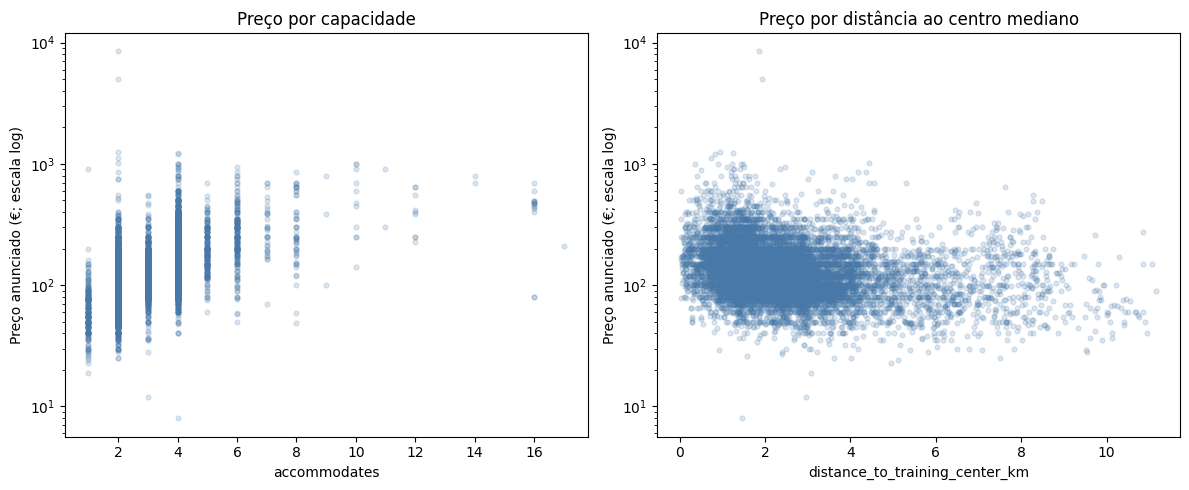

In [33]:
# 1. Cria gráficos de dispersão para as duas relações numéricas.
import matplotlib.pyplot as plt

eda_scatter_features = [
    "accommodates", "distance_to_training_center_km"
]
fig, eda_scatter_axes = plt.subplots(1, 2, figsize=(12, 5))

# 2. Exibe somente anúncios de treino e mantém todos os preços válidos.
for eda_scatter_axis, eda_scatter_column in zip(
    eda_scatter_axes, eda_scatter_features
):
    eda_scatter_axis.scatter(
        df_train_eda[eda_scatter_column],
        df_train_eda["price"],
        alpha=0.18,
        s=12,
        color="#4778a8"
    )
    eda_scatter_axis.set_yscale("log")
    eda_scatter_axis.set_title(
        "Preço por capacidade"
        if eda_scatter_column == "accommodates"
        else "Preço por distância ao centro mediano"
    )
    eda_scatter_axis.set_xlabel(eda_scatter_column)
    eda_scatter_axis.set_ylabel("Preço anunciado (€; escala log)")

# 3. Ajusta o espaçamento e exibe os gráficos.
fig.tight_layout()
plt.show()

Os gráficos são compatíveis com os sinais de Spearman, mas mostram ampla dispersão de preços para valores semelhantes de capacidade ou distância. As correlações resumem tendência monotônica e não predizem o preço individual.

### 04.3 — Verificação multivariada

A análise avalia redundância entre preditoras numéricas com Pearson e Spearman, e associação entre preditoras categóricas com Cramér V. `price`, `id` e `particao` ficam fora dessas matrizes.

In [34]:
# 1. Confere as colunas da análise multivariada e calcula as duas correlações.
eda_forbidden_corr_columns = {"price", "id", "particao"}
if eda_forbidden_corr_columns.intersection(eda_numeric_columns):
    raise ValueError("A análise numérica inclui alvo, ID ou partição.")
eda_numeric_predictor_data = df_train_eda[eda_numeric_columns].copy()
eda_pearson_matrix = eda_numeric_predictor_data.corr(method="pearson")
eda_spearman_matrix = eda_numeric_predictor_data.corr(method="spearman")

# 2. Resume os pares acima da diagonal para evitar duplicar comparações.
eda_numeric_pair_rows = []
for eda_pair_index, eda_left_column in enumerate(eda_numeric_columns):
    for eda_right_column in eda_numeric_columns[eda_pair_index + 1:]:
        eda_pair_pearson = float(
            eda_pearson_matrix.loc[eda_left_column, eda_right_column]
        )
        eda_pair_spearman = float(
            eda_spearman_matrix.loc[eda_left_column, eda_right_column]
        )
        eda_numeric_pair_rows.append({
            "feature_1": eda_left_column,
            "feature_2": eda_right_column,
            "pearson": eda_pair_pearson,
            "abs_pearson": abs(eda_pair_pearson),
            "spearman": eda_pair_spearman,
            "abs_spearman": abs(eda_pair_spearman)
        })
eda_numeric_pair_summary = pd.DataFrame(eda_numeric_pair_rows)

# 3. Exibe os pares mais associados e conta pares com magnitude de 0,90 ou mais.
eda_numeric_top_pearson = eda_numeric_pair_summary.sort_values(
    "abs_pearson", ascending=False
).head(10)
eda_numeric_top_spearman = eda_numeric_pair_summary.sort_values(
    "abs_spearman", ascending=False
).head(10)
eda_numeric_high_pearson_count = int(
    eda_numeric_pair_summary["abs_pearson"].ge(0.90).sum()
)
eda_numeric_high_spearman_count = int(
    eda_numeric_pair_summary["abs_spearman"].ge(0.90).sum()
)
print("Pares numéricos com |Pearson| >= 0,90:", eda_numeric_high_pearson_count)
print("Pares numéricos com |Spearman| >= 0,90:", eda_numeric_high_spearman_count)
print("Dez maiores pares por Pearson:")
display(eda_numeric_top_pearson.round(4))
print("Dez maiores pares por Spearman:")
display(eda_numeric_top_spearman.round(4))

Pares numéricos com |Pearson| >= 0,90: 8
Pares numéricos com |Spearman| >= 0,90: 14
Dez maiores pares por Pearson:


,feature_1,feature_2,pearson,abs_pearson,spearman,abs_spearman
507,is_superhost,rating_x_superhost,0.9996,0.9996,0.9939,0.9939
304,maximum_nights,maximum_nights_over_365,0.9800,0.9800,0.9249,0.9249
16,accommodates,accommodates_log1p,0.9646,0.9646,1.0000,1.0000
224,reviews_per_month,reviews_per_month_log1p,0.9505,0.9505,1.0000,1.0000
302,maximum_nights,maximum_nights_log1p,0.9471,0.9471,1.0000,1.0000
555,maximum_nights_over_365,maximum_nights_equals_1125,0.9419,0.9419,0.9419,0.9419
305,maximum_nights,maximum_nights_equals_1125,0.9227,0.9227,0.9258,0.9258
547,maximum_nights_log1p,maximum_nights_over_365,0.9205,0.9205,0.9249,0.9249
548,maximum_nights_log1p,maximum_nights_equals_1125,0.8676,0.8676,0.9258,0.9258
214,reviews_per_month,reviews_last_365d,0.8298,0.8298,0.7991,0.7991


Dez maiores pares por Spearman:


,feature_1,feature_2,pearson,abs_pearson,spearman,abs_spearman
16,accommodates,accommodates_log1p,0.9646,0.9646,1.0000,1.0000
224,reviews_per_month,reviews_per_month_log1p,0.9505,0.9505,1.0000,1.0000
278,minimum_nights,minimum_nights_log1p,0.4626,0.4626,1.0000,1.0000
168,host_listings_count,host_listings_log1p,0.8263,0.8263,1.0000,1.0000
302,maximum_nights,maximum_nights_log1p,0.9471,0.9471,1.0000,1.0000
197,number_of_reviews,number_of_reviews_log1p,0.7427,0.7427,1.0000,1.0000
507,is_superhost,rating_x_superhost,0.9996,0.9996,0.9939,0.9939
456,host_listings_log1p,host_has_multiple_listings,0.6264,0.6264,0.9884,0.9884
169,host_listings_count,host_has_multiple_listings,0.2794,0.2794,0.9884,0.9884
555,maximum_nights_over_365,maximum_nights_equals_1125,0.9419,0.9419,0.9419,0.9419


A auditoria encontrou 8 pares com `|Pearson| ≥ 0,90` e 14 com `|Spearman| ≥ 0,90`, mesmas contagens registradas na Etapa 03. Os maiores pares incluem features originais e suas transformações, além de `is_superhost` com `rating_x_superhost` (`Pearson=0,9996`). Nesta EDA, isso sinaliza redundância para comparação posterior; nenhuma feature será removida.

O heatmap abaixo mostra a correlação de Pearson entre as 34 preditoras numéricas do treino. A escala fixa de −1 a 1 facilita comparar associações; a diagonal representa a correlação de cada variável consigo mesma.

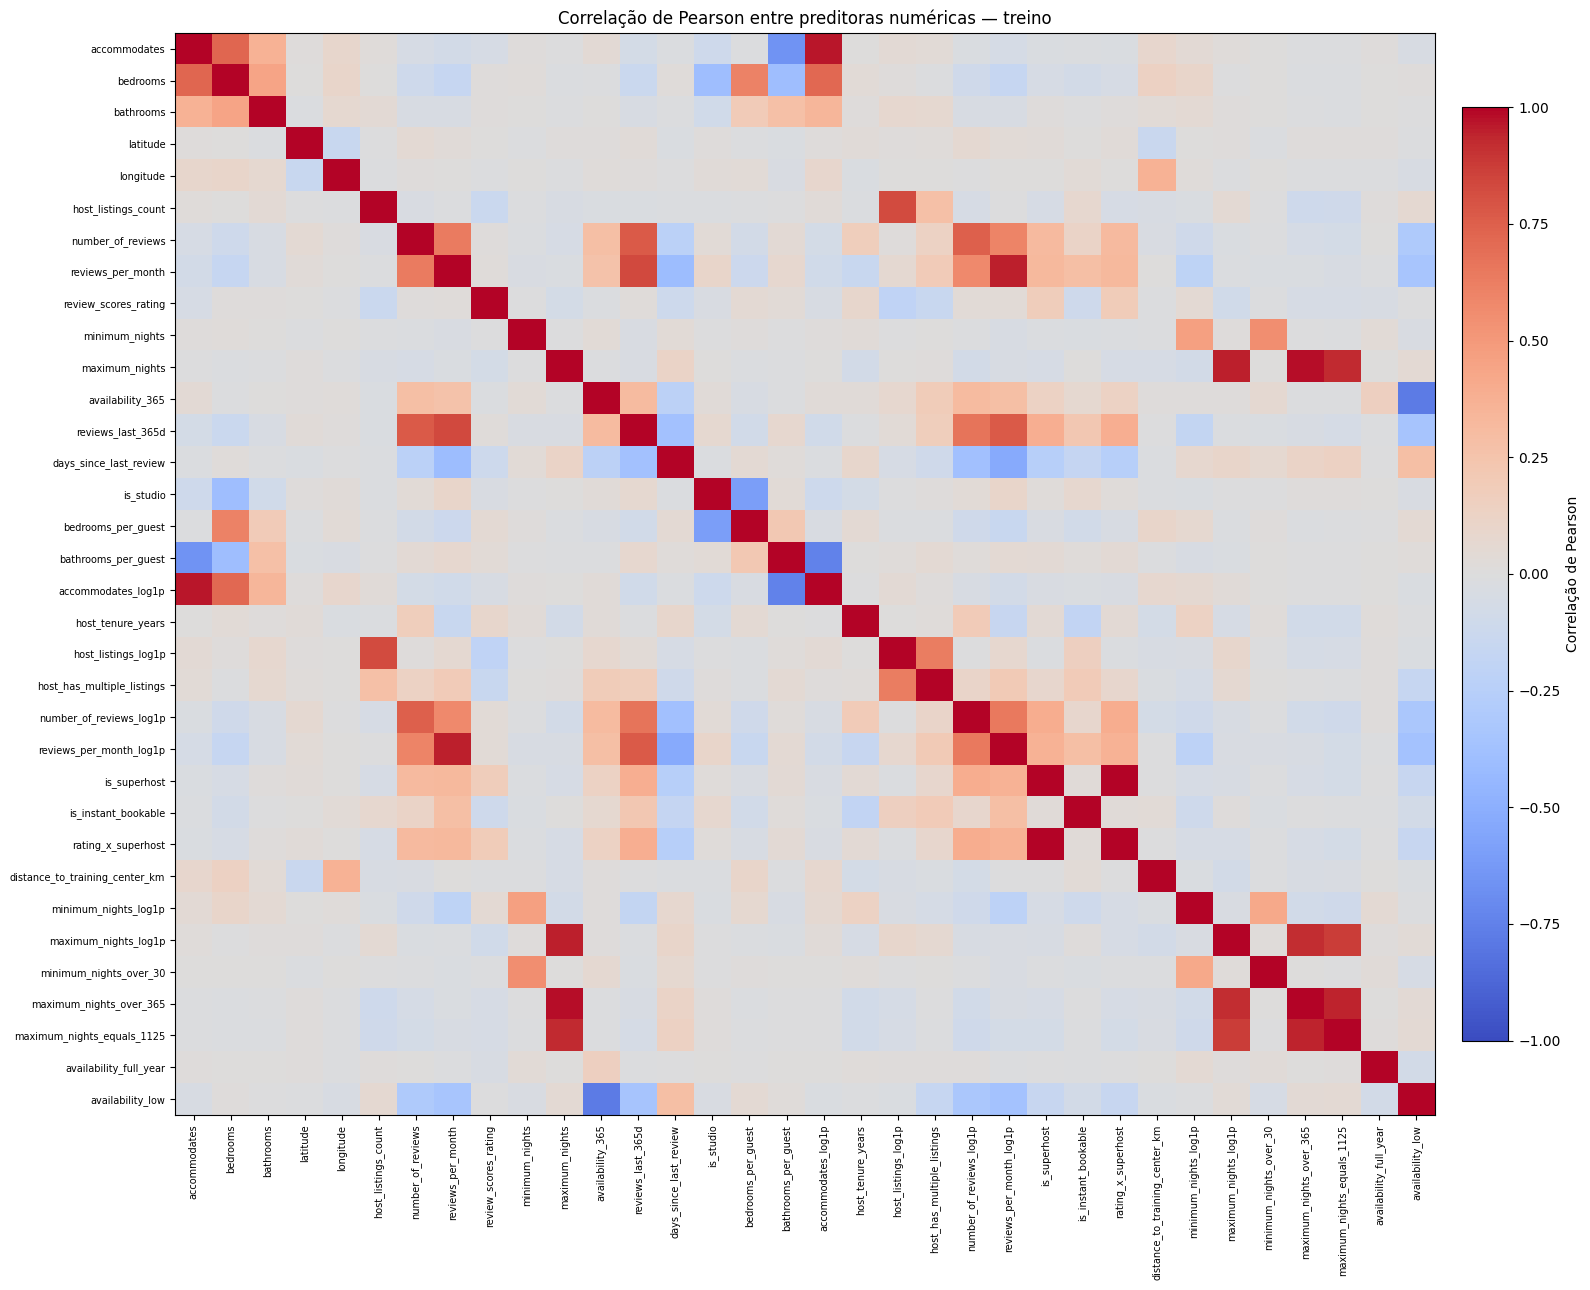

In [35]:
# 1. Converte a matriz de Pearson em um array para desenhar o heatmap.
eda_pearson_values = eda_pearson_matrix.to_numpy()

# 2. Cria uma figura ampla para manter os nomes das 34 preditoras legíveis.
fig, eda_pearson_axis = plt.subplots(figsize=(16, 13))
eda_pearson_image = eda_pearson_axis.imshow(
    eda_pearson_values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# 3. Exibe os nomes das preditoras nos dois eixos.
eda_pearson_axis.set_xticks(range(len(eda_numeric_columns)))
eda_pearson_axis.set_xticklabels(
    eda_numeric_columns,
    rotation=90,
    fontsize=7
)
eda_pearson_axis.set_yticks(range(len(eda_numeric_columns)))
eda_pearson_axis.set_yticklabels(eda_numeric_columns, fontsize=7)
eda_pearson_axis.set_title("Correlação de Pearson entre preditoras numéricas — treino")

# 4. Inclui uma barra com a escala fixa entre correlação negativa e positiva.
eda_pearson_colorbar = fig.colorbar(
    eda_pearson_image,
    ax=eda_pearson_axis,
    fraction=0.035,
    pad=0.02
)
eda_pearson_colorbar.set_label("Correlação de Pearson")
fig.tight_layout()
plt.show()

Para categorias, calculo Cramér V em cada par e registro a proporção de células com frequência esperada abaixo de 5. Esse indicador ajuda a identificar tabelas esparsas, comuns em combinações com muitas categorias; os valores não definem remoção nesta etapa.

In [36]:
# 1. Calcula Cramér V e sparsidade para todos os pares categóricos.
eda_categorical_pair_rows = []
for eda_pair_index, eda_left_column in enumerate(eda_categorical_columns):
    for eda_right_column in eda_categorical_columns[eda_pair_index + 1:]:
        eda_contingency = pd.crosstab(
            df_train_eda[eda_left_column],
            df_train_eda[eda_right_column],
            dropna=False
        )
        eda_chi2, eda_chi2_p_value, eda_degrees_freedom, eda_expected = (
            stats.chi2_contingency(eda_contingency, correction=False)
        )
        eda_n_for_table = int(eda_contingency.to_numpy().sum())
        eda_min_dimension = min(
            eda_contingency.shape[0] - 1,
            eda_contingency.shape[1] - 1
        )
        eda_cramers_v = np.sqrt(
            eda_chi2 / (eda_n_for_table * eda_min_dimension)
        )
        eda_expected_below_5_pct = float(
            (eda_expected < 5).mean() * 100
        )
        eda_categorical_pair_rows.append({
            "feature_1": eda_left_column,
            "feature_2": eda_right_column,
            "levels_1": eda_contingency.shape[0],
            "levels_2": eda_contingency.shape[1],
            "n": eda_n_for_table,
            "cramers_v": float(eda_cramers_v),
            "expected_cells_below_5_pct": eda_expected_below_5_pct
        })

eda_categorical_pair_summary = pd.DataFrame(
    eda_categorical_pair_rows
).sort_values("cramers_v", ascending=False)

# 2. Exibe as associações mais fortes e a sparsidade de cada tabela.
print("Pares categóricos ordenados por Cramér V:")
display(eda_categorical_pair_summary.round(4))

Pares categóricos ordenados por Cramér V:


,feature_1,feature_2,levels_1,levels_2,n,cramers_v,expected_cells_below_5_pct
4,room_type,room_type_neighbourhood,3,60,12187,1.0000,50.0000
10,property_type,property_type_room_type,27,53,12187,1.0000,93.9902
13,neighbourhood_cleansed,room_type_neighbourhood,22,60,12187,1.0000,69.7727
5,room_type,property_type_room_type,3,53,12187,1.0000,69.1824
20,room_type_neighbourhood,property_type_room_type,60,53,12187,0.3111,93.5849
0,room_type,property_type,3,27,12187,0.2525,64.1975
19,instant_bookable,property_type_room_type,2,53,12187,0.2341,54.7170
17,host_is_superhost,property_type_room_type,2,53,12187,0.2327,56.6038
18,instant_bookable,room_type_neighbourhood,2,60,12187,0.2257,25.0000
16,host_is_superhost,room_type_neighbourhood,2,60,12187,0.1915,26.6667


Este heatmap organiza os valores de Cramér V entre as 7 preditoras categóricas. A escala vai de 0 a 1; a diagonal vale 1 por comparar cada variável consigo mesma. Associações com tabelas esparsas devem ser interpretadas com cautela.

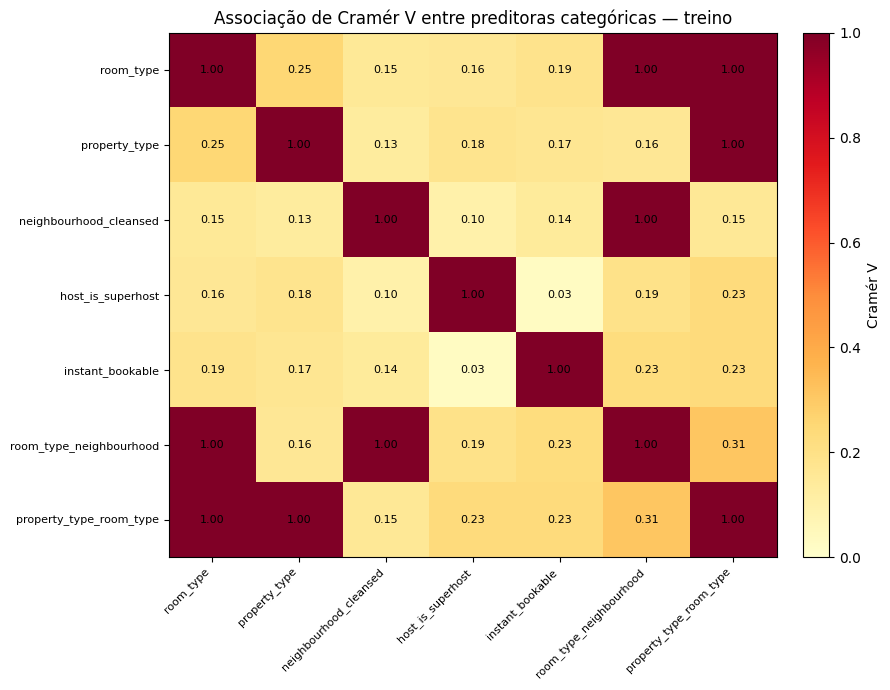

In [37]:
# 1. Inicializa uma matriz simétrica e define 1 na diagonal.
eda_cramers_matrix = pd.DataFrame(
    np.eye(len(eda_categorical_columns)),
    index=eda_categorical_columns,
    columns=eda_categorical_columns
)

# 2. Preenche cada par com o valor calculado anteriormente.
for eda_categorical_row in eda_categorical_pair_summary.itertuples(index=False):
    eda_cramers_matrix.loc[
        eda_categorical_row.feature_1,
        eda_categorical_row.feature_2
    ] = eda_categorical_row.cramers_v
    eda_cramers_matrix.loc[
        eda_categorical_row.feature_2,
        eda_categorical_row.feature_1
    ] = eda_categorical_row.cramers_v

# 3. Desenha a matriz com escala fixa entre 0 e 1.
fig, eda_cramers_axis = plt.subplots(figsize=(9, 7))
eda_cramers_image = eda_cramers_axis.imshow(
    eda_cramers_matrix.to_numpy(),
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    aspect="auto"
)
eda_cramers_axis.set_xticks(range(len(eda_categorical_columns)))
eda_cramers_axis.set_xticklabels(
    eda_categorical_columns,
    rotation=45,
    ha="right",
    fontsize=8
)
eda_cramers_axis.set_yticks(range(len(eda_categorical_columns)))
eda_cramers_axis.set_yticklabels(eda_categorical_columns, fontsize=8)
eda_cramers_axis.set_title("Associação de Cramér V entre preditoras categóricas — treino")

# 4. Anota cada célula para facilitar a leitura do conjunto compacto.
for eda_row_index in range(len(eda_categorical_columns)):
    for eda_column_index in range(len(eda_categorical_columns)):
        eda_cramers_axis.text(
            eda_column_index,
            eda_row_index,
            f"{eda_cramers_matrix.iloc[eda_row_index, eda_column_index]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )

# 5. Exibe a escala da associação e o heatmap.
eda_cramers_colorbar = fig.colorbar(
    eda_cramers_image,
    ax=eda_cramers_axis,
    fraction=0.046,
    pad=0.04
)
eda_cramers_colorbar.set_label("Cramér V")
fig.tight_layout()
plt.show()

Os maiores Cramér V (`1,00`) envolvem variáveis compostas com seus próprios componentes, como `room_type_neighbourhood` com tipo de acomodação ou bairro. Essa associação é esperada pela construção das features. Pares com muitas categorias têm alta proporção de frequências esperadas abaixo de 5; seus valores devem ser lidos com cautela. Nenhuma feature foi removida.

### 04.4 — Revisão de outliers e possíveis remoções

Vou conferir os preços marcados pelo IQR e os extremos de `bathrooms`, `minimum_nights` e `maximum_nights` junto a tipo, capacidade, bairro e outros campos disponíveis. O IQR serve para localizar casos; uma remoção só será recomendada se houver evidência de erro no registro.

In [38]:
# 1. Registra uma assinatura da visão de treino para confirmar que a revisão não altera os dados.
eda_review_rows_before = len(df_train_eda)
eda_review_columns_before = tuple(df_train_eda.columns)
eda_review_hash_before = int(
    pd.util.hash_pandas_object(df_train_eda, index=True).sum()
)

# 2. Seleciona atributos de contexto existentes sem presumir que todos estão na base.
eda_context_candidates = [
    "id", "price", "room_type", "property_type", "neighbourhood_cleansed",
    "accommodates", "bedrooms", "bathrooms", "minimum_nights",
    "maximum_nights", "availability_365", "number_of_reviews",
    "reviews_per_month", "review_scores_rating", "review_score_ratings",
    "is_superhost", "host_listings_count", "host_since", "instant_bookable"
]
eda_context_columns = [
    eda_column
    for eda_column in eda_context_candidates
    if eda_column in df_train_eda.columns
]
print("Campos de contexto disponíveis:", eda_context_columns)

# 3. Calcula o limite superior do IQR e quantifica os preços sinalizados.
eda_price_q1 = float(df_train_eda["price"].quantile(0.25))
eda_price_q3 = float(df_train_eda["price"].quantile(0.75))
eda_price_iqr = eda_price_q3 - eda_price_q1
eda_price_upper_iqr = eda_price_q3 + 1.5 * eda_price_iqr
eda_price_iqr_mask = df_train_eda["price"] > eda_price_upper_iqr
eda_price_iqr_rows = df_train_eda.loc[eda_price_iqr_mask].copy()
print(
    f"Price: Q1=€{eda_price_q1:.2f}; Q3=€{eda_price_q3:.2f}; "
    f"IQR={eda_price_iqr:.2f}; limite superior=€{eda_price_upper_iqr:.2f}"
)
print(
    "Preços acima do limite:",
    len(eda_price_iqr_rows),
    f"({len(eda_price_iqr_rows) / len(df_train_eda):.2%} do treino)"
)

# 4. Compara a frequência de preços sinalizados entre tipos de acomodação.
if "room_type" in df_train_eda.columns:
    eda_price_outlier_by_room = (
        df_train_eda.assign(eda_price_iqr_flag=eda_price_iqr_mask)
        .groupby("room_type", dropna=False)
        .agg(
            anuncios=("price", "size"),
            sinalizados=("eda_price_iqr_flag", "sum"),
            mediana_price=("price", "median"),
            maximo_price=("price", "max")
        )
        .reset_index()
    )
    eda_price_outlier_by_room["pct_sinalizados"] = (
        eda_price_outlier_by_room["sinalizados"]
        / eda_price_outlier_by_room["anuncios"]
        * 100
    )
    print("Preços sinalizados por tipo de acomodação:")
    display(eda_price_outlier_by_room.round(2))

# 5. Exibe os vinte maiores preços sinalizados com características do anúncio.
eda_price_top_context = (
    eda_price_iqr_rows[eda_context_columns]
    .sort_values("price", ascending=False)
    .head(20)
)
print("Vinte maiores preços sinalizados e contexto disponível:")
display(eda_price_top_context)

# 6. Resume distribuição e valores mais frequentes dos campos de banheiros e noites.
for eda_extreme_column in ["bathrooms", "minimum_nights", "maximum_nights"]:
    if eda_extreme_column in df_train_eda.columns:
        eda_extreme_values = pd.to_numeric(
            df_train_eda[eda_extreme_column],
            errors="coerce"
        )
        eda_extreme_description = eda_extreme_values.describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
        print(f"\nDistribuição de {eda_extreme_column}:")
        display(eda_extreme_description.to_frame(name=eda_extreme_column).T)
        print(f"Valores mais frequentes de {eda_extreme_column}:")
        display(
            eda_extreme_values.value_counts(dropna=False)
            .head(10)
            .rename_axis(eda_extreme_column)
            .reset_index(name="anuncios")
        )

# 7. Mostra os maiores valores de cada campo extremo junto ao contexto do anúncio.
for eda_extreme_column in ["bathrooms", "minimum_nights", "maximum_nights"]:
    if eda_extreme_column in df_train_eda.columns:
        eda_extreme_top_rows = (
            df_train_eda.loc[
                pd.to_numeric(df_train_eda[eda_extreme_column], errors="coerce").notna(),
                eda_context_columns
            ]
            .sort_values(eda_extreme_column, ascending=False)
            .head(12)
        )
        print(f"Doze maiores valores de {eda_extreme_column} e contexto:")
        display(eda_extreme_top_rows)

Campos de contexto disponíveis: ['id', 'price', 'room_type', 'property_type', 'neighbourhood_cleansed', 'accommodates', 'bedrooms', 'bathrooms', 'minimum_nights', 'maximum_nights', 'availability_365', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'is_superhost', 'host_listings_count', 'host_since', 'instant_bookable']
Price: Q1=€95.00; Q3=€175.00; IQR=80.00; limite superior=€295.00
Preços acima do limite: 665 (5.46% do treino)
Preços sinalizados por tipo de acomodação:


,room_type,anuncios,sinalizados,mediana_price,maximo_price,pct_sinalizados
0,Entire home/apt,9674,642,139.0,8500.0,6.64
1,Private room,2470,23,85.0,950.0,0.93
2,Shared room,43,0,75.0,260.0,0.0


Vinte maiores preços sinalizados e contexto disponível:


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
5745,12213707,8500.0,Entire home/apt,Apartment,Oud-Oost,2,1.0,1.0,3,6,362,13,0.48,91.0,0,1.0,2015-08-27,f
14757,29926643,5040.0,Entire home/apt,Apartment,Centrum-West,2,0.0,1.0,3,30,0,3,3.00,100.0,0,1.0,2018-11-09,t
9295,18350012,1254.0,Entire home/apt,Townhouse,Centrum-Oost,2,1.0,2.5,1,4,89,2,0.11,100.0,0,1.0,2011-04-18,f
14136,27919133,1230.0,Entire home/apt,Apartment,De Pijp - Rivierenbuurt,4,1.0,1.0,7,60,49,1,0.57,100.0,0,1.0,2011-12-19,f
7608,15118725,1200.0,Entire home/apt,Apartment,Centrum-West,4,1.0,1.0,14,15,333,12,0.49,87.0,0,1.0,2016-09-19,f
2731,5611174,1119.0,Entire home/apt,Apartment,De Baarsjes - Oud-West,2,1.0,1.0,7,21,0,3,0.07,93.0,0,1.0,2014-11-03,f
12908,24754201,1025.0,Entire home/apt,Apartment,Noord-West,2,1.0,1.0,15,15,66,1,0.16,100.0,0,1.0,2018-04-30,t
1949,3743958,1000.0,Entire home/apt,House,Westerpark,4,4.0,1.0,3,30,362,1,0.02,100.0,0,1.0,2013-06-12,f
8174,16254749,1000.0,Entire home/apt,House,De Pijp - Rivierenbuurt,4,2.0,1.5,3,60,362,10,0.43,94.0,0,1.0,2016-12-05,t
1206,2059078,999.0,Entire home/apt,Townhouse,Centrum-West,10,5.0,2.5,2,7,10,15,0.31,95.0,0,6.0,2013-11-12,f



Distribuição de bathrooms:


,count,mean,std,min,50%,90%,95%,99%,max
bathrooms,12187.0,1.123369,0.32394,0.0,1.0,1.5,2.0,2.5,5.0


... (12 outputs left out)

Doze maiores valores de minimum_nights e contexto:


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
9610,18816109,130.0,Private room,Apartment,De Pijp - Rivierenbuurt,4,2.0,1.0,1001,1125,89,24,1.62,92.0,0,2.0,2014-09-23,f
8741,17452735,91.0,Entire home/apt,Condominium,Zuid,2,1.0,1.0,300,500,188,8,0.37,94.0,0,1.0,2017-01-10,f
13312,25900530,39.0,Private room,House,De Aker - Nieuw Sloten,2,1.0,2.0,230,1125,175,3,0.64,60.0,0,1.0,2016-04-03,f
3446,6980353,300.0,Entire home/apt,Apartment,De Baarsjes - Oud-West,6,3.0,1.0,222,1125,87,15,0.36,97.0,0,1.0,2014-10-23,t
2516,4985612,100.0,Entire home/apt,Apartment,Westerpark,2,1.0,1.5,186,365,0,2,0.05,100.0,0,1.0,2015-01-06,f
3442,6971057,120.0,Entire home/apt,Apartment,Centrum-West,4,2.0,1.0,185,364,365,102,2.43,95.0,0,1.0,2015-06-23,f
277,588059,110.0,Entire home/apt,Condominium,Centrum-Oost,4,2.0,1.0,180,365,154,39,0.51,97.0,0,1.0,2011-12-13,f
3640,7353528,127.0,Entire home/apt,Apartment,De Baarsjes - Oud-West,4,2.0,1.0,100,1125,333,19,0.47,95.0,0,1.0,2014-05-02,f
4632,9485867,105.0,Entire home/apt,Apartment,De Pijp - Rivierenbuurt,2,0.0,1.0,95,1125,188,29,0.81,92.0,0,1.0,2015-04-21,f
10431,19956483,120.0,Entire home/apt,Apartment,Westerpark,3,1.0,1.0,90,1125,95,19,1.16,93.0,0,1.0,2016-05-28,f


Doze maiores valores de maximum_nights e contexto:


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
3680,7447773,90.0,Entire home/apt,Apartment,Slotervaart,3,2.0,1.0,3,9999,0,7,0.17,91.0,0,1.0,2015-07-20,f
200,467581,240.0,Entire home/apt,Apartment,Centrum-West,4,2.0,1.0,3,1825,0,153,1.94,89.0,0,6.0,2012-05-08,f
12,46386,150.0,Entire home/apt,Apartment,De Pijp - Rivierenbuurt,2,1.0,1.0,3,1825,0,3,0.03,93.0,0,1.0,2010-08-20,f
7820,15531290,100.0,Entire home/apt,Apartment,Westerpark,2,1.0,1.0,1,1125,73,9,0.35,98.0,0,1.0,2015-12-06,f
7798,15490175,109.0,Entire home/apt,Apartment,Bos en Lommer,4,2.0,1.0,2,1125,0,2,0.08,80.0,0,5.0,2015-09-21,f
14803,30423566,35.0,Private room,Condominium,Bijlmer-Oost,1,1.0,1.0,1,1125,195,1,1.00,100.0,0,1.0,2014-04-02,t
14802,30342336,55.0,Private room,Apartment,Centrum-West,2,1.0,1.0,1,1125,31,1,1.00,80.0,0,13.0,2018-08-30,t
14799,30244717,75.0,Entire home/apt,Guesthouse,De Aker - Nieuw Sloten,2,0.0,1.0,2,1125,268,1,1.00,100.0,1,2.0,2012-12-19,t
14775,30033851,101.0,Entire home/apt,Apartment,Geuzenveld - Slotermeer,4,1.0,1.0,1,1125,59,3,3.00,80.0,0,1.0,2017-07-26,f
14773,30005786,100.0,Entire home/apt,Apartment,Oostelijk Havengebied - Indische Buurt,2,1.0,1.0,7,1125,10,1,1.00,100.0,0,1.0,2018-08-06,t


Complemento da revisão: vou verificar os preços acima de €1.000, `bathrooms == 0`, inconsistências entre noites mínimas e máximas e os valores acima de 1.125 em `maximum_nights`. O dicionário do Inside Airbnb define `maximum_nights` como o limite máximo de estadia configurado e ressalva que regras do calendário podem diferir; ele não documenta 1.125 ou 9.999 como valores padrão. [Dicionário de dados do Inside Airbnb](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?usp=sharing).

In [39]:
# 1. Resume os anúncios sinalizados por IQR nos bairros com mais casos.
if "neighbourhood_cleansed" in df_train_eda.columns:
    eda_price_outlier_by_neighbourhood = (
        df_train_eda.assign(eda_price_iqr_flag=eda_price_iqr_mask)
        .groupby("neighbourhood_cleansed", dropna=False)
        .agg(
            anuncios=("price", "size"),
            sinalizados=("eda_price_iqr_flag", "sum"),
            mediana_price=("price", "median"),
            maximo_price=("price", "max")
        )
        .reset_index()
    )
    eda_price_outlier_by_neighbourhood["pct_sinalizados"] = (
        eda_price_outlier_by_neighbourhood["sinalizados"]
        / eda_price_outlier_by_neighbourhood["anuncios"]
        * 100
    )
    print("Bairros com mais preços sinalizados pelo IQR:")
    display(
        eda_price_outlier_by_neighbourhood
        .sort_values("sinalizados", ascending=False)
        .head(12)
        .round(2)
    )

# 2. Exibe anúncios acima de €1.000 para revisar os extremos mais altos.
eda_price_above_1000 = df_train_eda.loc[
    df_train_eda["price"].gt(1000),
    eda_context_columns
].sort_values("price", ascending=False)
print("Anúncios com price acima de €1.000:", len(eda_price_above_1000))
display(eda_price_above_1000)

# 3. Inspeciona anúncios com zero banheiros, incluindo tipo e capacidade.
if "bathrooms" in df_train_eda.columns:
    eda_zero_bathroom_rows = df_train_eda.loc[
        pd.to_numeric(df_train_eda["bathrooms"], errors="coerce").eq(0),
        eda_context_columns
    ]
    print("Anúncios com bathrooms igual a zero:", len(eda_zero_bathroom_rows))
    display(eda_zero_bathroom_rows)

# 4. Verifica se há anúncios em que noites mínimas superam noites máximas.
if {"minimum_nights", "maximum_nights"}.issubset(df_train_eda.columns):
    eda_nights_inconsistent_mask = (
        pd.to_numeric(df_train_eda["minimum_nights"], errors="coerce")
        > pd.to_numeric(df_train_eda["maximum_nights"], errors="coerce")
    )
    eda_nights_inconsistent_rows = df_train_eda.loc[
        eda_nights_inconsistent_mask,
        eda_context_columns
    ]
    print(
        "Anúncios com minimum_nights > maximum_nights:",
        len(eda_nights_inconsistent_rows)
    )
    display(eda_nights_inconsistent_rows.head(20))

# 5. Mostra contagens acima de 1.125 e o contexto do valor máximo.
if "maximum_nights" in df_train_eda.columns:
    eda_maximum_nights_numeric = pd.to_numeric(
        df_train_eda["maximum_nights"],
        errors="coerce"
    )
    eda_maximum_nights_counts = eda_maximum_nights_numeric.value_counts()
    eda_maximum_nights_above_1125 = (
        eda_maximum_nights_counts[
            eda_maximum_nights_counts.index > 1125
        ]
        .sort_index()
        .rename_axis("maximum_nights")
        .reset_index(name="anuncios")
    )
    print("Valores de maximum_nights acima de 1.125:")
    display(eda_maximum_nights_above_1125)
    eda_maximum_nights_top_value = eda_maximum_nights_numeric.max()
    eda_maximum_nights_top_rows = df_train_eda.loc[
        eda_maximum_nights_numeric.eq(eda_maximum_nights_top_value),
        eda_context_columns
    ]
    print(
        f"Contexto para o valor máximo de maximum_nights "
        f"({eda_maximum_nights_top_value}):"
    )
    display(eda_maximum_nights_top_rows)

Bairros com mais preços sinalizados pelo IQR:


,neighbourhood_cleansed,anuncios,sinalizados,mediana_price,maximo_price,pct_sinalizados
5,Centrum-West,1459,161,150.0,5040.0,11.03
4,Centrum-Oost,1028,114,150.0,1254.0,11.09
7,De Baarsjes - Oud-West,2186,92,125.0,1119.0,4.21
8,De Pijp - Rivierenbuurt,1494,77,135.0,1230.0,5.15
21,Zuid,842,63,129.0,950.0,7.48
20,Westerpark,913,33,123.0,1000.0,3.61
16,Oud-Noord,337,22,120.0,850.0,6.53
14,Oostelijk Havengebied - Indische Buurt,605,21,110.0,600.0,3.47
17,Oud-Oost,815,20,120.0,8500.0,2.45
11,IJburg - Zeeburgereiland,267,19,130.0,550.0,7.12


Anúncios com price acima de €1.000: 7


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
5745,12213707,8500.0,Entire home/apt,Apartment,Oud-Oost,2,1.0,1.0,3,6,362,13,0.48,91.0,0,1.0,2015-08-27,f
14757,29926643,5040.0,Entire home/apt,Apartment,Centrum-West,2,0.0,1.0,3,30,0,3,3.00,100.0,0,1.0,2018-11-09,t
9295,18350012,1254.0,Entire home/apt,Townhouse,Centrum-Oost,2,1.0,2.5,1,4,89,2,0.11,100.0,0,1.0,2011-04-18,f
14136,27919133,1230.0,Entire home/apt,Apartment,De Pijp - Rivierenbuurt,4,1.0,1.0,7,60,49,1,0.57,100.0,0,1.0,2011-12-19,f
7608,15118725,1200.0,Entire home/apt,Apartment,Centrum-West,4,1.0,1.0,14,15,333,12,0.49,87.0,0,1.0,2016-09-19,f
2731,5611174,1119.0,Entire home/apt,Apartment,De Baarsjes - Oud-West,2,1.0,1.0,7,21,0,3,0.07,93.0,0,1.0,2014-11-03,f
12908,24754201,1025.0,Entire home/apt,Apartment,Noord-West,2,1.0,1.0,15,15,66,1,0.16,100.0,0,1.0,2018-04-30,t


Anúncios com bathrooms igual a zero: 12


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
6,41125,180.0,Entire home/apt,Apartment,Centrum-West,2,1.0,0.0,3,21,11,76,0.78,95.0,0,1.0,2010-07-23,f
121,300067,45.0,Private room,Apartment,Oud-Oost,1,1.0,0.0,4,180,74,9,0.11,97.0,0,1.0,2011-12-29,f
967,1561264,75.0,Private room,Boat,Oostelijk Havengebied - Indische Buurt,2,1.0,0.0,1,5,365,137,2.43,97.0,0,1.0,2013-08-21,f
1044,1743234,77.0,Private room,Apartment,De Baarsjes - Oud-West,2,1.0,0.0,7,28,74,2,0.13,100.0,0,2.0,2013-04-12,t
1363,2477880,107.0,Private room,Loft,Centrum-West,4,1.0,0.0,1,1125,257,313,5.44,93.0,1,1.0,2014-02-18,f
3458,7018988,60.0,Private room,House,Gaasperdam - Driemond,2,1.0,0.0,1,7,360,43,1.07,82.0,0,2.0,2014-11-15,t
3859,7783993,50.0,Entire home/apt,Boat,Oud-Noord,3,1.0,0.0,1,1125,0,11,0.27,67.0,0,1.0,2015-08-09,f
5389,11417729,50.0,Private room,Apartment,Bos en Lommer,1,1.0,0.0,3,1125,9,62,1.89,98.0,1,2.0,2012-04-19,f
9952,19292540,73.0,Private room,Apartment,Slotervaart,2,1.0,0.0,2,7,0,37,2.18,92.0,0,1.0,2013-10-30,t
10261,19749454,125.0,Private room,Guesthouse,Watergraafsmeer,2,1.0,0.0,1,7,170,69,4.30,96.0,1,1.0,2012-02-16,t


... (2 outputs left out)

Valores de maximum_nights acima de 1.125:


,maximum_nights,anuncios
0,1825,2
1,9999,1


Contexto para o valor máximo de maximum_nights (9999):


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
3680,7447773,90.0,Entire home/apt,Apartment,Slotervaart,3,2.0,1.0,3,9999,0,7,0.17,91.0,0,1.0,2015-07-20,f


#### Resultado da revisão de extremos

- O limite superior do IQR para `price` foi €295; 665 anúncios (5,46%) ficaram acima dele. São 642 anúncios de imóvel inteiro e 23 de quarto privado; apenas 7 superam €1.000.
- Os maiores preços, €8.500 (ID 12213707) e €5.040 (ID 29926643), são muito atípicos. Os atributos disponíveis não comprovam erro de digitação; ambos permanecem.
- `bathrooms` tem 12 zeros e máximo 5. O máximo corresponde a um hotel para 17 hóspedes, com 5 quartos. A comparação de preço por `room_type` e `property_type` não apontou erro consistente nos zeros; mantidos sem recodificação.
- `minimum_nights` chega a 1.001; não há anúncio em que `minimum_nights > maximum_nights`. Os valores extremos não demonstram erro.
- Na amostra original de treino, `maximum_nights` vale 1.125 em 6.110 anúncios (50,1%); acima disso há dois casos com 1.825 e um com 9.999. Para o registro `id=7447773`, com `price=€90`, imóvel inteiro/apartamento, o usuário autorizou a exclusão de `df_modeling_features`. A linha integral ficou salva em `df_excluded_maximum_nights`; essa decisão não comprova erro na fonte.
- **Decisão:** manter os preços extremos, os 12 registros com `bathrooms=0` e os casos com `maximum_nights=1.825`. Excluir somente o anúncio de 9.999 do conjunto de modelagem por decisão do usuário; o restante dos dados não foi alterado.

A revisão e a comparação de banheiros usaram somente treino. Validação e teste não foram analisados.

### 04.4.1 — Verificação de `bathrooms = 0`

`bathrooms` é uma contagem; `room_type` e `property_type` descrevem tipos de acomodação separadamente. Vou comparar os 12 registros com anúncios do mesmo tipo de quarto e propriedade, usando contagens e quartis de preço. Isso ajuda a avaliar plausibilidade, mas não comprova sozinho um erro. [Dicionário do Inside Airbnb](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?usp=sharing).

In [40]:
# 1. Marca zeros de banheiro sem alterar os valores originais.
eda_bathroom_numeric = pd.to_numeric(
    df_train_eda["bathrooms"],
    errors="coerce"
)
eda_bathroom_zero_mask = eda_bathroom_numeric.eq(0)
eda_bathroom_analysis = df_train_eda.assign(
    eda_bathrooms_zero=eda_bathroom_zero_mask
)

# 2. Resume preço para anúncios com zero e com pelo menos um banheiro.
eda_bathroom_price_overall = (
    eda_bathroom_analysis
    .groupby("eda_bathrooms_zero")["price"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(2)
)
print(
    "Anúncios com bathrooms=0:",
    int(eda_bathroom_zero_mask.sum()),
    f"({eda_bathroom_zero_mask.mean():.2%} do treino)"
)
print("Distribuição de price: bathrooms=0 versus bathrooms>0:")
display(eda_bathroom_price_overall)

# 3. Compara os preços dentro de cada tipo de quarto.
eda_bathroom_price_by_room = (
    eda_bathroom_analysis
    .groupby(["room_type", "eda_bathrooms_zero"])["price"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(2)
    .reset_index()
)
print("Price por room_type e presença de banheiro registrado:")
display(eda_bathroom_price_by_room)

# 4. Seleciona combinações de quarto e propriedade que contêm algum zero.
eda_bathroom_zero_pairs = (
    df_train_eda.loc[
        eda_bathroom_zero_mask,
        ["room_type", "property_type"]
    ]
    .drop_duplicates()
)
eda_bathroom_price_by_pair = (
    eda_bathroom_analysis
    .groupby(
        ["room_type", "property_type", "eda_bathrooms_zero"]
    )["price"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(2)
    .reset_index()
    .merge(
        eda_bathroom_zero_pairs,
        on=["room_type", "property_type"],
        how="inner"
    )
)
print("Price em combinações room_type/property_type com bathrooms=0:")
display(eda_bathroom_price_by_pair)

# 5. Mostra cada registro zero com preço, capacidade e reputação disponíveis.
eda_bathroom_zero_context = (
    df_train_eda.loc[eda_bathroom_zero_mask, eda_context_columns]
    .sort_values(["room_type", "property_type", "price"])
)
print("Registros com bathrooms=0 para conferência individual:")
display(eda_bathroom_zero_context)

Anúncios com bathrooms=0: 12 (0.10% do treino)
Distribuição de price: bathrooms=0 versus bathrooms>0:


,count,mean,std,min,25%,50%,75%,max
eda_bathrooms_zero,,,,,,,,
False,12175.0,147.95,124.54,8.0,95.0,125.0,175.0,8500.0
True,12.0,89.17,45.09,45.0,57.5,74.0,111.5,180.0


Price por room_type e presença de banheiro registrado:


,room_type,eda_bathrooms_zero,count,mean,std,min,25%,50%,75%,max
0,Entire home/apt,False,9671.0,161.16,133.38,8.0,104.0,139.0,180.0,8500.0
1,Entire home/apt,True,3.0,131.0,70.66,50.0,106.5,163.0,171.5,180.0
2,Private room,False,2461.0,96.96,58.44,19.0,65.0,85.0,114.0,950.0
3,Private room,True,9.0,75.22,25.94,45.0,60.0,73.0,77.0,125.0
4,Shared room,False,43.0,93.91,62.8,25.0,50.0,75.0,112.5,260.0


Price em combinações room_type/property_type com bathrooms=0:


,room_type,property_type,eda_bathrooms_zero,count,mean,std,min,25%,50%,75%,max
0,Entire home/apt,Apartment,False,7962.0,152.59,134.09,8.0,100.0,130.0,175.0,8500.0
1,Entire home/apt,Apartment,True,1.0,180.0,<NA>,180.0,180.0,180.0,180.0,180.0
2,Entire home/apt,Boat,False,163.0,214.98,115.86,42.0,137.0,180.0,277.5,695.0
3,Entire home/apt,Boat,True,2.0,106.5,79.9,50.0,78.25,106.5,134.75,163.0
4,Private room,Apartment,False,1499.0,89.39,48.12,19.0,62.0,80.0,100.0,950.0
5,Private room,Apartment,True,5.0,62.0,14.04,45.0,50.0,65.0,73.0,77.0
6,Private room,Boat,False,77.0,135.73,104.28,35.0,80.0,115.0,150.0,700.0
7,Private room,Boat,True,1.0,75.0,<NA>,75.0,75.0,75.0,75.0,75.0
8,Private room,Guesthouse,False,18.0,111.72,58.43,50.0,76.25,90.5,113.75,250.0
9,Private room,Guesthouse,True,1.0,125.0,<NA>,125.0,125.0,125.0,125.0,125.0


Registros com bathrooms=0 para conferência individual:


,id,price,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,bathrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,is_superhost,host_listings_count,host_since,instant_bookable
6,41125,180.0,Entire home/apt,Apartment,Centrum-West,2,1.0,0.0,3,21,11,76,0.78,95.0,0,1.0,2010-07-23,f
3859,7783993,50.0,Entire home/apt,Boat,Oud-Noord,3,1.0,0.0,1,1125,0,11,0.27,67.0,0,1.0,2015-08-09,f
13903,27382781,163.0,Entire home/apt,Boat,Centrum-Oost,4,0.0,0.0,1,2,174,14,3.59,79.0,0,2.0,2017-06-13,t
121,300067,45.0,Private room,Apartment,Oud-Oost,1,1.0,0.0,4,180,74,9,0.11,97.0,0,1.0,2011-12-29,f
5389,11417729,50.0,Private room,Apartment,Bos en Lommer,1,1.0,0.0,3,1125,9,62,1.89,98.0,1,2.0,2012-04-19,f
13152,25385147,65.0,Private room,Apartment,De Pijp - Rivierenbuurt,2,1.0,0.0,2,7,0,38,5.88,94.0,0,1.0,2017-07-10,f
9952,19292540,73.0,Private room,Apartment,Slotervaart,2,1.0,0.0,2,7,0,37,2.18,92.0,0,1.0,2013-10-30,t
1044,1743234,77.0,Private room,Apartment,De Baarsjes - Oud-West,2,1.0,0.0,7,28,74,2,0.13,100.0,0,2.0,2013-04-12,t
967,1561264,75.0,Private room,Boat,Oostelijk Havengebied - Indische Buurt,2,1.0,0.0,1,5,365,137,2.43,97.0,0,1.0,2013-08-21,f
10261,19749454,125.0,Private room,Guesthouse,Watergraafsmeer,2,1.0,0.0,1,7,170,69,4.30,96.0,1,1.0,2012-02-16,t


#### Interpretação de `bathrooms = 0`

Os 12 casos são 9 quartos privados e 3 imóveis inteiros; incluem apartamentos, barcos, casa, loft e guesthouse. `bathrooms` é uma contagem, não um tipo de acomodação.

O preço não indica erro consistente. A mediana é €74 entre os 12 zeros e €125 nos demais anúncios. Dentro de `room_type`, quartos privados com zero têm mediana €73 (n=9), ante €85; imóveis inteiros, €163 (n=3), ante €139. Por `property_type`, quartos privados em apartamentos têm mediana €65 (n=5), ante €80; imóveis inteiros em barcos, €106,50 (n=2), ante €180. As outras combinações têm apenas um caso com zero, então não permitem uma comparação estável.

Esses valores não parecem claramente incompatíveis com o tipo de acomodação, mas a amostra pequena não confirma que sejam corretos. A base não permite distinguir zero banheiros de informação ausente codificada como zero; mantenho os 12 registros sem recodificação ou remoção.

### 04.4.3 — Exclusão autorizada de `maximum_nights = 9.999`

Por decisão do usuário, vou retirar o anúncio `id=7447773` do conjunto `df_modeling_features`, que será usado na modelagem. Isso não comprova que 9.999 seja erro de origem. A linha completa ficará em `df_excluded_maximum_nights` para restauração. `df_modeling_final`, os dados brutos e o teste não serão alterados.

In [41]:
# 1. Seleciona exclusivamente as linhas de treino e identifica o anúncio autorizado.
eda_training_indexes = df_modeling_features.index[
    df_modeling_features["particao"].eq("treino")
]
eda_training_view = df_modeling_features.loc[
    eda_training_indexes,
    ["id", "maximum_nights"]
]
eda_training_target_mask = (
    eda_training_view["id"].astype("string").eq("7447773")
    & pd.to_numeric(
        eda_training_view["maximum_nights"],
        errors="coerce"
    ).eq(9999)
)
eda_target_indexes = eda_training_view.index[eda_training_target_mask]

# 2. Guarda a linha completa e permite reexecutar a célula sem duplicar a remoção.
if len(eda_target_indexes) == 1:
    if "df_excluded_maximum_nights" in globals():
        eda_backup_matches_target = (
            len(df_excluded_maximum_nights) == 1
            and df_excluded_maximum_nights["id"].astype("string").eq("7447773").all()
            and df_excluded_maximum_nights["particao"].eq("treino").all()
            and pd.to_numeric(
                df_excluded_maximum_nights["maximum_nights"],
                errors="coerce"
            ).eq(9999).all()
        )
        if not eda_backup_matches_target:
            raise ValueError("O backup existente não corresponde ao anúncio autorizado.")
        if not df_excluded_maximum_nights.equals(
            df_modeling_features.loc[eda_target_indexes]
        ):
            raise ValueError("A linha atual difere do backup já registrado.")
    else:
        df_excluded_maximum_nights = df_modeling_features.loc[
            eda_target_indexes
        ].copy()
elif len(eda_target_indexes) == 0 and "df_excluded_maximum_nights" in globals():
    eda_backup_matches_target = (
        len(df_excluded_maximum_nights) == 1
        and df_excluded_maximum_nights["id"].astype("string").eq("7447773").all()
        and df_excluded_maximum_nights["particao"].eq("treino").all()
        and pd.to_numeric(
            df_excluded_maximum_nights["maximum_nights"],
            errors="coerce"
        ).eq(9999).all()
    )
    if not eda_backup_matches_target:
        raise ValueError("O backup existente não corresponde ao anúncio autorizado.")
else:
    raise ValueError("Esperava encontrar uma única linha alvo ou o backup da exclusão.")

# 3. Remove só o registro autorizado; a validação e o teste não são usados na análise.
if len(eda_target_indexes) == 1:
    if not df_modeling_features.index.is_unique:
        raise ValueError("O índice não é único; a exclusão não foi aplicada.")
    df_modeling_features = df_modeling_features.drop(index=eda_target_indexes).copy()

# 4. Confere a contagem esperada e exibe a linha guardada para fallback.
eda_train_count_after_maximum_nights = int(
    df_modeling_features["particao"].eq("treino").sum()
)
eda_target_id_still_present = (
    df_modeling_features.loc[
        df_modeling_features["particao"].eq("treino"),
        "id"
    ].astype("string").eq("7447773").any()
)
if (
    len(df_modeling_features) != 14805
    or eda_train_count_after_maximum_nights != 12186
    or eda_target_id_still_present
    or len(df_excluded_maximum_nights) != 1
):
    raise ValueError("A exclusão ou a contagem final não corresponde ao esperado.")

print("Linha excluída somente de df_modeling_features:")
display(
    df_excluded_maximum_nights[
        ["id", "particao", "price", "room_type", "property_type", "maximum_nights"]
    ]
)
print("Linhas restantes no conjunto de modelagem:", len(df_modeling_features))
print("Anúncios de treino restantes:", eda_train_count_after_maximum_nights)
print("Backup integral disponível:", df_excluded_maximum_nights.shape)
print("df_modeling_final, dados brutos e df_test não foram alterados por esta célula.")

Linha excluída somente de df_modeling_features:


,id,particao,price,room_type,property_type,maximum_nights
3680,7447773,treino,90.0,Entire home/apt,Apartment,9999


Linhas restantes no conjunto de modelagem: 14805
Anúncios de treino restantes: 12186
Backup integral disponível: (1, 45)
df_modeling_final, dados brutos e df_test não foram alterados por esta célula.


**Fallback para restaurar a linha no conjunto de modelagem:**

```python
df_modeling_features = pd.concat(
    [df_modeling_features, df_excluded_maximum_nights]
).sort_index()
```

O backup `df_excluded_maximum_nights` preserva as 45 colunas e o índice original. A análise de `bathrooms = 0` não mostrou evidência suficiente para remover ou recodificar os 12 registros.

### 04.5 — Verificação final e gate

Confirmo que as análises usaram apenas treino, que a amostra de EDA permaneceu intacta e que o conjunto de modelagem exclui somente a linha autorizada de `maximum_nights = 9.999`, com backup para restauração. As matrizes de correlação continuam sem o alvo.

In [42]:
# 1. Confere cobertura e separação das preditoras por tipo.
eda_numeric_feature_set = set(eda_numeric_columns)
eda_categorical_feature_set = set(eda_categorical_columns)
eda_date_feature_set = set(eda_date_columns)
eda_feature_groups_are_disjoint = (
    not eda_numeric_feature_set.intersection(eda_categorical_feature_set)
    and not eda_numeric_feature_set.intersection(eda_date_feature_set)
    and not eda_categorical_feature_set.intersection(eda_date_feature_set)
)
eda_feature_groups_cover_predictors = (
    eda_numeric_feature_set
    | eda_categorical_feature_set
    | eda_date_feature_set
) == set(eda_predictor_columns)

# 2. Confere a amostra original de EDA, o alvo e o hash salvo antes das análises.
eda_train_only = (
    len(df_train_eda) == 12187
    and df_train_eda["particao"].eq("treino").all()
)
eda_target_valid = (
    df_train_eda["price"].notna().all()
    and df_train_eda["price"].gt(0).all()
)
eda_predictor_missing_count = int(
    df_train_eda[eda_predictor_columns].isna().sum().sum()
)
eda_forbidden_columns_absent = not eda_forbidden_corr_columns.intersection(
    eda_numeric_predictor_data.columns
)
eda_hypotheses_covered = (
    len(eda_kruskal_summary) == 2
    and len(eda_spearman_summary) == 2
    and len(eda_mannwhitney_summary) == 1
)
eda_review_rows_after = len(df_train_eda)
eda_review_columns_after = tuple(df_train_eda.columns)
eda_review_hash_after = int(
    pd.util.hash_pandas_object(df_train_eda, index=True).sum()
)
eda_review_data_unchanged = (
    eda_review_rows_after == eda_review_rows_before
    and eda_review_columns_after == eda_review_columns_before
    and eda_review_hash_after == eda_review_hash_before
)

# 3. Confere as matrizes de Pearson e Cramér V construídas no treino.
eda_pearson_heatmap_valid = (
    eda_pearson_matrix.shape
    == (len(eda_numeric_columns), len(eda_numeric_columns))
    and np.isfinite(eda_pearson_matrix.to_numpy()).all()
)
eda_cramers_heatmap_valid = (
    eda_cramers_matrix.shape
    == (len(eda_categorical_columns), len(eda_categorical_columns))
    and np.isfinite(eda_cramers_matrix.to_numpy()).all()
    and np.allclose(
        eda_cramers_matrix.to_numpy(),
        eda_cramers_matrix.to_numpy().T
    )
    and np.allclose(np.diag(eda_cramers_matrix.to_numpy()), 1)
    and eda_categorical_pair_summary["cramers_v"].between(0, 1).all()
)
eda_outliers_train_only = eda_price_iqr_rows["particao"].eq("treino").all()

# 4. Confere a exclusão autorizada apenas nas linhas de treino e o backup integral.
eda_modeling_train = df_modeling_features.loc[
    df_modeling_features["particao"].eq("treino")
].copy()
eda_modeling_validation_count = int(
    df_modeling_features["particao"].eq("validação").sum()
)
eda_modeling_target_removed = not (
    eda_modeling_train["id"].astype("string").eq("7447773").any()
)
eda_modeling_partition_counts_valid = (
    len(df_modeling_features) == 14805
    and len(eda_modeling_train) == 12186
    and eda_modeling_validation_count == 2619
)
eda_excluded_backup_valid = (
    len(df_excluded_maximum_nights) == 1
    and tuple(df_excluded_maximum_nights.columns)
    == tuple(df_modeling_features.columns)
    and df_excluded_maximum_nights["id"].astype("string").eq("7447773").all()
    and df_excluded_maximum_nights["particao"].eq("treino").all()
    and pd.to_numeric(
        df_excluded_maximum_nights["maximum_nights"],
        errors="coerce"
    ).eq(9999).all()
)
eda_modeling_train_matches_snapshot = eda_modeling_train.sort_index().equals(
    df_train_eda.loc[
        ~df_train_eda["id"].astype("string").eq("7447773")
    ].sort_index()
)
eda_bathroom_zero_count_preserved = int(
    pd.to_numeric(
        eda_modeling_train["bathrooms"],
        errors="coerce"
    ).eq(0).sum()
) == 12

# 5. Interrompe a conclusão se qualquer critério de escopo falhar.
if not all([
    eda_train_only,
    eda_target_valid,
    eda_feature_groups_are_disjoint,
    eda_feature_groups_cover_predictors,
    eda_predictor_missing_count == 0,
    eda_forbidden_columns_absent,
    eda_hypotheses_covered,
    eda_pearson_heatmap_valid,
    eda_cramers_heatmap_valid,
    eda_outliers_train_only,
    eda_review_data_unchanged,
    eda_modeling_target_removed,
    eda_modeling_partition_counts_valid,
    eda_excluded_backup_valid,
    eda_modeling_train_matches_snapshot,
    eda_bathroom_zero_count_preserved
]):
    raise ValueError("As verificações finais da Etapa 04 falharam.")

# 6. Exibe os checks, mantendo validação e teste fora das análises.
print("Amostra de EDA: somente treino e sem alteração:", eda_train_only, eda_review_data_unchanged)
print("Preço do treino válido:", eda_target_valid)
print(
    "Preditoras cobertas e grupos sem sobreposição:",
    eda_feature_groups_cover_predictors,
    eda_feature_groups_are_disjoint
)
print("Ausências entre preditoras do treino:", eda_predictor_missing_count)
print("Alvo, ID e partição fora das matrizes numéricas:", eda_forbidden_columns_absent)
print("Hipóteses bivariadas analisadas:", 2 + 2 + 1)
print("Heatmap Pearson 34x34 válido:", eda_pearson_heatmap_valid)
print("Heatmap Cramér V 7x7 válido:", eda_cramers_heatmap_valid)
print("Extremos revisados somente no treino:", eda_outliers_train_only)
print("Anúncio 7447773 excluído do conjunto de modelagem:", eda_modeling_target_removed)
print("Partições após exclusão (treino, validação, total):", len(eda_modeling_train), eda_modeling_validation_count, len(df_modeling_features))
print("Backup integral validado:", eda_excluded_backup_valid)
print("Treino restante igual ao snapshot menos a linha autorizada:", eda_modeling_train_matches_snapshot)
print("Registros com bathrooms=0 preservados:", eda_bathroom_zero_count_preserved)
print("Pares numéricos avaliados:", len(eda_numeric_pair_summary))
print("Pares categóricos avaliados:", len(eda_categorical_pair_summary))
print("Features alteradas nesta etapa: 0; uma linha removida do conjunto de modelagem por decisão do usuário.")

Amostra de EDA: somente treino e sem alteração: True True
Preço do treino válido: True
Preditoras cobertas e grupos sem sobreposição: True True
Ausências entre preditoras do treino: 0
Alvo, ID e partição fora das matrizes numéricas: True
Hipóteses bivariadas analisadas: 5
Heatmap Pearson 34x34 válido: True
Heatmap Cramér V 7x7 válido: True
Extremos revisados somente no treino: True
Anúncio 7447773 excluído do conjunto de modelagem: True
Partições após exclusão (treino, validação, total): 12186 2619 14805
Backup integral validado: True
Treino restante igual ao snapshot menos a linha autorizada: True
Registros com bathrooms=0 preservados: True
Pares numéricos avaliados: 561
Pares categóricos avaliados: 21
Features alteradas nesta etapa: 0; uma linha removida do conjunto de modelagem por decisão do usuário.


#### Resultado e gate da Etapa 04

- A EDA usou a amostra original de 12.187 anúncios de treino e 42 preditoras. A verificação confirmou os heatmaps Pearson 34×34 e Cramér V 7×7 e as cinco hipóteses bivariadas.
- O limite superior do IQR para `price` foi €295; 665 anúncios foram sinalizados. Os extremos de €8.500 e €5.040 não têm evidência suficiente para serem classificados como erro.
- `bathrooms = 0` aparece em 12 anúncios: 9 quartos privados e 3 imóveis inteiros. A mediana de preço é €74 (n=12), ante €125 nos anúncios com banheiro positivo. A amostra não confirma se zero é correto; os 12 registros foram mantidos.
- O anúncio `id=7447773` (`maximum_nights=9999`, `price=€90`, imóvel inteiro/apartamento) foi removido de `df_modeling_features` por decisão explícita do usuário. A linha completa está em `df_excluded_maximum_nights` (1×45), com fallback para restauração.
- Após a exclusão, `df_modeling_features` tem 14.805 linhas e 45 colunas: 12.186 de treino e 2.619 de validação. A amostra original de EDA permanece intacta; o teste não foi usado.

**Estado do projeto**

- **Status:** Etapa 04 executada e aprovada; Etapa 05 autorizada para execução.
- **Última etapa aprovada:** Etapa 04.
- **Decisões:** manter os 12 anúncios com `bathrooms=0`; retirar o registro de `maximum_nights=9999` do conjunto de modelagem, preservando backup para fallback.
- **Próxima etapa:** seleção de features somente com treino; validação será usada para comparação final; teste permanecerá intocado.

## Etapa 05 — Seleção de Features

Esta etapa identifica atributos úteis e estáveis para estimar `price`. A seleção será ajustada somente nas linhas de treino. A validação servirá apenas para comparar os conjuntos de atributos; o teste continuará intocado.

### 05.1 — Verificação dos dados e candidatos

Carrego as bibliotecas usadas nesta etapa e confiro as partições, o alvo e as 42 preditoras definidas na Etapa 03. IDs, alvo e partição ficam fora da matriz de atributos.

In [43]:
# 1. Carrega as bibliotecas de seleção, pré-processamento e avaliação.
import sklearn
import numpy as np
import pandas as pd
from boruta import BorutaPy
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# 2. Recupera as preditoras já classificadas na EDA e define colunas proibidas.
selection_candidate_columns = list(eda_predictor_columns)
selection_forbidden_columns = {"id", "price", "particao"}
selection_train = df_modeling_features.loc[
    df_modeling_features["particao"].eq("treino")
].copy()
selection_validation = df_modeling_features.loc[
    df_modeling_features["particao"].eq("validação")
].copy()

# 3. Confere partições, alvo, candidatos e separação do teste.
selection_candidates_valid = (
    len(selection_candidate_columns) == 42
    and not selection_forbidden_columns.intersection(selection_candidate_columns)
    and set(eda_numeric_columns).union(eda_categorical_columns, eda_date_columns)
    == set(selection_candidate_columns)
)
selection_partitions_valid = (
    len(selection_train) == 12186
    and len(selection_validation) == 2619
    and selection_train["price"].gt(0).all()
    and selection_validation["price"].gt(0).all()
)
if not selection_candidates_valid or not selection_partitions_valid:
    raise ValueError("A base ou os grupos de preditoras diferem do escopo aprovado.")

# 4. Mostra o ambiente, as dimensões e os grupos de atributos verificados.
print("scikit-learn:", sklearn.__version__)
print("BorutaPy:", BorutaPy.__name__)
print("Treino e validação:", selection_train.shape, selection_validation.shape)
print("Preditoras candidatas:", len(selection_candidate_columns))
print("Numéricas, categóricas e datas:", len(eda_numeric_columns), len(eda_categorical_columns), len(eda_date_columns))
print("Teste não foi carregado nem consultado nesta etapa.")

scikit-learn: 1.7.2
BorutaPy: BorutaPy
Treino e validação: (12186, 45) (2619, 45)
Preditoras candidatas: 42
Numéricas, categóricas e datas: 34 7 1
Teste não foi carregado nem consultado nesta etapa.


In [62]:
# 1. Resume grupo, tipo, ausências e cardinalidade observados somente no treino.
selection_feature_groups = {
    **dict.fromkeys(eda_numeric_columns, "numérica"),
    **dict.fromkeys(eda_categorical_columns, "categórica"),
    **dict.fromkeys(eda_date_columns, "data"),
}
selection_profile = pd.DataFrame({
    "feature": selection_candidate_columns,
    "grupo": [selection_feature_groups[column] for column in selection_candidate_columns],
    "dtype": [str(selection_train[column].dtype) for column in selection_candidate_columns],
    "ausentes_treino": [int(selection_train[column].isna().sum()) for column in selection_candidate_columns],
    "valores_distintos_treino": [int(selection_train[column].nunique(dropna=False)) for column in selection_candidate_columns],
})

# 2. Confirma a referência temporal e apresenta o perfil das categorias.
print("Referência de host_since:", stage03_snapshot_date.date())
print("Intervalo de host_since no treino:", selection_train["host_since"].min(), selection_train["host_since"].max())
display(selection_profile.loc[selection_profile["grupo"].ne("numérica")])
print("Categorias no treino:", {
    column: int(selection_train[column].nunique(dropna=False))
    for column in eda_categorical_columns
})

Referência de host_since: 2018-12-06
Intervalo de host_since no treino: 2008-09-24 00:00:00 2018-11-25 00:00:00


,feature,grupo,dtype,ausentes_treino,valores_distintos_treino
0,room_type,categórica,object,0,3
1,property_type,categórica,object,0,27
5,neighbourhood_cleansed,categórica,object,0,22
8,host_is_superhost,categórica,object,0,2
9,host_since,data,datetime64[ns],0,2639
17,instant_bookable,categórica,object,0,2
31,room_type_neighbourhood,categórica,string,0,60
32,property_type_room_type,categórica,string,0,53


Categorias no treino: {'room_type': 3, 'property_type': 27, 'neighbourhood_cleansed': 22, 'host_is_superhost': 2, 'instant_bookable': 2, 'room_type_neighbourhood': 60, 'property_type_room_type': 53}


### 05.2 — Boruta e estabilidade no treino

Aplico validação cruzada de cinco folds apenas sobre o treino. Em cada fold, imputadores, codificador one-hot e Boruta são ajustados na parte de ajuste daquele fold. Os indicadores one-hot são depois reunidos sob a feature categórica de origem.

In [45]:
# 1. Separa atributos e alvo do treino, sem consultar validação ou teste.
selection_X_train = selection_train.loc[:, selection_feature_columns].copy()
selection_y_train = selection_train["price"].copy()
selection_kfold = KFold(n_splits=5, shuffle=True, random_state=42)
selection_confirmed_fold_count = pd.Series(0, index=selection_feature_columns, dtype="int64")
selection_tentative_fold_count = pd.Series(0, index=selection_feature_columns, dtype="int64")
selection_fold_best_ranks = {column: [] for column in selection_feature_columns}
selection_fold_summaries = []

# 2. Ajusta pré-processamento e Boruta de forma independente em cada fold.
for selection_fold_number, (selection_fit_index, selection_holdout_index) in enumerate(
    selection_kfold.split(selection_X_train),
    start=1,
):
    selection_X_fold_fit = selection_X_train.iloc[selection_fit_index]
    selection_y_fold_fit = selection_y_train.iloc[selection_fit_index]

    selection_preprocessor = ColumnTransformer(
        transformers=[
            (
                "numericas",
                Pipeline([
                    ("imputador", SimpleImputer(strategy="median")),
                ]),
                selection_numeric_columns,
            ),
            (
                "categoricas",
                Pipeline([
                    ("imputador", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                    )),
                ]),
                selection_categorical_columns,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    selection_preprocessor.fit(selection_X_fold_fit, selection_y_fold_fit)
    selection_X_fold_encoded = selection_preprocessor.transform(selection_X_fold_fit)

    selection_fold_encoder = (
        selection_preprocessor.named_transformers_["categoricas"]
        .named_steps["onehot"]
    )
    selection_encoded_feature_sources = list(selection_numeric_columns)
    for selection_category_column, selection_categories in zip(
        selection_categorical_columns,
        selection_fold_encoder.categories_,
    ):
        selection_encoded_feature_sources.extend(
            [selection_category_column] * len(selection_categories)
        )

    if (
        selection_X_fold_encoded.shape[1] != len(selection_encoded_feature_sources)
        or not np.isfinite(selection_X_fold_encoded).all()
    ):
        raise ValueError("A matriz pré-processada do fold contém dimensão ou valor inválido.")

    selection_boruta_estimator = RandomForestRegressor(
        n_estimators=80,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42 + selection_fold_number,
        n_jobs=-1,
    )
    selection_boruta = BorutaPy(
        estimator=selection_boruta_estimator,
        n_estimators=80,
        max_iter=30,
        random_state=42 + selection_fold_number,
        verbose=0,
    )
    selection_boruta.fit(
        selection_X_fold_encoded,
        selection_y_fold_fit.to_numpy(),
    )

    # 3. Agrega seleção e ranking dos níveis one-hot na feature original.
    for selection_original_feature in selection_feature_columns:
        selection_source_indexes = [
            index
            for index, source in enumerate(selection_encoded_feature_sources)
            if source == selection_original_feature
        ]
        selection_confirmed = bool(
            selection_boruta.support_[selection_source_indexes].any()
        )
        selection_tentative = bool(
            selection_boruta.support_weak_[selection_source_indexes].any()
        )
        selection_confirmed_fold_count.loc[selection_original_feature] += int(
            selection_confirmed
        )
        selection_tentative_fold_count.loc[selection_original_feature] += int(
            selection_tentative
        )
        selection_fold_best_ranks[selection_original_feature].append(
            int(selection_boruta.ranking_[selection_source_indexes].min())
        )

    selection_fold_summaries.append({
        "fold": selection_fold_number,
        "linhas_de_ajuste": len(selection_fit_index),
        "atributos_codificados": int(selection_X_fold_encoded.shape[1]),
        "features_confirmadas": int(selection_boruta.support_.sum()),
        "features_tentativas": int(selection_boruta.support_weak_.sum()),
    })
    print(
        f"Fold {selection_fold_number}/5 concluído:",
        len(selection_fit_index),
        "linhas de ajuste;",
        int(selection_boruta.support_.sum()),
        "indicadores confirmados;",
        int(selection_boruta.support_weak_.sum()),
        "tentativos.",
    )

# 4. Prepara resumo por fold para inspeção antes de comparar na validação.
selection_fold_summary = pd.DataFrame(selection_fold_summaries)
display(selection_fold_summary)

Fold 1/5 concluído: 9748 linhas de ajuste; 2 indicadores confirmados; 2 tentativos.
Fold 2/5 concluído: 9749 linhas de ajuste; 11 indicadores confirmados; 1 tentativos.
Fold 3/5 concluído: 9749 linhas de ajuste; 2 indicadores confirmados; 4 tentativos.
Fold 4/5 concluído: 9749 linhas de ajuste; 2 indicadores confirmados; 2 tentativos.
Fold 5/5 concluído: 9749 linhas de ajuste; 5 indicadores confirmados; 0 tentativos.


,fold,linhas_de_ajuste,atributos_codificados,features_confirmadas,features_tentativas
0,1,9748,199,2,2
1,2,9749,199,11,1
2,3,9749,200,2,4
3,4,9749,194,2,2
4,5,9749,198,5,0


O perfil confirmou que `host_since` tem 2.639 datas distintas e que a etapa anterior criou `host_tenure_years` a partir da mesma data de referência. Vou verificar a equivalência no treino e usar somente a feature derivada, evitando que o mesmo sinal entre duas vezes na seleção.

In [51]:
# 1. Recalcula o tempo de anfitrião somente no treino para conferir a derivação da Etapa 03.
selection_tenure_years_from_date = (
    (stage03_snapshot_date - selection_train["host_since"]).dt.days / 365.25
)
selection_tenure_difference = (
    selection_tenure_years_from_date - selection_train["host_tenure_years"]
).abs()
selection_tenure_is_equivalent = bool(
    np.allclose(
        selection_tenure_years_from_date.to_numpy(),
        selection_train["host_tenure_years"].to_numpy(),
        rtol=0,
        atol=1e-12,
        equal_nan=True,
    )
)

# 2. Exclui apenas a data bruta duplicada e define os 41 atributos efetivos.
selection_feature_columns = [
    column for column in selection_candidate_columns
    if column != "host_since"
]
selection_numeric_columns = [
    column for column in eda_numeric_columns
    if column in selection_feature_columns
]
selection_categorical_columns = [
    column for column in eda_categorical_columns
    if column in selection_feature_columns
]
selection_effective_features_valid = (
    selection_tenure_is_equivalent
    and "host_tenure_years" in selection_numeric_columns
    and len(selection_feature_columns) == 41
    and len(selection_numeric_columns) == 34
    and len(selection_categorical_columns) == 7
)
if not selection_effective_features_valid:
    raise ValueError("A derivação de tempo ou o conjunto de features não confere.")

# 3. Registra a decisão e a diferença máxima observada.
print("host_tenure_years reproduz host_since:", selection_tenure_is_equivalent)
print("Diferença absoluta máxima em anos:", float(selection_tenure_difference.max()))
print("Features efetivas após retirar a data bruta:", len(selection_feature_columns))
print("Numéricas e categóricas efetivas:", len(selection_numeric_columns), len(selection_categorical_columns))

host_tenure_years reproduz host_since: True
Diferença absoluta máxima em anos: 0.0
Features efetivas após retirar a data bruta: 41
Numéricas e categóricas efetivas: 34 7


### 05.3 — Revisão do conjunto selecionado

A tabela mostra quantos folds confirmaram cada atributo, quantos o deixaram como tentativo e o melhor ranking médio de Boruta. Para atributos categóricos, o ranking usa o nível one-hot mais bem colocado em cada fold. O conjunto estável exige confirmação em pelo menos três dos cinco folds.

In [46]:
# 1. Consolida frequência de seleção e ranking por feature de origem.
selection_feature_results = pd.DataFrame({
    "feature": selection_feature_columns,
    "folds_confirmada": [
        int(selection_confirmed_fold_count.loc[column])
        for column in selection_feature_columns
    ],
    "folds_tentativa": [
        int(selection_tentative_fold_count.loc[column])
        for column in selection_feature_columns
    ],
    "melhor_rank_medio": [
        float(np.mean(selection_fold_best_ranks[column]))
        for column in selection_feature_columns
    ],
})
selection_feature_results["frequencia_confirmada"] = (
    selection_feature_results["folds_confirmada"] / 5
)
selection_feature_results["status"] = np.select(
    [
        selection_feature_results["folds_confirmada"].ge(3),
        selection_feature_results["folds_confirmada"].gt(0),
        selection_feature_results["folds_tentativa"].gt(0),
    ],
    [
        "estável",
        "confirmada em poucos folds",
        "tentativa",
    ],
    default="não selecionada",
)
selection_stable_features = selection_feature_results.loc[
    selection_feature_results["folds_confirmada"].ge(3),
    "feature",
].tolist()

# 2. Exibe a tabela ordenada e registra o tamanho do conjunto estável.
selection_feature_results = selection_feature_results.sort_values(
    ["folds_confirmada", "folds_tentativa", "melhor_rank_medio"],
    ascending=[False, False, True],
).reset_index(drop=True)
print("Features estáveis:", len(selection_stable_features), "de", len(selection_feature_columns))
print("Conjunto estável:", selection_stable_features)
display(selection_feature_results)

Features estáveis: 2 de 41
Conjunto estável: ['accommodates', 'accommodates_log1p']


,feature,folds_confirmada,folds_tentativa,melhor_rank_medio,frequencia_confirmada,status
0,accommodates,5,0,1.0,1.0,estável
1,accommodates_log1p,5,0,1.0,1.0,estável
2,availability_365,2,3,1.6,0.4,confirmada em poucos folds
3,distance_to_training_center_km,2,3,1.6,0.4,confirmada em poucos folds
4,host_tenure_years,2,1,4.2,0.4,confirmada em poucos folds
5,longitude,1,1,5.4,0.2,confirmada em poucos folds
6,bedrooms,1,0,3.2,0.2,confirmada em poucos folds
7,bathrooms,1,0,3.4,0.2,confirmada em poucos folds
8,room_type,1,0,3.6,0.2,confirmada em poucos folds
9,days_since_last_review,1,0,5.8,0.2,confirmada em poucos folds


Boruta confirmou as duas representações de capacidade em todos os folds. Vou conferir no treino se `accommodates_log1p` é exatamente `log1p(accommodates)`. Como as árvores preservam a ordem dos valores sob essa transformação, a comparação do subconjunto estável usará apenas `accommodates`, mantendo a feature original e registrando a redundância.

In [47]:
# 1. Confirma no treino que a transformação logarítmica deriva exatamente da capacidade.
selection_accommodates_log1p_matches = bool(
    np.allclose(
        np.log1p(selection_train["accommodates"].to_numpy(dtype=float)),
        selection_train["accommodates_log1p"].to_numpy(dtype=float),
        rtol=0,
        atol=1e-12,
        equal_nan=True,
    )
)
selection_accommodates_pair_is_stable = {
    "accommodates",
    "accommodates_log1p",
}.issubset(selection_stable_features)

# 2. Mantém a feature original no conjunto estável para comparação, sem alterar a tabela Boruta.
if not selection_accommodates_log1p_matches or not selection_accommodates_pair_is_stable:
    raise ValueError("A equivalência ou a seleção estável de accommodates não confere.")
selection_stable_features_for_model = [
    column for column in selection_stable_features
    if column != "accommodates_log1p"
]
selection_feature_results["decisao_para_comparacao"] = np.where(
    selection_feature_results["feature"].eq("accommodates"),
    "incluir",
    np.where(
        selection_feature_results["feature"].eq("accommodates_log1p"),
        "excluir: transformação redundante",
        "fora do conjunto estável",
    ),
)

# 3. Exibe a checagem e os atributos que serão comparados na validação.
print("accommodates_log1p = log1p(accommodates) no treino:", selection_accommodates_log1p_matches)
print("Features estáveis segundo Boruta:", selection_stable_features)
print("Features estáveis após remover redundância:", selection_stable_features_for_model)
display(
    selection_feature_results.loc[
        selection_feature_results["folds_confirmada"].gt(0)
    ]
)

accommodates_log1p = log1p(accommodates) no treino: True
Features estáveis segundo Boruta: ['accommodates', 'accommodates_log1p']
Features estáveis após remover redundância: ['accommodates']


,feature,folds_confirmada,folds_tentativa,melhor_rank_medio,frequencia_confirmada,status,decisao_para_comparacao
0,accommodates,5,0,1.0,1.0,estável,incluir
1,accommodates_log1p,5,0,1.0,1.0,estável,excluir: transformação redundante
2,availability_365,2,3,1.6,0.4,confirmada em poucos folds,fora do conjunto estável
3,distance_to_training_center_km,2,3,1.6,0.4,confirmada em poucos folds,fora do conjunto estável
4,host_tenure_years,2,1,4.2,0.4,confirmada em poucos folds,fora do conjunto estável
5,longitude,1,1,5.4,0.2,confirmada em poucos folds,fora do conjunto estável
6,bedrooms,1,0,3.2,0.2,confirmada em poucos folds,fora do conjunto estável
7,bathrooms,1,0,3.4,0.2,confirmada em poucos folds,fora do conjunto estável
8,room_type,1,0,3.6,0.2,confirmada em poucos folds,fora do conjunto estável
9,days_since_last_review,1,0,5.8,0.2,confirmada em poucos folds,fora do conjunto estável


### 05.3.1 — Leitura da estabilidade entre folds

A tabela de Boruta acima resume a seleção por atributo original. Interpreto abaixo a frequência, os casos limítrofes e o alcance desta verificação.

**Resultado por frequência (41 features efetivas)**

| Confirmações em folds | Features | Leitura |
|---|---:|---|
| 5/5 | 2 | `accommodates` e `accommodates_log1p` |
| 3–4/5 | 0 | Nenhuma |
| 1–2/5 | 9 | Seleção irregular |
| 0/5, mas tentativa ao menos uma vez | 1 | `review_scores_rating` |
| 0/5 e sem tentativa | 29 | Sem apoio nesta execução |

Só 2 de 41 colunas (4,9%) atingiram o critério de estabilidade de pelo menos 3/5. As duas são representações da mesma capacidade: `accommodates_log1p` é exatamente `log1p(accommodates)`. Depois de remover a transformação redundante, resta **um sinal estável distinto**.

Entre os casos limítrofes, `availability_365` e `distance_to_training_center_km` foram confirmadas em 2/5 folds e tentativas nos outros 3; `host_tenure_years` foi confirmada em 2/5 e tentativa em 1/5. `room_type` teve confirmação em 1/5; as demais categóricas não foram confirmadas.

A contagem por fold mostrada acima (2, 11, 2, 2 e 5) é de **indicadores one-hot**, não de features originais; cada fold gerou de 194 a 200 indicadores. Para categoricals, a frequência da feature original conta como confirmada se ao menos um nível foi confirmado.

**Conclusão:** a seleção é pouco estável para justificar reduzir o conjunto a uma feature. A comparação na validação concorda: as 40 features únicas tiveram MAPE de 28,58%, ante 36,02% com `accommodates` sozinho. Recomendo manter as 40 por enquanto.

A estabilidade foi medida em uma única validação cruzada de cinco folds com seed 42. Ela não mostra quanto a seleção mudaria com outras seeds ou configurações de Boruta; por isso, não deve ser lida como garantia de estabilidade geral.

A seleção ficou definida antes desta comparação. Ajusto duas Random Forests com a mesma configuração: uma usa as 40 features únicas após excluir `accommodates_log1p` e a outra usa `accommodates`. A mesma regra de redundância vale para os dois conjuntos. Imputadores e encoder são ajustados no treino; a validação recebe apenas transformação e cálculo das métricas.

In [48]:
# 1. Remove a transformação redundante dos dois candidatos e define a validação.
selection_features_without_redundancy = [
    column for column in selection_feature_columns
    if column != "accommodates_log1p"
]
selection_validation_X = selection_validation
selection_validation_y = selection_validation["price"].to_numpy(dtype=float)
selection_model_feature_sets = [
    ("Todas as features únicas", selection_features_without_redundancy),
    ("Conjunto estável sem redundância", selection_stable_features_for_model),
]
selection_validation_metric_rows = []

# 2. Ajusta o mesmo pré-processamento e a mesma Random Forest em cada conjunto.
for selection_model_name, selection_model_columns in selection_model_feature_sets:
    selection_model_numeric_columns = [
        column for column in selection_numeric_columns
        if column in selection_model_columns
    ]
    selection_model_categorical_columns = [
        column for column in selection_categorical_columns
        if column in selection_model_columns
    ]
    selection_model_transformers = []

    if selection_model_numeric_columns:
        selection_model_transformers.append((
            "numericas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="median")),
            ]),
            selection_model_numeric_columns,
        ))
    if selection_model_categorical_columns:
        selection_model_transformers.append((
            "categoricas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                )),
            ]),
            selection_model_categorical_columns,
        ))

    selection_model_preprocessor = ColumnTransformer(
        transformers=selection_model_transformers,
        remainder="drop",
        verbose_feature_names_out=False,
    )
    selection_model_X_train = selection_train.loc[:, selection_model_columns]
    selection_model_X_validation = selection_validation_X.loc[:, selection_model_columns]
    selection_model_X_train_encoded = selection_model_preprocessor.fit_transform(
        selection_model_X_train
    )
    selection_model_X_validation_encoded = selection_model_preprocessor.transform(
        selection_model_X_validation
    )

    selection_comparison_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )
    selection_comparison_model.fit(
        selection_model_X_train_encoded,
        selection_y_train.to_numpy(dtype=float),
    )
    selection_validation_prediction = selection_comparison_model.predict(
        selection_model_X_validation_encoded
    )
    if not np.isfinite(selection_validation_prediction).all():
        raise ValueError("A previsão da validação contém valor não finito.")

    selection_validation_metric_rows.append({
        "conjunto": selection_model_name,
        "features": len(selection_model_columns),
        "MAPE_percentual": mean_absolute_percentage_error(
            selection_validation_y,
            selection_validation_prediction,
        ) * 100,
        "MAE_euros": mean_absolute_error(
            selection_validation_y,
            selection_validation_prediction,
        ),
        "RMSE_euros": float(np.sqrt(mean_squared_error(
            selection_validation_y,
            selection_validation_prediction,
        ))),
        "vies_euros": float(np.mean(
            selection_validation_prediction - selection_validation_y
        )),
    })

# 3. Apresenta as métricas calculadas somente na validação.
selection_validation_metrics = pd.DataFrame(selection_validation_metric_rows)
display(selection_validation_metrics)
print("Features únicas comparadas:", len(selection_features_without_redundancy))
print("Partições avaliadas:", len(selection_y_train), "treino e", len(selection_validation_y), "validação.")
print("O teste permaneceu fora do ajuste e da comparação.")

,conjunto,features,MAPE_percentual,MAE_euros,RMSE_euros,vies_euros
0,Todas as features únicas,40,28.576558,43.055602,183.267262,-1.984810
1,Conjunto estável sem redundância,1,36.017589,50.857299,188.646298,-3.320174


Features únicas comparadas: 40
Partições avaliadas: 12186 treino e 2619 validação.
O teste permaneceu fora do ajuste e da comparação.


### 05.4.1 — Importância por permutação out-of-fold

Este diagnóstico complementar usa somente os 12.186 anúncios de treino. Em cada uma das cinco partições internas, o pré-processamento e o Random Forest são ajustados no treino do fold; a importância é medida no fold reservado, embaralhando uma coluna original por vez. O cálculo usa 10 repetições por coluna e reporta a variação de MAPE (pontos percentuais) e MAE (€).

A coluna `accommodates_log1p` fica fora desta checagem por ser uma transformação determinística de `accommodates`, já identificada como redundante. A importância é específica ao modelo e pode ser dividida entre atributos correlacionados; não indica causalidade nem define, sozinha, um corte de seleção. Validação e teste não entram nesta análise.

In [49]:

# 1. Importa o diagnóstico por permutação e confirma os objetos de treino aprovados.
from sklearn.inspection import permutation_importance

if "selection_train" not in globals() or "selection_feature_columns" not in globals():
    raise RuntimeError("As partições e features aprovadas da Etapa 05 não estão disponíveis.")

# 2. Exclui a transformação determinística redundante e separa os tipos de entrada.
selection_permutation_feature_columns = [
    column for column in selection_feature_columns
    if column != "accommodates_log1p"
]
selection_permutation_numeric_columns = [
    column for column in selection_numeric_columns
    if column in selection_permutation_feature_columns
]
selection_permutation_categorical_columns = [
    column for column in selection_categorical_columns
    if column in selection_permutation_feature_columns
]
selection_permutation_X = selection_train[
    selection_permutation_feature_columns
].copy()
selection_permutation_y = selection_train["price"].to_numpy(dtype=float)

# 3. Confere o escopo: 40 preditoras, somente treino e alvo positivo.
if (
    len(selection_train) != 12186
    or len(selection_permutation_feature_columns) != 40
    or len(selection_permutation_numeric_columns) != 33
    or len(selection_permutation_categorical_columns) != 7
    or selection_forbidden_columns.intersection(selection_permutation_feature_columns)
    or not np.isfinite(selection_permutation_y).all()
    or (selection_permutation_y <= 0).any()
):
    raise ValueError("O conjunto de entrada da permutação diverge do contrato aprovado.")

# 4. Prepara os acumuladores dos folds e das previsões out-of-fold.
selection_permutation_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
selection_permutation_fold_rows = []
selection_permutation_importance_rows = []
selection_permutation_oof_actual = []
selection_permutation_oof_prediction = []

# 5. Ajusta todo o pré-processamento e o modelo apenas dentro de cada fold.
for fold_number, (fit_indices, holdout_indices) in enumerate(
    selection_permutation_cv.split(selection_permutation_X),
    start=1
):
    X_fit = selection_permutation_X.iloc[fit_indices]
    X_holdout = selection_permutation_X.iloc[holdout_indices]
    y_fit = selection_permutation_y[fit_indices]
    y_holdout = selection_permutation_y[holdout_indices]

    numeric_preprocessor = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_preprocessor = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])
    fold_preprocessor = ColumnTransformer([
        ("numeric", numeric_preprocessor, selection_permutation_numeric_columns),
        ("categorical", categorical_preprocessor, selection_permutation_categorical_columns)
    ])
    fold_model = Pipeline([
        ("preprocess", fold_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # 6. Calcula a referência do fold e guarda as previsões OOF.
    fold_model.fit(X_fit, y_fit)
    fold_prediction = fold_model.predict(X_holdout)
    fold_mape = mean_absolute_percentage_error(y_holdout, fold_prediction) * 100
    fold_mae = mean_absolute_error(y_holdout, fold_prediction)
    selection_permutation_fold_rows.append({
        "fold": fold_number,
        "holdout_rows": len(holdout_indices),
        "baseline_mape_pct": fold_mape,
        "baseline_mae_eur": fold_mae
    })
    selection_permutation_oof_actual.extend(y_holdout.tolist())
    selection_permutation_oof_prediction.extend(fold_prediction.tolist())
    print(
        f"Fold {fold_number}/5 concluído | "
        f"holdout={len(holdout_indices):,} | "
        f"MAPE={fold_mape:.2f}% | MAE=€{fold_mae:.2f}"
    )

    # 7. Embaralha cada coluna original no holdout e mede a perda nas duas métricas.
    fold_permutation = permutation_importance(
        estimator=fold_model,
        X=X_holdout,
        y=y_holdout,
        scoring={
            "MAPE": "neg_mean_absolute_percentage_error",
            "MAE": "neg_mean_absolute_error"
        },
        n_repeats=10,
        random_state=42 + fold_number,
        n_jobs=1
    )

    # 8. Guarda o aumento de erro por feature para resumir a estabilidade entre folds.
    for feature_position, feature_name in enumerate(
        selection_permutation_feature_columns
    ):
        delta_mape_pp = float(
            fold_permutation["MAPE"].importances_mean[feature_position] * 100
        )
        delta_mae_eur = float(
            fold_permutation["MAE"].importances_mean[feature_position]
        )
        selection_permutation_importance_rows.append({
            "fold": fold_number,
            "feature": feature_name,
            "delta_mape_pp": delta_mape_pp,
            "delta_mae_eur": delta_mae_eur,
            "mape_positive": delta_mape_pp > 0,
            "mae_positive": delta_mae_eur > 0
        })

# 9. Consolida o desempenho OOF e a importância média e dispersão entre folds.
selection_permutation_fold_summary = pd.DataFrame(
    selection_permutation_fold_rows
)
selection_permutation_importance_by_fold = pd.DataFrame(
    selection_permutation_importance_rows
)
selection_permutation_oof_mape = mean_absolute_percentage_error(
    selection_permutation_oof_actual,
    selection_permutation_oof_prediction
) * 100
selection_permutation_oof_mae = mean_absolute_error(
    selection_permutation_oof_actual,
    selection_permutation_oof_prediction
)
selection_permutation_summary = (
    selection_permutation_importance_by_fold
    .groupby("feature", as_index=False)
    .agg(
        delta_mape_pp_mean=("delta_mape_pp", "mean"),
        delta_mape_pp_sd_folds=("delta_mape_pp", "std"),
        mape_positive_folds=("mape_positive", "sum"),
        delta_mae_eur_mean=("delta_mae_eur", "mean"),
        delta_mae_eur_sd_folds=("delta_mae_eur", "std"),
        mae_positive_folds=("mae_positive", "sum")
    )
    .sort_values("delta_mape_pp_mean", ascending=False)
    .reset_index(drop=True)
)

# 10. Valida cobertura dos folds e exibe as tabelas de diagnóstico.
if (
    len(selection_permutation_fold_summary) != 5
    or len(selection_permutation_importance_by_fold) != 5 * 40
    or len(selection_permutation_oof_actual) != len(selection_permutation_X)
    or selection_permutation_summary["feature"].nunique() != 40
):
    raise ValueError("A permutação não cobriu todos os folds e features esperados.")

print("Treino usado:", len(selection_permutation_X), "| preditoras:", len(selection_permutation_feature_columns))
print("Baseline OOF | MAPE:", f"{selection_permutation_oof_mape:.2f}%", "| MAE:", f"€{selection_permutation_oof_mae:.2f}")
print("Features com ΔMAPE médio positivo:", int(selection_permutation_summary["delta_mape_pp_mean"].gt(0).sum()), "de 40")
display(selection_permutation_fold_summary.round(3))
display(selection_permutation_summary.round(3))

Fold 1/5 concluído | holdout=2,438 | MAPE=27.17% | MAE=€36.69
Fold 2/5 concluído | holdout=2,437 | MAPE=26.22% | MAE=€40.30
Fold 3/5 concluído | holdout=2,437 | MAPE=28.97% | MAE=€38.81
Fold 4/5 concluído | holdout=2,437 | MAPE=27.77% | MAE=€39.63
Fold 5/5 concluído | holdout=2,437 | MAPE=28.52% | MAE=€40.65
Treino usado: 12186 | preditoras: 40
Baseline OOF | MAPE: 27.73% | MAE: €39.22
Features com ΔMAPE médio positivo: 38 de 40


,fold,holdout_rows,baseline_mape_pct,baseline_mae_eur
0,1,2438,27.168,36.686
1,2,2437,26.221,40.300
2,3,2437,28.965,38.812
3,4,2437,27.770,39.632
4,5,2437,28.522,40.652


,feature,delta_mape_pp_mean,delta_mape_pp_sd_folds,mape_positive_folds,delta_mae_eur_mean,delta_mae_eur_sd_folds,mae_positive_folds
0,accommodates,12.054,1.535,5,14.746,1.660,5
1,room_type,6.923,0.221,5,5.433,0.195,5
2,distance_to_training_center_km,6.246,0.243,5,7.687,0.161,5
3,availability_365,4.227,0.319,5,5.203,0.254,5
4,days_since_last_review,0.770,0.102,5,0.688,0.132,5
5,bathrooms_per_guest,0.616,0.214,5,0.455,0.160,5
6,review_scores_rating,0.463,0.108,5,0.541,0.129,5
7,bedrooms_per_guest,0.437,0.057,5,0.456,0.095,5
8,latitude,0.407,0.055,5,0.376,0.042,5
9,longitude,0.404,0.102,5,0.401,0.084,5


### 05.4.2 — Interpretação do double check

A validação cruzada produziu MAPE OOF de **27,73%** e MAE de **€39,22** para a Random Forest de referência. As maiores variações médias ao embaralhar uma feature foram: `accommodates` (**+12,054 p.p.**), `room_type` (**+6,923 p.p.**), distância ao centro (**+6,246 p.p.**) e `availability_365` (**+4,227 p.p.**); as quatro aumentaram o MAPE nos cinco folds. Ao todo, 38 das 40 features tiveram aumento médio de MAPE, mas várias diferenças ficaram próximas de zero e não devem ser tratadas como relevância prática isoladamente.

O resultado complementa Boruta: Boruta confirmou um único sinal distinto e estável (`accommodates`), enquanto a permutação mede a mudança de erro de um Random Forest fixo. A permutação pode atribuir contribuição a variáveis correlacionadas e não substitui a seleção nem prova causalidade. Mantenho as 40 features únicas como referência para a próxima etapa, sem criar um corte novo a partir desta tabela. A validação e o teste não foram usados neste diagnóstico.

### 05.5 — Verificação final e gate

Confiro o escopo, a estabilidade, a integridade das partições e a comparação final. As métricas da validação são usadas somente para recomendar qual conjunto seguirá como referência; o teste continua reservado.

In [50]:
# 1. Confere a partição de treino e o escopo da importância por permutação.
selection_permutation_scope_valid = (
    len(selection_train) == 12186
    and selection_permutation_X.shape == (12186, 40)
    and selection_permutation_X.index.equals(selection_train.index)
    and selection_permutation_X.columns.tolist() == selection_permutation_feature_columns
    and selection_forbidden_columns.isdisjoint(selection_permutation_feature_columns)
    and selection_train["price"].gt(0).all()
)

# 2. Confere cobertura dos cinco holdouts e das 40 features em cada fold.
selection_permutation_fold_coverage_valid = (
    len(selection_permutation_fold_summary) == 5
    and int(selection_permutation_fold_summary["holdout_rows"].sum()) == len(selection_train)
    and len(selection_permutation_importance_by_fold) == 5 * 40
    and selection_permutation_importance_by_fold.groupby("fold")["feature"].nunique().eq(40).all()
    and selection_permutation_summary["feature"].nunique() == 40
)

# 3. Confere as métricas e a estabilidade dos quatro maiores atributos.
selection_permutation_metrics_valid = np.isfinite([
    selection_permutation_oof_mape,
    selection_permutation_oof_mae,
]).all() and np.isfinite(
    selection_permutation_summary[
        ["delta_mape_pp_mean", "delta_mape_pp_sd_folds", "delta_mae_eur_mean", "delta_mae_eur_sd_folds"]
    ].to_numpy(dtype=float)
).all()
selection_permutation_top_features = (
    selection_permutation_summary.head(4)["feature"].tolist()
)
selection_permutation_top_features_stable = (
    selection_permutation_top_features == [
        "accommodates",
        "room_type",
        "distance_to_training_center_km",
        "availability_365",
    ]
    and selection_permutation_summary.head(4)["mape_positive_folds"].eq(5).all()
    and selection_permutation_summary.head(4)["mae_positive_folds"].eq(5).all()
    and int(selection_permutation_summary["delta_mape_pp_mean"].gt(0).sum()) == 38
)

# 4. Interrompe se a cobertura, as métricas ou o resultado principal divergirem.
if not all([
    selection_permutation_scope_valid,
    selection_permutation_fold_coverage_valid,
    selection_permutation_metrics_valid,
    selection_permutation_top_features_stable,
]):
    raise ValueError("Uma ou mais verificações finais da análise por permutação falharam.")

# 5. Exibe o resultado novo e registra o escopo da evidência anterior.
print("Treino usado exclusivamente na análise OOF:", selection_permutation_scope_valid)
print("Cinco folds cobrem 12.186 linhas e 40 features:", selection_permutation_fold_coverage_valid)
print("Quatro maiores importâncias positivas nos cinco folds:", selection_permutation_top_features_stable)
print("Baseline OOF | MAPE:", f"{selection_permutation_oof_mape:.2f}%", "| MAE:", f"€{selection_permutation_oof_mae:.2f}")
print("Boruta e comparação de validação: resultados anteriores preservados nas células já executadas; não reexecutados.")
print("Teste reservado: não foi carregado nem consultado nesta análise.");

Treino usado exclusivamente na análise OOF: True
Cinco folds cobrem 12.186 linhas e 40 features: True
Quatro maiores importâncias positivas nos cinco folds: True
Baseline OOF | MAPE: 27.73% | MAE: €39.22
Boruta e comparação de validação: resultados anteriores preservados nas células já executadas; não reexecutados.
Teste reservado: não foi carregado nem consultado nesta análise.


## Resultado e gate da Etapa 05

- O ambiente local e o kernel carregam `scikit-learn 1.7.2` e `BorutaPy`; as versões estão fixadas em `requirements.txt`.
- Das 42 candidatas, ficaram 41 atributos efetivos ao substituir `host_since` por `host_tenure_years`. A matriz de comparação retirou também `accommodates_log1p`, redundante com `accommodates`, e ficou com 40 features únicas.
- Em cinco folds, 2/41 features foram confirmadas em 5/5, nenhuma em 3–4/5, 9 em 1–2/5, 1 ficou apenas como tentativa e 29 não tiveram confirmação nem tentativa. As duas confirmadas são `accommodates` e `accommodates_log1p`; como a segunda é exatamente `log1p(accommodates)`, resta um único sinal estável distinto.
- Essa estabilidade vem de uma única validação cruzada com seed 42; não mede a variação entre seeds ou configurações de Boruta. É evidência limitada, não garantia de estabilidade geral.
- No double check por permutação out-of-fold (5 folds internos, 10 repetições, somente treino), o baseline foi MAPE **27,73%** e MAE **€39,22**. As maiores importâncias médias foram `accommodates` (+12,054 p.p.), `room_type` (+6,923), distância ao centro (+6,246) e `availability_365` (+4,227), todas positivas em 5/5 folds. 38/40 médias foram positivas, mas várias ficaram próximas de zero; isso não cria um corte de seleção.
- O diagnóstico complementa Boruta: um mede frequência contra features-sombra, o outro a variação de erro após embaralhar uma coluna em um Random Forest fixo. Features correlacionadas podem repartir a importância; não há interpretação causal.
- Na validação, a Random Forest fixa com 40 features teve MAPE de **28,58%**, MAE de **€43,06**, RMSE de **€183,27** e viés de **−€1,98**. Com somente `accommodates`, teve MAPE de **36,02%**, MAE de **€50,86**, RMSE de **€188,65** e viés de **−€3,32**.
- Recomendo manter as 40 features únicas como referência para a Etapa 06. A comparação usa uma Random Forest de triagem com hiperparâmetros fixos; a validação não substitui a avaliação final no teste, que não foi consultado.

**Estado do projeto**

- **Status:** Etapa 05 executada; gate aguardando aprovação.
- **Última etapa aprovada:** Etapa 04.
- **Decisões:** manter as 40 features únicas como referência; retirar `host_since` bruto e `accommodates_log1p` das matrizes por redundância verificada; tratar a permutação como diagnóstico, sem novo corte.
- **Pendências:** aprovação do resultado e início da Etapa 06; antes de reexecutar o notebook do início, adaptar a verificação da Etapa 03 que espera `df_test` em memória.

**Você aprova a Etapa 05 para avançarmos à Etapa 06?**

## Etapa 06 — Preparação dos Dados

A Etapa 05 recomendou manter as 40 features únicas. Aqui definirei pré-processamentos reutilizáveis para modelos que precisam de escala e para árvores. As transformações aprendidas serão ajustadas no treino, dentro de pipelines; a validação será apenas transformada. O teste não será carregado.

A etapa não treina modelos nem compara MAPE.

### 06.1 — Verificação da entrada

Confiro se a base após a EDA mantém as partições aprovadas e se as 40 preditoras correspondem ao conjunto recomendado. O alvo é separado das entradas, e ID, partição, data bruta e teste ficam fora da matriz de features.

In [53]:
# 1. Importa o suporte de tipos do pandas para validar as colunas numéricas.
import pandas as pd
# 2. Usa a lista recomendada na Etapa 05, sem a transformação redundante.
stage06_feature_columns = selection_features_without_redundancy.copy()
# 3. Deriva os grupos efetivos de colunas a partir do contrato da seleção.
stage06_numeric_columns = [
    column for column in selection_numeric_columns
    if column in stage06_feature_columns
]
stage06_categorical_columns = [
    column for column in selection_categorical_columns
    if column in stage06_feature_columns
]
# 4. Isola treino e validação sem alterar a base aprovada.
stage06_train = selection_train.loc[
    :, stage06_feature_columns + ["price"]
].copy()
stage06_validation = selection_validation.loc[
    :, stage06_feature_columns + ["price"]
].copy()
# 5. Registra as colunas proibidas e preserva uma referência para a checagem final.
stage06_forbidden_columns = {"id", "price", "particao", "host_since"}
stage06_source_reference = df_modeling_features.copy(deep=True)
# 6. Confere partições, colunas, tipos, ausências e valores positivos do alvo.
stage06_input_valid = (
    stage06_train.shape == (12186, 41)
    and stage06_validation.shape == (2619, 41)
    and len(stage06_feature_columns) == 40
    and len(stage06_numeric_columns) == 33
    and len(stage06_categorical_columns) == 7
    and not set(stage06_feature_columns).intersection(stage06_forbidden_columns)
    and set(stage06_numeric_columns).isdisjoint(stage06_categorical_columns)
    and set(stage06_numeric_columns + stage06_categorical_columns)
        == set(stage06_feature_columns)
    and all(
        pd.api.types.is_numeric_dtype(stage06_train[column])
        for column in stage06_numeric_columns
    )
    and all(
        not pd.api.types.is_numeric_dtype(stage06_train[column])
        for column in stage06_categorical_columns
    )
    and not stage06_train[stage06_feature_columns].isna().any().any()
    and not stage06_validation[stage06_feature_columns].isna().any().any()
    and stage06_train["price"].gt(0).all()
    and stage06_validation["price"].gt(0).all()
    and df_test_raw_path.exists()
)
# 7. Interrompe se a base divergir do contrato aprovado.
if not stage06_input_valid:
    raise ValueError("A entrada da Etapa 06 diverge do contrato da Etapa 05.")
# 8. Exibe o escopo confirmado sem ler o arquivo de teste.
print("Treino e validação:", stage06_train.shape, stage06_validation.shape)
print("Features únicas:", len(stage06_feature_columns))
print("Numéricas e categóricas:", len(stage06_numeric_columns), len(stage06_categorical_columns))
print("Alvo positivo e ausências nas features: confirmados")
print("ID, preço como preditora, partição e host_since bruto excluídos: True")
print("Arquivo bruto de teste presente:", df_test_raw_path.exists(), "| bytes:", df_test_raw_path.stat().st_size)
print("Entrada da Etapa 06 validada:", stage06_input_valid)

Treino e validação: (12186, 41) (2619, 41)
Features únicas: 40
Numéricas e categóricas: 33 7
Alvo positivo e ausências nas features: confirmados
ID, preço como preditora, partição e host_since bruto excluídos: True
Arquivo bruto de teste presente: True | bytes: 11634013
Entrada da Etapa 06 validada: True


### 06.2 — Separação de numéricas contínuas e indicadores

Identifico as 9 features binárias para mantê-las em 0/1. As 24 numéricas contínuas serão escaladas somente na variante voltada a modelos sensíveis à escala. A classificação é explícita e conferida nos valores do treino.

In [54]:
# 1. Declara os indicadores binários conhecidos no dicionário de features.
stage06_binary_candidates = [
    "is_studio",
    "host_has_multiple_listings",
    "is_superhost",
    "is_instant_bookable",
    "minimum_nights_over_30",
    "maximum_nights_over_365",
    "maximum_nights_equals_1125",
    "availability_full_year",
    "availability_low",
]
# 2. Mantém somente indicadores presentes no conjunto aprovado.
stage06_binary_columns = [
    column for column in stage06_numeric_columns
    if column in stage06_binary_candidates
]
# 3. Define as numéricas contínuas como o restante do grupo numérico.
stage06_continuous_columns = [
    column for column in stage06_numeric_columns
    if column not in stage06_binary_columns
]
# 4. Confere no treino que cada indicador contém apenas zero e um.
stage06_binary_domains = {
    column: set(stage06_train[column].dropna().unique().tolist())
    for column in stage06_binary_columns
}
stage06_binary_values_valid = all(
    domain.issubset({0, 1})
    for domain in stage06_binary_domains.values()
)
# 5. Verifica cobertura e ausência de sobreposição entre os grupos.
stage06_column_groups_valid = (
    len(stage06_binary_columns) == 9
    and len(stage06_continuous_columns) == 24
    and len(stage06_categorical_columns) == 7
    and set(stage06_binary_columns).isdisjoint(stage06_continuous_columns)
    and set(stage06_binary_columns + stage06_continuous_columns)
        == set(stage06_numeric_columns)
    and stage06_binary_values_valid
)
# 6. Interrompe se os grupos não cobrirem as 40 features aprovadas.
if not stage06_column_groups_valid:
    raise ValueError("A separação das features numéricas não corresponde ao contrato.")
# 7. Exibe os grupos e os valores observados dos indicadores.
print("Numéricas contínuas:", len(stage06_continuous_columns), stage06_continuous_columns)
print("Indicadores binários:", len(stage06_binary_columns), stage06_binary_columns)
print("Categorias:", len(stage06_categorical_columns), stage06_categorical_columns)
print("Domínios binários no treino:", {column: sorted(values) for column, values in stage06_binary_domains.items()})
print("Cobertura e domínios dos grupos válidos:", stage06_column_groups_valid)

Numéricas contínuas: 24 ['accommodates', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'host_listings_count', 'number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'minimum_nights', 'maximum_nights', 'availability_365', 'reviews_last_365d', 'days_since_last_review', 'bedrooms_per_guest', 'bathrooms_per_guest', 'host_tenure_years', 'host_listings_log1p', 'number_of_reviews_log1p', 'reviews_per_month_log1p', 'rating_x_superhost', 'distance_to_training_center_km', 'minimum_nights_log1p', 'maximum_nights_log1p']
Indicadores binários: 9 ['is_studio', 'host_has_multiple_listings', 'is_superhost', 'is_instant_bookable', 'minimum_nights_over_30', 'maximum_nights_over_365', 'maximum_nights_equals_1125', 'availability_full_year', 'availability_low']
Categorias: 7 ['room_type', 'property_type', 'neighbourhood_cleansed', 'host_is_superhost', 'instant_bookable', 'room_type_neighbourhood', 'property_type_room_type']
Domínios binários no treino: {'is_studio': [0, 1], 'host_has_multipl

### 06.3 — Pipelines de transformação

As duas variantes usarão imputação por mediana nas numéricas e por moda nas categóricas. Ambas aplicam one-hot com tolerância a categorias novas. A variante linear escala somente as 24 numéricas contínuas com RobustScaler; indicadores binários permanecem em 0/1. A variante de árvores não aplica escala.

In [55]:
# 1. Importa os transformadores e a estrutura de pipeline do scikit-learn.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# 2. Prepara o tratamento categórico comum às duas variantes.
stage06_categorical_pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
    )),
])
# 3. Cria o pipeline numérico com escala robusta para modelos sensíveis à escala.
stage06_scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="median")),
                ("escala", RobustScaler()),
            ]),
            stage06_continuous_columns,
        ),
        (
            "binarias",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
            ]),
            stage06_binary_columns,
        ),
        (
            "categoricas",
            stage06_categorical_pipeline,
            stage06_categorical_columns,
        ),
    ],
    remainder="drop",
    sparse_threshold=1.0,
    verbose_feature_names_out=True,
)
# 4. Cria a variante para árvores sem escala nas variáveis numéricas.
stage06_tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="median")),
            ]),
            stage06_continuous_columns,
        ),
        (
            "binarias",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
            ]),
            stage06_binary_columns,
        ),
        (
            "categoricas",
            Pipeline([
                ("imputador", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=True,
                )),
            ]),
            stage06_categorical_columns,
        ),
    ],
    remainder="drop",
    sparse_threshold=1.0,
    verbose_feature_names_out=True,
)
# 5. Encapsula cada pré-processador em um Pipeline sem estimador de modelo.
stage06_scaled_pipeline = Pipeline([
    ("preprocessamento", stage06_scaled_preprocessor),
])
stage06_tree_pipeline = Pipeline([
    ("preprocessamento", stage06_tree_preprocessor),
])
# 6. Confere estrutura, estratégia de escala e política para categorias novas.
stage06_pipeline_definitions_valid = (
    stage06_scaled_pipeline.steps[0][0] == "preprocessamento"
    and stage06_tree_pipeline.steps[0][0] == "preprocessamento"
    and len(stage06_scaled_pipeline.steps) == 1
    and len(stage06_tree_pipeline.steps) == 1
    and stage06_scaled_preprocessor.transformers[0][2] == stage06_continuous_columns
    and stage06_scaled_preprocessor.transformers[1][2] == stage06_binary_columns
    and stage06_tree_preprocessor.transformers[0][2] == stage06_continuous_columns
    and stage06_tree_preprocessor.transformers[1][2] == stage06_binary_columns
    and stage06_scaled_preprocessor.transformers[0][1].named_steps["escala"].__class__.__name__ == "RobustScaler"
    and stage06_scaled_preprocessor.transformers[1][1].named_steps.keys() == {"imputador"}
    and stage06_tree_preprocessor.transformers[0][1].named_steps.keys() == {"imputador"}
    and stage06_scaled_preprocessor.transformers[2][1].named_steps["onehot"].handle_unknown == "ignore"
    and stage06_tree_preprocessor.transformers[2][1].named_steps["onehot"].handle_unknown == "ignore"
)
# 7. Interrompe se alguma variante incluir um modelo ou mudar o tratamento acordado.
if not stage06_pipeline_definitions_valid:
    raise ValueError("A definição dos pipelines da Etapa 06 não passou na auditoria.")
# 8. Exibe as configurações sem ajustar transformadores aos dados.
print("Pipeline sensível à escala: RobustScaler nas contínuas; indicadores preservados.")
print("Pipeline de árvores: imputação numérica sem escala.")
print("Categóricas: moda + OneHotEncoder(handle_unknown='ignore', sparse_output=True).")
print("Estimador de modelo incluído:", any(
    "model" in step_name.lower()
    for step_name, _ in stage06_scaled_pipeline.steps + stage06_tree_pipeline.steps
))
print("Definições válidas:", stage06_pipeline_definitions_valid)

Pipeline sensível à escala: RobustScaler nas contínuas; indicadores preservados.
Pipeline de árvores: imputação numérica sem escala.
Categóricas: moda + OneHotEncoder(handle_unknown='ignore', sparse_output=True).
Estimador de modelo incluído: False
Definições válidas: True


### 06.4 — Verificação dentro dos folds de treino

Em cada um dos cinco folds, ajusto cópias independentes dos dois pipelines somente nas linhas de ajuste. O fold retido recebe apenas transform. Verifico cobertura de linhas, largura das matrizes, nomes de saída e valores finitos; validação e teste não entram nesta verificação.

In [54]:
# 1. Importa clonagem, validação cruzada e inspeção de matrizes esparsas.
from sklearn.base import clone
from sklearn.model_selection import KFold
from scipy import sparse

# 2. Define a validação cruzada interna somente sobre o treino.
stage06_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)
stage06_pipeline_variants = [
    ("sensivel_a_escala", stage06_scaled_pipeline),
    ("arvore", stage06_tree_pipeline),
]
stage06_fold_rows = []
stage06_fold_holdout_indices = []

# 3. Ajusta cada pipeline no fold de treino e transforma o fold retido.
for stage06_fold_number, (stage06_fit_indices, stage06_holdout_indices) in enumerate(
    stage06_cv.split(stage06_train),
    start=1,
):
    stage06_X_fit = stage06_train.iloc[stage06_fit_indices].loc[
        :, stage06_feature_columns
    ]
    stage06_X_holdout = stage06_train.iloc[stage06_holdout_indices].loc[
        :, stage06_feature_columns
    ]
    stage06_fold_holdout_indices.extend(stage06_holdout_indices.tolist())

    for stage06_variant_name, stage06_pipeline_template in stage06_pipeline_variants:
        stage06_fold_pipeline = clone(stage06_pipeline_template)
        stage06_fit_matrix = stage06_fold_pipeline.fit_transform(stage06_X_fit)
        stage06_holdout_matrix = stage06_fold_pipeline.transform(stage06_X_holdout)
        stage06_output_feature_names = (
            stage06_fold_pipeline
            .named_steps["preprocessamento"]
            .get_feature_names_out()
        )
        stage06_fit_finite = (
            np.isfinite(stage06_fit_matrix.data).all()
            if sparse.issparse(stage06_fit_matrix)
            else np.isfinite(stage06_fit_matrix).all()
        )
        stage06_holdout_finite = (
            np.isfinite(stage06_holdout_matrix.data).all()
            if sparse.issparse(stage06_holdout_matrix)
            else np.isfinite(stage06_holdout_matrix).all()
        )
        stage06_fold_rows.append({
            "fold": stage06_fold_number,
            "variante": stage06_variant_name,
            "linhas_ajuste": stage06_fit_matrix.shape[0],
            "linhas_retidas": stage06_holdout_matrix.shape[0],
            "colunas_saida": stage06_fit_matrix.shape[1],
            "nomes_compativeis": (
                stage06_fit_matrix.shape[1]
                == stage06_holdout_matrix.shape[1]
                == len(stage06_output_feature_names)
            ),
            "matrizes_finitas": bool(
                stage06_fit_finite and stage06_holdout_finite
            ),
            "saida_esparsa": sparse.issparse(stage06_fit_matrix),
        })

# 4. Resume a cobertura e a validade das duas variantes nos cinco folds.
stage06_fold_audit = pd.DataFrame(stage06_fold_rows)
stage06_fold_checks_valid = (
    len(stage06_fold_audit) == 10
    and stage06_fold_audit["nomes_compativeis"].all()
    and stage06_fold_audit["matrizes_finitas"].all()
    and stage06_fold_audit["saida_esparsa"].all()
    and sorted(stage06_fold_holdout_indices)
        == list(range(len(stage06_train)))
    and stage06_fold_audit.groupby("variante")["fold"].nunique().eq(5).all()
)
# 5. Interrompe se os folds não cobrirem todo o treino ou houver valor inválido.
if not stage06_fold_checks_valid:
    raise ValueError("A verificação dos pipelines nos folds do treino falhou.")
# 6. Exibe dimensões e resultado resumido por variante.
print("Folds ajustados e retidos somente dentro do treino: 5 por variante")
print("Largura de saída por variante:")
print(stage06_fold_audit.groupby("variante")["colunas_saida"].agg(["min", "max"]).to_string())
print("Holdouts cobrem cada linha de treino uma vez:", len(stage06_fold_holdout_indices) == len(stage06_train))
print("Matrizes esparsas, nomes compatíveis e valores finitos:", stage06_fold_checks_valid)
display(stage06_fold_audit)

Folds ajustados e retidos somente dentro do treino: 5 por variante
Largura de saída por variante:
                   min  max
variante                   
arvore             193  199
sensivel_a_escala  193  199
Holdouts cobrem cada linha de treino uma vez: True
Matrizes esparsas, nomes compatíveis e valores finitos: True


,fold,variante,linhas_ajuste,linhas_retidas,colunas_saida,nomes_compativeis,matrizes_finitas,saida_esparsa
0,1,sensivel_a_escala,9748,2438,198,True,True,True
1,1,arvore,9748,2438,198,True,True,True
2,2,sensivel_a_escala,9749,2437,198,True,True,True
3,2,arvore,9749,2437,198,True,True,True
4,3,sensivel_a_escala,9749,2437,199,True,True,True
5,3,arvore,9749,2437,199,True,True,True
6,4,sensivel_a_escala,9749,2437,193,True,True,True
7,4,arvore,9749,2437,193,True,True,True
8,5,sensivel_a_escala,9749,2437,197,True,True,True
9,5,arvore,9749,2437,197,True,True,True


### 06.5 — Auditoria da transformação na validação

Ajusto cópias dos pipelines usando apenas as 12.186 linhas de treino. Aplico transform na própria base de treino para auditar a saída e somente transform na validação. Conto categorias da validação ausentes no treino; o one-hot deve ignorá-las sem erro.

In [55]:
# 1. Separa somente as features de treino e validação, sem incluir preço ou IDs.
stage06_X_train = stage06_train.loc[:, stage06_feature_columns].copy()
stage06_X_validation = stage06_validation.loc[:, stage06_feature_columns].copy()

# 2. Ajusta as duas variantes somente no conjunto de treino.
stage06_fitted_scaled_pipeline = clone(stage06_scaled_pipeline).fit(stage06_X_train)
stage06_fitted_tree_pipeline = clone(stage06_tree_pipeline).fit(stage06_X_train)
stage06_fitted_pipeline_variants = [
    ("sensivel_a_escala", stage06_fitted_scaled_pipeline),
    ("arvore", stage06_fitted_tree_pipeline),
]
stage06_full_train_validation_rows = []

# 3. Aplica transform ao treino e à validação, sem novo ajuste fora do treino.
for stage06_variant_name, stage06_fitted_pipeline in stage06_fitted_pipeline_variants:
    stage06_train_matrix = stage06_fitted_pipeline.transform(stage06_X_train)
    stage06_validation_matrix = stage06_fitted_pipeline.transform(stage06_X_validation)
    stage06_final_feature_names = (
        stage06_fitted_pipeline
        .named_steps["preprocessamento"]
        .get_feature_names_out()
    )
    stage06_train_matrix_finite = (
        np.isfinite(stage06_train_matrix.data).all()
        if sparse.issparse(stage06_train_matrix)
        else np.isfinite(stage06_train_matrix).all()
    )
    stage06_validation_matrix_finite = (
        np.isfinite(stage06_validation_matrix.data).all()
        if sparse.issparse(stage06_validation_matrix)
        else np.isfinite(stage06_validation_matrix).all()
    )
    stage06_full_train_validation_rows.append({
        "variante": stage06_variant_name,
        "linhas_treino": stage06_train_matrix.shape[0],
        "linhas_validacao": stage06_validation_matrix.shape[0],
        "colunas_saida": stage06_train_matrix.shape[1],
        "nomes_compativeis": (
            stage06_train_matrix.shape[1]
            == stage06_validation_matrix.shape[1]
            == len(stage06_final_feature_names)
        ),
        "matrizes_finitas": bool(
            stage06_train_matrix_finite
            and stage06_validation_matrix_finite
        ),
        "saida_esparsa": sparse.issparse(stage06_validation_matrix),
    })

# 4. Conta valores categóricos da validação que não apareceram no treino.
stage06_unknown_category_rows = []
for stage06_category_column in stage06_categorical_columns:
    stage06_train_categories = set(
        stage06_X_train[stage06_category_column].dropna().astype("string")
    )
    stage06_validation_categories = set(
        stage06_X_validation[stage06_category_column].dropna().astype("string")
    )
    stage06_unknown_categories = sorted(
        stage06_validation_categories - stage06_train_categories
    )
    stage06_unknown_category_rows.append({
        "feature": stage06_category_column,
        "categorias_no_treino": len(stage06_train_categories),
        "categorias_na_validacao": len(stage06_validation_categories),
        "categorias_ineditas": len(stage06_unknown_categories),
        "valores_ineditos": stage06_unknown_categories,
    })

# 5. Confere dimensões, valores finitos, categorias novas e integridade da origem.
stage06_full_train_validation_audit = pd.DataFrame(
    stage06_full_train_validation_rows
)
stage06_unknown_category_summary = pd.DataFrame(stage06_unknown_category_rows)
stage06_validation_transform_valid = (
    len(stage06_full_train_validation_audit) == 2
    and stage06_full_train_validation_audit["linhas_treino"].eq(12186).all()
    and stage06_full_train_validation_audit["linhas_validacao"].eq(2619).all()
    and stage06_full_train_validation_audit["nomes_compativeis"].all()
    and stage06_full_train_validation_audit["matrizes_finitas"].all()
    and stage06_full_train_validation_audit["saida_esparsa"].all()
    and len(stage06_unknown_category_summary) == 7
    and all(
        stage06_fitted_pipeline
        .named_steps["preprocessamento"]
        .transformers[2][1]
        .named_steps["onehot"]
        .handle_unknown == "ignore"
        for _, stage06_fitted_pipeline in stage06_fitted_pipeline_variants
    )
    and df_modeling_features.equals(stage06_source_reference)
)
# 6. Interrompe se a transformação alterou a origem ou falhou na validação.
if not stage06_validation_transform_valid:
    raise ValueError("A auditoria da transformação na validação falhou.")
# 7. Exibe dimensões, categorias inéditas e finitude das matrizes.
print("Ajuste: somente treino | transformação: treino e validação")
print("Largura de saída por variante:")
print(stage06_full_train_validation_audit.to_string(index=False))
print("Categorias inéditas na validação: contagem por feature")
display(stage06_unknown_category_summary)
print("df_modeling_features permaneceu inalterado:", df_modeling_features.equals(stage06_source_reference))
print("Auditoria da validação aprovada:", stage06_validation_transform_valid)

Ajuste: somente treino | transformação: treino e validação
Largura de saída por variante:
         variante  linhas_treino  linhas_validacao  colunas_saida  nomes_compativeis  matrizes_finitas  saida_esparsa
sensivel_a_escala          12186              2619            202               True              True           True
           arvore          12186              2619            202               True              True           True
Categorias inéditas na validação: contagem por feature


,feature,categorias_no_treino,categorias_na_validacao,categorias_ineditas,valores_ineditos
0,room_type,3,3,0,[]
1,property_type,27,22,2,"[Earth house, Nature lodge]"
2,neighbourhood_cleansed,22,22,0,[]
3,host_is_superhost,2,2,0,[]
4,instant_bookable,2,2,0,[]
5,room_type_neighbourhood,60,52,2,"[Shared room | Noord-West, Shared room | Oud-N..."
6,property_type_room_type,53,38,5,"[Boutique hotel | Entire home/apt, Chalet | Pr..."


df_modeling_features permaneceu inalterado: True
Auditoria da validação aprovada: True


### 06.6 — Verificação final e estado da etapa

Consolido a cobertura das features, o ajuste por treino, a transformação da validação, a política para categorias inéditas, a integridade da base e as versões usadas. Não calculo métricas de modelo nesta etapa.

In [56]:
# 1. Registra as versões das bibliotecas usadas nas transformações.
import sklearn
stage06_package_versions = {
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
}
# 2. Compara o esquema transformado das duas variantes ajustadas no treino.
stage06_scaled_feature_names = (
    stage06_fitted_scaled_pipeline
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)
stage06_tree_feature_names = (
    stage06_fitted_tree_pipeline
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)
stage06_output_schema_matches = np.array_equal(
    stage06_scaled_feature_names,
    stage06_tree_feature_names,
)
# 3. Confere contrato, folds, transformação de validação e integridade da origem.
stage06_final_gate_valid = all([
    stage06_input_valid,
    stage06_column_groups_valid,
    stage06_pipeline_definitions_valid,
    stage06_fold_checks_valid,
    stage06_validation_transform_valid,
    stage06_output_schema_matches,
    len(stage06_scaled_feature_names) == 202,
    df_modeling_features.equals(stage06_source_reference),
    df_test_raw_path.is_file(),
    df_test_raw_path.stat().st_size == 11634013,
])
# 4. Interrompe se qualquer verificação da preparação falhar.
if not stage06_final_gate_valid:
    raise ValueError("A verificação final da Etapa 06 falhou.")
# 5. Resume as evidências e registra que nenhuma avaliação de modelo foi feita.
print("Features aprovadas:", len(stage06_feature_columns), "| numéricas:", len(stage06_numeric_columns), "| categóricas:", len(stage06_categorical_columns))
print("Indicadores preservados:", len(stage06_binary_columns), "| contínuas escaladas na variante linear:", len(stage06_continuous_columns))
print("Saída final esparsa por variante: 12.186 x", len(stage06_scaled_feature_names), "treino; 2.619 x", len(stage06_scaled_feature_names), "validação")
print("Categorias inéditas ignoradas:", int(stage06_unknown_category_summary["categorias_ineditas"].sum()), "níveis em", int(stage06_unknown_category_summary["categorias_ineditas"].gt(0).sum()), "features")
print("Dados de origem intactos:", df_modeling_features.equals(stage06_source_reference))
print("Arquivo do teste conferido somente por existência e tamanho:", df_test_raw_path.stat().st_size, "bytes")
print("Versões:", stage06_package_versions)
print("Modelos treinados ou MAPE calculado nesta etapa: não")
print("Verificação final da Etapa 06:", stage06_final_gate_valid)

Features aprovadas: 40 | numéricas: 33 | categóricas: 7
Indicadores preservados: 9 | contínuas escaladas na variante linear: 24
Saída final esparsa por variante: 12.186 x 202 treino; 2.619 x 202 validação
Categorias inéditas ignoradas: 9 níveis em 3 features
Dados de origem intactos: True
Arquivo do teste conferido somente por existência e tamanho: 11634013 bytes
Versões: {'pandas': '2.3.3', 'numpy': '2.2.6', 'scikit_learn': '1.7.2'}
Modelos treinados ou MAPE calculado nesta etapa: não
Verificação final da Etapa 06: True


### Resultado e gate da Etapa 06

- Foram mantidas as 40 features únicas aprovadas: 24 numéricas contínuas, 9 indicadores binários e 7 categóricas.
- A variante para modelos sensíveis à escala aplica RobustScaler às contínuas e mantém indicadores em 0/1. A variante para árvores não escala as numéricas. Ambas imputam e codificam as categóricas com OneHotEncoder tolerante a níveis inéditos.
- Nos cinco folds internos do treino, as duas variantes geraram matrizes esparsas e finitas; a largura variou de 193 a 199 colunas conforme os níveis observados no fold.
- Ajustadas no treino completo, ambas produziram matrizes de 202 colunas. A validação recebeu apenas transform. Nove níveis inéditos em três features foram ignorados pelo encoder, sem erro.
- A base de origem permaneceu intacta. O arquivo do teste foi conferido somente por existência e tamanho nesta etapa. Nenhum modelo foi treinado e nenhum MAPE foi calculado.
- Versões: pandas 2.3.3, NumPy 2.2.6 e scikit-learn 1.7.2.

**Estado do projeto**

- **Status:** Etapa 06 concluída; verificações passaram.
- **Última etapa aprovada:** Etapa 05; o usuário autorizou avançar à Etapa 06 após reconstrução do kernel e revisão dos resultados.
- **Decisões:** manter as 40 features; usar duas variantes de pré-processamento; ajustar transformações somente no treino.
- **Pendências:** aprovação do gate da Etapa 06; treinamento e comparação de modelos na Etapa 07.

**Você aprova a Etapa 06 para avançarmos à Etapa 07?**

## Etapa 07 — Machine Learning

Nesta etapa vou comparar modelos para estimar o preço anunciado. O conjunto de treino será usado para ajustar modelos; a validação será usada para comparar resultados. O teste permanece intacto e não será carregado.

### 07.1 — Verificação de entrada e dependências

Confiro a continuidade das partições, as 40 features aprovadas, o alvo positivo, os pipelines da Etapa 06 e as bibliotecas no kernel atual. Esta célula consulta apenas metadados do arquivo de teste; não lê suas linhas.

In [59]:
# 1. Importa utilitários para verificar o kernel e as dependências sem instalá-las.
import importlib.metadata
import importlib.util
import sys

# 2. Confere se a preparação aprovada da Etapa 06 está disponível no kernel.
stage07_kernel_executable = sys.executable
stage07_kernel_packages = {}
for stage07_package_name, stage07_module_name in [
    ("scikit-learn", "sklearn"),
    ("xgboost", "xgboost"),
    ("lightgbm", "lightgbm"),
]:
    stage07_module_available = importlib.util.find_spec(stage07_module_name) is not None
    stage07_kernel_packages[stage07_package_name] = {
        "disponivel": stage07_module_available,
        "versao": (
            importlib.metadata.version(stage07_package_name)
            if stage07_module_available
            else None
        ),
    }

# 3. Prepara referências locais de treino e validação sem incluir identificadores.
stage07_X_train = stage06_X_train.loc[:, stage06_feature_columns].copy()
stage07_y_train = stage06_train["price"].astype(float).copy()
stage07_X_validation = stage06_X_validation.loc[:, stage06_feature_columns].copy()
stage07_y_validation = stage06_validation["price"].astype(float).copy()

# 4. Verifica partições, alvo, features, pipelines e integridade da base de origem.
stage07_input_valid = (
    stage06_final_gate_valid
    and stage07_X_train.shape == (12186, 40)
    and stage07_X_validation.shape == (2619, 40)
    and stage07_y_train.gt(0).all()
    and stage07_y_validation.gt(0).all()
    and stage07_X_train.columns.equals(stage07_X_validation.columns)
    and not set(["id", "price", "particao", "host_since"]).intersection(
        stage07_X_train.columns
    )
    and df_modeling_features.equals(stage06_source_reference)
    and df_test_raw_path.is_file()
    and df_test_raw_path.stat().st_size == 11634013
)

# 5. Interrompe se os dados ou os pipelines não corresponderem à etapa aprovada.
if not stage07_input_valid:
    raise ValueError("A entrada da Etapa 07 diverge do contrato da Etapa 06.")

# 6. Exibe o estado do kernel e a disponibilidade das dependências.
print("Kernel Python:", stage07_kernel_executable)
print("Treino:", stage07_X_train.shape, "| validação:", stage07_X_validation.shape)
print("Alvo positivo em treino e validação:", bool(stage07_y_train.gt(0).all() and stage07_y_validation.gt(0).all()))
print("Features aprovadas:", len(stage06_feature_columns))
print("Dados de origem intactos:", df_modeling_features.equals(stage06_source_reference))
print("Arquivo de teste conferido apenas por existência e tamanho:", df_test_raw_path.stat().st_size, "bytes")
print("Pacotes no kernel:", stage07_kernel_packages)
print("Entrada da Etapa 07 válida:", stage07_input_valid)

Kernel Python: D:\repos\projetos\airbnb_price\.venv\Scripts\python.exe
Treino: (12186, 40) | validação: (2619, 40)
Alvo positivo em treino e validação: True
Features aprovadas: 40
Dados de origem intactos: True
Arquivo de teste conferido apenas por existência e tamanho: 11634013 bytes
Pacotes no kernel: {'scikit-learn': {'disponivel': True, 'versao': '1.7.2'}, 'xgboost': {'disponivel': True, 'versao': '3.2.0'}, 'lightgbm': {'disponivel': True, 'versao': '4.7.0'}}
Entrada da Etapa 07 válida: True


A entrada passou: 12.186 linhas de treino, 2.619 de validação e 40 features idênticas nas duas partições. Os preços usados como alvo são positivos, os dados de origem continuam iguais e o teste foi conferido apenas por existência e tamanho. O kernel reconhece scikit-learn 1.7.2, XGBoost 3.2.0 e LightGBM 4.7.0.

### 07.2 — Baselines

A média será o baseline principal; a mediana serve como diagnóstico de sensibilidade à distribuição do preço. Ajusto ambos apenas no treino e guardo as previsões em memória para comparar com os modelos explicativos.

In [60]:
# 1. Importa o baseline e mede tempo de ajuste e predição.
import time
from sklearn.dummy import DummyRegressor

# 2. Inicializa os contêineres de modelos, previsões e tempos da etapa.
stage07_fitted_models = {}
stage07_predictions = {}
stage07_runtime_rows = []

# 3. Define a média como baseline e a mediana como diagnóstico.
stage07_baseline_estimators = [
    ("Baseline média", DummyRegressor(strategy="mean")),
    ("Diagnóstico mediana", DummyRegressor(strategy="median")),
]

# 4. Ajusta cada baseline usando somente o conjunto de treino.
for stage07_model_name, stage07_estimator in stage07_baseline_estimators:
    stage07_fit_start = time.perf_counter()
    stage07_estimator.fit(stage07_X_train, stage07_y_train)
    stage07_fit_seconds = time.perf_counter() - stage07_fit_start

    # 5. Mede previsões no treino e na validação sem alterar o estimador.
    stage07_predict_start = time.perf_counter()
    stage07_train_prediction = stage07_estimator.predict(stage07_X_train)
    stage07_validation_prediction = stage07_estimator.predict(stage07_X_validation)
    stage07_predict_seconds = time.perf_counter() - stage07_predict_start

    # 6. Guarda resultados em memória para avaliação conjunta mais adiante.
    stage07_fitted_models[stage07_model_name] = stage07_estimator
    stage07_predictions[stage07_model_name] = {
        "treino": stage07_train_prediction,
        "validacao": stage07_validation_prediction,
    }
    stage07_runtime_rows.append({
        "modelo": stage07_model_name,
        "ajuste_segundos": stage07_fit_seconds,
        "predicao_segundos": stage07_predict_seconds,
    })

# 7. Exibe estimadores e tempos, sem salvar artefatos em disco.
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Modelos ajustados:", list(stage07_fitted_models))
print("Linhas previstas:", len(stage07_predictions["Baseline média"]["treino"]), "treino e", len(stage07_predictions["Baseline média"]["validacao"]), "validação")
display(stage07_runtime_table)

Modelos ajustados: ['Baseline média', 'Diagnóstico mediana']
Linhas previstas: 12186 treino e 2619 validação


,modelo,ajuste_segundos,predicao_segundos
0,Baseline média,0.001584,0.000325
1,Diagnóstico mediana,0.001277,0.000331


Os dois baselines foram ajustados no treino e produziram previsões para as duas partições; os tempos ficaram abaixo de 0,01 s por ajuste e predição. A comparação das métricas será consolidada depois que os modelos candidatos estiverem prontos.

### 07.3 — Regressão linear

A regressão linear usa o pipeline da Etapa 06 para ajustar imputação, escala e codificação somente no treino. Vou comparar seu desempenho com os baselines antes de avaliar a expansão polinomial.

In [61]:
# 1. Importa a regressão e o construtor de pipelines do scikit-learn.
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# 2. Encapsula o pré-processamento escalado e o estimador em um pipeline.
stage07_linear_model = Pipeline([
    ("preprocessamento", clone(stage06_scaled_preprocessor)),
    ("estimador", LinearRegression()),
])

# 3. Ajusta imputação, codificação, escala e regressão somente no treino.
stage07_fit_start = time.perf_counter()
stage07_linear_model.fit(stage07_X_train, stage07_y_train)
stage07_linear_fit_seconds = time.perf_counter() - stage07_fit_start

# 4. Gera previsões no treino e na validação sem reajustar transformadores.
stage07_predict_start = time.perf_counter()
stage07_linear_train_prediction = stage07_linear_model.predict(stage07_X_train)
stage07_linear_validation_prediction = stage07_linear_model.predict(stage07_X_validation)
stage07_linear_predict_seconds = time.perf_counter() - stage07_predict_start

# 5. Guarda pipeline e previsões na memória para a avaliação conjunta.
stage07_fitted_models["Regressão linear"] = stage07_linear_model
stage07_predictions["Regressão linear"] = {
    "treino": stage07_linear_train_prediction,
    "validacao": stage07_linear_validation_prediction,
}
stage07_runtime_rows.append({
    "modelo": "Regressão linear",
    "ajuste_segundos": stage07_linear_fit_seconds,
    "predicao_segundos": stage07_linear_predict_seconds,
})

# 6. Confirma a largura da matriz aprendida e registra o tempo.
stage07_linear_feature_count = len(
    stage07_linear_model
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Colunas após o pré-processamento:", stage07_linear_feature_count)
print("Previsões:", len(stage07_linear_train_prediction), "treino e", len(stage07_linear_validation_prediction), "validação")
display(stage07_runtime_table.tail(1))

Colunas após o pré-processamento: 202
Previsões: 12186 treino e 2619 validação


,modelo,ajuste_segundos,predicao_segundos
2,Regressão linear,2.140586,0.168026


O pipeline linear ajustou os transformadores e a regressão no treino, depois previu treino e validação. A matriz tem 202 colunas e as previsões foram mantidas em memória. Ainda não comparo MAPE nem escolho modelo; farei isso após treinar todos os candidatos.

### 07.3.1 — Regressão polinomial controlada

A expansão quadrática será aplicada somente às 24 variáveis contínuas, com interações de pares e sem termos ao quadrado. Os 9 indicadores binários e as categorias one-hot permanecem sem expansão; assim, a regressão ganha interações numéricas sem multiplicar desnecessariamente níveis categóricos.

In [62]:
# 1. Importa a expansão polinomial e o transformador que combina grupos de features.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PolynomialFeatures

# 2. Reutiliza a imputação e a escala robusta da Etapa 06 antes das interações.
stage07_continuous_steps = clone(
    stage06_scaled_preprocessor.transformers[0][1]
).steps
stage07_polynomial_continuous_pipeline = Pipeline(
    stage07_continuous_steps
    + [
        (
            "interacoes_grau_2",
            PolynomialFeatures(
                degree=2,
                interaction_only=True,
                include_bias=False,
            ),
        )
    ]
)

# 3. Mantém indicadores e categorias com os transformadores da Etapa 06.
stage07_polynomial_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuas_com_interacoes",
            stage07_polynomial_continuous_pipeline,
            stage06_continuous_columns,
        ),
        (
            "indicadores_binarios",
            clone(stage06_scaled_preprocessor.transformers[1][1]),
            stage06_binary_columns,
        ),
        (
            "categoricas",
            clone(stage06_scaled_preprocessor.transformers[2][1]),
            stage06_categorical_columns,
        ),
    ],
    remainder="drop",
    sparse_threshold=1.0,
    verbose_feature_names_out=True,
)

# 4. Encapsula todos os transformadores e a regressão no mesmo pipeline.
stage07_polynomial_model = Pipeline([
    ("preprocessamento", stage07_polynomial_preprocessor),
    ("estimador", LinearRegression()),
])

# 5. Ajusta o pipeline somente no treino e mede o tempo.
stage07_fit_start = time.perf_counter()
stage07_polynomial_model.fit(stage07_X_train, stage07_y_train)
stage07_polynomial_fit_seconds = time.perf_counter() - stage07_fit_start

# 6. Prevê treino e validação sem reajustar as transformações.
stage07_predict_start = time.perf_counter()
stage07_polynomial_train_prediction = stage07_polynomial_model.predict(stage07_X_train)
stage07_polynomial_validation_prediction = stage07_polynomial_model.predict(stage07_X_validation)
stage07_polynomial_predict_seconds = time.perf_counter() - stage07_predict_start

# 7. Guarda modelo, previsões, tempo e dimensão da matriz em memória.
stage07_polynomial_feature_names = (
    stage07_polynomial_model
    .named_steps["preprocessamento"]
    .get_feature_names_out()
)
stage07_fitted_models["Regressão polinomial grau 2"] = stage07_polynomial_model
stage07_predictions["Regressão polinomial grau 2"] = {
    "treino": stage07_polynomial_train_prediction,
    "validacao": stage07_polynomial_validation_prediction,
}
stage07_runtime_rows.append({
    "modelo": "Regressão polinomial grau 2",
    "ajuste_segundos": stage07_polynomial_fit_seconds,
    "predicao_segundos": stage07_polynomial_predict_seconds,
})

# 8. Confere dimensões e finitude das previsões antes de seguir.
stage07_polynomial_predictions_finite = (
    np.isfinite(stage07_polynomial_train_prediction).all()
    and np.isfinite(stage07_polynomial_validation_prediction).all()
)
if not stage07_polynomial_predictions_finite:
    raise ValueError("A regressão polinomial gerou previsões não finitas.")
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Colunas após expansões numéricas:", len(stage07_polynomial_feature_names))
print("Previsões finitas:", stage07_polynomial_predictions_finite)
print("Previsões:", len(stage07_polynomial_train_prediction), "treino e", len(stage07_polynomial_validation_prediction), "validação")
display(stage07_runtime_table.tail(1))

Colunas após expansões numéricas: 478
Previsões finitas: True
Previsões: 12186 treino e 2619 validação


,modelo,ajuste_segundos,predicao_segundos
3,Regressão polinomial grau 2,8.37413,0.37613


A expansão criou 478 colunas: interações entre as contínuas, indicadores binários e categorias. O modelo gerou previsões finitas para as 12.186 linhas de treino e 2.619 de validação; ajuste em 8,37 s. Essa configuração evita expandir combinações one-hot.

### 07.4 — Modelos de árvore e boosting

Começo pela Random Forest e depois ajusto XGBoost e LightGBM. Os três usam a variante sem escala da Etapa 06, as mesmas partições e seed 42. Os parâmetros ficam fixos para comparação inicial; tuning pertence à Etapa 08.

In [63]:
# 1. Importa Random Forest e pipeline para combinar modelo e pré-processamento.
from sklearn.ensemble import RandomForestRegressor

# 2. Define Random Forest com os parâmetros fixos usados na triagem anterior.
stage07_random_forest_estimator = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
stage07_random_forest_model = Pipeline([
    ("preprocessamento", clone(stage06_tree_preprocessor)),
    ("estimador", stage07_random_forest_estimator),
])

# 3. Ajusta transformadores e estimador somente no conjunto de treino.
stage07_fit_start = time.perf_counter()
stage07_random_forest_model.fit(stage07_X_train, stage07_y_train)
stage07_random_forest_fit_seconds = time.perf_counter() - stage07_fit_start

# 4. Prevê treino e validação com transformações aprendidas no treino.
stage07_predict_start = time.perf_counter()
stage07_random_forest_train_prediction = stage07_random_forest_model.predict(stage07_X_train)
stage07_random_forest_validation_prediction = stage07_random_forest_model.predict(stage07_X_validation)
stage07_random_forest_predict_seconds = time.perf_counter() - stage07_predict_start

# 5. Armazena modelo, previsões e tempos em memória.
stage07_fitted_models["Random Forest"] = stage07_random_forest_model
stage07_predictions["Random Forest"] = {
    "treino": stage07_random_forest_train_prediction,
    "validacao": stage07_random_forest_validation_prediction,
}
stage07_runtime_rows.append({
    "modelo": "Random Forest",
    "ajuste_segundos": stage07_random_forest_fit_seconds,
    "predicao_segundos": stage07_random_forest_predict_seconds,
})

# 6. Confirma previsões finitas e exibe a duração do ajuste.
stage07_random_forest_predictions_finite = (
    np.isfinite(stage07_random_forest_train_prediction).all()
    and np.isfinite(stage07_random_forest_validation_prediction).all()
)
if not stage07_random_forest_predictions_finite:
    raise ValueError("A Random Forest gerou previsões não finitas.")
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Previsões finitas:", stage07_random_forest_predictions_finite)
display(stage07_runtime_table.tail(1))

Previsões finitas: True


,modelo,ajuste_segundos,predicao_segundos
4,Random Forest,47.348756,0.633525


A Random Forest de 300 árvores foi ajustada no treino e produziu previsões finitas para treino e validação. O ajuste levou 47,35 s; predição, 0,63 s. As métricas ainda serão calculadas junto às dos demais modelos.

### 07.4.1 — XGBoost

Uso 300 árvores, profundidade 6, learning rate 0,05 e amostragem de linhas/colunas de 0,8. O pré-processamento de árvore é ajustado dentro do pipeline no treino; não há busca de hiperparâmetros nesta etapa.

In [64]:
# 1. Importa o estimador XGBoost e combina-o ao pré-processamento de árvores.
from xgboost import XGBRegressor

# 2. Define uma configuração fixa e determinística para a comparação inicial.
stage07_xgboost_estimator = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    verbosity=0,
)
stage07_xgboost_model = Pipeline([
    ("preprocessamento", clone(stage06_tree_preprocessor)),
    ("estimador", stage07_xgboost_estimator),
])

# 3. Ajusta transformação e modelo somente nas linhas de treino.
stage07_fit_start = time.perf_counter()
stage07_xgboost_model.fit(stage07_X_train, stage07_y_train)
stage07_xgboost_fit_seconds = time.perf_counter() - stage07_fit_start

# 4. Gera previsões no treino e na validação com o mesmo pipeline ajustado.
stage07_predict_start = time.perf_counter()
stage07_xgboost_train_prediction = stage07_xgboost_model.predict(stage07_X_train)
stage07_xgboost_validation_prediction = stage07_xgboost_model.predict(stage07_X_validation)
stage07_xgboost_predict_seconds = time.perf_counter() - stage07_predict_start

# 5. Armazena objetos e tempos para a comparação conjunta.
stage07_fitted_models["XGBoost"] = stage07_xgboost_model
stage07_predictions["XGBoost"] = {
    "treino": stage07_xgboost_train_prediction,
    "validacao": stage07_xgboost_validation_prediction,
}
stage07_runtime_rows.append({
    "modelo": "XGBoost",
    "ajuste_segundos": stage07_xgboost_fit_seconds,
    "predicao_segundos": stage07_xgboost_predict_seconds,
})

# 6. Confirma finitude das previsões e registra resultados de execução.
stage07_xgboost_predictions_finite = (
    np.isfinite(stage07_xgboost_train_prediction).all()
    and np.isfinite(stage07_xgboost_validation_prediction).all()
)
if not stage07_xgboost_predictions_finite:
    raise ValueError("O XGBoost gerou previsões não finitas.")
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Previsões finitas:", stage07_xgboost_predictions_finite)
display(stage07_runtime_table.tail(1))

Previsões finitas: True


,modelo,ajuste_segundos,predicao_segundos
5,XGBoost,6.483105,0.315862


O XGBoost ajustou 300 árvores em 6,48 s e previu as duas partições em 0,32 s. Todas as previsões são finitas. A configuração permanece fixa e não foi ajustada com base na validação.

### 07.4.2 — LightGBM

Uso 300 iterações, 31 folhas, learning rate 0,05 e subsampling de linhas/colunas de 0,8. A frequência de subsampling é 1 para ativar a amostragem de linhas. O ajuste ocorre somente no treino.

In [65]:
# 1. Importa LightGBM e define sua configuração fixa de comparação.
from lightgbm import LGBMRegressor

# 2. Configura complexidade, amostragem e seed sem executar tuning.
stage07_lightgbm_estimator = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)
stage07_lightgbm_model = Pipeline([
    ("preprocessamento", clone(stage06_tree_preprocessor)),
    ("estimador", stage07_lightgbm_estimator),
])

# 3. Ajusta o pré-processamento e LightGBM somente no treino.
stage07_fit_start = time.perf_counter()
stage07_lightgbm_model.fit(stage07_X_train, stage07_y_train)
stage07_lightgbm_fit_seconds = time.perf_counter() - stage07_fit_start

# 4. Prevê treino e validação com o pipeline ajustado no treino.
stage07_predict_start = time.perf_counter()
stage07_lightgbm_train_prediction = stage07_lightgbm_model.predict(stage07_X_train)
stage07_lightgbm_validation_prediction = stage07_lightgbm_model.predict(stage07_X_validation)
stage07_lightgbm_predict_seconds = time.perf_counter() - stage07_predict_start

# 5. Guarda o estimador, as previsões e os tempos em memória.
stage07_fitted_models["LightGBM"] = stage07_lightgbm_model
stage07_predictions["LightGBM"] = {
    "treino": stage07_lightgbm_train_prediction,
    "validacao": stage07_lightgbm_validation_prediction,
}
stage07_runtime_rows.append({
    "modelo": "LightGBM",
    "ajuste_segundos": stage07_lightgbm_fit_seconds,
    "predicao_segundos": stage07_lightgbm_predict_seconds,
})

# 6. Confirma que as previsões são finitas antes da avaliação.
stage07_lightgbm_predictions_finite = (
    np.isfinite(stage07_lightgbm_train_prediction).all()
    and np.isfinite(stage07_lightgbm_validation_prediction).all()
)
if not stage07_lightgbm_predictions_finite:
    raise ValueError("O LightGBM gerou previsões não finitas.")
stage07_runtime_table = pd.DataFrame(stage07_runtime_rows)
print("Previsões finitas:", stage07_lightgbm_predictions_finite)
display(stage07_runtime_table.tail(1))

Previsões finitas: True


,modelo,ajuste_segundos,predicao_segundos
6,LightGBM,2.494637,0.312922


O LightGBM ajustou 300 iterações em 2,49 s e produziu previsões finitas para treino e validação. Todos os sete candidatos estão treinados; agora vou comparar métricas globais, desempenho por tipo de quarto e a cauda dos erros.

### 07.5 — Métricas globais e diagnóstico

Calculo MAPE, MAE, RMSE e viés médio (previsto menos observado) no treino e na validação. Os preços observados são positivos, então o MAPE tem denominadores válidos. Também conto previsões não positivas, que indicariam uma saída pouco plausível para preço.

In [66]:
# 1. Importa métricas de regressão com o MAPE como medida principal.
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

# 2. Calcula métricas para cada modelo e partição.
stage07_overall_metric_rows = []
for stage07_model_name, stage07_model_predictions in stage07_predictions.items():
    stage07_split_inputs = [
        ("treino", stage07_y_train.to_numpy(), stage07_model_predictions["treino"]),
        ("validacao", stage07_y_validation.to_numpy(), stage07_model_predictions["validacao"]),
    ]
    for stage07_split_name, stage07_y_true, stage07_y_predicted in stage07_split_inputs:
        stage07_residuals = stage07_y_predicted - stage07_y_true
        stage07_overall_metric_rows.append({
            "modelo": stage07_model_name,
            "particao": stage07_split_name,
            "MAPE (%)": mean_absolute_percentage_error(
                stage07_y_true,
                stage07_y_predicted,
            ) * 100,
            "MAE (€)": mean_absolute_error(
                stage07_y_true,
                stage07_y_predicted,
            ),
            "RMSE (€)": np.sqrt(mean_squared_error(
                stage07_y_true,
                stage07_y_predicted,
            )),
            "viés médio (€)": float(np.mean(stage07_residuals)),
            "previsões não positivas": int(np.sum(stage07_y_predicted <= 0)),
        })

# 3. Separa treino e validação e ordena a classificação pela métrica principal.
stage07_overall_metrics = pd.DataFrame(stage07_overall_metric_rows)
stage07_train_metrics = (
    stage07_overall_metrics.loc[stage07_overall_metrics["particao"].eq("treino")]
    .sort_values("MAPE (%)")
    .reset_index(drop=True)
)
stage07_validation_metrics = (
    stage07_overall_metrics.loc[stage07_overall_metrics["particao"].eq("validacao")]
    .sort_values(["MAPE (%)", "MAE (€)"])
    .reset_index(drop=True)
)

# 4. Exibe o ajuste no treino e o ranking na validação, sem consultar o teste.
print("Métricas de treino:")
display(stage07_train_metrics.round(3))
print("Ranking da validação por MAPE crescente:")
display(stage07_validation_metrics.round(3))

Métricas de treino:


,modelo,particao,MAPE (%),MAE (€),RMSE (€),viés médio (€),previsões não positivas
0,XGBoost,treino,19.951,26.384,38.439,-0.054,0
1,Random Forest,treino,22.136,30.803,92.907,0.342,0
2,LightGBM,treino,22.365,30.449,78.673,0.032,0
3,Regressão linear,treino,28.249,39.508,107.733,0.000,9
4,Regressão polinomial grau 2,treino,28.279,39.076,105.053,0.000,9
5,Diagnóstico mediana,treino,37.851,55.441,126.582,-22.896,0
6,Baseline média,treino,47.141,58.534,124.494,-0.000,0


Ranking da validação por MAPE crescente:


,modelo,particao,MAPE (%),MAE (€),RMSE (€),viés médio (€),previsões não positivas
0,LightGBM,validacao,27.363,41.849,180.627,-3.333,0
1,XGBoost,validacao,27.367,42.007,185.879,-2.074,0
2,Regressão linear,validacao,28.252,42.691,184.612,-3.222,3
3,Random Forest,validacao,28.575,43.062,183.317,-1.987,0
4,Regressão polinomial grau 2,validacao,30.095,44.709,184.720,-1.916,6
5,Diagnóstico mediana,validacao,37.190,57.048,196.920,-24.904,0
6,Baseline média,validacao,46.128,59.876,195.349,-2.008,0


Na validação, LightGBM (27,363%) e XGBoost (27,367%) ficaram praticamente empatados em MAPE; ambos superam os baselines de média (46,128%) e mediana (37,190%). O LightGBM também teve MAE/RMSE menores (€41,85/€180,63 contra €42,01/€185,88). Os gaps de MAPE entre treino e validação foram 5,00 p.p. no LightGBM, 7,42 p.p. no XGBoost e 6,44 p.p. na Random Forest. Há sinal de generalização mais fraca nos modelos de árvore, especialmente no XGBoost. Regressão linear e polinomial geraram, respectivamente, 3 e 6 previsões não positivas na validação; mantive-as sem correção para não mascarar o resultado.

### 07.5.1 — Desempenho na validação por tipo de quarto

Como o erro pode variar entre categorias de acomodação, calculo MAPE, MAE, RMSE e viés para cada room_type. A contagem por grupo acompanha as métricas para indicar onde o MAPE pode ser menos estável.

In [67]:
# 1. Prepara a categoria de segmento e os valores observados da validação.
stage07_validation_room_types = (
    stage06_validation["room_type"]
    .astype("string")
    .reset_index(drop=True)
)
stage07_validation_y_array = stage07_y_validation.to_numpy()
stage07_room_type_metric_rows = []

# 2. Calcula métricas por modelo e categoria somente na validação.
for stage07_model_name, stage07_model_predictions in stage07_predictions.items():
    stage07_model_validation_prediction = stage07_model_predictions["validacao"]
    for stage07_room_type in sorted(stage07_validation_room_types.dropna().unique()):
        stage07_segment_mask = (
            stage07_validation_room_types.eq(stage07_room_type).to_numpy()
        )
        stage07_segment_y_true = stage07_validation_y_array[stage07_segment_mask]
        stage07_segment_y_predicted = (
            stage07_model_validation_prediction[stage07_segment_mask]
        )
        stage07_segment_residuals = (
            stage07_segment_y_predicted - stage07_segment_y_true
        )
        stage07_room_type_metric_rows.append({
            "modelo": stage07_model_name,
            "room_type": str(stage07_room_type),
            "n": int(stage07_segment_mask.sum()),
            "MAPE (%)": mean_absolute_percentage_error(
                stage07_segment_y_true,
                stage07_segment_y_predicted,
            ) * 100,
            "MAE (€)": mean_absolute_error(
                stage07_segment_y_true,
                stage07_segment_y_predicted,
            ),
            "RMSE (€)": np.sqrt(mean_squared_error(
                stage07_segment_y_true,
                stage07_segment_y_predicted,
            )),
            "viés médio (€)": float(np.mean(stage07_segment_residuals)),
        })

# 3. Organiza e exibe o desempenho por segmento sem avaliar o teste.
stage07_room_type_metrics = pd.DataFrame(stage07_room_type_metric_rows)
stage07_room_type_metrics = stage07_room_type_metrics.sort_values(
    ["room_type", "MAPE (%)"]
).reset_index(drop=True)
display(stage07_room_type_metrics.round(3))

,modelo,room_type,n,MAPE (%),MAE (€),RMSE (€),viés médio (€)
0,XGBoost,Entire home/apt,2045,26.802,45.714,203.444,-3.773
1,LightGBM,Entire home/apt,2045,27.085,46.341,203.092,-4.299
2,Regressão linear,Entire home/apt,2045,27.338,46.733,207.680,-3.558
3,Random Forest,Entire home/apt,2045,27.610,46.986,203.841,-4.202
4,Regressão polinomial grau 2,Entire home/apt,2045,29.284,48.962,207.734,-2.162
5,Diagnóstico mediana,Entire home/apt,2045,29.444,59.762,220.405,-39.559
6,Baseline média,Entire home/apt,2045,33.985,58.890,217.465,-16.664
7,LightGBM,Private room,566,28.216,25.880,43.954,0.044
8,XGBoost,Private room,566,29.006,28.704,101.531,3.851
9,Regressão linear,Private room,566,31.298,28.306,43.069,-2.117


Na validação, há 2.045 anúncios Entire home/apt e 566 Private room. O XGBoost teve o menor MAPE no primeiro grupo (26,80%); o LightGBM, no segundo (28,22%). Shared room tem apenas 8 observações, então seu ranking por segmento é instável e não deve orientar a escolha do modelo.

### 07.5.2 — Cauda dos erros e faixa de preço

A média do erro percentual pode esconder casos extremos. Vou mostrar os percentis 50, 90, 95 e 99 do erro percentual absoluto e comparar MAPE/MAE por quartis de preço definidos somente com os preços de treino.

In [68]:
# 1. Define quartis de preço usando apenas o alvo do treino.
stage07_train_price_quantiles = (
    stage07_y_train.quantile([0.25, 0.50, 0.75]).to_numpy()
)
stage07_train_price_bins = np.concatenate((
    [-np.inf],
    stage07_train_price_quantiles,
    [np.inf],
))
stage07_price_band_labels = [
    "Q1 — menor preço",
    "Q2",
    "Q3",
    "Q4 — maior preço",
]
if not np.all(np.diff(stage07_train_price_bins) > 0):
    raise ValueError("Os cortes de preço do treino não são estritamente crescentes.")

# 2. Atribui os preços de validação aos cortes definidos no treino.
stage07_validation_price_bands = pd.cut(
    stage07_y_validation,
    bins=stage07_train_price_bins,
    labels=stage07_price_band_labels,
    include_lowest=True,
)
stage07_price_band_metric_rows = []
stage07_tail_error_rows = []
stage07_validation_y_array = stage07_y_validation.to_numpy()

# 3. Resume o erro percentual absoluto e calcula métricas por faixa.
for stage07_model_name, stage07_model_predictions in stage07_predictions.items():
    stage07_validation_prediction = stage07_model_predictions["validacao"]
    stage07_absolute_percentage_errors = (
        np.abs(
            (stage07_validation_y_array - stage07_validation_prediction)
            / stage07_validation_y_array
        )
        * 100
    )
    stage07_tail_error_rows.append({
        "modelo": stage07_model_name,
        "APE p50 (%)": np.quantile(stage07_absolute_percentage_errors, 0.50),
        "APE p90 (%)": np.quantile(stage07_absolute_percentage_errors, 0.90),
        "APE p95 (%)": np.quantile(stage07_absolute_percentage_errors, 0.95),
        "APE p99 (%)": np.quantile(stage07_absolute_percentage_errors, 0.99),
    })

    for stage07_price_band in stage07_price_band_labels:
        stage07_band_mask = (
            stage07_validation_price_bands
            .eq(stage07_price_band)
            .to_numpy()
        )
        stage07_band_y_true = stage07_validation_y_array[stage07_band_mask]
        stage07_band_y_predicted = stage07_validation_prediction[stage07_band_mask]
        stage07_band_residuals = stage07_band_y_predicted - stage07_band_y_true
        stage07_price_band_metric_rows.append({
            "modelo": stage07_model_name,
            "faixa_preco": stage07_price_band,
            "n": int(stage07_band_mask.sum()),
            "MAPE (%)": mean_absolute_percentage_error(
                stage07_band_y_true,
                stage07_band_y_predicted,
            ) * 100,
            "MAE (€)": mean_absolute_error(
                stage07_band_y_true,
                stage07_band_y_predicted,
            ),
            "viés médio (€)": float(np.mean(stage07_band_residuals)),
        })

# 4. Ordena e apresenta caudas de erro e desempenho por faixa de preço.
stage07_tail_error_summary = pd.DataFrame(stage07_tail_error_rows).sort_values(
    "APE p95 (%)"
).reset_index(drop=True)
stage07_price_band_metrics = pd.DataFrame(stage07_price_band_metric_rows)
stage07_price_band_metrics = stage07_price_band_metrics.sort_values(
    ["faixa_preco", "MAPE (%)"]
).reset_index(drop=True)
print("Cortes de preço em euros definidos pelo treino:", stage07_train_price_quantiles.round(2).tolist())
print("Percentis do erro percentual absoluto na validação:")
display(stage07_tail_error_summary.round(2))
print("Métricas por faixa do preço observado na validação:")
display(stage07_price_band_metrics.round(2))

Cortes de preço em euros definidos pelo treino: [95.0, 125.0, 175.0]
Percentis do erro percentual absoluto na validação:


,modelo,APE p50 (%),APE p90 (%),APE p95 (%),APE p99 (%)
0,XGBoost,19.19,52.23,70.27,150.17
1,Random Forest,19.66,55.60,72.52,156.28
2,LightGBM,19.57,54.43,74.00,141.07
3,Regressão linear,20.75,60.75,77.12,135.09
4,Regressão polinomial grau 2,20.90,62.77,81.28,143.76
5,Diagnóstico mediana,28.57,73.68,105.26,196.37
6,Baseline média,33.68,97.19,142.86,250.66


Métricas por faixa do preço observado na validação:


,modelo,faixa_preco,n,MAPE (%),MAE (€),viés médio (€)
0,XGBoost,Q1 — menor preço,663,39.13,27.96,24.12
1,LightGBM,Q1 — menor preço,663,39.21,27.73,23.72
2,Regressão linear,Q1 — menor preço,663,41.19,29.68,20.45
3,Random Forest,Q1 — menor preço,663,43.51,31.06,28.84
4,Regressão polinomial grau 2,Q1 — menor preço,663,43.75,31.37,22.11
5,Diagnóstico mediana,Q1 — menor preço,663,75.64,49.77,49.77
6,Baseline média,Q1 — menor preço,663,107.81,72.66,72.66
7,Diagnóstico mediana,Q2,650,13.50,13.99,13.99
8,XGBoost,Q2,650,25.30,27.53,19.15
9,LightGBM,Q2,650,25.34,27.69,18.27


Os cortes do treino ficaram em €95, €125 e €175. No primeiro quartil, todos os modelos explicativos têm MAPE entre 39% e 44%; no quarto quartil, o MAPE cai para 21%–25%, mas o erro absoluto fica em €83–€88 e o viés é negativo, indicando subestimação. O p95 do erro percentual absoluto é 70,27% no XGBoost e 74,00% no LightGBM; no p99 passa de 140% nos dois. A cauda continua relevante, apesar do MAPE médio em torno de 27%.

### 07.5.3 — Diferença treino–validação

Esta verificação compara o preço e as features das duas partições, além do erro de cada modelo nos mesmos quartis de preço. Os cortes vêm do treino. O objetivo é distinguir mudança de distribuição de perda de generalização; a análise não remove linhas, não altera features e não consulta o teste.

In [72]:
# 1. Resume preço em cada partição para localizar diferenças de distribuição do alvo.
stage07_target_partition_rows = []
for stage07_split_name, stage07_target in [
    ("treino", stage07_y_train),
    ("validacao", stage07_y_validation),
]:
    stage07_target_partition_rows.append({
        "particao": stage07_split_name,
        "n": int(stage07_target.size),
        "média (€)": stage07_target.mean(),
        "mediana (€)": stage07_target.median(),
        "p95 (€)": stage07_target.quantile(0.95),
        "p99 (€)": stage07_target.quantile(0.99),
        "máximo (€)": stage07_target.max(),
        "até €95 (%)": stage07_target.le(95).mean() * 100,
        "acima de €295 (%)": stage07_target.gt(295).mean() * 100,
        "acima de €1.000 (%)": stage07_target.gt(1000).mean() * 100,
    })
stage07_target_partition_summary = pd.DataFrame(stage07_target_partition_rows).set_index("particao")
print("Distribuição do preço por partição:")
display(stage07_target_partition_summary.round(2))

# 2. Mede a diferença entre as distribuições de preço com KS; o tamanho do efeito é o foco.
from scipy.stats import ks_2samp
stage07_price_ks = ks_2samp(stage07_y_train, stage07_y_validation)
print(
    "KS do preço — estatística D:",
    round(stage07_price_ks.statistic, 4),
    "| p-valor:",
    f"{stage07_price_ks.pvalue:.4g}",
)

# 3. Compara features numéricas por diferença padronizada entre treino e validação.
stage07_numeric_feature_shift_rows = []
for stage07_feature in stage07_X_train.select_dtypes(include=[np.number]).columns:
    stage07_train_values = pd.to_numeric(stage07_X_train[stage07_feature], errors="coerce")
    stage07_validation_values = pd.to_numeric(stage07_X_validation[stage07_feature], errors="coerce")
    stage07_train_std = stage07_train_values.std(ddof=1)
    stage07_validation_std = stage07_validation_values.std(ddof=1)
    stage07_pooled_std = np.sqrt(
        (stage07_train_std ** 2 + stage07_validation_std ** 2) / 2
    )
    stage07_smd = (
        (stage07_validation_values.mean() - stage07_train_values.mean()) / stage07_pooled_std
        if stage07_pooled_std > 0
        else np.nan
    )
    stage07_numeric_feature_shift_rows.append({
        "feature": stage07_feature,
        "SMD validação - treino": stage07_smd,
        "SMD absoluto": abs(stage07_smd) if pd.notna(stage07_smd) else np.nan,
    })
stage07_numeric_feature_shift = (
    pd.DataFrame(stage07_numeric_feature_shift_rows)
    .sort_values("SMD absoluto", ascending=False)
    .reset_index(drop=True)
)
print("Dez maiores diferenças padronizadas entre features numéricas:")
display(stage07_numeric_feature_shift.head(10).round(3))

# 4. Compara proporções das categorias e resume a distância de variação total.
stage07_categorical_feature_shift_rows = []
for stage07_feature in stage07_X_train.select_dtypes(exclude=[np.number]).columns:
    stage07_train_categories = stage07_X_train[stage07_feature].astype("string").fillna("<ausente>")
    stage07_validation_categories = stage07_X_validation[stage07_feature].astype("string").fillna("<ausente>")
    stage07_train_shares = stage07_train_categories.value_counts(normalize=True)
    stage07_validation_shares = stage07_validation_categories.value_counts(normalize=True)
    stage07_category_levels = stage07_train_shares.index.union(stage07_validation_shares.index)
    stage07_share_difference = (
        stage07_validation_shares.reindex(stage07_category_levels, fill_value=0)
        - stage07_train_shares.reindex(stage07_category_levels, fill_value=0)
    ).abs()
    stage07_categorical_feature_shift_rows.append({
        "feature": stage07_feature,
        "distância variação total (%)": stage07_share_difference.sum() * 50,
        "maior diferença de proporção (p.p.)": stage07_share_difference.max() * 100,
        "categorias novas na validação": int(
            (~stage07_validation_shares.index.isin(stage07_train_shares.index)).sum()
        ),
        "linhas em categorias novas (%)": (
            ~stage07_validation_categories.isin(stage07_train_shares.index)
        ).mean() * 100,
    })
stage07_categorical_feature_shift = (
    pd.DataFrame(stage07_categorical_feature_shift_rows)
    .sort_values("distância variação total (%)", ascending=False)
    .reset_index(drop=True)
)
print("Dez maiores diferenças entre features categóricas:")
display(stage07_categorical_feature_shift.head(10).round(2))

# 5. Recalcula métricas por quartis comuns nos cinco modelos explicativos.
stage07_diagnostic_model_names = [
    "Regressão linear",
    "Regressão polinomial grau 2",
    "Random Forest",
    "XGBoost",
    "LightGBM",
]
stage07_train_validation_band_rows = []
for stage07_model_name in stage07_diagnostic_model_names:
    for stage07_split_name, stage07_target, stage07_prediction in [
        (
            "treino",
            stage07_y_train,
            stage07_predictions[stage07_model_name]["treino"],
        ),
        (
            "validacao",
            stage07_y_validation,
            stage07_predictions[stage07_model_name]["validacao"],
        ),
    ]:
        stage07_split_bands = pd.cut(
            stage07_target,
            bins=stage07_train_price_bins,
            labels=stage07_price_band_labels,
            include_lowest=True,
        )
        stage07_target_values = stage07_target.to_numpy()
        for stage07_price_band in stage07_price_band_labels:
            stage07_band_mask = stage07_split_bands.eq(stage07_price_band).to_numpy()
            stage07_band_target = stage07_target_values[stage07_band_mask]
            stage07_band_prediction = stage07_prediction[stage07_band_mask]
            stage07_band_residuals = stage07_band_prediction - stage07_band_target
            stage07_train_validation_band_rows.append({
                "modelo": stage07_model_name,
                "faixa_preco": stage07_price_band,
                "particao": stage07_split_name,
                "n": int(stage07_band_mask.sum()),
                "MAPE (%)": mean_absolute_percentage_error(
                    stage07_band_target,
                    stage07_band_prediction,
                ) * 100,
                "MAE (€)": mean_absolute_error(
                    stage07_band_target,
                    stage07_band_prediction,
                ),
                "viés médio (€)": float(np.mean(stage07_band_residuals)),
            })

# 6. Coloca os resultados lado a lado e calcula o gap de MAPE em pontos percentuais.
stage07_train_validation_band_metrics = pd.DataFrame(
    stage07_train_validation_band_rows
).pivot(
    index=["modelo", "faixa_preco"],
    columns="particao",
    values=["n", "MAPE (%)", "MAE (€)", "viés médio (€)"],
)
stage07_train_validation_band_metrics.columns = [
    f"{stage07_metric} {stage07_split}"
    for stage07_metric, stage07_split in stage07_train_validation_band_metrics.columns
]
stage07_train_validation_band_metrics = stage07_train_validation_band_metrics.reset_index()
stage07_train_validation_band_metrics["gap MAPE (val - treino, p.p.)"] = (
    stage07_train_validation_band_metrics["MAPE (%) validacao"]
    - stage07_train_validation_band_metrics["MAPE (%) treino"]
)
print("Métricas de treino e validação por faixa de preço:")
display(stage07_train_validation_band_metrics.round(2))

Distribuição do preço por partição:


,n,média (€),mediana (€),p95 (€),p99 (€),máximo (€),até €95 (%),acima de €295 (%),acima de €1.000 (%)
particao,,,,,,,,,
treino,12186,147.9,125.0,300.0,495.0,8500.0,25.23,5.46,0.06
validacao,2619,149.9,125.0,280.0,475.0,8000.0,25.32,4.54,0.15


KS do preço — estatística D: 0.0162 | p-valor: 0.6137
Dez maiores diferenças padronizadas entre features numéricas:


,feature,SMD validação - treino,SMD absoluto
0,bathrooms_per_guest,0.046,0.046
1,host_tenure_years,-0.043,0.043
2,reviews_per_month,0.038,0.038
3,host_listings_count,0.037,0.037
4,bathrooms,0.032,0.032
5,reviews_last_365d,0.032,0.032
6,accommodates,-0.028,0.028
7,is_studio,0.027,0.027
8,host_listings_log1p,0.025,0.025
9,is_instant_bookable,0.024,0.024


Dez maiores diferenças entre features categóricas:


,feature,distância variação total (%),maior diferença de proporção (p.p.),categorias novas na validação,linhas em categorias novas (%)
0,room_type_neighbourhood,4.52,0.91,2,0.08
1,neighbourhood_cleansed,2.73,1.03,0,0.00
2,property_type_room_type,2.30,1.06,5,0.23
3,room_type,1.34,1.34,0,0.00
4,property_type,1.32,0.71,2,0.08
5,instant_bookable,1.03,1.03,0,0.00
6,host_is_superhost,0.49,0.49,0,0.00


Métricas de treino e validação por faixa de preço:


,modelo,faixa_preco,n treino,n validacao,MAPE (%) treino,MAPE (%) validacao,MAE (€) treino,MAE (€) validacao,viés médio (€) treino,viés médio (€) validacao,"gap MAPE (val - treino, p.p.)"
0,LightGBM,Q1 — menor preço,3074.0,663.0,34.86,39.21,23.83,27.73,20.71,23.72,4.35
1,LightGBM,Q2,3192.0,650.0,19.03,25.34,20.79,27.69,13.13,18.27,6.31
2,LightGBM,Q3,3119.0,728.0,16.72,21.15,25.11,31.86,-0.96,0.52,4.43
3,LightGBM,Q4 — maior preço,2801.0,578.0,18.74,23.87,54.67,86.54,-36.49,-63.52,5.13
4,Random Forest,Q1 — menor preço,3074.0,663.0,35.73,43.51,24.70,31.06,23.02,28.84,7.78
5,Random Forest,Q2,3192.0,650.0,18.32,25.98,19.98,28.51,14.54,20.52,7.66
6,Random Forest,Q3,3119.0,728.0,15.74,21.06,23.64,31.71,1.02,2.38,5.32
7,Random Forest,Q4 — maior preço,2801.0,578.0,18.68,23.82,57.82,87.49,-41.48,-68.15,5.14
8,Regressão linear,Q1 — menor preço,3074.0,663.0,43.44,41.19,30.20,29.68,21.94,20.45,-2.25
9,Regressão linear,Q2,3192.0,650.0,26.16,29.06,28.68,31.87,17.95,19.82,2.90


In [74]:
# 1. Compara os percentis da cauda do erro percentual absoluto nas duas partições.
stage07_ape_tail_comparison_rows = []
for stage07_model_name in stage07_diagnostic_model_names:
    for stage07_split_name, stage07_target, stage07_prediction in [
        (
            "treino",
            stage07_y_train.to_numpy(),
            stage07_predictions[stage07_model_name]["treino"],
        ),
        (
            "validacao",
            stage07_y_validation.to_numpy(),
            stage07_predictions[stage07_model_name]["validacao"],
        ),
    ]:
        stage07_absolute_percentage_error = np.abs(
            (stage07_target - stage07_prediction) / stage07_target
        ) * 100
        stage07_ape_tail_comparison_rows.append({
            "modelo": stage07_model_name,
            "particao": stage07_split_name,
            "APE p95 (%)": np.quantile(stage07_absolute_percentage_error, 0.95),
            "APE p99 (%)": np.quantile(stage07_absolute_percentage_error, 0.99),
            "APE acima de 100% (%)": (stage07_absolute_percentage_error > 100).mean() * 100,
        })

# 2. Coloca os percentis lado a lado e calcula a piora fora da amostra.
stage07_ape_tail_comparison = pd.DataFrame(stage07_ape_tail_comparison_rows).pivot(
    index="modelo",
    columns="particao",
    values=["APE p95 (%)", "APE p99 (%)", "APE acima de 100% (%)"],
)
stage07_ape_tail_comparison.columns = [
    f"{stage07_metric} {stage07_split}"
    for stage07_metric, stage07_split in stage07_ape_tail_comparison.columns
]
stage07_ape_tail_comparison = stage07_ape_tail_comparison.reset_index()
stage07_ape_tail_comparison["gap p95 (val - treino, p.p.)"] = (
    stage07_ape_tail_comparison["APE p95 (%) validacao"]
    - stage07_ape_tail_comparison["APE p95 (%) treino"]
)
stage07_ape_tail_comparison["gap p99 (val - treino, p.p.)"] = (
    stage07_ape_tail_comparison["APE p99 (%) validacao"]
    - stage07_ape_tail_comparison["APE p99 (%) treino"]
)
print("Cauda do erro percentual absoluto por partição:")
display(stage07_ape_tail_comparison.round(2))

Cauda do erro percentual absoluto por partição:


,modelo,APE p95 (%) treino,APE p95 (%) validacao,APE p99 (%) treino,APE p99 (%) validacao,APE acima de 100% (%) treino,APE acima de 100% (%) validacao,"gap p95 (val - treino, p.p.)","gap p99 (val - treino, p.p.)"
0,LightGBM,62.38,74.00,107.85,141.07,1.26,2.60,11.62,33.22
1,Random Forest,60.00,72.52,111.20,156.28,1.27,2.48,12.52,45.08
2,Regressão linear,76.00,77.12,131.54,135.09,2.39,2.44,1.12,3.55
3,Regressão polinomial grau 2,77.99,81.28,134.25,143.76,2.54,2.98,3.29,9.51
4,XGBoost,55.08,70.27,92.14,150.17,0.67,2.25,15.20,58.03


#### Leitura do diagnóstico treino–validação

- A distribuição do alvo é semelhante: mediana €125 nas duas partições; média €147,90 no treino e €149,90 na validação. O KS foi baixo (D=0,0162; p=0,6137). A fração acima de €1.000 é pequena nas duas partições (0,06% e 0,15%).
- Não apareceu grande deslocamento nas features: o maior SMD numérico foi 0,046; a maior distância de variação total categórica, 4,52%. Categorias inéditas na validação cobrem no máximo 0,23% das linhas.
- O gap de MAPE dos modelos de árvore persiste dentro das quatro faixas de preço: LightGBM +4,35 a +6,31 p.p.; Random Forest +5,14 a +7,78 p.p.; XGBoost +5,63 a +8,30 p.p. Isso não se explica apenas por a validação conter mais preços altos ou baixos.
- A cauda também piora fora da amostra: o p99 do erro percentual absoluto sobe 33,22 p.p. no LightGBM, 45,08 p.p. na Random Forest e 58,03 p.p. no XGBoost. Na regressão linear, a alta é 3,55 p.p.; na polinomial, 9,51 p.p.
- Em preço, a faixa mais baixa concentra MAPE alto; na faixa mais cara, LightGBM e XGBoost subestimam em média cerca de €60–€64, com MAE de €86,54 e €88,01.

**Conclusão:** não há evidência de que um deslocamento entre treino e validação ou um erro de cadastro não tratado na EDA explique o gap. A piora do p95/p99, concentrada nos modelos de árvore e persistente dentro das faixas de preço, é mais compatível com generalização mais fraca desses modelos. A EDA já havia identificado e mantido a cauda de `price` por falta de evidência de erro; ela não podia avaliar erros residuais antes do treinamento. Esta análise não prova que cada extremo seja correto nem substitui a revisão individual de resíduos. Nenhum registro ou feature foi alterado.

### 07.6 — Ranking, limites e gate

Consolido o ranking, a execução, os segmentos, a cauda e a integridade. A recomendação para a Etapa 08 será baseada na validação e nas métricas de apoio. O teste continua reservado para a avaliação única prevista na Etapa 09.

In [76]:
# 1. Define a lista de modelos esperados nesta comparação.
stage07_expected_model_names = {
    "Baseline média",
    "Diagnóstico mediana",
    "Regressão linear",
    "Regressão polinomial grau 2",
    "Random Forest",
    "XGBoost",
    "LightGBM",
}

# 2. Confere nomes, dimensões e finitude das previsões de cada modelo.
stage07_prediction_contract_valid = (
    set(stage07_fitted_models) == stage07_expected_model_names
    and set(stage07_predictions) == stage07_expected_model_names
    and all(
        len(stage07_predictions[stage07_model_name]["treino"]) == len(stage07_y_train)
        and len(stage07_predictions[stage07_model_name]["validacao"]) == len(stage07_y_validation)
        and np.isfinite(stage07_predictions[stage07_model_name]["treino"]).all()
        and np.isfinite(stage07_predictions[stage07_model_name]["validacao"]).all()
        for stage07_model_name in stage07_expected_model_names
    )
    and all(
        stage07_fitted_models[stage07_model_name].n_features_in_ == 40
        for stage07_model_name in stage07_expected_model_names
    )
)

# 3. Confere métricas globais, segmentos e faixas com cobertura completa da validação.
stage07_segment_coverage_valid = (
    len(stage07_room_type_metrics) == 21
    and stage07_room_type_metrics.groupby("modelo")["n"].sum().eq(2619).all()
    and stage07_room_type_metrics["room_type"].nunique() == 3
)
stage07_price_band_coverage_valid = (
    len(stage07_price_band_metrics) == 28
    and stage07_price_band_metrics.groupby("modelo")["n"].sum().eq(2619).all()
)
stage07_metric_values_finite = np.isfinite(
    stage07_overall_metrics.select_dtypes(include="number").to_numpy()
).all()
stage07_metrics_valid = (
    len(stage07_overall_metrics) == 14
    and stage07_overall_metrics["MAPE (%)"].notna().all()
    and stage07_metric_values_finite
    and stage07_segment_coverage_valid
    and stage07_price_band_coverage_valid
)

# 4. Define como candidatos à Etapa 08 os dois menores MAPEs na validação.
stage07_recommended_tuning_models = (
    stage07_validation_metrics.head(2)["modelo"].tolist()
)

# 5. Confirma versions, fontes, partições e que o holdout segue apenas como arquivo fechado.
stage07_final_gate_valid = all([
    stage07_input_valid,
    stage07_prediction_contract_valid,
    stage07_metrics_valid,
    stage07_random_forest_predictions_finite,
    stage07_xgboost_predictions_finite,
    stage07_lightgbm_predictions_finite,
    stage07_polynomial_predictions_finite,
    stage07_recommended_tuning_models == ["LightGBM", "XGBoost"],
    stage07_kernel_packages["scikit-learn"]["versao"] == "1.7.2",
    stage07_kernel_packages["xgboost"]["versao"] == "3.2.0",
    stage07_kernel_packages["lightgbm"]["versao"] == "4.7.0",
    df_modeling_features.equals(stage06_source_reference),
    df_test_raw_path.is_file(),
    df_test_raw_path.stat().st_size == 11634013,
])
if not stage07_final_gate_valid:
    raise ValueError("A verificação final da Etapa 07 falhou.")

# 6. Exibe o ranking, o tempo de execução e o resultado das verificações.
stage07_final_ranking = stage07_validation_metrics.merge(
    stage07_runtime_table,
    on="modelo",
    how="left",
).sort_values("MAPE (%)").reset_index(drop=True)
print("Candidatos recomendados para tuning:", stage07_recommended_tuning_models)
print("Tempo total de ajuste dos sete modelos (s):", round(stage07_runtime_table["ajuste_segundos"].sum(), 2))
print("Cobertura por room_type e faixas de preço:", stage07_segment_coverage_valid, stage07_price_band_coverage_valid)
print("Dados de origem intactos:", df_modeling_features.equals(stage06_source_reference))
print("Teste: conferido apenas por existência e tamanho; nenhuma linha carregada nesta etapa.")
print("Verificação final da Etapa 07:", stage07_final_gate_valid)
display(stage07_final_ranking.round(3))

Candidatos recomendados para tuning: ['LightGBM', 'XGBoost']
Tempo total de ajuste dos sete modelos (s): 66.84
Cobertura por room_type e faixas de preço: True True
Dados de origem intactos: True
Teste: conferido apenas por existência e tamanho; nenhuma linha carregada nesta etapa.
Verificação final da Etapa 07: True


,modelo,particao,MAPE (%),MAE (€),RMSE (€),viés médio (€),previsões não positivas,ajuste_segundos,predicao_segundos
0,LightGBM,validacao,27.363,41.849,180.627,-3.333,0,2.495,0.313
1,XGBoost,validacao,27.367,42.007,185.879,-2.074,0,6.483,0.316
2,Regressão linear,validacao,28.252,42.691,184.612,-3.222,3,2.141,0.168
3,Random Forest,validacao,28.575,43.062,183.317,-1.987,0,47.349,0.634
4,Regressão polinomial grau 2,validacao,30.095,44.709,184.720,-1.916,6,8.374,0.376
5,Diagnóstico mediana,validacao,37.190,57.048,196.920,-24.904,0,0.001,0.000
6,Baseline média,validacao,46.128,59.876,195.349,-2.008,0,0.002,0.000


### Resultado e gate da Etapa 07

Foram comparados dois baselines e cinco modelos com as mesmas partições e 40 features de entrada. As transformações foram ajustadas somente no treino; as métricas usam a validação. O teste não foi carregado e nenhum modelo ou previsão foi salvo em disco.

| Modelo | MAPE validação | MAE | RMSE | Viés médio |
|---|---:|---:|---:|---:|
| LightGBM | 27,363% | €41,85 | €180,63 | −€3,33 |
| XGBoost | 27,367% | €42,01 | €185,88 | −€2,07 |
| Regressão linear | 28,252% | €42,69 | €184,61 | −€3,22 |
| Random Forest | 28,575% | €43,06 | €183,32 | −€1,99 |
| Regressão polinomial grau 2 | 30,095% | €44,71 | €184,72 | −€1,92 |
| Diagnóstico da mediana | 37,190% | €57,05 | €196,92 | −€24,90 |
| Baseline da média | 46,128% | €59,88 | €195,35 | −€2,01 |

LightGBM e XGBoost ficaram praticamente empatados. O LightGBM teve ligeira vantagem nas métricas globais, enquanto o XGBoost apresentou p95 de erro percentual absoluto menor (70,27% contra 74,00%). O MAPE do treino foi 22,37% no LightGBM e 19,95% no XGBoost.

O erro varia por segmento e faixa de preço. Há apenas 8 anúncios Shared room na validação. Nos preços mais baixos, o MAPE dos modelos explicativos ficou entre 39% e 44%; no quartil superior, o erro absoluto ficou entre €83 e €88, com subestimação. O p99 do erro percentual absoluto passou de 140% nos dois finalistas.

**Estado do projeto**

- **Status:** Etapa 07 concluída e aprovada em 10/11/2026.
- **Última etapa aprovada:** Etapa 07.
- **Decisões:** manter as 40 features; ajustar LightGBM e XGBoost na Etapa 08; preservar o teste até a Etapa 09.
- **Pendências:** concluir o tuning e comparar os modelos ajustados na validação.

## Etapa 08 — Fine Tuning

Ajustaremos LightGBM e XGBoost, os dois candidatos da Etapa 07. A busca usa MAPE em validação cruzada de três folds, somente no treino. Depois, compararemos os melhores parâmetros na validação reservada. O teste permanece fechado.

### 08.1 — Verificação de entrada e Optuna

Antes do tuning, confiro o kernel, as versões das bibliotecas, as partições, as 40 features aprovadas e o gate da Etapa 07. O teste é conferido apenas por existência e tamanho.

In [57]:
# 1. Identifica variáveis do pipeline anterior que a busca precisa reutilizar.
stage08_upstream_state_names = [
    "df_modeling_final",
    "df_modeling_features",
    "selection_features_without_redundancy",
    "selection_feature_columns",
    "selection_train",
    "selection_validation",
    "stage06_feature_columns",
    "stage06_train",
    "stage06_tree_preprocessor",
    "stage07_X_train",
    "stage07_X_validation",
    "stage07_y_train",
    "stage07_y_validation",
    "stage07_final_gate_valid",
]
stage08_available_state_names = [
    variable_name
    for variable_name in stage08_upstream_state_names
    if variable_name in globals()
]
stage08_missing_state_names = [
    variable_name
    for variable_name in stage08_upstream_state_names
    if variable_name not in globals()
]

# 2. Registra as versões disponíveis sem exigir que o Optuna já esteja instalado.
import importlib.metadata as importlib_metadata
import importlib.util
import sys
stage08_optuna_available = importlib.util.find_spec("optuna") is not None
stage08_optuna_version = (
    importlib_metadata.version("optuna")
    if stage08_optuna_available
    else "não instalado"
)
stage08_package_versions = {
    package_name: importlib_metadata.version(package_name)
    for package_name in ["scikit-learn", "xgboost", "lightgbm"]
}

# 3. Verifica dimensões, alvo e origem somente se as dependências anteriores existem.
stage08_shapes_valid = (
    not stage08_missing_state_names
    and stage07_X_train.shape == (12186, 40)
    and stage07_X_validation.shape == (2619, 40)
    and stage07_y_train.shape[0] == 12186
    and stage07_y_validation.shape[0] == 2619
    and stage07_X_train.columns.equals(stage07_X_validation.columns)
)
stage08_modeling_inputs_valid = (
    not stage08_missing_state_names
    and stage07_final_gate_valid
    and stage07_recommended_tuning_models == ["LightGBM", "XGBoost"]
    and stage08_shapes_valid
    and stage07_y_train.gt(0).all()
    and stage07_y_validation.gt(0).all()
    and df_modeling_features.equals(stage06_source_reference)
    and df_test_raw_path.is_file()
    and df_test_raw_path.stat().st_size == 11634013
)

# 4. Exibe o diagnóstico do kernel sem abrir ou carregar os registros de teste.
print("Kernel Python:", sys.executable)
print("Versões dos estimadores:", stage08_package_versions)
print("Optuna disponível:", stage08_optuna_available, "| versão:", stage08_optuna_version)
print("Variáveis anteriores disponíveis:", stage08_available_state_names)
print("Variáveis anteriores ausentes:", stage08_missing_state_names)
print("Dimensões de treino e validação:", globals().get("stage07_X_train"), globals().get("stage07_X_validation"))
print("Pré-requisitos da Etapa 08 confirmados:", stage08_modeling_inputs_valid)
print("Teste consultado apenas por existência e tamanho; seus registros não foram carregados.")

Kernel Python: D:\repos\projetos\airbnb_price\.venv\Scripts\python.exe
Versões dos estimadores: {'scikit-learn': '1.7.2', 'xgboost': '3.2.0', 'lightgbm': '4.7.0'}
Optuna disponível: True | versão: 5.0.0
Variáveis anteriores disponíveis: ['df_modeling_final', 'df_modeling_features', 'selection_features_without_redundancy', 'selection_feature_columns', 'selection_train', 'selection_validation', 'stage06_feature_columns', 'stage06_train', 'stage06_tree_preprocessor']
Variáveis anteriores ausentes: ['stage07_X_train', 'stage07_X_validation', 'stage07_y_train', 'stage07_y_validation', 'stage07_final_gate_valid']
Dimensões de treino e validação: None None
Pré-requisitos da Etapa 08 confirmados: False
Teste consultado apenas por existência e tamanho; seus registros não foram carregados.


#### 08.1.1 — Recuperação da configuração aprovada

O kernel ainda contém a base de modelagem e as partições, mas perdeu os objetos da Etapa 06. Reconstituo a lista de 40 atributos escolhida na Etapa 05: as 41 features efetivas, sem a transformação redundante `accommodates_log1p`. O Boruta não será recalculado. Em seguida, reutilizo as células existentes da Etapa 06 para reconstruir o pré-processador de árvores.

In [52]:
# 1. Recria a lista aprovada de features únicas, removendo somente a transformação redundante.
selection_features_without_redundancy = [
    column
    for column in selection_feature_columns
    if column != "accommodates_log1p"
]

# 2. Guarda a base de treino e validação como referência de integridade desta etapa.
stage08_source_reference = df_modeling_features.copy(deep=True)

# 3. Confirma quantidade, partições, colunas e alvo antes de reconstruir o pré-processamento.
stage08_feature_recovery_valid = (
    len(selection_feature_columns) == 41
    and len(selection_features_without_redundancy) == 40
    and "host_since" not in selection_features_without_redundancy
    and "accommodates_log1p" not in selection_features_without_redundancy
    and set(selection_features_without_redundancy).issubset(df_modeling_features.columns)
    and len(selection_train) == 12186
    and len(selection_validation) == 2619
    and selection_train["price"].gt(0).all()
    and selection_validation["price"].gt(0).all()
)

# 4. Exibe a lista e interrompe se a configuração aprovada não for reproduzida.
print("Features efetivas:", len(selection_feature_columns))
print("Features aprovadas sem redundância:", len(selection_features_without_redundancy))
print("Partições:", len(selection_train), "treino e", len(selection_validation), "validação")
print("Reconstrução da configuração aprovada:", stage08_feature_recovery_valid)
if not stage08_feature_recovery_valid:
    raise ValueError("A configuração de 40 features não corresponde à Etapa 05 aprovada.")

Features efetivas: 41
Features aprovadas sem redundância: 40
Partições: 12186 treino e 2619 validação
Reconstrução da configuração aprovada: True


#### 08.1.2 — Partições e integridade

Uso as partições já criadas e o pré-processador de árvores da Etapa 06. A cópia de referência permite confirmar que os dados de modelagem não mudam durante o tuning. O teste continua limitado à conferência do arquivo, sem leitura dos registros.

In [64]:
# 1. Separa treino e validação com as 40 features aprovadas, sem incluir ID ou alvo.
stage08_X_train = stage06_train.loc[:, stage06_feature_columns].copy()
stage08_y_train = stage06_train["price"].astype(float).copy()
stage08_X_validation = stage06_validation.loc[:, stage06_feature_columns].copy()
stage08_y_validation = stage06_validation["price"].astype(float).copy()

# 2. Confirma partições, colunas, preço positivo, pré-processador e integridade da base.
stage08_modeling_inputs_valid = all([
    stage08_feature_recovery_valid,
    stage06_input_valid,
    stage06_pipeline_definitions_valid,
    stage08_X_train.shape == (12186, 40),
    stage08_X_validation.shape == (2619, 40),
    stage08_X_train.columns.equals(stage08_X_validation.columns),
    stage08_y_train.gt(0).all(),
    stage08_y_validation.gt(0).all(),
    df_modeling_features.equals(stage08_source_reference),
    df_test_raw_path.is_file(),
    df_test_raw_path.stat().st_size == 11634013,
])

# 3. Registra o escopo das partições e confirma que o holdout não foi aberto.
print("Treino:", stage08_X_train.shape, "| validação:", stage08_X_validation.shape)
print("MAPE poderá ser calculado em alvos positivos:", stage08_y_train.gt(0).all(), stage08_y_validation.gt(0).all())
print("Pré-processador de árvores disponível:", stage06_pipeline_definitions_valid)
print("Base de modelagem intacta:", df_modeling_features.equals(stage08_source_reference))
print("Teste fechado, tamanho conferido:", df_test_raw_path.stat().st_size, "bytes")
print("Pré-requisitos da Etapa 08:", stage08_modeling_inputs_valid)
if not stage08_modeling_inputs_valid:
    raise ValueError("Os dados ou o pré-processador não correspondem à configuração aprovada.")

Treino: (12186, 40) | validação: (2619, 40)
MAPE poderá ser calculado em alvos positivos: True True
Pré-processador de árvores disponível: True
Base de modelagem intacta: True
Teste fechado, tamanho conferido: 11634013 bytes
Pré-requisitos da Etapa 08: True


### 08.2 — Validação cruzada e referências

Uso três folds embaralhados com seed 42 e MAPE como objetivo. Recalculo as configurações fixas de LightGBM e XGBoost da Etapa 07 nos mesmos folds; o pré-processador é clonado e ajustado dentro de cada fold. A validação externa ainda não participa da busca.

In [58]:
# 1. Importa validação cruzada, clonagem, pipelines e os estimadores de referência.
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
import optuna

# 2. Fixa o desenho de CV e as configurações de referência da Etapa 07.
stage08_cv = KFold(n_splits=3, shuffle=True, random_state=42)
stage08_fixed_lgbm_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}
stage08_fixed_xgb_params = {
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
}

# 3. Avalia as configurações fixas com pré-processamento reajustado dentro de cada fold.
stage08_fixed_cv_rows = []
stage08_fixed_estimators = [
    ("LightGBM fixo", LGBMRegressor(**stage08_fixed_lgbm_params)),
    ("XGBoost fixo", XGBRegressor(**stage08_fixed_xgb_params)),
]
for stage08_model_name, stage08_estimator in stage08_fixed_estimators:
    stage08_fixed_pipeline = Pipeline([
        ("preprocessamento", clone(stage06_tree_preprocessor)),
        ("estimador", stage08_estimator),
    ])
    stage08_fixed_negative_mape = cross_val_score(
        stage08_fixed_pipeline,
        stage08_X_train,
        stage08_y_train,
        cv=stage08_cv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
        error_score="raise",
    )
    stage08_fixed_mape_by_fold = -stage08_fixed_negative_mape * 100
    stage08_fixed_cv_rows.append({
        "modelo": stage08_model_name,
        "MAPE médio CV (%)": stage08_fixed_mape_by_fold.mean(),
        "desvio entre folds (p.p.)": stage08_fixed_mape_by_fold.std(ddof=1),
        "fold 1 (%)": stage08_fixed_mape_by_fold[0],
        "fold 2 (%)": stage08_fixed_mape_by_fold[1],
        "fold 3 (%)": stage08_fixed_mape_by_fold[2],
    })

# 4. Resume as referências e confirma o pacote e a configuração da busca.
stage08_fixed_cv_metrics = pd.DataFrame(stage08_fixed_cv_rows)
print("Optuna:", optuna.__version__)
print("Folds:", stage08_cv.get_n_splits(), "| seed:", stage08_cv.random_state)
print("Objetivo da busca: MAPE médio nos folds do treino.")
display(stage08_fixed_cv_metrics.round(4))

D:\repos\projetos\airbnb_price\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Optuna: 5.0.0
Folds: 3 | seed: 42
Objetivo da busca: MAPE médio nos folds do treino.


,modelo,MAPE médio CV (%),desvio entre folds (p.p.),fold 1 (%),fold 2 (%),fold 3 (%)
0,LightGBM fixo,27.5255,1.5831,28.9866,25.8436,27.7463
1,XGBoost fixo,27.3673,2.5471,30.2642,25.4785,26.3592


### 08.3 — Busca Optuna para LightGBM

Executo 20 trials com sampler TPE e seed 42. Cada trial mede MAPE médio nos mesmos três folds de treino; o pipeline ajusta imputação e codificação em cada fold. A validação externa não entra na escolha dos parâmetros.

In [59]:
# 1. Importa o relógio para medir o custo total do tuning.
import time

# 2. Cria estudo TPE reproduzível e inicializa o registro de tentativas.
stage08_lgbm_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
stage08_lgbm_start = time.perf_counter()

# 3. Sugere parâmetros e avalia cada configuração somente na CV do treino.
for stage08_lgbm_trial_number in range(20):
    stage08_lgbm_trial = stage08_lgbm_study.ask()
    stage08_lgbm_max_depth = stage08_lgbm_trial.suggest_int("max_depth", 4, 12)
    stage08_lgbm_params = {
        "n_estimators": stage08_lgbm_trial.suggest_int("n_estimators", 150, 600),
        "learning_rate": stage08_lgbm_trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "num_leaves": stage08_lgbm_trial.suggest_int(
            "num_leaves",
            15,
            min(63, 2 ** stage08_lgbm_max_depth),
        ),
        "max_depth": stage08_lgbm_max_depth,
        "min_child_samples": stage08_lgbm_trial.suggest_int("min_child_samples", 10, 60),
        "subsample": stage08_lgbm_trial.suggest_float("subsample", 0.60, 1.00),
        "subsample_freq": 1,
        "colsample_bytree": stage08_lgbm_trial.suggest_float("colsample_bytree", 0.60, 1.00),
        "reg_alpha": stage08_lgbm_trial.suggest_float("reg_alpha", 0.001, 10.0, log=True),
        "reg_lambda": stage08_lgbm_trial.suggest_float("reg_lambda", 0.001, 10.0, log=True),
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1,
    }
    stage08_lgbm_pipeline = Pipeline([
        ("preprocessamento", clone(stage06_tree_preprocessor)),
        ("estimador", LGBMRegressor(**stage08_lgbm_params)),
    ])
    stage08_lgbm_negative_mape = cross_val_score(
        stage08_lgbm_pipeline,
        stage08_X_train,
        stage08_y_train,
        cv=stage08_cv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
        error_score="raise",
    )
    stage08_lgbm_trial_mape = float(-stage08_lgbm_negative_mape.mean())
    stage08_lgbm_study.tell(stage08_lgbm_trial, stage08_lgbm_trial_mape)
    print(
        f"Trial {stage08_lgbm_trial_number + 1:02d}/20 | "
        f"MAPE CV: {stage08_lgbm_trial_mape * 100:.4f}% | "
        f"melhor: {stage08_lgbm_study.best_value * 100:.4f}%"
    )

# 4. Guarda os parâmetros vencedores, o MAPE CV e a duração da busca.
stage08_lgbm_best_params = stage08_lgbm_study.best_params
stage08_lgbm_best_cv_mape_percent = stage08_lgbm_study.best_value * 100
stage08_lgbm_seconds = time.perf_counter() - stage08_lgbm_start
print("Melhor MAPE CV LightGBM (%):", round(stage08_lgbm_best_cv_mape_percent, 4))
print("Melhores parâmetros LightGBM:", stage08_lgbm_best_params)
print("Duração da busca LightGBM (s):", round(stage08_lgbm_seconds, 2))

[I 2026-11-10 21:45:27,228] A new study created in memory with name: no-name-258c2792-181c-493c-bdf8-6048686b8e7a


Trial 01/20 | MAPE CV: 29.0180% | melhor: 29.0180%
Trial 02/20 | MAPE CV: 28.3041% | melhor: 28.3041%
Trial 03/20 | MAPE CV: 27.1870% | melhor: 27.1870%
Trial 04/20 | MAPE CV: 26.9377% | melhor: 26.9377%
Trial 05/20 | MAPE CV: 27.5316% | melhor: 26.9377%
Trial 06/20 | MAPE CV: 27.1098% | melhor: 26.9377%
Trial 07/20 | MAPE CV: 27.0582% | melhor: 26.9377%
Trial 08/20 | MAPE CV: 26.5706% | melhor: 26.5706%
Trial 09/20 | MAPE CV: 27.2898% | melhor: 26.5706%
Trial 10/20 | MAPE CV: 27.5900% | melhor: 26.5706%
Trial 11/20 | MAPE CV: 26.7556% | melhor: 26.5706%
Trial 12/20 | MAPE CV: 26.8959% | melhor: 26.5706%
Trial 13/20 | MAPE CV: 26.8035% | melhor: 26.5706%
Trial 14/20 | MAPE CV: 27.0578% | melhor: 26.5706%
Trial 15/20 | MAPE CV: 26.6052% | melhor: 26.5706%
Trial 16/20 | MAPE CV: 26.6710% | melhor: 26.5706%
Trial 17/20 | MAPE CV: 26.8110% | melhor: 26.5706%
Trial 18/20 | MAPE CV: 26.9877% | melhor: 26.5706%
Trial 19/20 | MAPE CV: 27.0294% | melhor: 26.5706%
Trial 20/20 | MAPE CV: 26.7016%

### 08.4 — Busca Optuna para XGBoost

Executo 20 trials com o mesmo sampler, seed, folds e objetivo usados no LightGBM. Cada pipeline refaz o pré-processamento dentro dos folds de treino; a validação externa segue reservada para a comparação final.

In [60]:
# 1. Cria estudo TPE para XGBoost com o mesmo seed usado no outro modelo.
stage08_xgb_study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
stage08_xgb_start = time.perf_counter()

# 2. Busca parâmetros e calcula MAPE médio nos folds de treino.
for stage08_xgb_trial_number in range(20):
    stage08_xgb_trial = stage08_xgb_study.ask()
    stage08_xgb_params = {
        "n_estimators": stage08_xgb_trial.suggest_int("n_estimators", 150, 600),
        "learning_rate": stage08_xgb_trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "max_depth": stage08_xgb_trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": stage08_xgb_trial.suggest_float("min_child_weight", 1.0, 10.0, log=True),
        "subsample": stage08_xgb_trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": stage08_xgb_trial.suggest_float("colsample_bytree", 0.60, 1.00),
        "gamma": stage08_xgb_trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": stage08_xgb_trial.suggest_float("reg_alpha", 0.001, 10.0, log=True),
        "reg_lambda": stage08_xgb_trial.suggest_float("reg_lambda", 0.001, 10.0, log=True),
        "objective": "reg:squarederror",
        "tree_method": "hist",
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": 0,
    }
    stage08_xgb_pipeline = Pipeline([
        ("preprocessamento", clone(stage06_tree_preprocessor)),
        ("estimador", XGBRegressor(**stage08_xgb_params)),
    ])
    stage08_xgb_negative_mape = cross_val_score(
        stage08_xgb_pipeline,
        stage08_X_train,
        stage08_y_train,
        cv=stage08_cv,
        scoring="neg_mean_absolute_percentage_error",
        n_jobs=1,
        error_score="raise",
    )
    stage08_xgb_trial_mape = float(-stage08_xgb_negative_mape.mean())
    stage08_xgb_study.tell(stage08_xgb_trial, stage08_xgb_trial_mape)
    print(
        f"Trial {stage08_xgb_trial_number + 1:02d}/20 | "
        f"MAPE CV: {stage08_xgb_trial_mape * 100:.4f}% | "
        f"melhor: {stage08_xgb_study.best_value * 100:.4f}%"
    )

# 3. Guarda os parâmetros vencedores, o MAPE CV e a duração da busca.
stage08_xgb_best_params = stage08_xgb_study.best_params
stage08_xgb_best_cv_mape_percent = stage08_xgb_study.best_value * 100
stage08_xgb_seconds = time.perf_counter() - stage08_xgb_start
print("Melhor MAPE CV XGBoost (%):", round(stage08_xgb_best_cv_mape_percent, 4))
print("Melhores parâmetros XGBoost:", stage08_xgb_best_params)
print("Duração da busca XGBoost (s):", round(stage08_xgb_seconds, 2))

[I 2026-11-10 21:48:06,232] A new study created in memory with name: no-name-31a74d2b-313f-41a5-b346-83991d31090f


Trial 01/20 | MAPE CV: 29.9034% | melhor: 29.9034%
Trial 02/20 | MAPE CV: 27.1930% | melhor: 27.1930%
Trial 03/20 | MAPE CV: 27.8944% | melhor: 27.1930%
Trial 04/20 | MAPE CV: 27.9783% | melhor: 27.1930%
Trial 05/20 | MAPE CV: 27.9607% | melhor: 27.1930%
Trial 06/20 | MAPE CV: 27.2403% | melhor: 27.1930%
Trial 07/20 | MAPE CV: 28.3731% | melhor: 27.1930%
Trial 08/20 | MAPE CV: 27.6067% | melhor: 27.1930%
Trial 09/20 | MAPE CV: 27.9377% | melhor: 27.1930%
Trial 10/20 | MAPE CV: 28.1837% | melhor: 27.1930%
Trial 11/20 | MAPE CV: 27.6779% | melhor: 27.1930%
Trial 12/20 | MAPE CV: 27.7715% | melhor: 27.1930%
Trial 13/20 | MAPE CV: 27.3223% | melhor: 27.1930%
Trial 14/20 | MAPE CV: 27.1723% | melhor: 27.1723%
Trial 15/20 | MAPE CV: 27.1381% | melhor: 27.1381%
Trial 16/20 | MAPE CV: 27.1962% | melhor: 27.1381%
Trial 17/20 | MAPE CV: 27.2264% | melhor: 27.1381%
Trial 18/20 | MAPE CV: 27.6755% | melhor: 27.1381%
Trial 19/20 | MAPE CV: 27.1675% | melhor: 27.1381%
Trial 20/20 | MAPE CV: 27.2612%

### 08.5 — Comparação na validação reservada

Com as buscas encerradas, ajusto as versões fixas e otimizadas no treino completo e avalio cada uma na validação. A validação não foi usada para escolher trials. Comparo MAPE, MAE, RMSE, viés e tempo; o teste segue fechado.

In [61]:
# 1. Completa os parâmetros sugeridos com as opções fixas dos estimadores.
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

stage08_lgbm_tuned_params = stage08_lgbm_best_params.copy()
stage08_lgbm_tuned_params.update({
    "subsample_freq": 1,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
})
stage08_xgb_tuned_params = stage08_xgb_best_params.copy()
stage08_xgb_tuned_params.update({
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
})

# 2. Define quatro configurações com seus MAPEs CV para comparação lado a lado.
stage08_holdout_model_specs = [
    (
        "LightGBM fixo",
        LGBMRegressor(**stage08_fixed_lgbm_params),
        float(stage08_fixed_cv_metrics.loc[
            stage08_fixed_cv_metrics["modelo"].eq("LightGBM fixo"),
            "MAPE médio CV (%)",
        ].iloc[0]),
    ),
    (
        "LightGBM ajustado",
        LGBMRegressor(**stage08_lgbm_tuned_params),
        stage08_lgbm_best_cv_mape_percent,
    ),
    (
        "XGBoost fixo",
        XGBRegressor(**stage08_fixed_xgb_params),
        float(stage08_fixed_cv_metrics.loc[
            stage08_fixed_cv_metrics["modelo"].eq("XGBoost fixo"),
            "MAPE médio CV (%)",
        ].iloc[0]),
    ),
    (
        "XGBoost ajustado",
        XGBRegressor(**stage08_xgb_tuned_params),
        stage08_xgb_best_cv_mape_percent,
    ),
]

# 3. Ajusta cada pipeline no treino completo e mede previsões somente na validação.
stage08_holdout_models = {}
stage08_holdout_predictions = {}
stage08_holdout_rows = []
for stage08_model_name, stage08_estimator, stage08_cv_mape in stage08_holdout_model_specs:
    stage08_pipeline = Pipeline([
        ("preprocessamento", clone(stage06_tree_preprocessor)),
        ("estimador", stage08_estimator),
    ])
    stage08_fit_predict_start = time.perf_counter()
    stage08_pipeline.fit(stage08_X_train, stage08_y_train)
    stage08_validation_prediction = stage08_pipeline.predict(stage08_X_validation)
    stage08_fit_predict_seconds = time.perf_counter() - stage08_fit_predict_start
    if not np.isfinite(stage08_validation_prediction).all():
        raise ValueError(f"Previsões não finitas em {stage08_model_name}.")
    stage08_residuals = stage08_validation_prediction - stage08_y_validation.to_numpy()
    stage08_holdout_models[stage08_model_name] = stage08_pipeline
    stage08_holdout_predictions[stage08_model_name] = stage08_validation_prediction
    stage08_holdout_rows.append({
        "modelo": stage08_model_name,
        "MAPE CV (%)": stage08_cv_mape,
        "MAPE validação (%)": mean_absolute_percentage_error(
            stage08_y_validation,
            stage08_validation_prediction,
        ) * 100,
        "MAE validação (€)": mean_absolute_error(
            stage08_y_validation,
            stage08_validation_prediction,
        ),
        "RMSE validação (€)": np.sqrt(mean_squared_error(
            stage08_y_validation,
            stage08_validation_prediction,
        )),
        "viés médio validação (€)": float(np.mean(stage08_residuals)),
        "ajuste + previsão (s)": stage08_fit_predict_seconds,
    })
    print(
        stage08_model_name,
        "| MAPE validação:",
        f"{stage08_holdout_rows[-1]['MAPE validação (%)']:.4f}%",
        "| tempo:",
        f"{stage08_fit_predict_seconds:.2f}s",
    )

# 4. Ordena a comparação por MAPE e calcula a diferença de tuning em pontos percentuais.
stage08_holdout_metrics = (
    pd.DataFrame(stage08_holdout_rows)
    .sort_values("MAPE validação (%)")
    .reset_index(drop=True)
)
stage08_holdout_gain = {
    model_name: float(
        stage08_holdout_metrics.loc[
            stage08_holdout_metrics["modelo"].eq(f"{model_name} ajustado"),
            "MAPE validação (%)",
        ].iloc[0]
        - stage08_holdout_metrics.loc[
            stage08_holdout_metrics["modelo"].eq(f"{model_name} fixo"),
            "MAPE validação (%)",
        ].iloc[0]
    )
    for model_name in ["LightGBM", "XGBoost"]
}
print("Diferença MAPE validação (ajustado - fixo, p.p.):", stage08_holdout_gain)
display(stage08_holdout_metrics.round(4))

LightGBM fixo | MAPE validação: 27.3626% | tempo: 1.98s
LightGBM ajustado | MAPE validação: 26.2694% | tempo: 1.18s
XGBoost fixo | MAPE validação: 27.3666% | tempo: 2.28s
XGBoost ajustado | MAPE validação: 27.4542% | tempo: 4.25s
Diferença MAPE validação (ajustado - fixo, p.p.): {'LightGBM': -1.0931791114537397, 'XGBoost': 0.08767503759454343}


,modelo,MAPE CV (%),MAPE validação (%),MAE validação (€),RMSE validação (€),viés médio validação (€),ajuste + previsão (s)
0,LightGBM ajustado,26.5706,26.2694,40.3583,180.6070,-3.1121,1.1828
1,LightGBM fixo,27.5255,27.3626,41.8487,180.6271,-3.3334,1.9847
2,XGBoost fixo,27.3673,27.3666,42.0067,185.8790,-2.0740,2.2809
3,XGBoost ajustado,27.1381,27.4542,41.8248,180.6749,-2.4942,4.2508


### 08.6 — Resultado, verificações e gate

O LightGBM ajustado teve MAPE de 26,57% na validação cruzada do treino e 26,27% na validação reservada. Em relação à versão fixa, a redução no MAPE da validação foi de 1,09 ponto percentual. O MAE também caiu (€40,36 contra €41,85), enquanto o RMSE permaneceu praticamente igual (€180,61 contra €180,63).

No XGBoost, o tuning reduziu o MAPE médio da validação cruzada em 0,23 ponto percentual, mas não melhorou o MAPE na validação reservada: 27,45% ajustado contra 27,37% fixo. A versão fixa fica como referência para esse algoritmo.

O LightGBM ajustado é o candidato congelado para a Etapa 09. A validação foi usada para a comparação final; não houve nova busca de parâmetros nela. O conjunto de teste permaneceu reservado.

**Estado do projeto**

- **Status:** Etapa 08 concluída e aprovada pelo usuário em 10/11/2026; Etapa 09 iniciada.
- **Última etapa aprovada:** Etapa 08.
- **Decisões:** manter as 40 features; usar o LightGBM ajustado; avaliar o teste uma vez e sem recalibração.
- **Pendências:** concluir a Etapa 09 e aprovar seu gate antes da Etapa 10.

In [66]:
# 1. Confere que cada busca terminou os 20 trials sem falhas.
from optuna.trial import TrialState

stage08_lgbm_trials_complete = (
    len(stage08_lgbm_study.trials) == 20
    and all(trial.state == TrialState.COMPLETE for trial in stage08_lgbm_study.trials)
)
stage08_xgb_trials_complete = (
    len(stage08_xgb_study.trials) == 20
    and all(trial.state == TrialState.COMPLETE for trial in stage08_xgb_study.trials)
)

# 2. Valida as métricas da comparação e as previsões feitas na validação.
stage08_holdout_values = stage08_holdout_metrics.select_dtypes(include="number").to_numpy()
stage08_holdout_metrics_valid = (
    stage08_holdout_metrics.shape == (4, 7)
    and stage08_holdout_metrics["modelo"].nunique() == 4
    and np.isfinite(stage08_holdout_values).all()
    and all(np.isfinite(prediction).all() for prediction in stage08_holdout_predictions.values())
)

# 3. Confirma que a base de modelagem e o arquivo reservado seguem disponíveis.
stage08_source_and_test_valid = (
    df_modeling_features.equals(stage08_source_reference)
    and df_test_raw_path.is_file()
    and df_test_raw_path.stat().st_size == 11634013
)

# 4. Exibe cada condição para localizar qualquer critério reprovado.
stage08_audit_checks = {
    "Optuna 5.0.0": optuna.__version__ == "5.0.0",
    "entradas da Etapa 08": stage08_modeling_inputs_valid,
    "três folds": stage08_cv.get_n_splits() == 3,
    "20 trials LightGBM completos": stage08_lgbm_trials_complete,
    "20 trials XGBoost completos": stage08_xgb_trials_complete,
    "métricas e previsões válidas": stage08_holdout_metrics_valid,
    "base de modelagem e teste disponíveis": stage08_source_and_test_valid,
}
stage08_final_audit_valid = all(stage08_audit_checks.values())
print("Auditoria detalhada:")
for stage08_check_name, stage08_check_result in stage08_audit_checks.items():
    print(f"- {stage08_check_name}: {stage08_check_result}")
print("Base final intacta:", df_modeling_features.equals(stage08_source_reference))
print("Arquivo de teste presente; tamanho:", df_test_raw_path.stat().st_size, "bytes")
print("Auditoria final da Etapa 08:", stage08_final_audit_valid)
if not stage08_final_audit_valid:
    raise ValueError("A auditoria final da Etapa 08 encontrou uma inconsistência.")

Auditoria detalhada:
- Optuna 5.0.0: True
- entradas da Etapa 08: True
- três folds: True
- 20 trials LightGBM completos: True
- 20 trials XGBoost completos: True
- métricas e previsões válidas: True
- base de modelagem e teste disponíveis: True
Base final intacta: True
Arquivo de teste presente; tamanho: 11634013 bytes
Auditoria final da Etapa 08: True


## Etapa 09 — Métricas e Recomendador

A Etapa 08 foi aprovada. O candidato congelado é o LightGBM ajustado, com as 40 features selecionadas. Vou retreiná-lo em treino + validação, preparar o teste bruto somente após congelar o modelo e calcular as métricas finais uma vez no teste. As recomendações serão indicativas e permanecerão em memória.

### 09.1 — Verificação e ajuste final

Primeiro, reúno as partições de treino e validação já limpas e confirmo o candidato, as 40 features, o alvo positivo e a semente. Em seguida, calculo previsões out-of-fold em cinco folds para obter os resíduos da faixa empírica. O teste não será carregado nesta etapa.

In [67]:
# 1. Reúne treino e validação sem incluir IDs, partição ou colunas proibidas.
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold

stage09_feature_columns = stage06_feature_columns.copy()
stage09_development = pd.concat(
    [stage06_train, stage06_validation],
    axis=0,
    ignore_index=True,
)
stage09_X_development = stage09_development.loc[
    :, stage09_feature_columns
].copy()
stage09_y_development = stage09_development["price"].astype(float).copy()

# 2. Congela a configuração vencedora da Etapa 08 e fixa a semente da etapa.
stage09_model_candidate = "LightGBM ajustado"
stage09_model_params = stage08_lgbm_tuned_params.copy()
stage09_seed = 42
stage09_oof_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=stage09_seed,
)

# 3. Confere dimensões, nomes, preço positivo, referências e parâmetros.
stage09_model_inputs_valid = all([
    stage08_final_audit_valid,
    stage08_lgbm_trials_complete,
    stage09_model_candidate == "LightGBM ajustado",
    len(stage09_feature_columns) == 40,
    stage09_X_development.shape == (14805, 40),
    stage09_y_development.shape == (14805,),
    stage09_X_development.columns.tolist() == stage06_feature_columns,
    stage09_y_development.gt(0).all(),
    not {"id", "price", "particao", "host_since"}.intersection(stage09_feature_columns),
    df_modeling_features.equals(stage08_source_reference),
    df_test_raw_path.is_file(),
    df_test_raw_path.stat().st_size == 11634013,
])

# 4. Interrompe antes do ajuste se o contrato aprovado não estiver presente.
print("Candidato:", stage09_model_candidate)
print("Desenvolvimento final:", stage09_X_development.shape, "| alvo:", stage09_y_development.shape)
print("Features:", len(stage09_feature_columns), "| alvo positivo:", stage09_y_development.gt(0).all())
print("Parâmetros congelados:", stage09_model_params)
print("Semente OOF:", stage09_seed, "| folds:", stage09_oof_cv.get_n_splits())
print("Teste consultado somente por existência/tamanho:", df_test_raw_path.stat().st_size, "bytes")
print("Entradas da Etapa 09 válidas:", stage09_model_inputs_valid)
if not stage09_model_inputs_valid:
    raise ValueError("As entradas não correspondem ao candidato e às partições aprovados.")

Candidato: LightGBM ajustado
Desenvolvimento final: (14805, 40) | alvo: (14805,)
Features: 40 | alvo positivo: True
Parâmetros congelados: {'max_depth': 7, 'n_estimators': 276, 'learning_rate': 0.03488960745139221, 'num_leaves': 21, 'min_child_samples': 50, 'subsample': 0.6298202574719083, 'colsample_bytree': 0.9947547746402069, 'reg_alpha': 1.2273800987852967, 'reg_lambda': 0.0062353771356731605, 'subsample_freq': 1, 'random_state': 42, 'n_jobs': -1, 'verbosity': -1}
Semente OOF: 42 | folds: 5
Teste consultado somente por existência/tamanho: 11634013 bytes
Entradas da Etapa 09 válidas: True


#### 09.1.1 — Calibração empírica por resíduos out-of-fold

Gero uma previsão para cada anúncio de desenvolvimento usando um modelo que não foi ajustado naquela linha. Os quantis 5% e 95% dos resíduos assinados definem a faixa empírica central de 90%. A cobertura observada no teste será reportada sem recalibrar a faixa.

In [68]:
# 1. Importa métricas e o estimador congelado da Etapa 08.
from sklearn.base import clone
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor

# 2. Prepara um vetor OOF para guardar uma previsão independente por linha.
stage09_oof_predictions = np.full(len(stage09_y_development), np.nan)
stage09_oof_fold_rows = []

# 3. Ajusta cada pipeline em quatro folds e prevê somente o fold excluído.
for stage09_fold_number, (stage09_fit_indices, stage09_holdout_indices) in enumerate(
    stage09_oof_cv.split(stage09_X_development),
    start=1,
):
    stage09_fold_pipeline = Pipeline([
        ("preprocessamento", clone(stage06_tree_preprocessor)),
        ("estimador", LGBMRegressor(**stage09_model_params)),
    ])
    stage09_fold_pipeline.fit(
        stage09_X_development.iloc[stage09_fit_indices],
        stage09_y_development.iloc[stage09_fit_indices],
    )
    stage09_fold_prediction = stage09_fold_pipeline.predict(
        stage09_X_development.iloc[stage09_holdout_indices]
    )
    if not np.isfinite(stage09_fold_prediction).all():
        raise ValueError(f"Previsões OOF não finitas no fold {stage09_fold_number}.")
    stage09_oof_predictions[stage09_holdout_indices] = stage09_fold_prediction
    stage09_fold_actual = stage09_y_development.iloc[stage09_holdout_indices]
    stage09_oof_fold_rows.append({
        "fold": stage09_fold_number,
        "n": len(stage09_holdout_indices),
        "MAPE OOF (%)": mean_absolute_percentage_error(
            stage09_fold_actual,
            stage09_fold_prediction,
        ) * 100,
        "MAE OOF (€)": mean_absolute_error(
            stage09_fold_actual,
            stage09_fold_prediction,
        ),
        "viés OOF (€)": float(np.mean(
            stage09_fold_prediction - stage09_fold_actual.to_numpy()
        )),
    })
    print(
        f"Fold {stage09_fold_number}/5 | "
        f"n={len(stage09_holdout_indices)} | "
        f"MAPE={stage09_oof_fold_rows[-1]['MAPE OOF (%)']:.4f}%"
    )

# 4. Calcula quantis de erro assinados para a faixa empírica de 90%.
stage09_oof_residuals = (
    stage09_y_development.to_numpy(dtype=float)
    - stage09_oof_predictions
)
stage09_oof_mape = mean_absolute_percentage_error(
    stage09_y_development,
    stage09_oof_predictions,
) * 100
stage09_residual_quantiles_90 = np.quantile(
    stage09_oof_residuals,
    [0.05, 0.95],
)
stage09_oof_metrics = pd.DataFrame(stage09_oof_fold_rows)
stage09_oof_calibration_valid = all([
    len(stage09_oof_predictions) == 14805,
    np.isfinite(stage09_oof_predictions).all(),
    np.isfinite(stage09_oof_residuals).all(),
    stage09_residual_quantiles_90.shape == (2,),
    np.isfinite(stage09_residual_quantiles_90).all(),
    stage09_oof_metrics["fold"].tolist() == [1, 2, 3, 4, 5],
])
print("MAPE OOF agregado (%):", round(stage09_oof_mape, 4))
print("Quantis dos resíduos y - previsão (€), 5% e 95%:", stage09_residual_quantiles_90.round(4))
print("Calibração OOF válida:", stage09_oof_calibration_valid)
display(stage09_oof_metrics.round(4))
if not stage09_oof_calibration_valid:
    raise ValueError("A calibração empírica OOF falhou nas verificações.")

Fold 1/5 | n=2961 | MAPE=25.7676%
Fold 2/5 | n=2961 | MAPE=27.5161%
Fold 3/5 | n=2961 | MAPE=27.0051%
Fold 4/5 | n=2961 | MAPE=26.9593%
Fold 5/5 | n=2961 | MAPE=27.3068%
MAPE OOF agregado (%): 26.911
Quantis dos resíduos y - previsão (€), 5% e 95%: [-74.1041  81.6084]
Calibração OOF válida: True


,fold,n,MAPE OOF (%),MAE OOF (€),viés OOF (€)
0,1,2961,25.7676,40.8601,-4.3689
1,2,2961,27.5161,37.5239,0.6310
2,3,2961,27.0051,38.7593,0.2251
3,4,2961,26.9593,38.3663,1.5656
4,5,2961,27.3068,38.2648,1.6310


#### 09.1.2 — Ajuste do pipeline final

A calibração OOF ficou pronta: MAPE agregado de 26,91%; os resíduos `y - previsão` têm quantis de −€74,10 e +€81,61 nos percentis 5 e 95. Agora ajusto o pipeline com as mesmas features e parâmetros em todo o conjunto de desenvolvimento.

In [70]:
# 1. Importa o relógio e cria o pipeline final com cópia do pré-processador aprovado.
import time
stage09_final_pipeline = Pipeline([
    ("preprocessamento", clone(stage06_tree_preprocessor)),
    ("estimador", LGBMRegressor(**stage09_model_params)),
])

# 2. Ajusta o pipeline em todo o desenvolvimento, sem abrir o teste.
stage09_final_fit_start = time.perf_counter()
stage09_final_pipeline.fit(
    stage09_X_development,
    stage09_y_development,
)
stage09_final_fit_seconds = time.perf_counter() - stage09_final_fit_start

# 3. Confere o ajuste e registra as dimensões e o tempo de treinamento.
stage09_final_model_valid = all([
    stage09_model_inputs_valid,
    stage09_oof_calibration_valid,
    stage09_final_pipeline.named_steps["estimador"].n_features_in_ > 0,
    stage09_final_pipeline.named_steps["preprocessamento"].n_features_in_ == 40,
])
print("Linhas usadas no ajuste final:", len(stage09_y_development))
print("Features de entrada:", stage09_final_pipeline.named_steps["preprocessamento"].n_features_in_)
print("Features após codificação:", len(
    stage09_final_pipeline.named_steps["preprocessamento"].get_feature_names_out()
))
print("Tempo de ajuste final (s):", round(stage09_final_fit_seconds, 2))
print("Teste carregado:", "não")
print("Pipeline final válido:", stage09_final_model_valid)
if not stage09_final_model_valid:
    raise ValueError("O pipeline final não corresponde às entradas congeladas.")

Linhas usadas no ajuste final: 14805
Features de entrada: 40
Features após codificação: 211
Tempo de ajuste final (s): 1.59
Teste carregado: não
Pipeline final válido: True


### 09.2 — Preparação da partição de teste

O modelo e a calibração já estão congelados. Carrego agora o CSV original como texto, preservo uma cópia bruta em memória e limpo apenas uma tabela de trabalho. Aplico os filtros definidos na Etapa 02 e agrego avaliações de `reviews.csv` com corte em 06/12/2018, sem incluir avaliações futuras.

In [72]:
# 1. Registra o hash e carrega o arquivo de teste preservando os valores como texto.
import hashlib

stage09_test_hash_before = hashlib.sha256(
    df_test_raw_path.read_bytes()
).hexdigest()
df_test_raw_loaded = pd.read_csv(
    df_test_raw_path,
    dtype="string",
    keep_default_na=False,
)

# 2. Valida linhas, colunas, IDs e presença das features de origem necessárias.
stage09_test_required_columns = ["id", "price"] + selected_features
stage09_test_missing_columns = sorted(
    set(stage09_test_required_columns) - set(df_test_raw_loaded.columns)
)
stage09_test_raw_valid = all([
    df_test_raw_loaded.shape == (3005, 96),
    not stage09_test_missing_columns,
    df_test_raw_loaded["id"].notna().all(),
    df_test_raw_loaded["id"].is_unique,
    all(str(dtype) == "string" for dtype in df_test_raw_loaded.dtypes),
])
print("Teste bruto carregado:", df_test_raw_loaded.shape)
print("Colunas obrigatórias ausentes:", stage09_test_missing_columns)
print("IDs preenchidos e únicos:", df_test_raw_loaded["id"].notna().all(), df_test_raw_loaded["id"].is_unique)
print("Hash SHA-256 antes do preparo:", stage09_test_hash_before)
print("Contrato do teste bruto válido:", stage09_test_raw_valid)
if not stage09_final_model_valid or not stage09_test_raw_valid:
    raise ValueError("O modelo não está congelado ou o teste bruto diverge do contrato.")

# 3. Cria uma cópia de trabalho só com alvo e features de origem.
stage09_test_work = df_test_raw_loaded.loc[
    :, stage09_test_required_columns
].copy()
stage09_test_work = stage09_test_work.replace(
    r"^\s*$",
    pd.NA,
    regex=True,
)

# 4. Converte preço, campos numéricos e data como na preparação do desenvolvimento.
stage09_test_work["price"] = (
    stage09_test_work["price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.replace("€", "", regex=False)
    .str.replace("£", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
stage09_test_work["price"] = pd.to_numeric(
    stage09_test_work["price"],
    errors="coerce",
)
stage09_numeric_features = [
    "accommodates", "bedrooms", "bathrooms", "latitude", "longitude",
    "host_listings_count", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "minimum_nights", "maximum_nights",
    "availability_365",
]
for stage09_numeric_feature in stage09_numeric_features:
    if stage09_numeric_feature in selected_features:
        stage09_test_work[stage09_numeric_feature] = pd.to_numeric(
            stage09_test_work[stage09_numeric_feature],
            errors="coerce",
        )
stage09_test_work["host_since"] = pd.to_datetime(
    stage09_test_work["host_since"],
    errors="coerce",
)

# 5. Aplica em sequência o escopo geográfico e as remoções aprovadas.
stage09_test_rows_raw = len(stage09_test_work)
stage09_test_missing_neighbourhood = int(
    stage09_test_work["neighbourhood_cleansed"].isna().sum()
)
stage09_test_outside_amsterdam = int(
    (
        stage09_test_work["neighbourhood_cleansed"].notna()
        & ~stage09_test_work["neighbourhood_cleansed"].isin(amsterdam_neighbourhoods)
    ).sum()
)
stage09_test_work = stage09_test_work.loc[
    stage09_test_work["neighbourhood_cleansed"].notna()
    & stage09_test_work["neighbourhood_cleansed"].isin(amsterdam_neighbourhoods)
].copy()
stage09_test_rows_after_geo = len(stage09_test_work)

stage09_test_missing_prices = int(stage09_test_work["price"].isna().sum())
stage09_test_nonpositive_prices = int(
    stage09_test_work["price"].le(0).sum()
)
stage09_test_work = stage09_test_work.loc[
    stage09_test_work["price"].gt(0)
].copy()
stage09_test_rows_after_price = len(stage09_test_work)

stage09_test_missing_bathrooms = int(
    stage09_test_work["bathrooms"].isna().sum()
)
stage09_test_bathroom_errors = int(
    stage09_test_work["bathrooms"].ge(10).fillna(False).sum()
)
stage09_test_work = stage09_test_work.loc[
    stage09_test_work["bathrooms"].notna()
    & stage09_test_work["bathrooms"].lt(10)
].copy()
stage09_test_rows_after_bathrooms = len(stage09_test_work)

stage09_test_maximum_nights_mask = (
    stage09_test_work["id"].astype("string").eq("7447773")
    & stage09_test_work["maximum_nights"].eq(9999)
)
stage09_test_maximum_nights_excluded = int(
    stage09_test_maximum_nights_mask.sum()
)
stage09_test_work = stage09_test_work.loc[
    ~stage09_test_maximum_nights_mask.fillna(False)
].copy()
stage09_test_rows_after_authorized_exclusion = len(stage09_test_work)

# 6. Removes casos incompletos nas 18 features de origem e no alvo.
stage09_test_missing_base_cells = int(
    stage09_test_work[["price"] + selected_features].isna().sum().sum()
)
stage09_test_complete_base_mask = (
    stage09_test_work[["price"] + selected_features]
    .notna()
    .all(axis=1)
)
stage09_test_incomplete_base_rows = int((~stage09_test_complete_base_mask).sum())
stage09_test_work = stage09_test_work.loc[
    stage09_test_complete_base_mask
].copy()

# 7. Filtra eventos de avaliação por IDs de teste e limita datas ao snapshot.
stage09_review_snapshot_date = pd.Timestamp("2018-12-06")
stage09_recent_review_start = (
    stage09_review_snapshot_date - pd.Timedelta(days=365)
)
stage09_test_ids_for_reviews = set(stage09_test_work["id"].astype("string"))
stage09_reviews_source = pd.read_csv(
    raw_dir / "reviews.csv",
    usecols=["listing_id", "date"],
    dtype={"listing_id": "string"},
    keep_default_na=False,
)
stage09_reviews_for_test = stage09_reviews_source.loc[
    stage09_reviews_source["listing_id"].isin(stage09_test_ids_for_reviews)
].copy()
del stage09_reviews_source
stage09_reviews_for_test["date"] = pd.to_datetime(
    stage09_reviews_for_test["date"],
    errors="coerce",
)
stage09_test_invalid_review_dates = int(
    stage09_reviews_for_test["date"].isna().sum()
)
stage09_test_reviews_after_snapshot = int(
    (
        stage09_reviews_for_test["date"].notna()
        & stage09_reviews_for_test["date"].gt(stage09_review_snapshot_date)
    ).sum()
)
stage09_reviews_for_test = stage09_reviews_for_test.loc[
    stage09_reviews_for_test["date"].notna()
    & stage09_reviews_for_test["date"].le(stage09_review_snapshot_date)
].copy()

# 8. Agrega histórico e reviews dos 365 dias anteriores por listing_id.
stage09_review_history = (
    stage09_reviews_for_test
    .groupby("listing_id")
    .agg(
        review_rows_in_source=("date", "size"),
        last_review_date_aux=("date", "max"),
    )
)
stage09_recent_reviews = stage09_reviews_for_test.loc[
    stage09_reviews_for_test["date"].gt(stage09_recent_review_start)
    & stage09_reviews_for_test["date"].le(stage09_review_snapshot_date)
]
stage09_reviews_last_365d = (
    stage09_recent_reviews
    .groupby("listing_id")
    .size()
    .rename("reviews_last_365d")
)
stage09_review_history = stage09_review_history.join(
    stage09_reviews_last_365d,
    how="left",
)
stage09_review_history["days_since_last_review"] = (
    stage09_review_snapshot_date
    - stage09_review_history["last_review_date_aux"]
).dt.days
stage09_review_features = stage09_review_history.reset_index()[
    ["listing_id", "reviews_last_365d", "days_since_last_review"]
].copy()
stage09_review_features["reviews_last_365d"] = (
    stage09_review_features["reviews_last_365d"]
    .fillna(0)
    .astype("int64")
)

# 9. Junta os agregados e identifica anúncios sem histórico de avaliações.
stage09_test_work = stage09_test_work.merge(
    stage09_review_features,
    how="left",
    left_on="id",
    right_on="listing_id",
    validate="one_to_one",
)
stage09_test_unmatched_review_ids = int(
    stage09_test_work["reviews_last_365d"].isna().sum()
)
stage09_test_missing_review_dates = int(
    stage09_test_work["days_since_last_review"].isna().sum()
)
stage09_test_work.drop(columns=["listing_id"], inplace=True)

# 10. Usa zero para ausência de eventos recentes e remove datas históricas ausentes.
stage09_test_rows_before_review_cleaning = len(stage09_test_work)
stage09_test_work["reviews_last_365d"] = (
    stage09_test_work["reviews_last_365d"]
    .fillna(0)
    .astype("int64")
)
stage09_test_work["days_since_last_review"] = pd.to_numeric(
    stage09_test_work["days_since_last_review"],
    errors="coerce",
)
stage09_test_work = stage09_test_work.dropna(
    subset=["days_since_last_review"]
).copy()
stage09_test_work["days_since_last_review"] = (
    stage09_test_work["days_since_last_review"].astype("int64")
)
stage09_test_rows_after_review_cleaning = len(stage09_test_work)

# 11. Exibe a contagem por regra antes de criar as features derivadas.
print("Linhas brutas do teste:", stage09_test_rows_raw)
print("Bairro ausente removido:", stage09_test_missing_neighbourhood)
print("Fora de Amsterdam removidas:", stage09_test_outside_amsterdam)
print("Alvo ausente / preço não positivo:", stage09_test_missing_prices, stage09_test_nonpositive_prices)
print("bathrooms ausentes removidos:", stage09_test_missing_bathrooms)
print("bathrooms >= 10 removidos:", stage09_test_bathroom_errors)
print("Exclusão autorizada de maximum_nights=9999:", stage09_test_maximum_nights_excluded)
print("Linhas incompletas nas features/alvo base:", stage09_test_incomplete_base_rows)
print("Linhas após filtros base:", len(stage09_test_work))
print("Eventos de avaliação | inválidos:", stage09_test_invalid_review_dates, "| após snapshot:", stage09_test_reviews_after_snapshot)
print("IDs sem eventos de avaliação:", stage09_test_unmatched_review_ids)
print("IDs sem histórico de avaliações:", stage09_test_unmatched_review_ids)
print("IDs sem última data (removidos):", stage09_test_missing_review_dates)
print("Linhas removidas pela ausência da última data:", stage09_test_rows_before_review_cleaning - stage09_test_rows_after_review_cleaning)
print("Contagens após filtros:", {
    "geografia": stage09_test_rows_after_geo,
    "preço": stage09_test_rows_after_price,
    "bathrooms": stage09_test_rows_after_bathrooms,
    "exclusão autorizada": stage09_test_rows_after_authorized_exclusion,
})
if (
    stage09_test_rows_raw != 3005
    or stage09_test_work.empty
    or stage09_test_work[["reviews_last_365d", "days_since_last_review"]].isna().any().any()
    or stage09_test_work["id"].duplicated().any()
):
    raise ValueError("A preparação do teste encontrou divergência de chaves ou dados auxiliares.")

Teste bruto carregado: (3005, 96)
Colunas obrigatórias ausentes: []
IDs preenchidos e únicos: True True
Hash SHA-256 antes do preparo: 12b7dada5382fdc869754a1abfaf067c5385fd8088bdf56de3bf8764080d1178
Contrato do teste bruto válido: True
Linhas brutas do teste: 3005
Bairro ausente removido: 0
Fora de Amsterdam removidas: 0
Alvo ausente / preço não positivo: 0 0
bathrooms ausentes removidos: 4
bathrooms >= 10 removidos: 0
Exclusão autorizada de maximum_nights=9999: 0
Linhas incompletas nas features/alvo base: 439
Linhas após filtros base: 2562
Eventos de avaliação | inválidos: 0 | após snapshot: 0
IDs sem eventos de avaliação: 0
IDs sem histórico de avaliações: 0
IDs sem última data (removidos): 0
Linhas removidas pela ausência da última data: 0
Contagens após filtros: {'geografia': 3005, 'preço': 3005, 'bathrooms': 3001, 'exclusão autorizada': 3001}


#### 09.2.1 — Reconstrução das features e auditoria do esquema

Aplico ao teste as mesmas 22 transformações determinísticas da Etapa 03, usando o centro geográfico calculado no treino. Depois seleciono, na ordem aprovada, as 40 features finais. O preço e o identificador ficam fora dos preditores.

In [73]:
# 1. Copia a partição limpa e audita domínios necessários às transformações.
stage09_test_feature_frame = stage09_test_work.copy()
stage09_test_snapshot_date = pd.Timestamp("2018-12-06")
stage09_test_invalid_accommodates = int(
    stage09_test_feature_frame["accommodates"].le(0).sum()
)
stage09_test_negative_bedrooms = int(
    stage09_test_feature_frame["bedrooms"].lt(0).sum()
)
stage09_test_negative_bathrooms = int(
    stage09_test_feature_frame["bathrooms"].lt(0).sum()
)
stage09_test_future_host_dates = int(
    stage09_test_feature_frame["host_since"].gt(stage09_test_snapshot_date).sum()
)
stage09_test_invalid_host_counts = int(
    stage09_test_feature_frame["host_listings_count"].lt(0).sum()
)
stage09_test_invalid_review_counts = int(
    stage09_test_feature_frame["number_of_reviews"].lt(0).sum()
)
stage09_test_invalid_review_rates = int(
    stage09_test_feature_frame["reviews_per_month"].lt(0).sum()
)
stage09_test_invalid_reviews_365d = int(
    stage09_test_feature_frame["reviews_last_365d"].lt(0).sum()
)
stage09_test_invalid_review_age = int(
    stage09_test_feature_frame["days_since_last_review"].lt(0).sum()
)
stage09_test_invalid_stays = int(
    (
        stage09_test_feature_frame["minimum_nights"].lt(0)
        | stage09_test_feature_frame["maximum_nights"].lt(0)
        | stage09_test_feature_frame["minimum_nights"].gt(
            stage09_test_feature_frame["maximum_nights"]
        )
    ).sum()
)
stage09_test_invalid_availability = int(
    (~stage09_test_feature_frame["availability_365"].between(0, 365)).sum()
)
stage09_test_invalid_latitude = int(
    (~stage09_test_feature_frame["latitude"].between(-90, 90)).sum()
)
stage09_test_invalid_longitude = int(
    (~stage09_test_feature_frame["longitude"].between(-180, 180)).sum()
)
stage09_test_invalid_ratings = int(
    (~stage09_test_feature_frame["review_scores_rating"].between(0, 100)).sum()
)
stage09_test_superhost_values = set(
    stage09_test_feature_frame["host_is_superhost"].dropna().unique()
)
stage09_test_instant_values = set(
    stage09_test_feature_frame["instant_bookable"].dropna().unique()
)
stage09_test_engineering_inputs_valid = all([
    stage09_test_invalid_accommodates == 0,
    stage09_test_negative_bedrooms == 0,
    stage09_test_negative_bathrooms == 0,
    stage09_test_future_host_dates == 0,
    stage09_test_invalid_host_counts == 0,
    stage09_test_invalid_review_counts == 0,
    stage09_test_invalid_review_rates == 0,
    stage09_test_invalid_reviews_365d == 0,
    stage09_test_invalid_review_age == 0,
    stage09_test_invalid_stays == 0,
    stage09_test_invalid_availability == 0,
    stage09_test_invalid_latitude == 0,
    stage09_test_invalid_longitude == 0,
    stage09_test_invalid_ratings == 0,
    stage09_test_superhost_values == {"t", "f"},
    stage09_test_instant_values == {"t", "f"},
])
print("Entradas de engenharia válidas:", stage09_test_engineering_inputs_valid)
print("Domínios inválidos | capacidade:", stage09_test_invalid_accommodates,
      stage09_test_negative_bedrooms, stage09_test_negative_bathrooms)
print("Datas futuras / contagens negativas:",
      stage09_test_future_host_dates, stage09_test_invalid_host_counts,
      stage09_test_invalid_review_counts, stage09_test_invalid_review_rates)
print("Reviews derivadas negativas:",
      stage09_test_invalid_reviews_365d, stage09_test_invalid_review_age)
print("Estadias / disponibilidade inválidas:",
      stage09_test_invalid_stays, stage09_test_invalid_availability)
print("Coordenadas / notas fora da faixa:",
      stage09_test_invalid_latitude, stage09_test_invalid_longitude,
      stage09_test_invalid_ratings)
print("Domínios booleanos:",
      sorted(stage09_test_superhost_values), sorted(stage09_test_instant_values))
if not stage09_test_engineering_inputs_valid:
    raise ValueError("A partição de teste tem domínio incompatível com as features aprovadas.")

# 2. Cria as features de capacidade e a transformação logarítmica correspondente.
stage09_test_feature_frame["is_studio"] = (
    stage09_test_feature_frame["bedrooms"].eq(0).astype("int8")
)
stage09_test_feature_frame["bedrooms_per_guest"] = (
    stage09_test_feature_frame["bedrooms"]
    / stage09_test_feature_frame["accommodates"]
)
stage09_test_feature_frame["bathrooms_per_guest"] = (
    stage09_test_feature_frame["bathrooms"]
    / stage09_test_feature_frame["accommodates"]
)
stage09_test_feature_frame["accommodates_log1p"] = np.log1p(
    stage09_test_feature_frame["accommodates"]
)

# 3. Cria as features de tempo de anfitrião, portfólio e reputação.
stage09_test_feature_frame["host_tenure_years"] = (
    (
        stage09_test_snapshot_date
        - stage09_test_feature_frame["host_since"]
    ).dt.days / 365.25
)
stage09_test_feature_frame["host_listings_log1p"] = np.log1p(
    stage09_test_feature_frame["host_listings_count"]
)
stage09_test_feature_frame["host_has_multiple_listings"] = (
    stage09_test_feature_frame["host_listings_count"].gt(1).astype("int8")
)
stage09_test_feature_frame["number_of_reviews_log1p"] = np.log1p(
    stage09_test_feature_frame["number_of_reviews"]
)
stage09_test_feature_frame["reviews_per_month_log1p"] = np.log1p(
    stage09_test_feature_frame["reviews_per_month"]
)
stage09_test_feature_frame["is_superhost"] = (
    stage09_test_feature_frame["host_is_superhost"]
    .map({"t": 1, "f": 0})
    .astype("int8")
)
stage09_test_feature_frame["is_instant_bookable"] = (
    stage09_test_feature_frame["instant_bookable"]
    .map({"t": 1, "f": 0})
    .astype("int8")
)

# 4. Recria interações categóricas, reputacionais e de localização.
stage09_test_feature_frame["room_type_neighbourhood"] = (
    stage09_test_feature_frame["room_type"].astype("string")
    + " | "
    + stage09_test_feature_frame["neighbourhood_cleansed"].astype("string")
)
stage09_test_feature_frame["property_type_room_type"] = (
    stage09_test_feature_frame["property_type"].astype("string")
    + " | "
    + stage09_test_feature_frame["room_type"].astype("string")
)
stage09_test_feature_frame["rating_x_superhost"] = (
    stage09_test_feature_frame["review_scores_rating"]
    * stage09_test_feature_frame["is_superhost"]
)

# 5. Calcula distância Haversine ao centro mediano aprendido somente no treino.
stage09_test_earth_radius_km = 6371.0088
stage09_test_latitude_radians = np.radians(
    stage09_test_feature_frame["latitude"].to_numpy(dtype=float)
)
stage09_test_longitude_radians = np.radians(
    stage09_test_feature_frame["longitude"].to_numpy(dtype=float)
)
stage09_test_center_latitude_radians = np.radians(training_center_latitude)
stage09_test_center_longitude_radians = np.radians(training_center_longitude)
stage09_test_latitude_delta = (
    stage09_test_latitude_radians - stage09_test_center_latitude_radians
)
stage09_test_longitude_delta = (
    stage09_test_longitude_radians - stage09_test_center_longitude_radians
)
stage09_test_haversine_a = (
    np.sin(stage09_test_latitude_delta / 2) ** 2
    + np.cos(stage09_test_center_latitude_radians)
    * np.cos(stage09_test_latitude_radians)
    * np.sin(stage09_test_longitude_delta / 2) ** 2
)
stage09_test_feature_frame["distance_to_training_center_km"] = (
    2 * stage09_test_earth_radius_km
    * np.arcsin(np.sqrt(np.clip(stage09_test_haversine_a, 0, 1)))
)

# 6. Cria as features de estadia e disponibilidade com as regras da Etapa 03.
stage09_test_feature_frame["minimum_nights_log1p"] = np.log1p(
    stage09_test_feature_frame["minimum_nights"]
)
stage09_test_feature_frame["maximum_nights_log1p"] = np.log1p(
    stage09_test_feature_frame["maximum_nights"]
)
stage09_test_feature_frame["minimum_nights_over_30"] = (
    stage09_test_feature_frame["minimum_nights"].gt(30).astype("int8")
)
stage09_test_feature_frame["maximum_nights_over_365"] = (
    stage09_test_feature_frame["maximum_nights"].gt(365).astype("int8")
)
stage09_test_feature_frame["maximum_nights_equals_1125"] = (
    stage09_test_feature_frame["maximum_nights"].eq(1125).astype("int8")
)
stage09_test_feature_frame["availability_full_year"] = (
    stage09_test_feature_frame["availability_365"].eq(365).astype("int8")
)
stage09_test_feature_frame["availability_low"] = (
    stage09_test_feature_frame["availability_365"].le(30).astype("int8")
)

# 7. Confere a lista derivada e seleciona as 40 colunas aprovadas na ordem fixa.
stage09_derived_feature_columns = [
    "is_studio", "bedrooms_per_guest", "bathrooms_per_guest",
    "accommodates_log1p", "host_tenure_years", "host_listings_log1p",
    "host_has_multiple_listings", "number_of_reviews_log1p",
    "reviews_per_month_log1p", "is_superhost", "is_instant_bookable",
    "room_type_neighbourhood", "property_type_room_type",
    "rating_x_superhost", "distance_to_training_center_km",
    "minimum_nights_log1p", "maximum_nights_log1p",
    "minimum_nights_over_30", "maximum_nights_over_365",
    "maximum_nights_equals_1125", "availability_full_year",
    "availability_low",
]
stage09_test_missing_model_columns = sorted(
    set(stage06_feature_columns) - set(stage09_test_feature_frame.columns)
)
stage09_test_ids = stage09_test_feature_frame["id"].astype("string").copy()
stage09_X_test = stage09_test_feature_frame.loc[
    :, stage06_feature_columns
].copy()
stage09_y_test = stage09_test_feature_frame["price"].astype(float).copy()
stage09_test_numeric_derived_columns = [
    column for column in stage09_derived_feature_columns
    if column not in {
        "room_type_neighbourhood",
        "property_type_room_type",
    }
]
stage09_test_features_valid = all([
    len(stage09_derived_feature_columns) == 22,
    not stage09_test_missing_model_columns,
    len(stage06_feature_columns) == 40,
    stage09_X_test.shape == (2562, 40),
    stage09_y_test.shape == (2562,),
    stage09_test_ids.is_unique,
    stage09_test_ids.tolist() == stage09_test_feature_frame["id"].tolist(),
    not {"id", "price", "particao", "host_since"}.intersection(stage09_X_test.columns),
    not stage09_X_test.isna().any().any(),
    np.isfinite(
        stage09_X_test[stage06_numeric_columns].to_numpy(dtype=float)
    ).all(),
    np.isfinite(
        stage09_test_feature_frame[
            stage09_test_numeric_derived_columns
        ].to_numpy(dtype=float)
    ).all(),
    stage09_y_test.gt(0).all(),
])
print("Features derivadas criadas:", len(stage09_derived_feature_columns))
print("Features aprovadas:", stage09_X_test.shape)
print("Alvo positivo:", stage09_y_test.gt(0).all())
print("Ausências nas features:", int(stage09_X_test.isna().sum().sum()))
print("Valores numéricos finitos:", np.isfinite(
    stage09_X_test[stage06_numeric_columns].to_numpy(dtype=float)
).all())
print("Colunas de modelo ausentes:", stage09_test_missing_model_columns)
print("Entrada final do teste válida:", stage09_test_features_valid)
if not stage09_test_features_valid:
    raise ValueError("As features reconstruídas do teste não correspondem ao contrato final.")

Entradas de engenharia válidas: True
Domínios inválidos | capacidade: 0 0 0
Datas futuras / contagens negativas: 0 0 0 0
Reviews derivadas negativas: 0 0
Estadias / disponibilidade inválidas: 0 0
Coordenadas / notas fora da faixa: 0 0 0
Domínios booleanos: ['f', 't'] ['f', 't']
Features derivadas criadas: 22
Features aprovadas: (2562, 40)
Alvo positivo: True
Ausências nas features: 0
Valores numéricos finitos: True
Colunas de modelo ausentes: []
Entrada final do teste válida: True


### 09.3 — Avaliação independente

O pipeline e as 40 features estão congelados. Esta célula gera uma única previsão para a partição de teste limpa e calcula MAPE, MAE, RMSE e viés. Nenhum desses resultados será usado para alterar o modelo.

In [74]:
# 1. Importa a métrica de erro quadrático médio usada no RMSE.
from sklearn.metrics import mean_squared_error

# 2. Gera uma previsão única com o pipeline final e congelado.
stage09_test_predictions = np.asarray(
    stage09_final_pipeline.predict(stage09_X_test),
    dtype=float,
)

# 3. Calcula as métricas globais na partição de teste independente.
stage09_test_mape = mean_absolute_percentage_error(
    stage09_y_test,
    stage09_test_predictions,
) * 100
stage09_test_mae = mean_absolute_error(
    stage09_y_test,
    stage09_test_predictions,
)
stage09_test_rmse = mean_squared_error(
    stage09_y_test,
    stage09_test_predictions,
) ** 0.5
stage09_test_bias = float(
    np.mean(stage09_test_predictions - stage09_y_test.to_numpy())
)
stage09_test_global_metrics = pd.DataFrame([{
    "n": len(stage09_y_test),
    "MAPE (%)": stage09_test_mape,
    "MAE (€)": stage09_test_mae,
    "RMSE (€)": stage09_test_rmse,
    "Viés previsão - real (€)": stage09_test_bias,
}])

# 4. Confere finitude e registra o desempenho sem alterar as previsões.
stage09_test_global_valid = all([
    stage09_test_features_valid,
    len(stage09_test_predictions) == len(stage09_y_test),
    np.isfinite(stage09_test_predictions).all(),
    np.isfinite(stage09_test_global_metrics.select_dtypes(include="number").to_numpy()).all(),
])
print("Previsões geradas:", len(stage09_test_predictions))
print("Previsões finitas:", np.isfinite(stage09_test_predictions).all())
print("Predições negativas:", int((stage09_test_predictions < 0).sum()))
print("Métricas globais no teste:")
display(stage09_test_global_metrics.round(4))
print("Avaliação global válida:", stage09_test_global_valid)
if not stage09_test_global_valid:
    raise ValueError("A avaliação final do teste produziu resultado inválido.")

Previsões geradas: 2562
Previsões finitas: True
Predições negativas: 1
Métricas globais no teste:


,n,MAPE (%),MAE (€),RMSE (€),Viés previsão - real (€)
0,2562,25.1276,36.4427,79.3473,-0.3551


Avaliação global válida: True


### 09.4 — Segmentos, incerteza e preços de referência

Resumo o erro por tipo de quarto e por faixas definidas pelos quartis de preço do desenvolvimento. A faixa de incerteza usa os resíduos OOF já congelados. Para a tabela de referência, limito previsões negativas a €0 por restrição do domínio e identifico essas linhas; as métricas globais continuam refletindo a saída bruta do modelo.

In [75]:
# 1. Reúne alvos e previsões já calculados, sem chamar o pipeline novamente.
stage09_test_scored = pd.DataFrame({
    "id": stage09_test_ids.to_numpy(),
    "room_type": stage09_test_feature_frame["room_type"].astype("string").to_numpy(),
    "price_actual_eur": stage09_y_test.to_numpy(dtype=float),
    "prediction_raw_eur": stage09_test_predictions,
})
stage09_test_scored["absolute_error_eur"] = (
    stage09_test_scored["prediction_raw_eur"]
    - stage09_test_scored["price_actual_eur"]
).abs()
stage09_test_scored["absolute_percentage_error_pct"] = (
    stage09_test_scored["absolute_error_eur"]
    / stage09_test_scored["price_actual_eur"]
    * 100
)
stage09_test_scored["squared_error_eur2"] = (
    stage09_test_scored["prediction_raw_eur"]
    - stage09_test_scored["price_actual_eur"]
) ** 2
stage09_test_scored["signed_error_eur"] = (
    stage09_test_scored["prediction_raw_eur"]
    - stage09_test_scored["price_actual_eur"]
)

# 2. Resume erros por tipo de quarto sem reavaliar o modelo.
stage09_room_type_metrics = (
    stage09_test_scored
    .groupby("room_type", observed=True)
    .agg(
        n=("id", "size"),
        MAPE_pct=("absolute_percentage_error_pct", "mean"),
        MAE_eur=("absolute_error_eur", "mean"),
        mean_squared_error_eur2=("squared_error_eur2", "mean"),
        bias_eur=("signed_error_eur", "mean"),
    )
)
stage09_room_type_metrics["RMSE_eur"] = np.sqrt(
    stage09_room_type_metrics["mean_squared_error_eur2"]
)
stage09_room_type_metrics.drop(
    columns=["mean_squared_error_eur2"],
    inplace=True,
)

# 3. Define faixas de preço com quantis do desenvolvimento, não do teste.
stage09_train_price_quantile_edges = np.unique(
    np.quantile(stage09_y_development, [0.25, 0.50, 0.75])
)
stage09_test_price_bins = np.concatenate((
    [-np.inf],
    stage09_train_price_quantile_edges,
    [np.inf],
))
stage09_test_price_bin_labels = [
    f"Q{stage09_bin_number}"
    for stage09_bin_number in range(1, len(stage09_test_price_bins))
]
stage09_test_scored["faixa_preco_desenvolvimento"] = pd.cut(
    stage09_test_scored["price_actual_eur"],
    bins=stage09_test_price_bins,
    labels=stage09_test_price_bin_labels,
    include_lowest=True,
)
stage09_price_segment_metrics = (
    stage09_test_scored
    .groupby("faixa_preco_desenvolvimento", observed=True)
    .agg(
        n=("id", "size"),
        MAPE_pct=("absolute_percentage_error_pct", "mean"),
        MAE_eur=("absolute_error_eur", "mean"),
        mean_squared_error_eur2=("squared_error_eur2", "mean"),
        bias_eur=("signed_error_eur", "mean"),
    )
)
stage09_price_segment_metrics["RMSE_eur"] = np.sqrt(
    stage09_price_segment_metrics["mean_squared_error_eur2"]
)
stage09_price_segment_metrics.drop(
    columns=["mean_squared_error_eur2"],
    inplace=True,
)

# 4. Mede a cobertura e a largura da faixa OOF sem recalibrar no teste.
stage09_test_interval_lower = np.maximum(
    0,
    stage09_test_predictions + stage09_residual_quantiles_90[0],
)
stage09_test_interval_upper = np.maximum(
    0,
    stage09_test_predictions + stage09_residual_quantiles_90[1],
)
stage09_test_interval_covered = (
    stage09_y_test.to_numpy() >= stage09_test_interval_lower
) & (
    stage09_y_test.to_numpy() <= stage09_test_interval_upper
)
stage09_test_interval_coverage_pct = (
    stage09_test_interval_covered.mean() * 100
)
stage09_test_interval_mean_width_eur = float(
    np.mean(stage09_test_interval_upper - stage09_test_interval_lower)
)

# 5. Monta recomendações em memória e marca previsões negativas limitadas a zero.
stage09_recommendation_prices = np.maximum(stage09_test_predictions, 0)
stage09_negative_prediction_mask = stage09_test_predictions < 0
df_price_recommendations = pd.DataFrame({
    "id": stage09_test_ids.to_numpy(),
    "room_type": stage09_test_feature_frame["room_type"].astype("string").to_numpy(),
    "price_announced_eur": stage09_y_test.to_numpy(dtype=float),
    "prediction_raw_eur": stage09_test_predictions,
    "price_reference_eur": stage09_recommendation_prices,
    "gap_eur": (
        stage09_recommendation_prices - stage09_y_test.to_numpy(dtype=float)
    ),
    "gap_pct": (
        stage09_recommendation_prices / stage09_y_test.to_numpy(dtype=float) - 1
    ) * 100,
    "interval_lower_eur": stage09_test_interval_lower,
    "interval_upper_eur": stage09_test_interval_upper,
    "prediction_was_negative": stage09_negative_prediction_mask,
})
stage09_recommendations_valid = all([
    len(df_price_recommendations) == len(stage09_y_test),
    df_price_recommendations["id"].is_unique,
    np.isfinite(
        df_price_recommendations.select_dtypes(include="number").to_numpy()
    ).all(),
    df_price_recommendations["price_reference_eur"].ge(0).all(),
    df_price_recommendations["interval_lower_eur"].ge(0).all(),
    df_price_recommendations["interval_upper_eur"].ge(
        df_price_recommendations["interval_lower_eur"]
    ).all(),
])

# 6. Exibe segmentos, faixa empírica e uma amostra da tabela de recomendações.
print("Métricas por tipo de quarto:")
display(stage09_room_type_metrics.round(4))
print("Métricas por faixa de preço definida no desenvolvimento:")
display(stage09_price_segment_metrics.round(4))
print("Faixa OOF nominal: 90% | cobertura observada no teste (%):",
      round(stage09_test_interval_coverage_pct, 2))
print("Largura média da faixa no teste (€):",
      round(stage09_test_interval_mean_width_eur, 2))
print("Previsões brutas negativas limitadas a €0 na referência:",
      int(stage09_negative_prediction_mask.sum()))
print("Tabela em memória:", df_price_recommendations.shape)
display(df_price_recommendations.head(10).round(2))
print("Recomendações válidas:", stage09_recommendations_valid)
if not stage09_recommendations_valid:
    raise ValueError("A tabela de recomendação ou a faixa de incerteza é inválida.")

Métricas por tipo de quarto:


,n,MAPE_pct,MAE_eur,bias_eur,RMSE_eur
room_type,,,,,
Entire home/apt,2063,23.6664,38.5338,-1.2652,85.7683
Private room,494,30.4019,27.6878,3.0503,43.7073
Shared room,5,106.9008,38.6783,38.6783,46.4435


Métricas por faixa de preço definida no desenvolvimento:


,n,MAPE_pct,MAE_eur,bias_eur,RMSE_eur
faixa_preco_desenvolvimento,,,,,
Q1,574,41.1951,28.7985,26.4729,39.2591
Q2,725,19.0038,20.7432,14.7390,30.3169
Q3,664,19.0081,28.5087,2.1254,39.8217
Q4,599,23.9260,71.5650,-47.0822,150.2714


Faixa OOF nominal: 90% | cobertura observada no teste (%): 90.2
Largura média da faixa no teste (€): 155.32
Previsões brutas negativas limitadas a €0 na referência: 1
Tabela em memória: (2562, 10)


,id,room_type,price_announced_eur,prediction_raw_eur,price_reference_eur,gap_eur,gap_pct,interval_lower_eur,interval_upper_eur,prediction_was_negative
0,25428,Entire home/apt,125.0,212.57,212.57,87.57,70.06,138.46,294.18,False
1,27886,Private room,150.0,107.15,107.15,-42.85,-28.56,33.05,188.76,False
2,47061,Entire home/apt,140.0,149.04,149.04,9.04,6.46,74.94,230.65,False
3,48076,Entire home/apt,350.0,280.69,280.69,-69.31,-19.80,206.59,362.30,False
4,50518,Entire home/apt,125.0,130.57,130.57,5.57,4.46,56.47,212.18,False
5,53692,Private room,60.0,146.65,146.65,86.65,144.42,72.55,228.26,False
6,55868,Entire home/apt,149.0,247.38,247.38,98.38,66.03,173.28,328.99,False
7,62015,Entire home/apt,109.0,123.78,123.78,14.78,13.56,49.68,205.39,False
8,75382,Private room,105.0,83.17,83.17,-21.83,-20.79,9.07,164.78,False
9,83498,Private room,45.0,79.19,79.19,34.19,75.97,5.08,160.80,False


Recomendações válidas: True


### 09.5 — Auditoria final e gate

Confiro a integridade do CSV bruto, as contagens de limpeza, o esquema do modelo e a permanência das recomendações apenas em memória. A avaliação vale para os 2.562 casos completos restantes; os registros removidos ficam fora da população avaliada.

In [76]:
# 1. Recalcula o hash do CSV e discrimina as linhas retiradas da cópia de teste.
stage09_test_hash_after = hashlib.sha256(
    df_test_raw_path.read_bytes()
).hexdigest()
stage09_test_hash_unchanged = (
    stage09_test_hash_before == stage09_test_hash_after
)
stage09_test_removal_breakdown = pd.DataFrame([
    {"regra": "Bairro ausente", "linhas": stage09_test_missing_neighbourhood},
    {"regra": "Fora de Amsterdam", "linhas": stage09_test_outside_amsterdam},
    {"regra": "Preço ausente", "linhas": stage09_test_missing_prices},
    {"regra": "Preço não positivo", "linhas": stage09_test_nonpositive_prices},
    {"regra": "bathrooms ausente", "linhas": stage09_test_missing_bathrooms},
    {"regra": "bathrooms >= 10", "linhas": stage09_test_bathroom_errors},
    {"regra": "Exclusão id=7447773 e maximum_nights=9999",
     "linhas": stage09_test_maximum_nights_excluded},
    {"regra": "Ausências em outras features/alvo base",
     "linhas": stage09_test_incomplete_base_rows},
    {"regra": "Sem data da última avaliação",
     "linhas": stage09_test_rows_before_review_cleaning
     - stage09_test_rows_after_review_cleaning},
])
stage09_test_rows_removed = (
    stage09_test_rows_raw - len(stage09_test_work)
)
stage09_test_removal_counts_reconcile = (
    int(stage09_test_removal_breakdown["linhas"].sum())
    == stage09_test_rows_removed
)

# 2. Confere parâmetros, features, métricas e recomendações contra o contrato.
stage09_final_estimator_params = (
    stage09_final_pipeline.named_steps["estimador"].get_params(deep=False)
)
stage09_final_params_match = all(
    stage09_final_estimator_params[stage09_param_name] == stage09_param_value
    for stage09_param_name, stage09_param_value in stage09_model_params.items()
)
stage09_test_evaluation_audit_valid = all([
    stage09_model_inputs_valid,
    stage09_oof_calibration_valid,
    stage09_final_model_valid,
    stage09_final_params_match,
    stage09_test_raw_valid,
    stage09_test_features_valid,
    stage09_test_global_valid,
    stage09_recommendations_valid,
    stage09_test_hash_unchanged,
    stage09_test_removal_counts_reconcile,
    len(stage09_X_test) == 2562,
    len(df_price_recommendations) == 2562,
    stage09_test_global_metrics.loc[0, "n"] == 2562,
    np.isfinite(stage09_test_interval_coverage_pct),
    np.isfinite(stage09_test_interval_mean_width_eur),
])

# 3. Exibe evidências de integridade, limpeza e resultado final da Etapa 09.
print("Dimensão original e avaliada:", (stage09_test_rows_raw, 96),
      "->", stage09_X_test.shape)
print("Linhas removidas no total:", stage09_test_rows_removed)
display(stage09_test_removal_breakdown)
print("Contagens de remoção reconciliadas:",
      stage09_test_removal_counts_reconcile)
print("Hash SHA-256 antes/depois:",
      stage09_test_hash_before, stage09_test_hash_after)
print("Arquivo de teste bruto preservado:", stage09_test_hash_unchanged)
print("Parâmetros finais iguais aos ajustados:", stage09_final_params_match)
print("Recomendações mantidas em memória; exportação realizada: não")
print("MAPE / MAE / RMSE / viés:",
      round(stage09_test_mape, 4),
      round(stage09_test_mae, 4),
      round(stage09_test_rmse, 4),
      round(stage09_test_bias, 4))
print("Cobertura / largura média da faixa (% / €):",
      round(stage09_test_interval_coverage_pct, 2),
      round(stage09_test_interval_mean_width_eur, 2))
print("Auditoria final válida:", stage09_test_evaluation_audit_valid)
if not stage09_test_evaluation_audit_valid:
    raise ValueError("A auditoria final da Etapa 09 falhou.")

Dimensão original e avaliada: (3005, 96) -> (2562, 40)
Linhas removidas no total: 443


,regra,linhas
0,Bairro ausente,0
1,Fora de Amsterdam,0
2,Preço ausente,0
3,Preço não positivo,0
4,bathrooms ausente,4
5,bathrooms >= 10,0
6,Exclusão id=7447773 e maximum_nights=9999,0
7,Ausências em outras features/alvo base,439
8,Sem data da última avaliação,0


Contagens de remoção reconciliadas: True
Hash SHA-256 antes/depois: 12b7dada5382fdc869754a1abfaf067c5385fd8088bdf56de3bf8764080d1178 12b7dada5382fdc869754a1abfaf067c5385fd8088bdf56de3bf8764080d1178
Arquivo de teste bruto preservado: True
Parâmetros finais iguais aos ajustados: True
Recomendações mantidas em memória; exportação realizada: não
MAPE / MAE / RMSE / viés: 25.1276 36.4427 79.3473 -0.3551
Cobertura / largura média da faixa (% / €): 90.2 155.32
Auditoria final válida: True


## Resultado da Etapa 09

**Status:** execução concluída, aguardando aprovação do gate.  
**Última etapa aprovada:** Etapa 08.  
**Modelo:** LightGBM ajustado, treinado em 14.805 anúncios de treino + validação, com as 40 features aprovadas.

No teste bruto de 3.005 linhas, 443 foram excluídas pelas regras registradas: 4 por ausência em `bathrooms` e 439 por ausências nas demais features/alvo. Não houve exclusões por localização, preço não positivo, `bathrooms >= 10`, regra de `maximum_nights` ou ausência de histórico de avaliações. A avaliação final cobre 2.562 anúncios completos.

| MAPE | MAE | RMSE | Viés médio |
|---:|---:|---:|---:|
| 25,13% | €36,44 | €79,35 | −€0,36 |

Por tipo de quarto, MAPE foi 23,67% em casa/apartamento inteiro (n=2.063), 30,40% em quarto privado (n=494) e 106,90% em quarto compartilhado (n=5); o último segmento é pequeno demais para uma conclusão firme. Nas faixas definidas com os quartis de preço do desenvolvimento, a menor MAPE ocorreu em Q2/Q3 (~19,0%); Q1 teve 41,20% e Q4 RMSE de €150,27, indicando maior erro em preços extremos.

A faixa empírica OOF nominal de 90% cobriu 90,20% do teste, com largura média de €155,32. É uma cobertura observada nesta amostra, sem garantia formal. Uma previsão bruta foi negativa; ela foi mantida nas métricas e limitada a €0 apenas na tabela de referência, com sinalização. `df_price_recommendations` permanece em memória; nenhum arquivo de modelo ou recomendação foi exportado.

**Integridade:** hash SHA-256 do teste antes/depois igual; calibração e modelo não foram ajustados com o teste.  
**Decisões:** manter o LightGBM e as 40 features congeladas; usar as recomendações como referências indicativas, sem interpretação causal ou preço ótimo comprovado.  
**Pendências:** aprovação do usuário para a Etapa 09 antes da Etapa 10.